# 유입경로 · 요청사항 · 캐파 검증 · 재방문

헤어살롱 본점 · 분석 기간 **2025-01-01 ~ 2026-08-23**
원천은 `data/processed/*.parquet` — 원본 엑셀은 다시 파싱하지 않는다.

---

## 01·02번에서 그대로 가져온 규칙

1. **시간대·요일은 `use_dt`(이용일시) 기준.** `done_dt`(이용완료일시)는 정산 배치 시각이라 **이 노트북에서는 한 번도 쓰지 않는다.**
2. **`reservations` 와 `hands_all` 을 concat 하지 않는다.** 이 노트북은 `hands_all` 을 아예 열지 않는다.
3. **고객 식별은 `cust_key`**, **금액은 `paid`**, **시술 분류는 `menu_category.csv` 단일 기준.**
4. 대표시술 우선순위는 01·02번과 동일: `탈색 > 펌 > 염색 > 컷 > 클리닉 > 스타일링 > 기타 > 확인필요` (`비시술` 제외).
5. §0-5에 **01·02번 대조 게이트**를 둔다. 값이 하나라도 어긋나면 그 자리에서 `AssertionError` 로 멈춘다.

---

## 이 노트북에서 새로 내린 정의

| 항목 | 정의 | 어디서 쓰나 |
|---|---|---|
| **유입경로 그룹** | 원본 `channel` 9종 → 5종(브랜드 인지형 / 탐색형 / 직접 진입형 / 광고형 / 기타) | ① |
| **요청사항 유형** | 키워드 규칙 7종 + 기타. **복수 태깅 허용**, 별도로 우선순위 1개를 "주 유형"으로 확정 | ② |
| **취소사유 재분류** | 02번이 `기타` 로 묶은 326건만 다시 14종으로 쪼갠다. 나머지 4종 분류는 건드리지 않는다 | ② |
| **소요시간 가정 A** | 탈색 3.5h / 펌 2.5h / 염색 70분 / 컷 40분 (01번 가정) | ③ |
| **소요시간 가정 B** | 뿌리탈색 4.5h / 그 외 탈색 8h / 나머지는 A와 동일 (사장님 인터뷰, 02번 ⑤-2) | ③ |
| **최소 소요시간** | 시술 라인이 클리닉·스타일링뿐이라 합이 0h 가 되는 완료 83건은 **0.5h** 로 바닥을 깐다 | ③ |
| **영업시간** | 10:00 ~ 20:00 (10시간). `use_dt` 의 시 분포가 10~20시이므로 이렇게 잡는다 | ③ |
| **근무일 판정** | 그 디자이너에게 그날 완료 건이 1건 이상 있으면 근무한 것으로 본다 (**대리 지표**) | ③ |
| **휴면 고객** | 마지막 완료 방문으로부터 데이터 끝(2026-08-22)까지 **82일**(재방문 간격 중앙값 41일 x2) 초과 경과 | ④ |
| **무비자 기간** | 2025-09 ~ 2026-06 (02번과 동일) | ① |

---

## 읽을 때 주의

* **표본 30건 미만인 행에는 `⚠소표본`** 을 붙였다.
* 이 노트북의 문장은 전부 **상관**이다. 인과로 읽지 말 것.
* 추정치는 "추정"이라고 적고 가정을 함께 적었다. 숫자는 보기 좋게 반올림하지 않았다.
* **③ 캐파 검증은 가설 확인이 아니라 가설 검정이다.** 기존 결론("가동률 78%라 포화")과 반대되는
  결과가 나와도 그대로 낸다.

## 0-1. 환경 설정

In [1]:
# ── 0-1. 환경 설정 (01·02번과 동일) ──────────────────────────────────────────
import sys, os, re, platform, warnings, subprocess, itertools, unicodedata
from pathlib import Path
from collections import Counter

import pandas as pd, numpy as np
import matplotlib, matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import matplotlib.ticker as mticker
from matplotlib.patches import Patch
import seaborn as sns
from IPython import get_ipython
from IPython.display import display, Markdown

warnings.filterwarnings("ignore")
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 80)
pd.set_option("display.max_rows", 400)
pd.set_option("display.max_colwidth", 200)

## 0-2. 한글 폰트 — **맨 앞에서 잡는다**

폰트를 먼저 잡지 않으면 **이후 모든 그래프의 한글이 네모(tofu)로 깨진다.**
OS를 감지해 설치된 한글 폰트를 찾고, 없으면 나눔고딕 설치를 시도한 뒤 폰트 캐시를 새로 만든다.

In [2]:
# ── 0-2. 한글 폰트 (01·02번과 동일) ──────────────────────────────────────────
CANDIDATES = {
    "Windows": ["Malgun Gothic", "NanumGothic", "NanumBarunGothic", "Noto Sans KR", "Gulim", "Batang"],
    "Darwin":  ["AppleGothic", "Apple SD Gothic Neo", "NanumGothic", "Noto Sans KR"],
    "Linux":   ["NanumGothic", "NanumBarunGothic", "Noto Sans CJK KR", "Noto Sans KR", "UnDotum"],
}

def _installed():
    return {f.name for f in fm.fontManager.ttflist}

def _rebuild_font_cache():
    try:
        fm._load_fontmanager(try_read_cache=False)      # mpl >= 3.5
        return True
    except Exception:
        pass
    try:
        fm._rebuild()
        return True
    except Exception:
        return False

def _try_install_nanum():
    try:
        if platform.system() == "Linux":
            subprocess.run(["apt-get", "install", "-y", "fonts-nanum"], check=False,
                           stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL, timeout=300)
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "koreanize-matplotlib"],
                       check=False, stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL, timeout=300)
        import koreanize_matplotlib  # noqa: F401
    except Exception as e:
        print("  나눔고딕 자동 설치 실패:", type(e).__name__, e)
    _rebuild_font_cache()

_avail = _installed()
_want  = CANDIDATES.get(platform.system(), CANDIDATES["Linux"])
KFONT  = next((f for f in _want if f in _avail), None)
if KFONT is None:
    print("설치된 한글 폰트를 찾지 못했다 → 나눔고딕 설치 시도")
    _try_install_nanum()
    _avail = _installed()
    KFONT  = next((f for f in _want if f in _avail), None)
if KFONT is None:
    raise RuntimeError("한글 폰트를 확보하지 못했다. Linux: apt-get install -y fonts-nanum / 기타: pip install koreanize-matplotlib")

sns.set_theme(style="whitegrid", font=KFONT, rc={"axes.unicode_minus": False})
# seaborn 이 rcParams 를 통째로 덮어쓰므로 폰트 설정은 반드시 그 뒤에 다시 적용한다
plt.rcParams["font.family"]        = KFONT
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["figure.dpi"]         = 110
plt.rcParams["savefig.bbox"]       = "tight"
plt.rcParams["axes.grid"]          = True
plt.rcParams["grid.alpha"]         = 0.28

## 0-3. 표 정렬 교정 · 그래프 규약 · 헬퍼

### 그래프 규약 (이 노트북 전체에 적용)

| 상황 | 쓰는 형태 |
|---|---|
| 항목 비교 | 세로·가로 막대 |
| 구성비 | 도넛 / 100% 누적 가로 막대 |
| 두 집단 비교 | 나란히 놓은 막대(grouped bar) |
| 건수와 비율 동시 | 막대 + 선 이중축 |
| 시간 흐름 | 선그래프, 연도별 색 구분 |
| 두 축 교차 | 히트맵 |
| 단계별 감소 | 깔때기 / 워터폴 |
| 하루 일정 점유 | 간트형 가로 막대 타임라인 |

* **숫자 라벨을 막대 위에 직접 찍는다.** 범례보다 직접 라벨이 읽기 쉽다.
* **색은 5개 이내.** 강조할 항목만 진한 색, 나머지는 회색(`#bdc3c7`).
* 박스플롯은 **분포 자체가 결론일 때만** 쓴다. 기본은 막대다.

In [3]:
# ── 0-3. 표 정렬 교정 (01·02번과 동일) + 그래프 팔레트/헬퍼 ─────────────────
_PAD = "padding:3px 10px; white-space:nowrap;"

def _numlike(col):
    if pd.api.types.is_numeric_dtype(col):
        return True
    v = col.dropna().astype(str)
    if len(v) == 0:
        return False
    return bool(v.str.fullmatch(r"[\d,.\-+%]+").mean() > 0.7)

def _aligned_html(obj):
    df = obj.to_frame() if isinstance(obj, pd.Series) else obj
    aligns = ["right" if _numlike(df[c]) else "left" for c in df.columns]
    html = df.to_html(na_rep="")
    head, sep, body = html.partition("<tbody>")
    if not sep:
        return html
    head = head.replace('<tr style="text-align: right;">', "<tr>")

    def _head_row(m):
        k = [0]
        def sub(_):
            j = k[0]; k[0] += 1
            a = "left" if j == 0 else (aligns[j - 1] if j - 1 < len(aligns) else "left")
            return f'<th style="text-align:{a}; {_PAD} background:#f2f2f2;">'
        return re.sub(r"<th>", sub, m.group(0))

    def _body_row(m):
        row = re.sub(r"<th>", f'<th style="text-align:left; {_PAD}">', m.group(0))
        k = [0]
        def sub(_):
            j = k[0]; k[0] += 1
            return f'<td style="text-align:{aligns[j] if j < len(aligns) else "right"}; {_PAD}">'
        return re.sub(r"<td>", sub, row)

    head = re.sub(r"<tr>.*?</tr>", _head_row, head, flags=re.S)
    body = re.sub(r"<tr>.*?</tr>", _body_row, body, flags=re.S)
    return head + sep + body

_ip = get_ipython()
if _ip is not None:
    _f = _ip.display_formatter.formatters["text/html"]
    _f.for_type(pd.DataFrame, _aligned_html)
    _f.for_type(pd.Series, _aligned_html)

def tbl(df, caption=None):
    if caption:
        display(Markdown(f"**{caption}**"))
    display(df)

def pct(x, nd=2):  return f"{x*100:.{nd}f}%"
def won(x):        return f"{x:,.0f}"
def small(n, thr=30):  return "⚠소표본" if n < thr else ""

# ── 팔레트: 강조 3색 + 보조 1색 + 회색 ──
C_MAIN  = "#1f4e79"   # 기본 강조 (진한 파랑)
C_ACC   = "#c0392b"   # 경고·핵심 (붉은)
C_SUB   = "#2e86c1"   # 보조 파랑
C_WARM  = "#e67e22"   # 보조 주황
C_GRAY  = "#bdc3c7"   # 비강조
C_DARKG = "#7f8c8d"   # 진한 회색(선/텍스트)
PALETTE5 = [C_MAIN, C_SUB, C_WARM, C_ACC, C_GRAY]

def hilite(labels, keys, on=C_ACC, off=C_GRAY):
    """강조할 라벨만 진한 색, 나머지는 회색."""
    keys = set(keys) if not isinstance(keys, str) else {keys}
    return [on if l in keys else off for l in labels]

def barlab(ax, xs, ys, fmt="{:,.0f}", dy=3, fs=8.5, color="#2c3e50", ha="center", rot=0):
    """막대 위에 숫자 라벨을 직접 찍는다."""
    for x, y in zip(xs, ys):
        if y is None or (isinstance(y, float) and not np.isfinite(y)):
            continue
        ax.annotate(fmt.format(y), (x, y), textcoords="offset points",
                    xytext=(0, dy), ha=ha, fontsize=fs, color=color, rotation=rot)

def barlab_h(ax, ys, xs, fmt="{:,.0f}", dx=4, fs=8.5, color="#2c3e50"):
    """가로 막대 오른쪽 끝에 라벨."""
    for y, x in zip(ys, xs):
        if x is None or (isinstance(x, float) and not np.isfinite(x)):
            continue
        ax.annotate(fmt.format(x), (x, y), textcoords="offset points",
                    xytext=(dx, 0), va="center", fontsize=fs, color=color)

def manwon(v, p=None):
    return f"{v/10000:.0f}만"

## 0-4. 데이터 로딩과 01·02번 헬퍼 복사

01·02번 노트북의 `§0` 을 그대로 옮겼다. **값이 01·02번과 달라지면 그 자체가 버그**이므로
다음 셀(§0-5)에서 하나씩 대조하고, 어긋나면 멈춘다.

| 객체 | 그레인 | 설명 |
|---|---|---|
| `R` | 예약번호 1행 | `reservations.parquet` |
| `L` / `LX` | (예약번호, 메뉴) | `menu_lines.parquet` / 비시술 제외 + 카테고리·소요시간 부착 |
| `CATMAP` | 메뉴 1행 | `menu_category.csv` — 시술 대분류 단일 기준 |
| `DONE` / `CANC` | 예약 1행 | 이용완료 / 취소 |
| `CUST` | 고객 1행 | 완료 기준 고객 집계 (첫 방문 속성 + 방문 횟수 + 누적 지출) |
| `PAIRS` | 인접 방문 쌍 | 같은 고객의 연속 완료 방문 2건 |

`hands_all.parquet` 은 이 노트북에서 **로드하지 않는다.**

In [4]:
# ── 0-4. 로딩 + 01·02번 헬퍼 (로직 동일) ────────────────────────────────────
PROC = Path(os.environ.get("SALON_OUT", "../data/processed"))
if not PROC.exists():
    PROC = Path("data/processed")
assert PROC.exists(), f"processed 폴더를 찾지 못했다: {PROC.resolve()}"

R      = pd.read_parquet(PROC / "reservations.parquet")
L      = pd.read_parquet(PROC / "menu_lines.parquet")
CATMAP = pd.read_csv(PROC / "menu_category.csv", encoding="utf-8-sig")
# hands_all 은 의도적으로 로드하지 않는다 (concat 금지 규칙)

# ── 화면 표시용 메뉴 이름 ─────────────────────────────────────────────────────
# 외국어 메뉴(네이버 자동번역 표기)는 menu_category.csv 의 menu_ko(대응 한국어 메뉴) + 언어 꼬리표로 보인다.
# 계산·정렬·집계·필터는 원래 메뉴명으로 하고, 표·차트·print 에 내기 직전에만 mdisp() 로 바꾼다.
# 언어 꼬리표는 표기에 쓰인 문자로 정한다 — 한글이 있으면 한국어, 가나가 있으면 일본어, 한자만 있으면 중국어,
# 알파벳이면 영어. (메뉴 언어별 분석은 중국어·일본어를 한 그룹으로 본다 — 꼬리표는 표시용이다.)
def _menu_lang(s):
    if re.search(r"[가-힣]", s):            return "한국어"
    if re.search("[぀-ゟ゠-ヿ]", s):        return "일본어"
    if re.search("[一-鿿]", s):             return "중국어"
    if re.search(r"[A-Za-z]", s):           return "영어"
    return "기타"

_mdt = CATMAP[["menu", "menu_ko"]].assign(lang=CATMAP.menu.map(_menu_lang))
_mdt["disp"] = [m if lg == "한국어" else f"{k} ({lg})" for m, k, lg in zip(_mdt.menu, _mdt.menu_ko, _mdt.lang)]
assert _mdt.disp.is_unique, "표시용 메뉴 이름이 겹친다 — menu_category.csv 의 menu_ko 를 확인할 것"
MENU_DISP = dict(zip(_mdt.menu, _mdt.disp))

def mdisp(m):
    """메뉴명 → 화면 표시 이름. 목록 밖 값은 그대로 돌려준다."""
    return MENU_DISP.get(m, m)

PRIORITY = ["탈색", "펌", "염색", "컷", "클리닉", "스타일링", "기타", "확인필요"]
CORE5    = ["탈색", "펌", "염색", "컷", "클리닉"]
EXCLUDE  = ["비시술"]
DUR_H    = {"탈색": 3.5, "펌": 2.5, "염색": 70/60, "컷": 40/60,
            "클리닉": 0.0, "스타일링": 0.0, "기타": 0.0, "확인필요": 0.0}

_cat_of  = CATMAP.set_index("menu")["category"].to_dict()
_free_of = CATMAP.set_index("menu")["is_free"].to_dict()

LX = L.copy()
LX["category"] = LX.menu.map(_cat_of)
LX["is_free"]  = LX.menu.map(_free_of).astype(int)
assert LX.category.notna().all(), "카테고리 매핑 실패 라인 존재"
LX = LX[~LX.category.isin(EXCLUDE)].copy()
LX["dur_h"] = LX.category.map(DUR_H)

_p = {c: i for i, c in enumerate(PRIORITY)}
_rep = (LX.assign(_o=LX.category.map(_p))
          .sort_values(["예약번호", "_o"])
          .drop_duplicates("예약번호")
          .set_index("예약번호")["category"])
R["rep_cat"] = R.예약번호.map(_rep)

_attr = R.set_index("예약번호")[["use_dt", "req_dt", "status", "designer", "channel",
                                 "cust_key", "ym", "dow", "hour", "paid", "lead_h", "rep_cat"]]
LX = LX.join(_attr, on="예약번호")

DOW_KO = ["월", "화", "수", "목", "금", "토", "일"]
R["dow_ko"]   = R.dow.map(lambda i: DOW_KO[i])
R["date"]     = R.use_dt.dt.normalize()
R["same_day"] = R.use_dt.dt.normalize() == R.req_dt.dt.normalize()
LX["dow_ko"]  = LX.dow.map(lambda i: DOW_KO[i])
LX["date"]    = LX.use_dt.dt.normalize()

DONE = R[R.status == "이용완료"].copy()
CANC = R[R.status == "취소"].copy()

# 고객 단위 (01번 §5-0 / 02번 §0-4 와 동일)
_first_row = (DONE.sort_values("use_dt").drop_duplicates("cust_key", keep="first")
                  .set_index("cust_key")[["use_dt", "paid", "dow_ko", "rep_cat", "designer", "channel", "예약번호"]]
                  .rename(columns={"use_dt": "첫방문일", "paid": "첫방문paid", "dow_ko": "첫방문요일",
                                   "rep_cat": "첫방문시술", "designer": "첫디자이너", "channel": "첫채널",
                                   "예약번호": "첫예약번호"}))
_cust_agg = DONE.groupby("cust_key").agg(방문횟수=("예약번호", "size"),
                                         누적지출=("paid", "sum"),
                                         마지막방문=("use_dt", "max"))
CUST = _first_row.join(_cust_agg)
CUST["재방문"]   = CUST.방문횟수 >= 2
CUST["3회이상"] = CUST.방문횟수 >= 3

# 인접 완료 방문 쌍 (01번 ④ / 02번 §0-4 와 동일)
_v = (DONE.dropna(subset=["rep_cat"]).sort_values(["cust_key", "use_dt"])
          [["cust_key", "use_dt", "rep_cat", "designer", "paid"]].reset_index(drop=True))
_v["prev_cat"]      = _v.groupby("cust_key").rep_cat.shift(1)
_v["prev_designer"] = _v.groupby("cust_key").designer.shift(1)
_v["prev_dt"]       = _v.groupby("cust_key").use_dt.shift(1)
_v["prev_paid"]     = _v.groupby("cust_key").paid.shift(1)
PAIRS = _v.dropna(subset=["prev_cat"]).copy()
PAIRS["gap_days"] = (PAIRS.use_dt - PAIRS.prev_dt).dt.total_seconds() / 86400

VISA_FREE = (pd.Period("2025-09", "M"), pd.Period("2026-06", "M"))
N_MONTHS  = (R.ym.max() - R.ym.min()).n + 1

print(f"reservations {len(R):,}행 · menu_lines {len(L):,}행(비시술 제외 {len(LX):,})")
print(f"DONE {len(DONE):,} · CANC {len(CANC):,} · CUST {len(CUST):,}명 · PAIRS {len(PAIRS):,}쌍")
print(f"기간 {R.use_dt.min():%Y-%m-%d} ~ {R.use_dt.max():%Y-%m-%d} · {N_MONTHS}개월")
print("hands_all 은 로드하지 않았다 (concat 금지 규칙).")

reservations 4,281행 · menu_lines 7,165행(비시술 제외 7,162)
DONE 2,732 · CANC 1,542 · CUST 1,557명 · PAIRS 1,175쌍
기간 2025-01-01 ~ 2026-08-23 · 20개월
hands_all 은 로드하지 않았다 (concat 금지 규칙).


## 0-5. 01·02번 대조 게이트 — 여기서 어긋나면 멈춘다

01번·02번 노트북에 **실제로 출력돼 있는 값**을 상수로 박아 두고 재계산 값과 대조한다.
하나라도 다르면 `AssertionError` 로 즉시 멈춘다. 이후 분석을 믿을 수 없기 때문이다.

⚠️ 기준값의 출처는 **노트북 출력**이지 원본 분석 문서가 아니다. 둘이 다른 항목은 §0-6에 따로 정리했다.

In [5]:
# ── 0-5. 01·02번 대조 게이트 ────────────────────────────────────────────────
# (a) 01번 ⑪ / 02번 0-5 와 동일한 2026년 라인기준 가동률
_util_src = DONE[DONE.use_dt.dt.year == 2026].copy()
_res_dur  = LX.groupby("예약번호").dur_h.sum()
_util_src["dur_line"] = _util_src.예약번호.map(_res_dur).fillna(0.0)
_u01 = (_util_src.groupby(["designer", "date"]).dur_line.sum()
                 .groupby("designer").agg(["size", "sum"]))
_u01["가동률"] = _u01["sum"] / _u01["size"] / 10 * 100

# (b) 01번 ⑤-1b 첫 시술별 재방문율
_fs01 = (CUST.dropna(subset=["첫방문시술"]).groupby("첫방문시술")
              .agg(인원=("방문횟수", "size"), 재방문율=("재방문", "mean")))
_fs01["재방문율"] = _fs01.재방문율 * 100

# (c) 01번 ⑤-3 파레토
_sorted01 = CUST.누적지출.sort_values(ascending=False).values
_cum01    = _sorted01.cumsum() / _sorted01.sum()

# (d) 02번 ①-0 취소사유 1차 분류 (규칙 글자 그대로 복사)
def cancel_reason_l1(s):
    if not isinstance(s, str) or not s.strip():
        return "(사유 미기재)"
    t = re.sub(r"\s+", "", s)
    if re.search(r"(날짜|일정|요일)(변경|변동|수정|바꿈)", t):
        return "날짜변경"
    if re.search(r"시간(변경|변동|수정|바꿈)", t):
        return "시간변경"
    if re.search(r"(재예약|다시예약|예약변경|예약을다시)", t):
        return "다시예약"
    return "기타"

CANC["cancel_reason_l1"] = CANC.취소사유.map(cancel_reason_l1)
_cr01 = CANC.cancel_reason_l1.value_counts()

# (e) 02번 ⑤-8b 첫방문 50%할인 채널
F50 = "첫방문 50%할인"
CUST["첫방문_f50"] = CUST.첫디자이너.str.contains(F50, na=False)
_f50b = CUST.groupby("첫방문_f50").agg(인원=("방문횟수", "size"), 재방문율=("재방문", "mean"))
_f50b["재방문율"] = _f50b.재방문율 * 100

GATE = [
    ("전체 예약 건수",              len(R),                                        4281),
    ("완료 건수",                   len(DONE),                                     2732),
    ("취소 건수",                   len(CANC),                                     1542),
    ("완료 총매출",                 int(DONE.paid.sum()),                          308_975_650),
    ("객단가 중앙값",               float(DONE.paid.median()),                     100_000.0),
    ("고유 고객(완료)",             len(CUST),                                     1557),
    ("고유 고객(전체)",             R.cust_key.nunique(),                          1895),
    ("메뉴 라인(비시술 제외)",       len(LX),                                       7162),
    ("대표시술 미부여",              int(R.rep_cat.isna().sum()),                    0),
    ("전이 쌍",                     len(PAIRS),                                    1175),
    ("재방문 간격 중앙값(일)",       round(float(PAIRS.gap_days.median()), 2),       41.02),
    ("전체 재방문율(%)",            round(float(CUST.재방문.mean()*100), 2),        26.40),
    ("상위20% 매출 비중(%)",        round(float(_cum01[int(np.ceil(len(_sorted01)*0.2))-1]*100), 2), 46.41),
    ("첫시술 탈색 재방문율(%)",      round(float(_fs01.loc["탈색", "재방문율"]), 3),  22.773),
    ("첫시술 염색 재방문율(%)",      round(float(_fs01.loc["염색", "재방문율"]), 3),  46.309),
    ("첫시술 펌 재방문율(%)",        round(float(_fs01.loc["펌", "재방문율"]), 3),    39.726),
    ("첫시술 컷 재방문율(%)",        round(float(_fs01.loc["컷", "재방문율"]), 3),    31.633),
    ("가동률 가온 2026(%)",       round(float(_u01.loc["가온 대표원장", "가동률"]), 2), 78.33),
    ("가동률 나래 2026(%)",         round(float(_u01.loc["나래 디자이너", "가동률"]), 2),   69.81),
    ("가동률 다솜 2026(%)",         round(float(_u01.loc["다솜 디자이너", "가동률"]), 2),   45.86),
    ("취소사유 날짜변경",            int(_cr01["날짜변경"]),                         282),
    ("취소사유 시간변경",            int(_cr01["시간변경"]),                         186),
    ("취소사유 다시예약",            int(_cr01["다시예약"]),                          86),
    ("취소사유 기타",                int(_cr01["기타"]),                             326),
    ("취소사유 미기재",              int(_cr01["(사유 미기재)"]),                    662),
    ("첫방문50%할인 첫방문 고객수",  int(_f50b.loc[True, "인원"]),                   170),
    ("첫방문50%할인 재방문율(%)",    round(float(_f50b.loc[True, "재방문율"]), 2),   32.94),
    ("일반채널 재방문율(%)",         round(float(_f50b.loc[False, "재방문율"]), 2),  25.59),
    ("channel 결측",                 int(R.channel.isna().sum()),                     0),
    ("channel 종류 수",              int(R.channel.nunique()),                        9),
    ("요청사항 보유 예약",           int(R.has_request.sum()),                       427),
]
_g = pd.DataFrame(GATE, columns=["지표", "이번 노트북", "01·02번 값"])
_g["일치"] = np.where(_g["이번 노트북"] == _g["01·02번 값"], "OK", "★불일치")

# 정수·소수가 한 컬럼에 섞여 있어 그대로 두면 pandas 가 지수표기(4.281000e+03)로 찍는다.
def _fmt_gate(v):
    v = float(v)
    return f"{v:,.0f}" if v == int(v) else f"{v:,.3f}".rstrip("0").rstrip(".")
_disp = _g.copy()
for _c in ["이번 노트북", "01·02번 값"]:
    _disp[_c] = _disp[_c].map(_fmt_gate)
tbl(_disp, "0-5 01·02번 노트북 대조 게이트")

_bad = _g[_g.일치 != "OK"]
assert _bad.empty, f"01·02번과 값이 다르다. 원인 규명 전까지 진행 불가:\n{_bad.to_string()}"
print(f"대조 {len(_g)}개 항목 전부 일치. 이후 분석은 01·02번과 같은 기반 위에 있다.")

**0-5 01·02번 노트북 대조 게이트**

,지표,이번 노트북,01·02번 값,일치
0,전체 예약 건수,"4,281","4,281",OK
1,완료 건수,"2,732","2,732",OK
2,취소 건수,"1,542","1,542",OK
3,완료 총매출,"308,975,650","308,975,650",OK
4,객단가 중앙값,"100,000","100,000",OK
5,고유 고객(완료),"1,557","1,557",OK
6,고유 고객(전체),"1,895","1,895",OK
7,메뉴 라인(비시술 제외),"7,162","7,162",OK
8,대표시술 미부여,0,0,OK
9,전이 쌍,"1,175","1,175",OK


대조 31개 항목 전부 일치. 이후 분석은 01·02번과 같은 기반 위에 있다.


## 0-6. ⚠️ 원본 분석 문서와 노트북 출력이 다른 항목

프로젝트 규칙에 "01·02번과 같은 지표가 다르게 나오면 멈추고 원인부터 보고하라"고 돼 있다.
**노트북끼리는 전부 일치**한다(§0-5, 31/31). 다만 원본 분석 문서 §7에 적힌 몇 개 수치가
01번 노트북의 실제 출력과 다르다. 아래 셀에서 그 차이를 명시적으로 출력한다.

**원인은 확정하지 못했다.** 차이가 전부 1%p 미만(최대 0.83%p)이고 순위·결론이 바뀌지 않으므로
파이프라인 버그가 아니라 **문서에 적힌 값이 옛 계산 결과이거나 반올림된 것**으로 보이지만,
그렇다고 단정할 근거는 없다. 확실한 것은 **01번 노트북에 실제로 찍혀 있는 값이 위 오른쪽 열**이라는 것뿐이다.

**이 노트북은 노트북 출력값을 기준으로 쓴다.** 원본 분석 문서는 사용자가 관리하는 문서이므로 여기서 고치지 않는다.

In [6]:
# ── 0-6. 원본 분석 문서 기재값 vs 노트북 출력 ────────────────────────────────────
_doc = [
    ("첫시술 탈색 재방문율(%)", 23.2,  float(_fs01.loc["탈색", "재방문율"])),
    ("첫시술 염색 재방문율(%)", 45.7,  float(_fs01.loc["염색", "재방문율"])),
    ("첫시술 펌 재방문율(%)",   40.3,  float(_fs01.loc["펌", "재방문율"])),
    ("첫시술 컷 재방문율(%)",   30.8,  float(_fs01.loc["컷", "재방문율"])),
    ("탈색 첫방문 고객 평균 방문 횟수", 1.39,
     float(CUST[CUST.첫방문시술 == "탈색"].방문횟수.mean())),
    ("염색 첫방문 고객 평균 방문 횟수", 4.03,
     float(CUST[CUST.첫방문시술 == "염색"].방문횟수.mean())),
    ("상위 20% 매출 비중(%)", 46.3,
     float(_cum01[int(np.ceil(len(_sorted01)*0.2))-1]*100)),
    ("1회만 방문 비율(%)", 73.6, float((CUST.방문횟수 == 1).mean()*100)),
]
_dd = pd.DataFrame(_doc, columns=["지표", "원본 분석 문서 §7 기재값", "01번 노트북 실제 출력"])
_dd["차이"] = _dd["01번 노트북 실제 출력"] - _dd["원본 분석 문서 §7 기재값"]
_dd["일치"] = np.where(_dd["차이"].abs() < 0.05, "일치", "★차이")
tbl(_dd.round(3), "0-6 원본 분석 문서 §7 기재값과 01번 노트북 출력의 대조")
print("이 노트북은 '01번 노트북 실제 출력' 쪽을 기준으로 쓴다.")
print("차이는 전부 1%p 미만이고 결론(탈색이 가장 낮고 염색이 가장 높다)은 동일하다.")

**0-6 원본 분석 문서 §7 기재값과 01번 노트북 출력의 대조**

,지표,원본 분석 문서 §7 기재값,01번 노트북 실제 출력,차이,일치
0,첫시술 탈색 재방문율(%),23.20,22.773,-0.427,★차이
1,첫시술 염색 재방문율(%),45.70,46.309,0.609,★차이
2,첫시술 펌 재방문율(%),40.30,39.726,-0.574,★차이
3,첫시술 컷 재방문율(%),30.80,31.633,0.833,★차이
4,탈색 첫방문 고객 평균 방문 횟수,1.39,1.389,-0.001,일치
5,염색 첫방문 고객 평균 방문 횟수,4.03,4.047,0.017,일치
6,상위 20% 매출 비중(%),46.30,46.406,0.106,★차이
7,1회만 방문 비율(%),73.60,73.603,0.003,일치


이 노트북은 '01번 노트북 실제 출력' 쪽을 기준으로 쓴다.
차이는 전부 1%p 미만이고 결론(탈색이 가장 낮고 염색이 가장 높다)은 동일하다.


---
# ① 유입경로 — 아직 아무도 안 본 컬럼

`reservations.channel` 은 **4,281건 전부에 값이 있다**(§0-5 게이트에서 결측 0 확인).
지금까지 어떤 노트북에서도 이 컬럼을 분석하지 않았다.

## ①-a 경로 재그룹핑 — 의도별로 묶는다

원본 9종을 그대로 쓰면 해석이 안 된다. **손님이 어떤 상태로 우리를 만났는가**로 묶는다.

| 재그룹 | 포함되는 원본 `channel` | 이 그룹의 뜻 |
|---|---|---|
| **브랜드 인지형** | 네이버 플레이스 - 업체명 검색 | 가게 이름을 **이미 알고** 찾아온 사람 |
| **탐색형** | 네이버 플레이스 - 검색 목록 / 네이버 지도 | "지역명 + 탈색" 같은 걸로 **새로 발견**한 사람 |
| **직접 진입형** | 네이버 플레이스 - 상세페이지 | 다른 데서 보고 **페이지로 바로** 들어온 사람 |
| **광고형** | 네이버 플레이스광고(Beta) | 유료 광고 클릭 |
| **기타** | 기타(유입경로 구분 불가) / 네이버 - 기타 / 네이버 블로그 / 외부서비스 유입 | 나머지 |

### ⚠️ 직접 진입형에 대한 **가설** (단정 아님)

"플레이스 상세페이지"는 네이버 검색 결과를 거치지 않고 업체 페이지로 바로 들어온 경우다.
인스타그램·샤오홍슈·지인 공유 링크 유입이 **여기 섞여 있을 가능성이 높다.**
요청사항에 "인스타 보고", "인스타 디엠으로 상담" 같은 문장이 실제로 있어 정황은 있으나,
`channel` 값 자체는 그 출처를 구분해 주지 않는다. **이 노트북은 이것을 가설로만 표시하고 검증하지 않는다.**

In [7]:
# ── ①-a 경로 재그룹핑 매핑표 ────────────────────────────────────────────────
CH_GROUP = {
    "네이버 플레이스 - 업체명 검색": "브랜드 인지형",
    "네이버 플레이스 - 검색 목록":   "탐색형",
    "네이버 지도":                   "탐색형",
    "네이버 플레이스 - 상세페이지":   "직접 진입형",
    "네이버 플레이스광고(Beta)":     "광고형",
    "기타 (유입경로 구분 불가)":     "기타",
    "네이버 - 기타":                 "기타",
    "네이버 블로그":                 "기타",
    "외부서비스 유입":               "기타",
}
GRP_ORDER = ["직접 진입형", "탐색형", "브랜드 인지형", "광고형", "기타"]

_unmapped = set(R.channel) - set(CH_GROUP)
assert not _unmapped, f"매핑에 없는 channel 값: {_unmapped}"
R["ch_grp"] = R.channel.map(CH_GROUP)
DONE["ch_grp"] = DONE.channel.map(CH_GROUP)
CANC["ch_grp"] = CANC.channel.map(CH_GROUP)
CUST["첫채널그룹"] = CUST.첫채널.map(CH_GROUP)
assert R.ch_grp.notna().all()

_map_tbl = (pd.DataFrame({"원본 channel": list(CH_GROUP), "재그룹": list(CH_GROUP.values())})
              .assign(예약건수=lambda d: d["원본 channel"].map(R.channel.value_counts()).fillna(0).astype(int)))
_map_tbl["예약비중(%)"] = _map_tbl.예약건수 / len(R) * 100
_map_tbl = _map_tbl.sort_values("예약건수", ascending=False).reset_index(drop=True)
tbl(_map_tbl.round(2), "①-a 매핑표 — 원본 9종 → 재그룹 5종")

_g5 = (R.groupby("ch_grp").size().reindex(GRP_ORDER).rename("예약건수").to_frame())
_g5["예약비중(%)"] = _g5.예약건수 / len(R) * 100
_g5["포함 원본 종수"] = [sum(1 for v in CH_GROUP.values() if v == g) for g in GRP_ORDER]
tbl(_g5.round(2), "①-a 재그룹 5종 기준 예약 분포")
print(f"원본 9종 합계 {int(_map_tbl.예약건수.sum()):,}건 = 재그룹 5종 합계 {int(_g5.예약건수.sum()):,}건 = 전체 {len(R):,}건")

**①-a 매핑표 — 원본 9종 → 재그룹 5종**

,원본 channel,재그룹,예약건수,예약비중(%)
0,네이버 플레이스 - 상세페이지,직접 진입형,1880,43.91
1,네이버 플레이스 - 검색 목록,탐색형,1095,25.58
2,네이버 지도,탐색형,640,14.95
3,네이버 플레이스 - 업체명 검색,브랜드 인지형,327,7.64
4,기타 (유입경로 구분 불가),기타,184,4.30
5,네이버 - 기타,기타,142,3.32
6,네이버 플레이스광고(Beta),광고형,11,0.26
7,네이버 블로그,기타,1,0.02
8,외부서비스 유입,기타,1,0.02


**①-a 재그룹 5종 기준 예약 분포**

,예약건수,예약비중(%),포함 원본 종수
ch_grp,,,
직접 진입형,1880,43.91,1
탐색형,1735,40.53,2
브랜드 인지형,327,7.64,1
광고형,11,0.26,1
기타,328,7.66,4


원본 9종 합계 4,281건 = 재그룹 5종 합계 4,281건 = 전체 4,281건


## ①-b 경로별 성과

각 경로에 대해 아래를 낸다. **원본 9종 기준과 재그룹 5종 기준을 둘 다** 낸다.

* 예약 건수 / 완료 건수 / 취소율
* 완료 객단가 중앙값·평균
* 완료 매출 합계 / 매출 비중
* 신규 고객 비중 — 그 경로 **완료 건 중** 그 고객의 첫 완료 방문인 비율
* 그 경로로 **첫 방문한 고객**의 재방문율(2회+)과 평균 방문 횟수
* 대표시술 구성비

⚠️ **주의: 뒤의 두 지표는 단위가 다르다.** 앞은 *예약* 단위, 뒤는 *고객* 단위다.
한 고객이 첫 방문은 탐색형, 2회차는 직접 진입형으로 잡는 일이 흔하므로 두 지표는 서로 대체되지 않는다.

**핵심 질문: 어느 경로가 "다시 오는 손님"을 데려오는가.**
건수가 많은 경로와 재방문율이 높은 경로가 다르면, 그 차이가 이 분석의 결론이다.

In [8]:
# ── ①-b1 경로별 성과 (예약 단위) — 공통 계산 함수 ──────────────────────────
_first_ids = set(DONE.sort_values("use_dt").drop_duplicates("cust_key", keep="first").예약번호)
DONE["신규고객건"] = DONE.예약번호.isin(_first_ids)

def channel_perf(keycol, order=None):
    a = R.groupby(keycol).agg(예약=("예약번호", "size"),
                              취소=("status", lambda s: int((s == "취소").sum())),
                              완료=("status", lambda s: int((s == "이용완료").sum())))
    d = DONE.groupby(keycol).agg(매출=("paid", "sum"),
                                 객단가중앙=("paid", "median"),
                                 객단가평균=("paid", "mean"),
                                 신규건=("신규고객건", "sum"))
    t = a.join(d)
    t["취소율(%)"]       = t.취소 / t.예약 * 100
    t["예약비중(%)"]     = t.예약 / len(R) * 100
    t["매출비중(%)"]     = t.매출 / DONE.paid.sum() * 100
    t["신규고객비중(%)"] = t.신규건 / t.완료 * 100
    if order is not None:
        t = t.reindex(order)
    else:
        t = t.sort_values("예약", ascending=False)
    t["소표본"] = t.예약.map(lambda n: small(n))
    return t

CH_ORDER = list(R.channel.value_counts().index)
_p_raw = channel_perf("channel", CH_ORDER)
tbl(_p_raw[["예약", "완료", "취소", "취소율(%)", "예약비중(%)", "객단가중앙", "객단가평균",
            "매출", "매출비중(%)", "신규고객비중(%)", "소표본"]].round(2),
    "①-b1 원본 9종 기준 경로별 성과 [예약 단위]")

_p_grp = channel_perf("ch_grp", GRP_ORDER)
tbl(_p_grp[["예약", "완료", "취소", "취소율(%)", "예약비중(%)", "객단가중앙", "객단가평균",
            "매출", "매출비중(%)", "신규고객비중(%)", "소표본"]].round(2),
    "①-b1b 재그룹 5종 기준 경로별 성과 [예약 단위]")
print(f"전체 취소율 {(R.status=='취소').mean()*100:.2f}% · 전체 완료 객단가 중앙값 {DONE.paid.median():,.0f}원 "
      f"(경로별 값을 이 두 기준선과 비교할 것)")

**①-b1 원본 9종 기준 경로별 성과 [예약 단위]**

,예약,완료,취소,취소율(%),예약비중(%),객단가중앙,객단가평균,매출,매출비중(%),신규고객비중(%),소표본
channel,,,,,,,,,,,
네이버 플레이스 - 상세페이지,1880,1166,712,37.87,43.91,100000.0,123785.16,144333500,46.71,65.18,
네이버 플레이스 - 검색 목록,1095,731,361,32.97,25.58,100000.0,105712.24,77275650,25.01,49.38,
네이버 지도,640,419,220,34.38,14.95,100000.0,106298.33,44539000,14.42,63.25,
네이버 플레이스 - 업체명 검색,327,213,114,34.86,7.64,107000.0,120558.69,25679000,8.31,56.34,
기타 (유입경로 구분 불가),184,101,83,45.11,4.30,88000.0,99693.07,10069000,3.26,31.68,
네이버 - 기타,142,93,48,33.80,3.32,39000.0,71317.20,6632500,2.15,11.83,
네이버 플레이스광고(Beta),11,7,4,36.36,0.26,29000.0,33428.57,234000,0.08,85.71,⚠소표본
네이버 블로그,1,1,0,0.00,0.02,145000.0,145000.00,145000,0.05,100.00,⚠소표본
외부서비스 유입,1,1,0,0.00,0.02,68000.0,68000.00,68000,0.02,100.00,⚠소표본


**①-b1b 재그룹 5종 기준 경로별 성과 [예약 단위]**

,예약,완료,취소,취소율(%),예약비중(%),객단가중앙,객단가평균,매출,매출비중(%),신규고객비중(%),소표본
ch_grp,,,,,,,,,,,
직접 진입형,1880,1166,712,37.87,43.91,100000.0,123785.16,144333500,46.71,65.18,
탐색형,1735,1150,581,33.49,40.53,100000.0,105925.78,121814650,39.43,54.43,
브랜드 인지형,327,213,114,34.86,7.64,107000.0,120558.69,25679000,8.31,56.34,
광고형,11,7,4,36.36,0.26,29000.0,33428.57,234000,0.08,85.71,⚠소표본
기타,328,196,131,39.94,7.66,44000.0,86298.47,16914500,5.47,22.96,


전체 취소율 36.02% · 전체 완료 객단가 중앙값 100,000원 (경로별 값을 이 두 기준선과 비교할 것)


In [9]:
# ── ①-b2 그 경로로 '첫 방문'한 고객의 재방문 [고객 단위] ────────────────────
def first_channel_retention(keycol, order=None):
    t = (CUST.groupby(keycol)
             .agg(첫방문인원=("방문횟수", "size"),
                  재방문율=("재방문", "mean"),
                  _3회이상=("3회이상", "mean"),
                  평균방문횟수=("방문횟수", "mean"),
                  첫방문paid중앙=("첫방문paid", "median"),
                  누적지출평균=("누적지출", "mean"),
                  누적지출합=("누적지출", "sum")))
    t["재방문율(%)"] = t.재방문율 * 100
    t["3회이상(%)"]  = t._3회이상 * 100
    t = t.drop(columns=["재방문율", "_3회이상"])
    if order is not None:
        t = t.reindex([o for o in order if o in t.index])
    else:
        t = t.sort_values("첫방문인원", ascending=False)
    t["소표본"] = t.첫방문인원.map(lambda n: small(n))
    return t

_r_raw = first_channel_retention("첫채널", CH_ORDER)
tbl(_r_raw.round(2), "①-b2 원본 9종 — 그 경로로 첫 방문한 고객의 재방문 [고객 단위]")

_r_grp = first_channel_retention("첫채널그룹", GRP_ORDER)
tbl(_r_grp.round(2), "①-b2b 재그룹 5종 — 그 경로로 첫 방문한 고객의 재방문 [고객 단위]")

print(f"전체 재방문율 {CUST.재방문.mean()*100:.2f}% · 전체 평균 방문 횟수 {CUST.방문횟수.mean():.4f}회")
print()
_big = _r_grp[_r_grp.첫방문인원 >= 30]
print("건수 순위 vs 재방문율 순위 (표본 30명 이상 그룹만):")
_cmp_rank = pd.DataFrame({
    "첫방문 인원": _big.첫방문인원,
    "인원 순위":   _big.첫방문인원.rank(ascending=False).astype(int),
    "재방문율(%)": _big["재방문율(%)"],
    "재방문율 순위": _big["재방문율(%)"].rank(ascending=False).astype(int),
})
_cmp_rank["순위 차(인원−재방문)"] = _cmp_rank["인원 순위"] - _cmp_rank["재방문율 순위"]
tbl(_cmp_rank.round(2), "①-b2c 건수가 많은 경로와 재방문율이 높은 경로는 같은가")

**①-b2 원본 9종 — 그 경로로 첫 방문한 고객의 재방문 [고객 단위]**

,첫방문인원,평균방문횟수,첫방문paid중앙,누적지출평균,누적지출합,재방문율(%),3회이상(%),소표본
첫채널,,,,,,,,
네이버 플레이스 - 상세페이지,760,1.58,150000.0,192232.43,146096650,22.50,10.00,
네이버 플레이스 - 검색 목록,361,2.01,150000.0,220260.39,79514000,32.41,13.85,
네이버 지도,265,1.77,100000.0,188181.13,49868000,29.81,12.45,
네이버 플레이스 - 업체명 검색,120,1.39,150000.0,181900.00,21828000,20.00,6.67,
기타 (유입경로 구분 불가),32,3.53,150000.0,254328.12,8138500,28.12,6.25,
네이버 - 기타,11,4.27,44000.0,242772.73,2670500,63.64,36.36,⚠소표본
네이버 플레이스광고(Beta),6,1.50,29000.0,83666.67,502000,50.00,0.00,⚠소표본
네이버 블로그,1,2.00,145000.0,290000.00,290000,100.00,0.00,⚠소표본
외부서비스 유입,1,1.00,68000.0,68000.00,68000,0.00,0.00,⚠소표본


**①-b2b 재그룹 5종 — 그 경로로 첫 방문한 고객의 재방문 [고객 단위]**

,첫방문인원,평균방문횟수,첫방문paid중앙,누적지출평균,누적지출합,재방문율(%),3회이상(%),소표본
첫채널그룹,,,,,,,,
직접 진입형,760,1.58,150000.0,192232.43,146096650,22.50,10.00,
탐색형,626,1.90,145000.0,206680.51,129382000,31.31,13.26,
브랜드 인지형,120,1.39,150000.0,181900.00,21828000,20.00,6.67,
광고형,6,1.50,29000.0,83666.67,502000,50.00,0.00,⚠소표본
기타,45,3.62,145000.0,248155.56,11167000,37.78,13.33,


전체 재방문율 26.40% · 전체 평균 방문 횟수 1.7547회

건수 순위 vs 재방문율 순위 (표본 30명 이상 그룹만):


**①-b2c 건수가 많은 경로와 재방문율이 높은 경로는 같은가**

,첫방문 인원,인원 순위,재방문율(%),재방문율 순위,순위 차(인원−재방문)
첫채널그룹,,,,,
직접 진입형,760,1,22.50,3,-2
탐색형,626,2,31.31,2,0
브랜드 인지형,120,3,20.00,4,-1
기타,45,4,37.78,1,3


In [10]:
# ── ①-b3 경로별 대표시술 구성비 (완료 건, 대표시술 기준) ───────────────────
_mix_raw = pd.crosstab(DONE.channel, DONE.rep_cat).reindex(index=CH_ORDER).fillna(0).astype(int)
_mix_raw = _mix_raw[[c for c in PRIORITY if c in _mix_raw.columns]]
_mixp_raw = _mix_raw.div(_mix_raw.sum(axis=1), axis=0) * 100
_mixp_raw["완료건수"] = _mix_raw.sum(axis=1)
tbl(_mixp_raw.round(2), "①-b3 원본 9종 x 대표시술 구성비 (%) — 완료 건 기준")

_mix_grp = pd.crosstab(DONE.ch_grp, DONE.rep_cat).reindex(index=GRP_ORDER).fillna(0).astype(int)
_mix_grp = _mix_grp[[c for c in PRIORITY if c in _mix_grp.columns]]
_mixp_grp = _mix_grp.div(_mix_grp.sum(axis=1), axis=0) * 100
_mixp_grp["완료건수"] = _mix_grp.sum(axis=1)
tbl(_mixp_grp.round(2), "①-b3b 재그룹 5종 x 대표시술 구성비 (%) — 완료 건 기준")

**①-b3 원본 9종 x 대표시술 구성비 (%) — 완료 건 기준**

rep_cat,탈색,펌,염색,컷,클리닉,스타일링,기타,확인필요,완료건수
channel,,,,,,,,,
네이버 플레이스 - 상세페이지,71.27,3.69,16.90,5.83,1.03,0.34,0.09,0.86,1166
네이버 플레이스 - 검색 목록,48.43,9.58,28.45,9.85,2.05,0.96,0.00,0.68,731
네이버 지도,54.65,6.44,22.20,12.89,0.95,1.43,0.00,1.43,419
네이버 플레이스 - 업체명 검색,60.09,8.92,21.60,7.04,1.88,0.00,0.00,0.47,213
기타 (유입경로 구분 불가),48.51,3.96,39.60,4.95,1.98,0.00,0.00,0.99,101
네이버 - 기타,17.20,7.53,65.59,6.45,3.23,0.00,0.00,0.00,93
네이버 플레이스광고(Beta),0.00,0.00,14.29,57.14,14.29,14.29,0.00,0.00,7
네이버 블로그,0.00,100.00,0.00,0.00,0.00,0.00,0.00,0.00,1
외부서비스 유입,0.00,0.00,100.00,0.00,0.00,0.00,0.00,0.00,1


**①-b3b 재그룹 5종 x 대표시술 구성비 (%) — 완료 건 기준**

rep_cat,탈색,펌,염색,컷,클리닉,스타일링,기타,확인필요,완료건수
ch_grp,,,,,,,,,
직접 진입형,71.27,3.69,16.90,5.83,1.03,0.34,0.09,0.86,1166
탐색형,50.70,8.43,26.17,10.96,1.65,1.13,0.00,0.96,1150
브랜드 인지형,60.09,8.92,21.60,7.04,1.88,0.00,0.00,0.47,213
광고형,0.00,0.00,14.29,57.14,14.29,14.29,0.00,0.00,7
기타,33.16,6.12,52.04,5.61,2.55,0.00,0.00,0.51,196


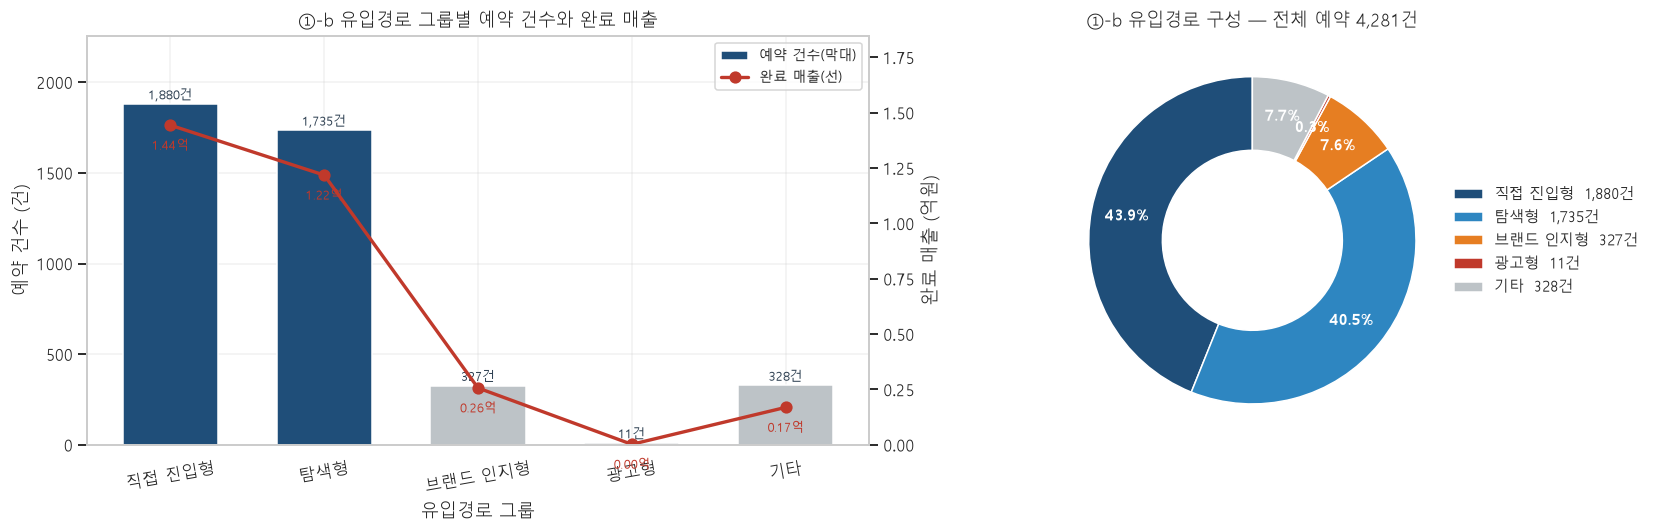

In [11]:
# ── ①-b 그래프 1: 경로별 건수·매출 이중축 + 구성 도넛 ──────────────────────
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

ax = axes[0]
_x = np.arange(len(GRP_ORDER))
_bars = _p_grp.예약.reindex(GRP_ORDER)
ax.bar(_x, _bars, color=hilite(GRP_ORDER, ["직접 진입형", "탐색형"], on=C_MAIN, off=C_GRAY), width=0.62,
       label="예약 건수(막대)")
barlab(ax, _x, _bars.values, "{:,.0f}건", dy=3)
ax.set_xticks(_x); ax.set_xticklabels(GRP_ORDER, rotation=10)
ax.set_ylabel("예약 건수 (건)"); ax.set_xlabel("유입경로 그룹")
ax.set_ylim(0, _bars.max() * 1.20)
ax2 = ax.twinx(); ax2.grid(False)
_rev = (_p_grp.매출.reindex(GRP_ORDER) / 1e8)
ax2.plot(_x, _rev, color=C_ACC, marker="o", lw=2.2, ms=7, label="완료 매출(선)")
for i, v in enumerate(_rev):
    ax2.annotate(f"{v:.2f}억", (i, v), textcoords="offset points", xytext=(0, -16),
                 ha="center", fontsize=8.5, color=C_ACC)
ax2.set_ylabel("완료 매출 (억원)")
ax2.set_ylim(0, float(_rev.max()) * 1.28)
ax.set_title("①-b 유입경로 그룹별 예약 건수와 완료 매출")
_h1, _l1 = ax.get_legend_handles_labels(); _h2, _l2 = ax2.get_legend_handles_labels()
ax.legend(_h1 + _h2, _l1 + _l2, loc="upper right", fontsize=9)

ax = axes[1]
_w = _p_grp.예약.reindex(GRP_ORDER)
_cols = [C_MAIN, C_SUB, C_WARM, C_ACC, C_GRAY]
_wedges, _t1, _t2 = ax.pie(
    _w, labels=None, autopct=lambda p: f"{p:.1f}%", colors=_cols,
    wedgeprops={"width": 0.45, "edgecolor": "white"}, startangle=90,
    pctdistance=0.78, textprops={"fontsize": 9.5, "color": "white", "weight": "bold"})
ax.legend(_wedges, [f"{g}  {int(_w[g]):,}건" for g in GRP_ORDER],
          loc="center left", bbox_to_anchor=(0.96, 0.5), fontsize=9.5, frameon=False)
ax.set_title(f"①-b 유입경로 구성 — 전체 예약 {len(R):,}건")
plt.tight_layout(); plt.show()

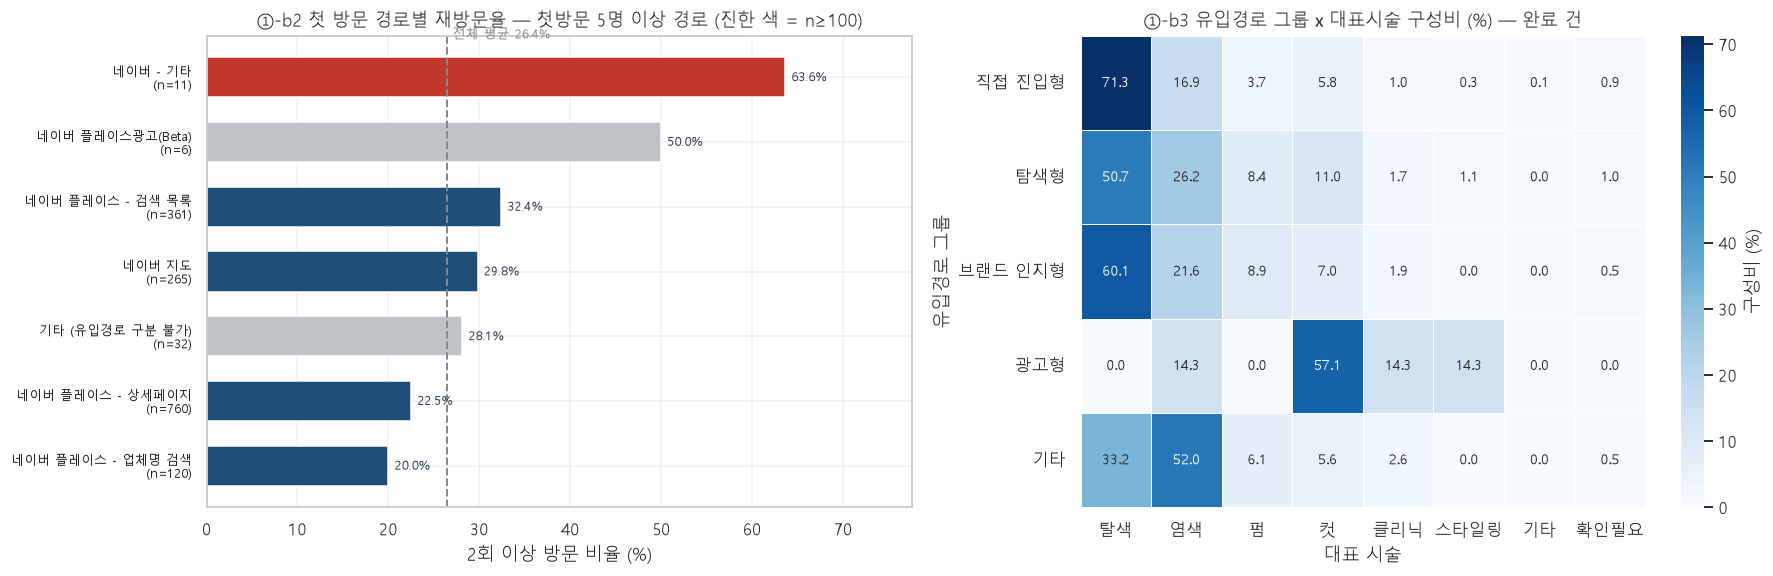

In [12]:
# ── ①-b 그래프 2: 경로별 재방문율 가로 막대(정렬) + 경로 x 시술 히트맵 ─────
fig, axes = plt.subplots(1, 2, figsize=(16.5, 5.4))

ax = axes[0]
_rr = _r_raw[_r_raw.첫방문인원 >= 5].sort_values("재방문율(%)")
_lbl = [f"{i}\n(n={int(_rr.loc[i,'첫방문인원'])})" for i in _rr.index]
_top = _rr["재방문율(%)"].idxmax()
_cols = [C_ACC if i == _top else (C_MAIN if _rr.loc[i, "첫방문인원"] >= 100 else C_GRAY) for i in _rr.index]
ax.barh(range(len(_rr)), _rr["재방문율(%)"], color=_cols, height=0.62)
barlab_h(ax, range(len(_rr)), _rr["재방문율(%)"].values, "{:.1f}%")
ax.set_yticks(range(len(_rr))); ax.set_yticklabels(_lbl, fontsize=8.5)
ax.axvline(CUST.재방문.mean()*100, color=C_DARKG, ls="--", lw=1.3)
ax.annotate(f"전체 평균 {CUST.재방문.mean()*100:.1f}%",
            (CUST.재방문.mean()*100, len(_rr)-0.4), fontsize=8.5, color=C_DARKG,
            textcoords="offset points", xytext=(4, 0))
ax.set_xlim(0, max(float(_rr["재방문율(%)"].max()) * 1.22, 40))
ax.set_xlabel("2회 이상 방문 비율 (%)")
ax.set_title("①-b2 첫 방문 경로별 재방문율 — 첫방문 5명 이상 경로 (진한 색 = n≥100)")

ax = axes[1]
_hm = _mixp_grp.drop(columns=["완료건수"])
_hm = _hm[[c for c in ["탈색", "염색", "펌", "컷", "클리닉", "스타일링", "기타", "확인필요"] if c in _hm.columns]]
sns.heatmap(_hm, annot=True, fmt=".1f", cmap="Blues", ax=ax, linewidths=.6, linecolor="white",
            cbar_kws={"label": "구성비 (%)"}, annot_kws={"fontsize": 9})
ax.set_title("①-b3 유입경로 그룹 x 대표시술 구성비 (%) — 완료 건")
ax.set_xlabel("대표 시술"); ax.set_ylabel("유입경로 그룹")
ax.set_yticklabels(ax.get_yticklabels(), rotation=0)
plt.tight_layout(); plt.show()

## ①-c 광고 효과 — 사장님이 직접 물어보신 것

> 사장님: **"네이버 플레이스 광고를 하는데 효과를 체감 못 하겠다"**

### ⚠️ 먼저 결론의 성격을 정한다

`네이버 플레이스광고(Beta)` 로 잡힌 예약은 **20개월 통틀어 11건**이다.
취소율·객단가·재방문율의 **집단 간 차이는 이 표본으로 통계적으로 판정할 수 없다.**
아래 표에 값은 내지만 **"광고가 나쁘다/좋다"는 결론으로 읽으면 안 된다.**

다만 **건수 자체는 표본 문제가 아니라 사실**이다.
"20개월간 광고 경유 예약이 몇 건인가"는 그대로 답이 된다.

⚠️ 한 가지 더: `channel` 은 **네이버 예약이 성사됐을 때 기록되는 최종 유입 경로**다.
광고를 보고 나중에 업체명으로 검색해 예약하면 그 건은 "업체명 검색"으로 잡힌다.
따라서 **11건은 광고의 총 기여가 아니라 "광고 클릭에서 곧바로 이어진 예약"의 수**다.
광고의 간접 효과는 이 데이터로 측정할 수 없다.

In [13]:
# ── ①-c1 광고 유입 — 건수와 발생 시점 ──────────────────────────────────────
AD = "네이버 플레이스광고(Beta)"
_ad = R[R.channel == AD].copy()
print(f"광고 경유 예약: {len(_ad)}건 / 전체 {len(R):,}건 = {len(_ad)/len(R)*100:.3f}%")
print(f"20개월 기준 월평균 {len(_ad)/N_MONTHS:.2f}건")
print()

_admon = (_ad.groupby(_ad.ym.astype(str)).size().rename("광고 예약건수").to_frame())
_admon["상태 내역"] = _ad.groupby(_ad.ym.astype(str)).status.apply(
    lambda s: " / ".join(f"{k} {v}" for k, v in s.value_counts().items()))
_allmon = pd.Index([str(p) for p in pd.period_range(R.ym.min(), R.ym.max(), freq="M")])
_admon = _admon.reindex(_allmon).fillna({"광고 예약건수": 0, "상태 내역": "-"})
_admon["광고 예약건수"] = _admon["광고 예약건수"].astype(int)
_admon["그 달 전체 예약"] = R.groupby(R.ym.astype(str)).size().reindex(_allmon).values
tbl(_admon, "①-c1 광고 유입의 월별 발생 — 20개월 중 발생한 달만 값이 있다")
print(f"광고 예약이 1건이라도 발생한 달: {int((_admon['광고 예약건수']>0).sum())}개월 / {N_MONTHS}개월")
print(f"한 달에 2건이 최대. 연속 발생 없음.")

광고 경유 예약: 11건 / 전체 4,281건 = 0.257%
20개월 기준 월평균 0.55건



**①-c1 광고 유입의 월별 발생 — 20개월 중 발생한 달만 값이 있다**

,광고 예약건수,상태 내역,그 달 전체 예약
2025-01,0,-,218
2025-02,0,-,217
2025-03,2,이용완료 2,184
2025-04,0,-,154
2025-05,1,이용완료 1,168
2025-06,0,-,160
2025-07,1,이용완료 1,180
2025-08,0,-,200
2025-09,0,-,127
2025-10,1,이용완료 1,202


광고 예약이 1건이라도 발생한 달: 8개월 / 20개월
한 달에 2건이 최대. 연속 발생 없음.


In [14]:
# ── ①-c2 광고 유입의 성과 — ⚠️ 표본 11건, 통계적 판정 불가 ────────────────
_adr = R[R.channel == AD]
_add = DONE[DONE.channel == AD]
_oth_r, _oth_d = R[R.channel != AD], DONE[DONE.channel != AD]

_adcmp = pd.DataFrame([
    {"구분": "광고형 (Beta)", "예약건수": len(_adr), "완료": len(_add),
     "취소율(%)": (_adr.status == "취소").mean()*100,
     "완료 객단가 중앙값": _add.paid.median(), "완료 객단가 평균": _add.paid.mean(),
     "완료 매출 합계": _add.paid.sum()},
    {"구분": "그 외 전체", "예약건수": len(_oth_r), "완료": len(_oth_d),
     "취소율(%)": (_oth_r.status == "취소").mean()*100,
     "완료 객단가 중앙값": _oth_d.paid.median(), "완료 객단가 평균": _oth_d.paid.mean(),
     "완료 매출 합계": _oth_d.paid.sum()},
]).set_index("구분")
_adcmp["판정"] = ["⚠️ 표본 11건 — 통계적 판정 불가", ""]
tbl(_adcmp.round(2), "①-c2 광고 vs 그 외 — 값은 내지만 차이 검정은 하지 않는다")

_adc = CUST[CUST.첫채널 == AD]
print(f"광고로 첫 방문한 고객: {len(_adc)}명 — 재방문율 {_adc.재방문.mean()*100:.1f}% "
      f"(전체 {CUST.재방문.mean()*100:.2f}%), 평균 방문 {_adc.방문횟수.mean():.2f}회")
print("⚠️ 6명 표본이다. 재방문율 50%는 3명이 다시 왔다는 뜻일 뿐이다. 해석 금지.")
print()

# 시술 구성 — 광고 유입이 무엇을 사 갔는가
_admix = _add.rep_cat.value_counts().rename("완료건수").to_frame()
_admix["금액"] = _add.groupby("rep_cat").paid.sum()
tbl(_admix, "①-c2b 광고 경유 완료 7건이 실제로 산 시술")

print()
print("── 지출 대비 사실 진술 (사장님께 그대로 드릴 수 있는 문장) ──")
print(f"* 20개월간 광고를 눌러 곧바로 잡힌 예약은 {len(_adr)}건, 그중 완료 {len(_add)}건.")
print(f"* 그 {len(_add)}건의 완료 매출 합계는 {_add.paid.sum():,}원. 20개월 평균 월 {_add.paid.sum()/N_MONTHS:,.0f}원.")
print(f"* 완료 {len(_add)}건 중 {int((_add.paid<=30000).sum())}건이 3만원 이하(컷 단가)다.")
for _cost in [20000, 30000, 50000]:
    _spend = _cost * N_MONTHS
    print(f"* 월 {_cost:,}원을 썼다고 가정하면 20개월 누적 지출 {_spend:,}원 → "
          f"광고 직결 매출 {_add.paid.sum():,}원, 차액 {_add.paid.sum()-_spend:+,}원 "
          f"(건당 획득비용 {_spend/len(_adr):,.0f}원/예약)")
print()
print("⚠️ 위 계산은 '광고 직결 예약'만 센 것이다. 광고를 보고 나중에 업체명으로 검색해 예약한 건은")
print("   channel 이 '업체명 검색'으로 기록되므로 여기 포함되지 않는다. 간접 효과는 측정 불가.")

**①-c2 광고 vs 그 외 — 값은 내지만 차이 검정은 하지 않는다**

,예약건수,완료,취소율(%),완료 객단가 중앙값,완료 객단가 평균,완료 매출 합계,판정
구분,,,,,,,
광고형 (Beta),11,7,36.36,29000.0,33428.57,234000,⚠️ 표본 11건 — 통계적 판정 불가
그 외 전체,4270,2725,36.02,100000.0,113299.69,308741650,


광고로 첫 방문한 고객: 6명 — 재방문율 50.0% (전체 26.40%), 평균 방문 1.50회
⚠️ 6명 표본이다. 재방문율 50%는 3명이 다시 왔다는 뜻일 뿐이다. 해석 금지.



**①-c2b 광고 경유 완료 7건이 실제로 산 시술**

,완료건수,금액
rep_cat,,
컷,4,116000
스타일링,1,50000
염색,1,39000
클리닉,1,29000



── 지출 대비 사실 진술 (사장님께 그대로 드릴 수 있는 문장) ──
* 20개월간 광고를 눌러 곧바로 잡힌 예약은 11건, 그중 완료 7건.
* 그 7건의 완료 매출 합계는 234,000원. 20개월 평균 월 11,700원.
* 완료 7건 중 5건이 3만원 이하(컷 단가)다.
* 월 20,000원을 썼다고 가정하면 20개월 누적 지출 400,000원 → 광고 직결 매출 234,000원, 차액 -166,000원 (건당 획득비용 36,364원/예약)
* 월 30,000원을 썼다고 가정하면 20개월 누적 지출 600,000원 → 광고 직결 매출 234,000원, 차액 -366,000원 (건당 획득비용 54,545원/예약)
* 월 50,000원을 썼다고 가정하면 20개월 누적 지출 1,000,000원 → 광고 직결 매출 234,000원, 차액 -766,000원 (건당 획득비용 90,909원/예약)

⚠️ 위 계산은 '광고 직결 예약'만 센 것이다. 광고를 보고 나중에 업체명으로 검색해 예약한 건은
   channel 이 '업체명 검색'으로 기록되므로 여기 포함되지 않는다. 간접 효과는 측정 불가.


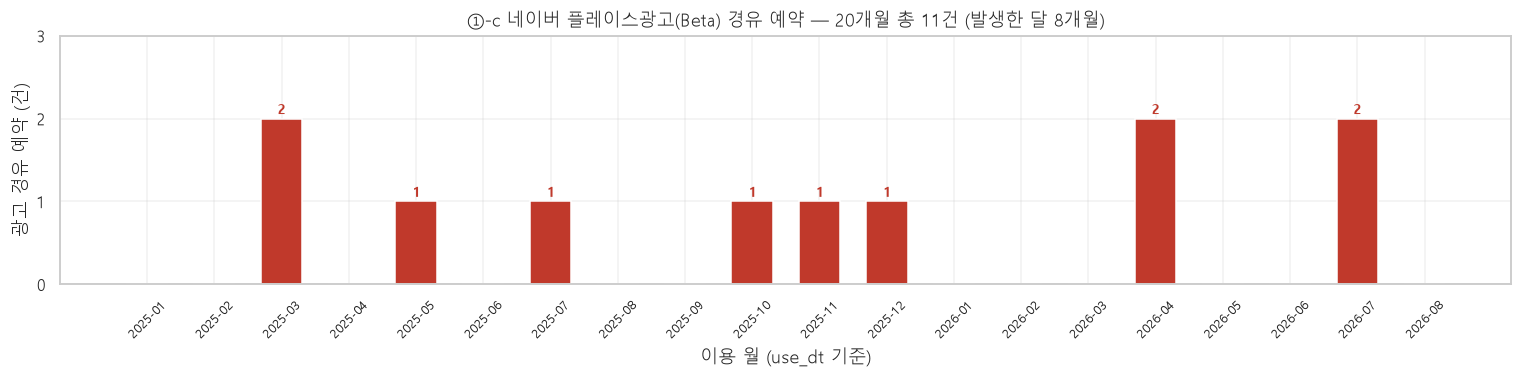

판정: 표본이 극히 작아 성과 비교는 통계적으로 불가능하다.
      다만 '20개월간 11건, 완료 7건, 직결 매출 234,000원'이라는 사실 자체가 사장님 질문의 답이다.


In [15]:
# ── ①-c 그래프: 광고 유입 월별 발생 (건수 막대) ────────────────────────────
fig, ax = plt.subplots(figsize=(14, 3.6))
_x = np.arange(len(_admon))
_y = _admon["광고 예약건수"].values
ax.bar(_x, _y, color=[C_ACC if v > 0 else C_GRAY for v in _y], width=0.62)
for i, v in enumerate(_y):
    if v > 0:
        ax.annotate(f"{int(v)}", (i, v), textcoords="offset points", xytext=(0, 3),
                    ha="center", fontsize=9, color=C_ACC, weight="bold")
ax.set_xticks(_x); ax.set_xticklabels(_admon.index, rotation=45, fontsize=8.5)
ax.set_ylim(0, max(_y.max() * 1.5, 3))
ax.set_yticks(range(0, int(_y.max()) + 2))
ax.set_ylabel("광고 경유 예약 (건)"); ax.set_xlabel("이용 월 (use_dt 기준)")
ax.set_title(f"①-c 네이버 플레이스광고(Beta) 경유 예약 — 20개월 총 {len(_ad)}건 "
             f"(발생한 달 {int((_y>0).sum())}개월)")
plt.tight_layout(); plt.show()
print("판정: 표본이 극히 작아 성과 비교는 통계적으로 불가능하다.")
print("      다만 '20개월간 11건, 완료 7건, 직결 매출 234,000원'이라는 사실 자체가 사장님 질문의 답이다.")

## ①-d 경로별 월별 추이

경로 그룹별 월별 **예약 건수** 시계열. 2025년과 2026년이 비교되게 그린다.

⚠️ **중국 단체관광 무비자(2025-09 ~ 2026-06)** 기간을 음영으로 표시한다.
그 기간에 특정 경로가 늘었는지 **관찰만** 한다. **인과 서술은 하지 않는다.**
같은 기간에 겨울 성수기·연말·재방문 누적 등 다른 요인이 전부 겹쳐 있어 분리되지 않는다.

In [16]:
# ── ①-d1 경로 그룹별 월별 예약 건수 ────────────────────────────────────────
_mon_idx = pd.period_range(R.ym.min(), R.ym.max(), freq="M")
_mg = (R.pivot_table(index="ym", columns="ch_grp", values="예약번호", aggfunc="size", fill_value=0)
         .reindex(index=_mon_idx, columns=GRP_ORDER, fill_value=0))
_mg["합계"] = _mg.sum(axis=1)
_mg["무비자기간"] = [(VISA_FREE[0] <= p <= VISA_FREE[1]) for p in _mg.index]
tbl(_mg, "①-d1 경로 그룹별 월별 예약 건수 (use_dt 기준)")

# 구성비로도 본다 (총량 증가와 구성 변화를 분리)
_mgp = _mg[GRP_ORDER].div(_mg["합계"], axis=0) * 100
tbl(_mgp.round(2), "①-d1b 경로 그룹별 월별 구성비 (%) — 총량 증가와 구성 변화를 분리해서 보기 위함")

_in  = _mg[_mg.무비자기간]
_out = _mg[~_mg.무비자기간]
_vs = pd.DataFrame({
    f"무비자 기간 월평균 ({len(_in)}개월)":     _in[GRP_ORDER].mean(),
    f"그 외 기간 월평균 ({len(_out)}개월)":     _out[GRP_ORDER].mean(),
})
_vs["차이(건)"]  = _vs.iloc[:, 0] - _vs.iloc[:, 1]
_vs["차이(%)"]   = _vs["차이(건)"] / _vs.iloc[:, 1] * 100
_vs["구성비 차(%p)"] = _mgp[_mg.무비자기간].mean() - _mgp[~_mg.무비자기간].mean()
tbl(_vs.round(2), "①-d2 무비자 기간 vs 그 외 — 경로별 월평균 (⚠️ 상관이지 인과가 아님)")
print("⚠️ 무비자 기간(2025-09~2026-06)에는 겨울 성수기·연말·2년차 재방문 누적이 전부 겹쳐 있다.")
print("   이 표는 '같이 움직였다'까지만 말한다. 어떤 경로가 무비자 때문에 늘었다고 말할 수 없다.")

**①-d1 경로 그룹별 월별 예약 건수 (use_dt 기준)**

ch_grp,직접 진입형,탐색형,브랜드 인지형,광고형,기타,합계,무비자기간
2025-01,100,90,12,0,16,218,False
2025-02,70,109,16,0,22,217,False
2025-03,58,97,9,2,18,184,False
2025-04,49,84,9,0,12,154,False
2025-05,66,68,7,1,26,168,False
2025-06,84,56,8,0,12,160,False
2025-07,91,71,7,1,10,180,False
2025-08,90,86,12,0,12,200,False
2025-09,41,62,12,0,12,127,True
2025-10,60,121,11,1,9,202,True


**①-d1b 경로 그룹별 월별 구성비 (%) — 총량 증가와 구성 변화를 분리해서 보기 위함**

ch_grp,직접 진입형,탐색형,브랜드 인지형,광고형,기타
2025-01,45.87,41.28,5.50,0.00,7.34
2025-02,32.26,50.23,7.37,0.00,10.14
2025-03,31.52,52.72,4.89,1.09,9.78
2025-04,31.82,54.55,5.84,0.00,7.79
2025-05,39.29,40.48,4.17,0.60,15.48
2025-06,52.50,35.00,5.00,0.00,7.50
2025-07,50.56,39.44,3.89,0.56,5.56
2025-08,45.00,43.00,6.00,0.00,6.00
2025-09,32.28,48.82,9.45,0.00,9.45
2025-10,29.70,59.90,5.45,0.50,4.46


**①-d2 무비자 기간 vs 그 외 — 경로별 월평균 (⚠️ 상관이지 인과가 아님)**

,무비자 기간 월평균 (10개월),그 외 기간 월평균 (10개월),차이(건),차이(%),구성비 차(%p)
ch_grp,,,,,
직접 진입형,104.6,83.4,21.2,25.42,-0.35
탐색형,93.7,79.8,13.9,17.42,-1.61
브랜드 인지형,21.1,11.6,9.5,81.90,2.79
광고형,0.5,0.6,-0.1,-16.67,-0.09
기타,17.5,15.3,2.2,14.38,-0.73


⚠️ 무비자 기간(2025-09~2026-06)에는 겨울 성수기·연말·2년차 재방문 누적이 전부 겹쳐 있다.
   이 표는 '같이 움직였다'까지만 말한다. 어떤 경로가 무비자 때문에 늘었다고 말할 수 없다.


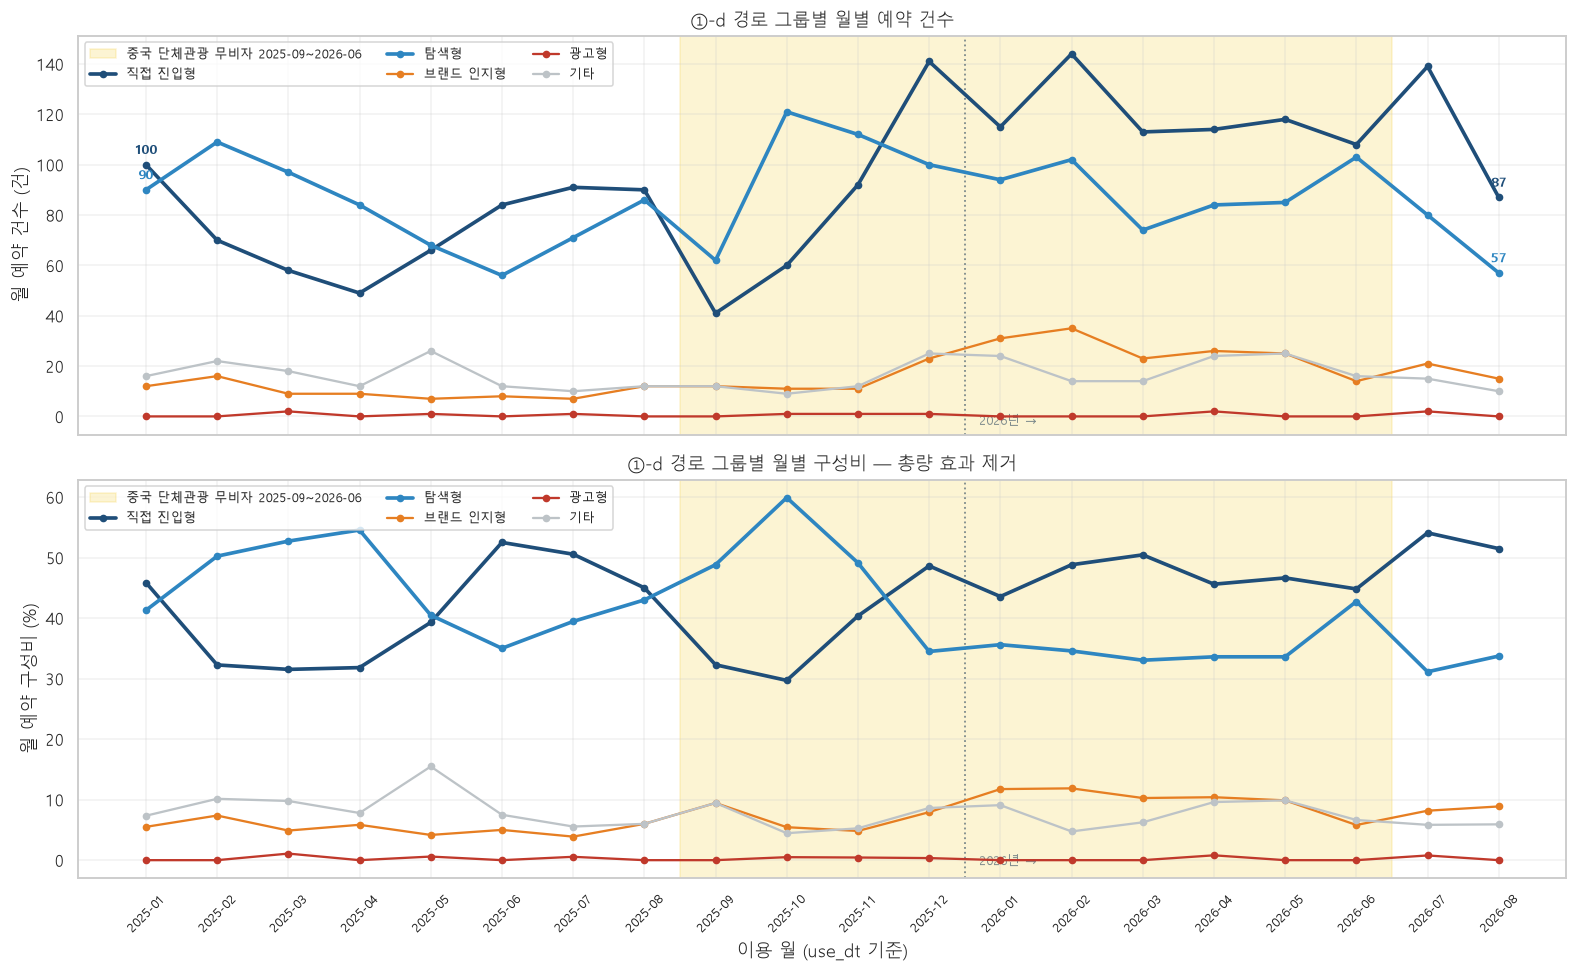

In [17]:
# ── ①-d 그래프: 경로 그룹별 월별 추이 (선, 무비자 음영) ────────────────────
fig, axes = plt.subplots(2, 1, figsize=(14.5, 9), sharex=True)
_xs = np.arange(len(_mg))
_vs_idx = [i for i, p in enumerate(_mg.index) if VISA_FREE[0] <= p <= VISA_FREE[1]]
_lines = {"직접 진입형": C_MAIN, "탐색형": C_SUB, "브랜드 인지형": C_WARM,
          "기타": C_GRAY, "광고형": C_ACC}

for ax, (data, ylab, ttl) in zip(
        axes,
        [(_mg[GRP_ORDER], "월 예약 건수 (건)", "①-d 경로 그룹별 월별 예약 건수"),
         (_mgp[GRP_ORDER], "월 예약 구성비 (%)", "①-d 경로 그룹별 월별 구성비 — 총량 효과 제거")]):
    ax.axvspan(min(_vs_idx) - 0.5, max(_vs_idx) + 0.5, color="#f1c40f", alpha=.18,
               label="중국 단체관광 무비자 2025-09~2026-06", zorder=0)
    ax.axvline(11.5, color=C_DARKG, ls=":", lw=1.2, zorder=1)   # 2025-12 / 2026-01 경계
    ax.annotate("2026년 →", (11.7, ax.get_ylim()[1]), fontsize=8.5, color=C_DARKG, va="top")
    for g in GRP_ORDER:
        lw = 2.4 if g in ("직접 진입형", "탐색형") else 1.5
        ax.plot(_xs, data[g], marker="o", ms=4, lw=lw, color=_lines[g], label=g, zorder=3)
    ax.set_ylabel(ylab)
    ax.set_title(ttl)
    ax.legend(fontsize=8.5, ncol=3, loc="upper left")

for g, col in [("직접 진입형", C_MAIN), ("탐색형", C_SUB)]:
    for i in [0, len(_mg) - 1]:
        axes[0].annotate(f"{int(_mg[g].iloc[i])}", (i, _mg[g].iloc[i]),
                         textcoords="offset points", xytext=(0, 7), ha="center",
                         fontsize=8.5, color=col, weight="bold")

axes[1].set_xticks(_xs)
axes[1].set_xticklabels([str(p) for p in _mg.index], rotation=45, fontsize=8.5)
axes[1].set_xlabel("이용 월 (use_dt 기준)")
plt.tight_layout(); plt.show()

## ①-e 브랜드 인지 지표

**"업체명 검색" 비중의 월별 추이 = 가게 이름을 아는 사람이 늘고 있는지의 대리 지표.**

* 이게 오르면 → 인지도가 쌓이는 것
* 탐색형만 늘면 → 신규 노출(검색 순위·지도 노출)에 의존하는 것

⚠️ **대리 지표의 한계**: 재방문 고객도 업체명으로 검색해 들어온다.
그래서 이 비중은 "브랜드 인지"와 "재방문 누적"을 구분하지 못한다.
아래에서 **신규 고객의 첫 방문 건만 골라낸 비중**을 함께 낸다. 그쪽이 더 순수한 인지 지표다.

In [18]:
# ── ①-e1 업체명 검색 비중 추이 (전체 예약 / 신규 첫방문 분리) ──────────────
BRAND = "네이버 플레이스 - 업체명 검색"

_b_all = (R.assign(is_b=R.channel == BRAND)
            .groupby("ym").agg(예약=("예약번호", "size"), 업체명검색=("is_b", "sum")))
_b_all["비중_전체예약(%)"] = _b_all.업체명검색 / _b_all.예약 * 100

# 신규 첫 방문 건만 (고객의 첫 완료 방문 예약)
_first_res = DONE[DONE.신규고객건].copy()
_b_new = (_first_res.assign(is_b=_first_res.channel == BRAND)
                    .groupby("ym").agg(신규첫방문=("예약번호", "size"), 업체명검색_신규=("is_b", "sum")))
_b_new["비중_신규첫방문(%)"] = _b_new.업체명검색_신규 / _b_new.신규첫방문 * 100

_brand = _b_all.join(_b_new).reindex(_mon_idx)
_brand["탐색형 비중(%)"] = _mgp["탐색형"]
_brand["직접진입 비중(%)"] = _mgp["직접 진입형"]
tbl(_brand.round(2), "①-e1 업체명 검색(브랜드 인지) 비중의 월별 추이")

_h1 = _brand.head(6); _h2 = _brand.tail(6)
_trend = pd.DataFrame({
    "앞 6개월 (2025-01~06) 평균": [_h1["비중_전체예약(%)"].mean(), _h1["비중_신규첫방문(%)"].mean(),
                                   _h1["탐색형 비중(%)"].mean(), _h1["직접진입 비중(%)"].mean()],
    "뒤 6개월 (2026-03~08) 평균": [_h2["비중_전체예약(%)"].mean(), _h2["비중_신규첫방문(%)"].mean(),
                                   _h2["탐색형 비중(%)"].mean(), _h2["직접진입 비중(%)"].mean()],
}, index=["업체명검색 비중 [전체예약]", "업체명검색 비중 [신규 첫방문만]",
          "탐색형 비중", "직접 진입형 비중"])
_trend["변화(%p)"] = _trend.iloc[:, 1] - _trend.iloc[:, 0]
tbl(_trend.round(2), "①-e2 앞 6개월 vs 뒤 6개월 — 브랜드 인지가 쌓이고 있는가")

_corr = _brand[["비중_전체예약(%)"]].dropna().reset_index(drop=True)
_slope = np.polyfit(range(len(_corr)), _corr["비중_전체예약(%)"], 1)[0]
print(f"업체명 검색 비중 월별 선형추세 기울기: {_slope:+.4f} %p/월 "
      f"(20개월 누적 {_slope*20:+.2f}%p)")
print("⚠️ 단순 선형 적합이다. 계절성을 제거하지 않았고, 유의성 검정도 하지 않았다.")

**①-e1 업체명 검색(브랜드 인지) 비중의 월별 추이**

,예약,업체명검색,비중_전체예약(%),신규첫방문,업체명검색_신규,비중_신규첫방문(%),탐색형 비중(%),직접진입 비중(%)
2025-01,218,12,5.50,115,8,6.96,41.28,45.87
2025-02,217,16,7.37,116,9,7.76,50.23,32.26
2025-03,184,9,4.89,67,4,5.97,52.72,31.52
2025-04,154,9,5.84,50,1,2.00,54.55,31.82
2025-05,168,7,4.17,53,3,5.66,40.48,39.29
2025-06,160,8,5.00,52,3,5.77,35.00,52.50
2025-07,180,7,3.89,64,1,1.56,39.44,50.56
2025-08,200,12,6.00,71,4,5.63,43.00,45.00
2025-09,127,12,9.45,36,4,11.11,48.82,32.28
2025-10,202,11,5.45,79,5,6.33,59.90,29.70


**①-e2 앞 6개월 vs 뒤 6개월 — 브랜드 인지가 쌓이고 있는가**

,앞 6개월 (2025-01~06) 평균,뒤 6개월 (2026-03~08) 평균,변화(%p)
업체명검색 비중 [전체예약],5.46,8.90,3.44
업체명검색 비중 [신규 첫방문만],5.69,8.48,2.80
탐색형 비중,45.71,34.64,-11.07
직접 진입형 비중,38.88,48.84,9.97


업체명 검색 비중 월별 선형추세 기울기: +0.2550 %p/월 (20개월 누적 +5.10%p)
⚠️ 단순 선형 적합이다. 계절성을 제거하지 않았고, 유의성 검정도 하지 않았다.


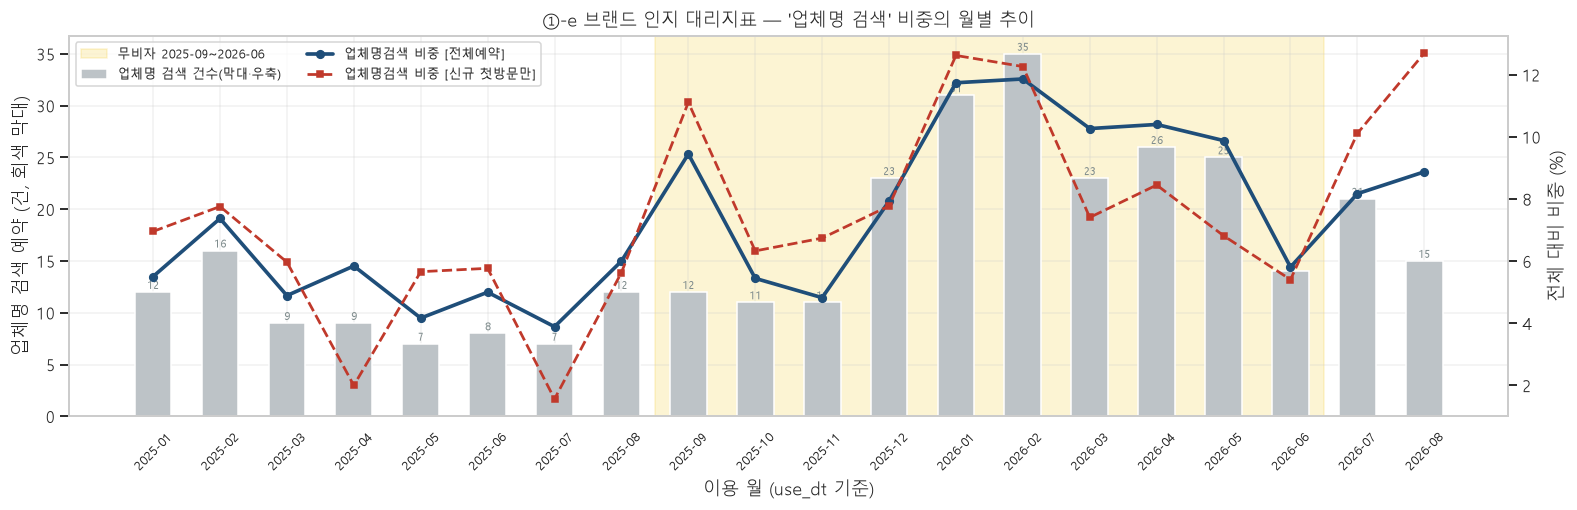

In [19]:
# ── ①-e 그래프: 브랜드 인지 지표 추이 ──────────────────────────────────────
fig, ax = plt.subplots(figsize=(14.5, 4.8))
_xs = np.arange(len(_brand))
ax.axvspan(min(_vs_idx) - 0.5, max(_vs_idx) + 0.5, color="#f1c40f", alpha=.18,
           label="무비자 2025-09~2026-06", zorder=0)
ax.bar(_xs, _brand.업체명검색, color=C_GRAY, width=0.55, label="업체명 검색 건수(막대·우축)", zorder=1)
ax2 = ax.twinx(); ax2.grid(False)
ax2.plot(_xs, _brand["비중_전체예약(%)"], marker="o", ms=5, lw=2.4, color=C_MAIN,
         label="업체명검색 비중 [전체예약]", zorder=3)
ax2.plot(_xs, _brand["비중_신규첫방문(%)"], marker="s", ms=4, lw=1.8, ls="--", color=C_ACC,
         label="업체명검색 비중 [신규 첫방문만]", zorder=3)
for i in range(len(_brand)):
    ax.annotate(f"{int(_brand.업체명검색.iloc[i])}", (i, _brand.업체명검색.iloc[i]),
                textcoords="offset points", xytext=(0, 2), ha="center", fontsize=7.5, color=C_DARKG)
ax.set_ylabel("업체명 검색 예약 (건, 회색 막대)")
ax2.set_ylabel("전체 대비 비중 (%)")
ax.set_xticks(_xs); ax.set_xticklabels([str(p) for p in _brand.index], rotation=45, fontsize=8.5)
ax.set_xlabel("이용 월 (use_dt 기준)")
ax.set_title("①-e 브랜드 인지 대리지표 — '업체명 검색' 비중의 월별 추이")
_h1, _l1 = ax.get_legend_handles_labels(); _h2, _l2 = ax2.get_legend_handles_labels()
ax.legend(_h1 + _h2, _l1 + _l2, loc="upper left", fontsize=8.5, ncol=2)
plt.tight_layout(); plt.show()

In [20]:
# ── ①-요약 ─────────────────────────────────────────────────────────────────
_s1 = _p_grp.loc[GRP_ORDER]
_s2 = _r_grp.reindex(GRP_ORDER)
CH_SUMMARY = pd.DataFrame({
    "예약건수":        _s1.예약,
    "예약비중(%)":     _s1["예약비중(%)"],
    "취소율(%)":       _s1["취소율(%)"],
    "매출비중(%)":     _s1["매출비중(%)"],
    "객단가 중앙값":   _s1.객단가중앙,
    "첫방문 고객수":   _s2.첫방문인원,
    "재방문율(%)":     _s2["재방문율(%)"],
    "평균 방문횟수":   _s2.평균방문횟수,
})
CH_SUMMARY["소표본"] = CH_SUMMARY["첫방문 고객수"].map(lambda n: small(n))
tbl(CH_SUMMARY.round(2), "① 유입경로 요약 — 한 장으로")

_most = CH_SUMMARY.예약건수.idxmax()
_best = CH_SUMMARY[CH_SUMMARY["첫방문 고객수"] >= 30]["재방문율(%)"].idxmax()
print(f"건수가 가장 많은 경로 : {_most} ({int(CH_SUMMARY.loc[_most,'예약건수']):,}건, "
      f"{CH_SUMMARY.loc[_most,'예약비중(%)']:.1f}%) — 재방문율 {CH_SUMMARY.loc[_most,'재방문율(%)']:.2f}%")
print(f"재방문율이 가장 높은 경로(표본 30명+) : {_best} — 재방문율 {CH_SUMMARY.loc[_best,'재방문율(%)']:.2f}%, "
      f"첫방문 {int(CH_SUMMARY.loc[_best,'첫방문 고객수'])}명")
print()
if _most != _best:
    print("→ 건수가 많은 경로와 재방문율이 높은 경로가 다르다. 이것이 ①의 결론이다.")
else:
    print("→ 건수가 많은 경로가 재방문율도 가장 높다.")

**① 유입경로 요약 — 한 장으로**

,예약건수,예약비중(%),취소율(%),매출비중(%),객단가 중앙값,첫방문 고객수,재방문율(%),평균 방문횟수,소표본
직접 진입형,1880,43.91,37.87,46.71,100000.0,760,22.50,1.58,
탐색형,1735,40.53,33.49,39.43,100000.0,626,31.31,1.90,
브랜드 인지형,327,7.64,34.86,8.31,107000.0,120,20.00,1.39,
광고형,11,0.26,36.36,0.08,29000.0,6,50.00,1.50,⚠소표본
기타,328,7.66,39.94,5.47,44000.0,45,37.78,3.62,


건수가 가장 많은 경로 : 직접 진입형 (1,880건, 43.9%) — 재방문율 22.50%
재방문율이 가장 높은 경로(표본 30명+) : 기타 — 재방문율 37.78%, 첫방문 45명

→ 건수가 많은 경로와 재방문율이 높은 경로가 다르다. 이것이 ①의 결론이다.


---
# ② 요청사항 텍스트 분류 — 챗봇 설계의 원본 데이터

지금까지는 요청사항을 **작성 여부**로만 봤다(01번 ⑧-1). 여기서는 **내용**을 분류한다.

## ⚠️ 출력 전 개인정보 마스킹

요청사항 원문에는 **실명과 전화번호가 그대로 들어 있다**(예: "○○○ 스탬프 10개로…", "010-…로 연락주세요").
프로젝트 규약 §10에 따라 원문을 출력하기 전에 반드시 마스킹한다.

* 전화번호 패턴 → `[전화번호]`
* `hands_name`·`예약자`·`방문자` 에서 만든 실명 사전에 걸리는 토큰 → `성**`
* 그 외 4자리 이상 연속 숫자 → `[숫자]`

마스킹 함수는 아래 셀에서 정의하고, **원문을 찍는 모든 셀이 이 함수를 통과시킨다.**

In [21]:
# ── ②-0 개인정보 마스킹 함수 ───────────────────────────────────────────────
_name_src = pd.concat([
    R.hands_name.fillna("").astype(str),
    R.예약자.fillna("").astype(str),
    R.방문자.fillna("").astype(str),
])
_names = set()
for v in _name_src.unique():
    v = re.sub(r"\(.*?\)", "", v).strip()          # '홍길동(331)' -> '홍길동'
    if 2 <= len(v) <= 4 and re.fullmatch(r"[가-힣]+", v):
        _names.add(v)
_NAME_RE = re.compile("|".join(sorted(map(re.escape, _names), key=len, reverse=True))) if _names else None
_PHONE_RE = re.compile(r"0\d{1,2}[-\s.]?\d{3,4}[-\s.]?\d{4}")
_LONGNUM_RE = re.compile(r"\d{6,}")

# 사전에 없는 실명도 걸러내기 위한 문맥 규칙.
# (예약자 컬럼은 이미 '김*민' 형태로 마스킹돼 있어 사전 구축에 도움이 안 된다.)
_SUR = ("남궁|황보|사공|선우|독고|"
        "김|이|박|최|정|강|조|윤|장|임|한|오|서|신|권|황|안|송|류|전|홍|고|문|양|손|배|백|허|유|남|"
        "심|노|하|곽|성|차|주|우|구|민|진|지|엄|채|원|천|방|공|현|함|변|염|여|추|도|소|석|선|설|마|"
        "길|연|위|표|명|기|반|왕|금|옥|육|인|맹|봉|피|태|계|사|호|시|국|왕")
_STOP = {  # 성씨로 시작하지만 사람 이름이 아닌 흔한 낱말 — 과잉 마스킹 방지
    "방문자", "예약자", "이름", "성함", "연락처", "전화", "번호", "문의", "본인", "고객",
    "원장", "대표", "선생", "사장", "손님", "남편", "아내", "엄마", "아빠", "부모", "친구",
    "지인", "동생", "언니", "누나", "오빠", "어머니", "아버지", "여자", "남자", "학생",
    "현재", "지금", "오늘", "내일", "모레", "어제", "이번", "저번", "지난", "다음", "방금",
    "최근", "정말", "진짜", "조금", "제발", "감사", "안녕", "죄송", "예약", "매장", "머리",
    "염색", "탈색", "시술", "생일", "무료", "가능", "추가", "전에", "이전", "이후", "그때",
    "가격", "금액", "결제", "쿠폰", "우선", "일단", "혹시", "만약", "상담", "확인", "부탁",
    "구매", "고민", "선택", "사진", "기장", "손상", "회복", "마저", "나머지", "포함",
}
_CTX_RES = [
    re.compile(r"(?:이름|방문자|예약자|성함|본인)\s*[:：은는이가]?\s*(?P<n>(?:" + _SUR + r")[가-힣]{1,2})"),
    # ⚠️ 아래 두 줄의 뒤 경계는 2026-09-03 에 완화했다. 원래는 `(?![가-힣])` 였는데
    #    실제 표기인 '소개로' · '님이' 처럼 조사가 붙으면 규칙이 통째로 죽었다.
    #    (가짜 입력으로 분기 시험을 하다 발견. 실명 사전이 이미 다 잡고 있어
    #     현 데이터의 마스킹 결과 변화는 0건이지만, 사전에 없는 제3자 —
    #     소개해 준 지인 등 — 에 대해서는 구멍이었다.)
    re.compile(r"(?<![가-힣])(?P<n>(?:" + _SUR + r")[가-힣]{1,2})"
               r"(?=\s*(?:님|씨)(?:[은는이가께도만의랑과와]|(?![가-힣])))"),
    re.compile(r"(?<![가-힣])(?P<n>(?:" + _SUR + r")[가-힣]{1,2})(?=\s*(?:소개|스탬프|스템프))"),
    re.compile(r"(?<![가-힣])(?P<n>[가-힣]{2,4})(?=\s*\[전화번호\])"),
    re.compile(r"\[전화번호\]\s*(?P<n>[가-힣]{2,4})"),
]

def _mask_ctx(m):
    n = m.group("n")
    if n in _STOP:
        return m.group(0)
    return m.group(0).replace(n, n[0] + "**", 1)

def mask(t):
    # 요청사항·취소사유 원문에서 실명/전화번호를 가린다. 출력 전 반드시 통과시킬 것.
    if not isinstance(t, str):
        return ""
    t = _PHONE_RE.sub("[전화번호]", t)
    t = _LONGNUM_RE.sub("[숫자]", t)
    if _NAME_RE is not None:
        t = _NAME_RE.sub(lambda m: m.group(0)[0] + "**", t)
    for _re_ in _CTX_RES:
        t = _re_.sub(_mask_ctx, t)
    return re.sub(r"\s*\n\s*", " ⏎ ", t).strip()

print(f"실명 사전 {len(_names):,}개 구축 (hands_name / 예약자 / 방문자에서 추출)")
print(f"문맥 규칙 {len(_CTX_RES)}개 추가 (이름/방문자 뒤 · 님·씨 앞 · 소개·스탬프 앞 · 전화번호 인접)")
print()
# ⚠️ 테스트 입력에 실제 고객 값을 쓰지 말 것 (원본 분석 문서 §10).
#    아래 가짜 이름은 전부 _names(실명 사전)에 없는 것으로 골랐다.
#    사전에 있는 이름을 쓰면 실존 고객과 겹쳐 같은 문제가 반복된다.
#    아래는 전부 가짜 이름·번호이며, 각 문맥 규칙 분기를 그대로 태운다.
print("마스킹 작동 확인 (입력은 전부 가짜 값):")
for _t, _why in [("네이버 계정이 엄마꺼여서 이름 홍길동으로 부탁드립니다", "규칙1 이름 뒤"),
                 ("방문자:김철수",              "규칙1 방문자 뒤"),
                 ("이영희 소개로 예약합니다.",   "규칙3 소개 앞(조사 포함)"),
                 ("박민수 010 0000 0000",      "전화번호 + 규칙4 인접"),
                 ("최갑돌 님 문의드립니다",      "규칙2 님 앞"),
                 ("강지훈 님이 오신다고 합니다",  "규칙2 님 앞(조사 포함)"),
                 ("원장님 안녕하세요",           "_STOP — 마스킹 안 돼야 정상"),
                 ("현재 스탬프 4회째로 문의드립니다", "_STOP — 마스킹 안 돼야 정상"),
                 ("지금 탈색한 머리에서",        "해당 없음 — 원문 유지")]:
    print(f"   [{_why:<22s}] {_t}  →  {mask(_t)}")

# 사전(_NAME_RE) 분기는 가짜 이름으로 탈 수 없으므로 사전에서 하나 뽑아 태운다.
# 입력값은 절대 출력하지 않고 **마스킹 결과만** 찍는다.
if _names:
    _probe = sorted(_names)[len(_names) // 2]
    print(f"   [{'사전 매칭 분기':<22s}] (입력 미출력)  →  {mask(_probe + ' 예약 확인 부탁드립니다')}")
print()
_demo = R.loc[R.요청사항.fillna("").str.contains("스탬프", na=False), "요청사항"].dropna().head(2)
for _t in _demo:
    print("  실제 원문 →", mask(_t))
print()
print("⚠️ 마스킹은 완전하지 않다. 규칙에 안 걸리는 실명이 남을 수 있으므로")
print("   원문이 들어간 출력·CSV 를 외부로 내보내기 전에는 반드시 사람이 확인할 것.")

실명 사전 870개 구축 (hands_name / 예약자 / 방문자에서 추출)
문맥 규칙 5개 추가 (이름/방문자 뒤 · 님·씨 앞 · 소개·스탬프 앞 · 전화번호 인접)

마스킹 작동 확인 (입력은 전부 가짜 값):
   [규칙1 이름 뒤              ] 네이버 계정이 엄마꺼여서 이름 홍길동으로 부탁드립니다  →  네이버 계정이 엄마꺼여서 이름 홍**으로 부탁드립니다
   [규칙1 방문자 뒤             ] 방문자:김철수  →  방문자:김**
   [규칙3 소개 앞(조사 포함)       ] 이영희 소개로 예약합니다.  →  이** 소개로 예약합니다.
   [전화번호 + 규칙4 인접         ] 박민수 010 0000 0000  →  박** [전화번호]
   [규칙2 님 앞               ] 최갑돌 님 문의드립니다  →  최** 님 문의드립니다
   [규칙2 님 앞(조사 포함)        ] 강지훈 님이 오신다고 합니다  →  강** 님이 오신다고 합니다
   [_STOP — 마스킹 안 돼야 정상   ] 원장님 안녕하세요  →  원장님 안녕하세요
   [_STOP — 마스킹 안 돼야 정상   ] 현재 스탬프 4회째로 문의드립니다  →  현재 스탬프 4회째로 문의드립니다
   [해당 없음 — 원문 유지         ] 지금 탈색한 머리에서  →  지금 탈색한 머리에서
   [사전 매칭 분기              ] (입력 미출력)  →  소** 예약 확인 부탁드립니다

  실제 원문 → 염색 후 스탬프 적립 두피관리 풀코스 쿠폰 ㅃㄹ ㅀㄻ합니다.
  실제 원문 → 아쿠아클리닉 ㄸㅀㄲㄱㄽ ⏎ 현재 스탬프 4ㅃㄸㅃ ㅃㅀ 방문시 두피각질ㅃㄽㅍ 같이 ㄸㅀ받을 ㅃ ㄾㄹㅌ 문의드립니다~!! ⏎ ㅄㅃㄸ 17시 45분까지 가능합니다~ ⏎ 감사합니다

⚠️ 마스킹은 완전하지 않다. 규칙에 안 걸리는 실명이 남을 수 있으므로
   원문이 들어간 출력·CSV 를 외부로 내보내기 전에는 반드시 사람이 확인할 것.


## ②-a 유형 분류 — 규칙표

**복수 태깅을 허용한다.** 한 건이 "모발 이력 고지 + 컬러 요청 + 시술 상담"에 동시에 걸리는 것이 정상이다.
그와 별도로 **주 유형 1개**를 우선순위로 확정한다.

| 유형 | 판정 규칙 (요약) |
|---|---|
| **외국어·번역** | 한글이 0글자인데 한자/가나/알파벳이 3자 이상 / `외국인` `한국어…못` `서툴` `번역` `파파고` `Translator` `English` `Chinese` |
| **메뉴 선택 혼란** | `무엇을 선택` `뭘 선택` `선택해야` `두 개 선택` `맞나요` `없어서 이걸로` `일단 이/아무` `이 상품` `메뉴가 많` `잘못 선택` `우선 이벤트` `체크했` |
| **가격·쿠폰·스탬프** | `쿠폰` `할인` `스탬프/스템프` `적립` `추가금` `기장 추가` `가격` `금액` `비용` `얼마` `예산` `선결제` `정액권` `결제` `발렛` `무료` |
| **시술 상담** | `상담` `추천` `어울리` `어떤/무슨 색` `고민` `모르겠` `가능할까/가능한가` `되나요/될까요` `괜찮을까` `정하지 못` `결정하고 싶` `봐주시` `맞을까` |
| **모발 이력 고지** | `이력` `셀프` `손상` `상했` `붙임머리` `직후` `얼룩` `퇴색/물 빠` `블랙` `곱슬` `새치` `톤다운` `끊긴/끊김` `염증` `탈색 N회` `N개월/N년 전` `현재 …상태` |
| **컬러 요청** | 색상명 55종(`애쉬` `베이지` `핑크` `백금발` `블론드` `밀크` `라벤더` …) / `노란끼` `주황기` `파스텔` `톤` |
| **시간 조정** | `도착` `늦` `일찍` `앞당` `미루` `시간 변경/조정/맞` `…까지 가/올/끝` `분쯤` `시 반` |
| **기타** | 위 어디에도 안 걸린 것 |

**주 유형 우선순위** (희소하고 구체적인 것 먼저):
```
외국어·번역 > 메뉴 선택 혼란 > 가격·쿠폰·스탬프 > 시술 상담 > 모발 이력 고지 > 컬러 요청 > 시간 조정 > 기타
```

이 순서를 이렇게 잡은 이유: 챗봇 설계가 목적이므로 **"응대 방식이 갈리는 축"** 을 위로 올렸다.
외국어는 언어 자체가 갈리고, 메뉴 혼란·가격 질문은 버튼 하나로 끝나며, 상담은 사람이 받아야 한다.

In [22]:
# ── ②-a1 분류 규칙 정의 ────────────────────────────────────────────────────
REQ_TYPES = ["외국어·번역", "메뉴 선택 혼란", "가격·쿠폰·스탬프", "시술 상담",
             "모발 이력 고지", "컬러 요청", "시간 조정"]      # 이 순서가 주 유형 우선순위
REQ_ALL   = REQ_TYPES + ["기타"]

_COLOR_WORDS = ("애쉬|에쉬|밀크|베이지|브라운|갈발|핑크|블루|퍼플|보라|그레이|실버|백금발|금발|블론드|"
                "오렌지|주황|코랄|라벤더|바이올렛|네온|그린|초록|레드|빨강|블랙|검정|화이트|하얀|새하얀|"
                "파스텔|아이스|딥블루|인디블루|민트|쿨톤|웜톤|퍼스널\\s*컬러|옴브레|발레아쥬|투톤|원톤|"
                "노란\\s*끼|노란끼|노란기|주황기|붉은기|톤다운|톤업|색상|컬러|색깔|물\\s*빠|퇴색")

REQ_RULES = {
    "메뉴 선택 혼란": r"무엇을\s*선택|뭘\s*선택|어떤\s*(걸|것을|거)\s*선택|선택해야|선택해여|선택하였|두\s*개\s*선택|두개선택|"
                      r"맞나요|맞게\s*선택|없어서\s*(일단|이|이걸)|일단\s*(이|아무|이벤트|이걸)|이걸로\s*(예약|체크|선택|했)|"
                      r"이\s*상품|이상품|메뉴가\s*많|잘못\s*(선택|고름)|우선\s*이벤트|체크했|설정드렸|이렇게\s*선택",
    "가격·쿠폰·스탬프": r"쿠폰|할인|스탬프|스템프|적립|추가금|추가\s*비용|추가\s*요금|기장\s*추가|기장추가|가격|금액|비용|얼마|"
                        r"예산|선결제|정액권|결제|발렛|무료|만원\s*선|원\s*선|계좌이체|포인트",
    "시술 상담": r"상담|추천|어울리|어울릴|어떤\s*색|무슨\s*색|어떤\s*컬러|고민|모르겠|몰라서|여쭤|물어|"
                 r"가능할까|가능한가|가능한지|가능할지|가능하다면|되나요|될까요|괜찮을까|괜찮은|정하지\s*못|못\s*정|"
                 r"결정하고\s*싶|정하고\s*싶|봐주시|진단|맞을까|찾고\s*싶|골라|어떨까|문의",
    "모발 이력 고지": r"이력|셀프|손상|상했|상한|붙임머리|직후|얼룩|퇴색|물\s*빠|블랙\s*(빼|염색|덮|두|이력)|곱슬|새치|톤다운|"
                      r"끊긴|끊김|끊길|염증|탈색\s*\d|\d\s*회\s*탈색|\d\s*번\s*탈색|\d+\s*(개월|달|년|주)\s*전|"
                      r"저번|지난|이전|전에\s*(했|염색|탈색|펌|블랙)|현재\s*.{0,12}(상태|모발|머리|색)|"
                      r"지금\s*.{0,12}(상태|머리|색)|손상모|기장|모발\s*(이|테스트|상태)|머릿결|머리결|시술\s*이력",
    "컬러 요청": _COLOR_WORDS,
    "시간 조정": r"도착|늦(게|을|지|어|겠)|일찍|앞당|미루|미뤄|시간\s*(변경|조정|바꾸|맞|이동)|시간대\s*변경|"
                 r"\d\s*시\s*\d*\s*분?\s*(까지|쯤|경)|\d시\s*반|까지\s*(가|갈|올|와|끝|도착)|끝나(야|길|게)|시간\s*내|"
                 r"빠른\s*시간|빠르게\s*가|먼저\s*가",
}

def is_foreign(t):
    han = len(re.findall(r"[가-힣]", t))
    cjk = len(re.findall(r"[一-鿿぀-ゟ゠-ヿ]", t))
    lat = len(re.findall(r"[A-Za-z]", t))
    if han == 0 and (cjk + lat) >= 3:
        return True
    return bool(re.search(r"외국인|한국어.{0,10}(못|서툴|어눌|배우)|번역|파파고|Translator|English|Chinese|"
                          r"일본에서\s*살|한국\s*국적", t))

def classify_request(t):
    """복수 태깅 리스트를 돌려준다."""
    if not isinstance(t, str) or not t.strip():
        return []
    tags = []
    if is_foreign(t):
        tags.append("외국어·번역")
    for k in ["메뉴 선택 혼란", "가격·쿠폰·스탬프", "시술 상담", "모발 이력 고지", "컬러 요청", "시간 조정"]:
        if re.search(REQ_RULES[k], t):
            tags.append(k)
    return tags

def main_type(tags):
    for k in REQ_TYPES:
        if k in tags:
            return k
    return "기타"

_rule_tbl = pd.DataFrame({
    "유형": REQ_TYPES,
    "주유형 우선순위": range(1, len(REQ_TYPES) + 1),
    "규칙(정규식)": ["(함수 is_foreign — 한글 0자 + 비한글 3자 이상, 또는 외국인/한국어 못/번역 언급)"]
                    + [REQ_RULES[k][:110] + " …" for k in REQ_TYPES[1:]],
})
tbl(_rule_tbl, "②-a1 요청사항 분류 규칙 — 노트북에 명시 (복수 태깅 허용, 주 유형은 위 우선순위)")

**②-a1 요청사항 분류 규칙 — 노트북에 명시 (복수 태깅 허용, 주 유형은 위 우선순위)**

,유형,주유형 우선순위,규칙(정규식)
0,외국어·번역,1,"(함수 is_foreign — 한글 0자 + 비한글 3자 이상, 또는 외국인/한국어 못/번역 언급)"
1,메뉴 선택 혼란,2,무엇을\s*선택|뭘\s*선택|어떤\s*(걸|것을|거)\s*선택|선택해야|선택해여|선택하였|두\s*개\s*선택|두개선택|맞나요|맞게\s*선택|없어서\s*(일단|이|이걸)|일단\s*(이|아무|이벤트|이 …
2,가격·쿠폰·스탬프,3,쿠폰|할인|스탬프|스템프|적립|추가금|추가\s*비용|추가\s*요금|기장\s*추가|기장추가|가격|금액|비용|얼마|예산|선결제|정액권|결제|발렛|무료|만원\s*선|원\s*선|계좌이체|포인트 …
3,시술 상담,4,상담|추천|어울리|어울릴|어떤\s*색|무슨\s*색|어떤\s*컬러|고민|모르겠|몰라서|여쭤|물어|가능할까|가능한가|가능한지|가능할지|가능하다면|되나요|될까요|괜찮을까|괜찮은|정하지\s*못|못\s*정| …
4,모발 이력 고지,5,이력|셀프|손상|상했|상한|붙임머리|직후|얼룩|퇴색|물\s*빠|블랙\s*(빼|염색|덮|두|이력)|곱슬|새치|톤다운|끊긴|끊김|끊길|염증|탈색\s*\d|\d\s*회\s*탈색|\d\s*번\s*탈색|\d …
5,컬러 요청,6,애쉬|에쉬|밀크|베이지|브라운|갈발|핑크|블루|퍼플|보라|그레이|실버|백금발|금발|블론드|오렌지|주황|코랄|라벤더|바이올렛|네온|그린|초록|레드|빨강|블랙|검정|화이트|하얀|새하얀|파스텔|아이스|딥 …
6,시간 조정,7,도착|늦(게|을|지|어|겠)|일찍|앞당|미루|미뤄|시간\s*(변경|조정|바꾸|맞|이동)|시간대\s*변경|\d\s*시\s*\d*\s*분?\s*(까지|쯤|경)|\d시\s*반|까지\s*(가|갈|올|와|끝 …


In [23]:
# ── ②-a2 분류 실행 ─────────────────────────────────────────────────────────
REQ = R[R.요청사항.fillna("").astype(str).str.strip() != ""].copy()
REQ["req_txt"] = REQ.요청사항.fillna("").astype(str).str.strip()
REQ["tags"]    = REQ.req_txt.map(classify_request)
REQ["주유형"]  = REQ.tags.map(main_type)
REQ["태그수"]  = REQ.tags.map(len)

print(f"요청사항 보유 예약 has_request=True : {int(R.has_request.sum()):,}건")
print(f"그중 실제로 공백이 아닌 텍스트가 있는 건 : {len(REQ):,}건")
print(f"  → 차이 {int(R.has_request.sum()) - len(REQ)}건은 공백문자만 들어 있는 건이다. 분류 대상에서 제외.")
print()

_cnt = pd.Series({k: int(REQ.tags.map(lambda x: k in x).sum()) for k in REQ_TYPES})
_cnt["기타 (어디에도 안 걸림)"] = int((REQ.태그수 == 0).sum())
_multi = pd.DataFrame({"복수 태깅 기준 건수": _cnt})
_multi["요청사항 대비(%)"] = _multi["복수 태깅 기준 건수"] / len(REQ) * 100
_multi["주 유형 기준 건수"] = REQ.주유형.value_counts().reindex(
    REQ_TYPES + ["기타"]).fillna(0).astype(int).values
_multi["주유형 대비(%)"] = _multi["주 유형 기준 건수"] / len(REQ) * 100
_multi["소표본"] = _multi["주 유형 기준 건수"].map(lambda n: small(n))
tbl(_multi.round(2), f"②-a2 유형별 건수 — 요청사항 {len(REQ):,}건 (복수 태깅 vs 주 유형)")

print(f"태그 개수 분포: {REQ.태그수.value_counts().sort_index().to_dict()}")
print(f"평균 태그 수 {REQ.태그수.mean():.2f}개 — 한 건이 여러 유형에 걸리는 것이 정상이다.")
print(f"합계 검증: 주 유형 기준 합계 {_multi['주 유형 기준 건수'].sum():,}건 = 요청사항 {len(REQ):,}건")
assert _multi["주 유형 기준 건수"].sum() == len(REQ)

요청사항 보유 예약 has_request=True : 427건
그중 실제로 공백이 아닌 텍스트가 있는 건 : 426건
  → 차이 1건은 공백문자만 들어 있는 건이다. 분류 대상에서 제외.



**②-a2 유형별 건수 — 요청사항 426건 (복수 태깅 vs 주 유형)**

,복수 태깅 기준 건수,요청사항 대비(%),주 유형 기준 건수,주유형 대비(%),소표본
외국어·번역,7,1.64,7,1.64,⚠소표본
메뉴 선택 혼란,8,1.88,8,1.88,⚠소표본
가격·쿠폰·스탬프,60,14.08,58,13.62,
시술 상담,60,14.08,50,11.74,
모발 이력 고지,101,23.71,74,17.37,
컬러 요청,126,29.58,52,12.21,
시간 조정,32,7.51,23,5.40,⚠소표본
기타 (어디에도 안 걸림),154,36.15,154,36.15,


태그 개수 분포: {0: 154, 1: 173, 2: 80, 3: 15, 4: 4}
평균 태그 수 0.92개 — 한 건이 여러 유형에 걸리는 것이 정상이다.
합계 검증: 주 유형 기준 합계 426건 = 요청사항 426건


In [24]:
# ── ②-a3 어느 유형에도 안 걸린 건 — 전문 출력 (규칙 개선용) ────────────────
_none = REQ[REQ.태그수 == 0]
print(f"미분류 {len(_none)}건 / 요청사항 {len(REQ)}건 = {len(_none)/len(REQ)*100:.2f}%")
print("규칙 개선을 위해 전부 출력한다. (개인정보 마스킹 적용)")
print("=" * 100)
_none_txt = _none.req_txt.map(mask)
_vc = _none_txt.value_counts()
for i, (t, n) in enumerate(_vc.items(), 1):
    print(f"{i:>3}. [{n}건] {t}")
print("=" * 100)
print(f"고유 문장 {len(_vc)}종 · 총 {len(_none)}건")
print()
print("── 미분류 건에서 반복 관찰되는 패턴 (규칙에 넣을지는 사장님·팀 판단) ──")
_pat = {
    "동반·대리 예약":  r"남편|와이프|아내|여자친구|남자친구|친구|어머니|엄마|아빠|아버지|딸|아들|동생|지인|"
                       r"\d\s*명|둘\s*다|같이\s*(가|방문|예약)|동행|대신\s*예약|소개",
    "이어서 시술(분할)": r"마저|나머지|이어서|못\s*한|못한|마무리|남은\s*시술|다\s*못",
    "체험단·SNS 유입":  r"체험단|블로거|모블|인스타|디엠|DM|톡톡|블로그",
    "단순 인사·감사":   r"^(안녕|잘\s*부탁|감사|처음|꼼꼼|이쁘게|예쁘게)",
}
_prow = []
for k, p in _pat.items():
    m = _none.req_txt.str.contains(p, regex=True)
    _prow.append({"패턴": k, "미분류 중 해당": int(m.sum()),
                  "미분류 대비(%)": m.mean()*100,
                  "요청사항 전체 중 해당": int(REQ.req_txt.str.contains(p, regex=True).sum())})
tbl(pd.DataFrame(_prow).round(2), "②-a3b 미분류 건의 반복 패턴 — 다음 라운드 규칙 후보")

미분류 154건 / 요청사항 426건 = 36.15%
규칙 개선을 위해 전부 출력한다. (개인정보 마스킹 적용)
  1. [10건] 남편이 방문해요
  2. [4건] 두피관리풀코스 함께 ㄱㄵ 합니다
  3. [2건] 추가 탈색 방문
  4. [2건] 수험생 이벤트로 ㄻㄿㄽ!
  5. [2건] 오늘 마무리 못한 학생인데 마무리 ㄶㅀ ㄻㄵ 예약합니다
  6. [2건] ㅍㅌㄶ입니다 ㅍㄸ님 🙇‍♂️
  7. [2건] 모블 체험단입니다. ⏎ ㄺㅍㄵ 전 신데렐라클리닉(ㅄㅆㄹㅉㄹ) 한 상태입니다
  8. [2건] 뿌리탈색도 할게요
  9. [2건] 수험생
 10. [2건] ㄺㅍ ㅌㄸ ㄹㅀㅆㄽㅆㄿ 포함해 ㄱㄵ해주세요
 11. [2건] ㄵ요일거 마저 하러갈게요
 12. [2건] 잘 부탁드려요!!
 13. [2건] 네이버 ㄱㄹㄾ 엄마ㄾㄻㄾ 이름 ㅃㄵㅄ으로 부탁드립니다
 14. [2건] 2명 ㄼㄼㄾㅆ.
 15. [2건] ㅆㄹ 남편도 같이가요. ⏎ 남편은 커트만 하고 ⏎ 저는 ㄿㄿㅃ
 16. [2건] 방문자 ***-****-****ㅃㄽㅌ입니당
 17. [2건] 감사합니다 ㅎㅎ
 18. [2건] 뿌리탈색요
 19. [1건] 남편이 ㄹㅄ합니다
 20. [1건] 31일에 다 못해서 ㄽㄸ 마저 하기로 했어요!
 21. [1건] 월요일 탈색하고 추가 탈색 예약 합니다~!
 22. [1건] 예약자 포함 두 명 예약합니다
 23. [1건] 머리를 조금 ㅀㄻㅌ 있는데 ㄼㄳ하게 ㄱㅃㅌ ㅉㅉㅉㄲ ㅃㄲ ㅃㄼ 머리라 다운펌 부탁드려요
 24. [1건] 뿌리탈색 다시 ㄺㄽㅀㅍㅆ ㅀㄲㅄㄲ!
 25. [1건] 원장님 안녕하세요 ㅄㄼㄱㄿㄸ ㅄㅍ은입니다! 제 ㅄㄿ동생이 뿌리염색ㄻㄻ고해서 제 ㅍㅉㄺ ㄳㄼㄵㄾㅌ입니다. 잘부탁드립니다.
 26. [1건] 블로거체험단ㄲㄵㅃ
 27. [1건] 친구랑 같이 가서 한 ㄺㄽ 할 예정입니당!
 28. [1건] 머리상태가 ㄵㅉㄶ 염색을 해도 ㅉㄲㄽ ㄱㅀㅀ 부탁해용!
 29. [1건] 방문자:ㄾㄸㄻ
 30. [1건] 어머니랑 ㅆㄹ 2명 시술입니다
 31. [1건] 꼼꼼하게 시술 부

**②-a3b 미분류 건의 반복 패턴 — 다음 라운드 규칙 후보**

,패턴,미분류 중 해당,미분류 대비(%),요청사항 전체 중 해당
0,동반·대리 예약,42,27.27,56
1,이어서 시술(분할),16,10.39,40
2,체험단·SNS 유입,9,5.84,21
3,단순 인사·감사,14,9.09,20


In [25]:
# ── ②-a4 ⚠️ 스탬프·쿠폰 언급 전건 원문 — 사장님 확인 항목 ─────────────────
# "스탬프 10개로 두피관리 풀코스" 같은 문장이 실제로 있다. 인터뷰에 없던 제도이므로
# 해당 건을 전부 원문으로 뽑아 사장님 확인 리스트로 만든다. (마스킹 적용)
_STAMP_RE = r"스탬프|스템프|적립|쿠폰|생일\s*쿠폰|회복쿠폰|풀코스|정액권|선결제|무료쿠폰"
_st = REQ[REQ.req_txt.str.contains(_STAMP_RE, regex=True)].copy()
_st["원문(마스킹)"] = _st.req_txt.map(mask)
print(f"스탬프·쿠폰·적립 제도 언급 요청사항: {len(_st)}건 / 요청사항 {len(REQ)}건 = {len(_st)/len(REQ)*100:.2f}%")
print(f"관련 예약의 상태: {_st.status.value_counts().to_dict()}")
print(f"고유 고객 {_st.cust_key.nunique()}명")
print()

_kw = {
    "스탬프/스템프 적립": r"스탬프|스템프|적립",
    "두피관리 풀코스":    r"풀코스|두피\s*관리|두피관리|두피\s*각질|두피케어|두피\s*케어",
    "생일 쿠폰":          r"생일",
    "제타 클리닉 쿠폰": r"제타",
    "50% 할인 쿠폰":      r"50\s*(%|프로|퍼센트)",
    "선결제·정액권":      r"정액권|선결제|결제해\s*둔|결제해둔",
}
_krow = []
for k, p in _kw.items():
    m = _st.req_txt.str.contains(p, regex=True)
    _krow.append({"언급 제도": k, "건수": int(m.sum()), "고유 고객": int(_st[m].cust_key.nunique())})
tbl(pd.DataFrame(_krow).sort_values("건수", ascending=False).reset_index(drop=True),
    "②-a4a 언급된 제도별 건수 — ⚠️ 인터뷰에 나오지 않은 제도가 섞여 있다")

_out = _st[["ym", "status", "designer", "rep_cat", "paid", "원문(마스킹)"]].copy()
_out["ym"] = _out.ym.astype(str)
_out = _out.sort_values(["ym"]).reset_index(drop=True)
tbl(_out, "②-a4b ⚠️ 사장님 확인 항목 — 스탬프·쿠폰 제도 언급 요청사항 전건 (개인정보 마스킹)")
print("확인이 필요한 것:")
print("  1) '스탬프 10개 → 두피관리 풀코스' 제도가 실제로 운영 중인가? 조건과 보상이 무엇인가?")
print("  2) '생일 쿠폰(제타클리닉 무료)' 은 어떤 기준으로 발송되는가?")
print("  3) '스탬프 4~5회 → 두피 각질 서비스' 는 별개 제도인가?")
print("  4) 이 제도들은 어디에 고지돼 있는가? (네이버 예약 페이지에는 안 보인다)")
print("  → 챗봇이 답하려면 이 제도의 정확한 규칙이 필요하다. 지금은 데이터로 알 수 없다.")

스탬프·쿠폰·적립 제도 언급 요청사항: 44건 / 요청사항 426건 = 10.33%
관련 예약의 상태: {'이용완료': 26, '취소': 18}
고유 고객 14명



**②-a4a 언급된 제도별 건수 — ⚠️ 인터뷰에 나오지 않은 제도가 섞여 있다**

,언급 제도,건수,고유 고객
0,두피관리 풀코스,23,4
1,스탬프/스템프 적립,19,4
2,생일 쿠폰,9,3
3,제타 클리닉 쿠폰,6,4
4,50% 할인 쿠폰,5,3
5,선결제·정액권,2,2


**②-a4b ⚠️ 사장님 확인 항목 — 스탬프·쿠폰 제도 언급 요청사항 전건 (개인정보 마스킹)**

,ym,status,designer,rep_cat,paid,원문(마스킹)
0,2025-02,이용완료,가온 대표원장,염색,300000,헤어컷하고 제타클리닉 쿠폰 ㅍㅆ있나요?
1,2025-02,취소,가온 대표원장,염색,39000,두피관리풀코스 함께 ㄱㄵ 합니다
2,2025-02,이용완료,가온 대표원장,염색,39000,두피관리풀코스 함께 ㄱㄵ 합니다
3,2025-03,취소,가온 대표원장,염색,39000,두피관리풀코스 함께 ㄱㄵ 합니다
4,2025-03,이용완료,가온 대표원장,염색,39000,두피관리풀코스 함께 ㄱㄵ 합니다
5,2025-04,이용완료,첫방문 50%할인 헤어살롱 본점 (구)헤어공방 미지정전용예약,염색,87000,ㅄㅍ은입니다! ㅀㅌㄸ 선결제ㅉㄳㄲㄱㅃ ㄵㄱㄺㅍㅆ ㄿㅌㄿ 지인이 ㅆㄲ에요 ^0^ 염색 ㄾㅃㄲ드려요!!
6,2025-05,이용완료,가온 대표원장,염색,87000,염색 후 스탬프 적립 두피관리 풀코스 쿠폰 ㅃㄹ ㅀㄻ합니다.
7,2025-05,이용완료,가온 대표원장,염색,68000,아쿠아클리닉 ㄸㅀㄲㄱㄽ ⏎ 현재 스탬프 4ㅃㄸㅃ ㅃㅀ 방문시 두피각질ㅃㄽㅍ 같이 ㄸㅀ받을 ㅃ ㄾㄹㅌ 문의드립니다~!! ⏎ ㅄㅃㄸ 17시 45분까지 가능합니다~ ⏎ 감사합니다
8,2025-05,취소,라온 디자이너,염색,87000,•남편- 뿌리염색 ⏎ •아들- 커트 ⏎ 종료후에 ㅀㄺㄼ ㅄㄳㅌㄹ이라 머리 ㄸㄸ 예쁘게 부탁드립니다!! 쿠폰 결제는 어떻게 ㄾㄽㅀ 하나요??
9,2025-05,이용완료,라온 디자이너,염색,87000,•남편- 뿌리염색 ⏎ •아들- 커트 ⏎ 종료후에 ㅀㄺㄼ ㅄㄳㅌㄹ이라 머리 ㄸㄸ 예쁘게 부탁드립니다!! 쿠폰 결제는 어떻게 ㄾㄽㅀ 하나요??


확인이 필요한 것:
  1) '스탬프 10개 → 두피관리 풀코스' 제도가 실제로 운영 중인가? 조건과 보상이 무엇인가?
  2) '생일 쿠폰(제타클리닉 무료)' 은 어떤 기준으로 발송되는가?
  3) '스탬프 4~5회 → 두피 각질 서비스' 는 별개 제도인가?
  4) 이 제도들은 어디에 고지돼 있는가? (네이버 예약 페이지에는 안 보인다)
  → 챗봇이 답하려면 이 제도의 정확한 규칙이 필요하다. 지금은 데이터로 알 수 없다.


## ②-b 유형별 성과

유형별로 건수 / 취소율 / 객단가 / 그 고객의 평균 방문 횟수 / 재방문율을 본다.

**관심사: "모발 이력을 고지한 고객"이 특히 좋은 손님인가?**
그렇다면 **예약 폼에서 모발 이력을 물어보는 것 자체가 개입**이 된다.
(단, 아래는 전부 상관이다. 모발 이력을 쓰는 사람이 원래 관여도가 높은 사람일 수 있다.)

⚠️ 단위 주의:
* 건수·취소율·객단가 → **예약 단위**
* 평균 방문 횟수·재방문율 → **고객 단위** (그 고객이 그 유형을 한 번이라도 썼는가)

In [26]:
# ── ②-b1 유형별 성과 (복수 태깅 기준 — 한 건이 여러 행에 중복 집계됨) ─────
_rows = []
for k in REQ_TYPES + ["기타"]:
    if k == "기타":
        sub = REQ[REQ.태그수 == 0]
    else:
        sub = REQ[REQ.tags.map(lambda x: k in x)]
    subd = sub[sub.status == "이용완료"]
    ck = set(sub.cust_key)
    cu = CUST[CUST.index.isin(ck)]
    _rows.append({
        "유형": k, "예약건수": len(sub),
        "완료": int((sub.status == "이용완료").sum()),
        "취소율(%)": (sub.status == "취소").mean()*100,
        "완료 객단가 중앙값": subd.paid.median(),
        "완료 객단가 평균": subd.paid.mean(),
        "고객수[완료기준]": len(cu),
        "평균 방문횟수": cu.방문횟수.mean(),
        "재방문율(%)": cu.재방문.mean()*100,
        "누적지출 평균": cu.누적지출.mean(),
    })
REQ_PERF = pd.DataFrame(_rows).set_index("유형")
REQ_PERF["소표본"] = REQ_PERF.예약건수.map(lambda n: small(n))
tbl(REQ_PERF.round(2), "②-b1 요청사항 유형별 성과 — 복수 태깅 기준 (합계가 427을 넘는 것이 정상)")

# 기준선
_norq = R[R.요청사항.fillna("").astype(str).str.strip() == ""]
_norqd = _norq[_norq.status == "이용완료"]
_norq_cust = CUST[~CUST.index.isin(set(REQ.cust_key))]
_base = pd.DataFrame([
    {"구분": "요청사항 작성 (전체)", "예약건수": len(REQ),
     "취소율(%)": (REQ.status == "취소").mean()*100,
     "완료 객단가 중앙값": REQ[REQ.status == "이용완료"].paid.median(),
     "고객수": CUST.index.isin(set(REQ.cust_key)).sum(),
     "평균 방문횟수": CUST[CUST.index.isin(set(REQ.cust_key))].방문횟수.mean(),
     "재방문율(%)": CUST[CUST.index.isin(set(REQ.cust_key))].재방문.mean()*100},
    {"구분": "요청사항 미작성", "예약건수": len(_norq),
     "취소율(%)": (_norq.status == "취소").mean()*100,
     "완료 객단가 중앙값": _norqd.paid.median(),
     "고객수": len(_norq_cust),
     "평균 방문횟수": _norq_cust.방문횟수.mean(),
     "재방문율(%)": _norq_cust.재방문.mean()*100},
]).set_index("구분")
tbl(_base.round(2), "②-b1b 기준선 — 요청사항 작성 vs 미작성")

**②-b1 요청사항 유형별 성과 — 복수 태깅 기준 (합계가 427을 넘는 것이 정상)**

,예약건수,완료,취소율(%),완료 객단가 중앙값,완료 객단가 평균,고객수[완료기준],평균 방문횟수,재방문율(%),누적지출 평균,소표본
유형,,,,,,,,,,
외국어·번역,7,6,14.29,150000.0,172833.33,6,1.17,16.67,221166.67,⚠소표본
메뉴 선택 혼란,8,4,50.00,150000.0,179500.00,4,1.00,0.00,179500.00,⚠소표본
가격·쿠폰·스탬프,60,35,41.67,87000.0,110971.43,28,5.93,46.43,395339.29,
시술 상담,60,40,33.33,150000.0,136875.00,45,2.07,48.89,275177.78,
모발 이력 고지,101,61,38.61,150000.0,155016.39,61,2.28,52.46,307286.89,
컬러 요청,126,73,42.06,150000.0,161726.03,75,1.80,40.00,273366.67,
시간 조정,32,26,18.75,100000.0,100807.69,23,5.04,78.26,373304.35,
기타,154,111,27.92,100000.0,110477.48,102,3.75,48.04,320295.59,


**②-b1b 기준선 — 요청사항 작성 vs 미작성**

,예약건수,취소율(%),완료 객단가 중앙값,고객수,평균 방문횟수,재방문율(%)
구분,,,,,,
요청사항 작성 (전체),426,33.33,145000.0,244,2.77,45.90
요청사항 미작성,3855,36.32,100000.0,1313,1.57,22.77


In [27]:
# ── ②-b2 '모발 이력 고지' 집중 검토 ────────────────────────────────────────
HIST = "모발 이력 고지"
_h  = REQ[REQ.tags.map(lambda x: HIST in x)]
_nh = REQ[REQ.tags.map(lambda x: HIST not in x)]
_hc  = CUST[CUST.index.isin(set(_h.cust_key))]
_nhc = CUST[CUST.index.isin(set(_nh.cust_key)) & ~CUST.index.isin(set(_h.cust_key))]

_hist = pd.DataFrame([
    {"구분": "모발 이력 고지함", "예약": len(_h), "취소율(%)": (_h.status == "취소").mean()*100,
     "완료 객단가 중앙값": _h[_h.status == "이용완료"].paid.median(),
     "완료 객단가 평균": _h[_h.status == "이용완료"].paid.mean(),
     "고객수": len(_hc), "평균 방문횟수": _hc.방문횟수.mean(),
     "재방문율(%)": _hc.재방문.mean()*100, "누적지출 평균": _hc.누적지출.mean()},
    {"구분": "요청사항은 썼지만 이력은 안 씀", "예약": len(_nh), "취소율(%)": (_nh.status == "취소").mean()*100,
     "완료 객단가 중앙값": _nh[_nh.status == "이용완료"].paid.median(),
     "완료 객단가 평균": _nh[_nh.status == "이용완료"].paid.mean(),
     "고객수": len(_nhc), "평균 방문횟수": _nhc.방문횟수.mean(),
     "재방문율(%)": _nhc.재방문.mean()*100, "누적지출 평균": _nhc.누적지출.mean()},
    {"구분": "요청사항 미작성", "예약": len(_norq), "취소율(%)": (_norq.status == "취소").mean()*100,
     "완료 객단가 중앙값": _norqd.paid.median(), "완료 객단가 평균": _norqd.paid.mean(),
     "고객수": len(_norq_cust), "평균 방문횟수": _norq_cust.방문횟수.mean(),
     "재방문율(%)": _norq_cust.재방문.mean()*100, "누적지출 평균": _norq_cust.누적지출.mean()},
]).set_index("구분")
tbl(_hist.round(2), "②-b2 모발 이력을 고지한 고객이 특히 좋은 손님인가")

_d_ret = _hist.loc["모발 이력 고지함", "재방문율(%)"] - _hist.loc["요청사항 미작성", "재방문율(%)"]
_d_pay = _hist.loc["모발 이력 고지함", "완료 객단가 중앙값"] - _hist.loc["요청사항 미작성", "완료 객단가 중앙값"]
print(f"모발 이력 고지 고객 vs 요청사항 미작성 고객 — 재방문율 {_d_ret:+.2f}%p · 객단가 중앙값 {_d_pay:+,.0f}원")
print()
print("⚠️ 해석 주의 — 이것은 상관이다. 세 가지 대안 설명이 남아 있다.")
print("   (1) 원래 관여도가 높은 사람이 이력을 쓰는 것일 수 있다 (자기선택).")
print("   (2) 이력을 쓸 만큼 시술이 복잡한 사람 = 객단가가 높은 시술을 하는 사람일 수 있다.")
print("   (3) '이력을 물어보면 그 사람이 좋은 손님이 된다'는 인과는 이 데이터로 확인 불가.")
print("   → 개입(예약 폼에 모발 이력 항목 추가) 후 A/B로 확인해야 한다.")

**②-b2 모발 이력을 고지한 고객이 특히 좋은 손님인가**

,예약,취소율(%),완료 객단가 중앙값,완료 객단가 평균,고객수,평균 방문횟수,재방문율(%),누적지출 평균
구분,,,,,,,,
모발 이력 고지함,101,38.61,150000.0,155016.39,61,2.28,52.46,307286.89
요청사항은 썼지만 이력은 안 씀,325,31.69,100000.0,117738.74,183,2.93,43.72,275448.91
요청사항 미작성,3855,36.32,100000.0,111629.91,1313,1.57,22.77,182653.47


모발 이력 고지 고객 vs 요청사항 미작성 고객 — 재방문율 +29.69%p · 객단가 중앙값 +50,000원

⚠️ 해석 주의 — 이것은 상관이다. 세 가지 대안 설명이 남아 있다.
   (1) 원래 관여도가 높은 사람이 이력을 쓰는 것일 수 있다 (자기선택).
   (2) 이력을 쓸 만큼 시술이 복잡한 사람 = 객단가가 높은 시술을 하는 사람일 수 있다.
   (3) '이력을 물어보면 그 사람이 좋은 손님이 된다'는 인과는 이 데이터로 확인 불가.
   → 개입(예약 폼에 모발 이력 항목 추가) 후 A/B로 확인해야 한다.


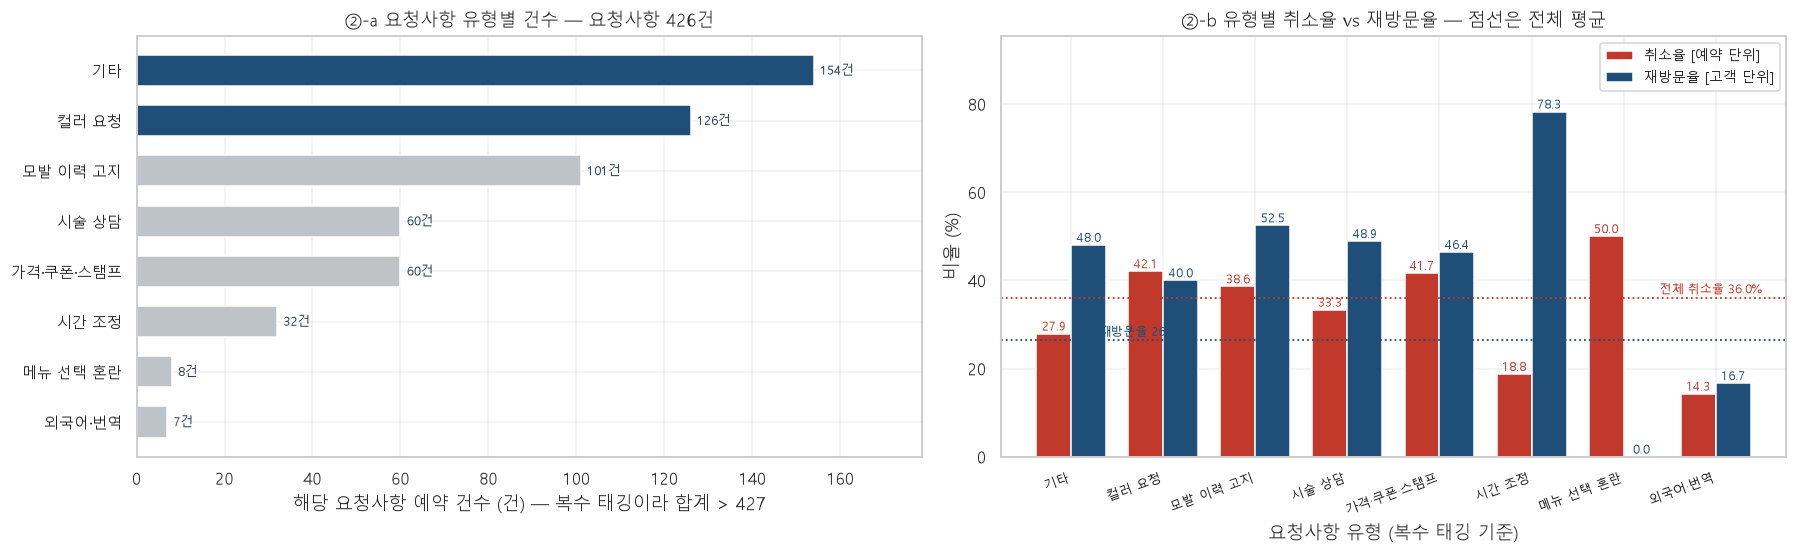

In [28]:
# ── ②-b 그래프: 유형별 건수 가로 막대 + 취소율/재방문율 grouped bar ────────
fig, axes = plt.subplots(1, 2, figsize=(16.5, 5.2))

ax = axes[0]
_o = REQ_PERF.sort_values("예약건수")
_top2 = set(REQ_PERF.예약건수.nlargest(2).index)
ax.barh(range(len(_o)), _o.예약건수,
        color=[C_MAIN if i in _top2 else C_GRAY for i in _o.index], height=0.62)
barlab_h(ax, range(len(_o)), _o.예약건수.values, "{:,.0f}건")
ax.set_yticks(range(len(_o))); ax.set_yticklabels(_o.index, fontsize=9.5)
ax.set_xlim(0, _o.예약건수.max() * 1.16)
ax.set_xlabel("해당 요청사항 예약 건수 (건) — 복수 태깅이라 합계 > 427")
ax.set_title(f"②-a 요청사항 유형별 건수 — 요청사항 {len(REQ):,}건")

ax = axes[1]
_g = REQ_PERF.sort_values("예약건수", ascending=False)
_x = np.arange(len(_g)); _w = 0.38
ax.bar(_x - _w/2, _g["취소율(%)"], _w, color=C_ACC, label="취소율 [예약 단위]")
ax.bar(_x + _w/2, _g["재방문율(%)"], _w, color=C_MAIN, label="재방문율 [고객 단위]")
barlab(ax, _x - _w/2, _g["취소율(%)"].values, "{:.1f}", dy=2, fs=8, color=C_ACC)
barlab(ax, _x + _w/2, _g["재방문율(%)"].values, "{:.1f}", dy=2, fs=8, color=C_MAIN)
ax.axhline((R.status == "취소").mean()*100, color=C_ACC, ls=":", lw=1.2)
ax.axhline(CUST.재방문.mean()*100, color=C_MAIN, ls=":", lw=1.2)
ax.annotate(f"전체 취소율 {(R.status=='취소').mean()*100:.1f}%", (len(_g)-0.5, (R.status=='취소').mean()*100),
            fontsize=8, color=C_ACC, ha="right", textcoords="offset points", xytext=(0, 3))
ax.annotate(f"전체 재방문율 {CUST.재방문.mean()*100:.1f}%", (0, CUST.재방문.mean()*100),
            fontsize=8, color=C_MAIN, textcoords="offset points", xytext=(0, 3))
ax.set_xticks(_x); ax.set_xticklabels(_g.index, rotation=20, ha="right", fontsize=8.5)
ax.set_ylabel("비율 (%)"); ax.set_xlabel("요청사항 유형 (복수 태깅 기준)")
ax.set_ylim(0, max(_g["취소율(%)"].max(), _g["재방문율(%)"].max()) * 1.22)
ax.set_title("②-b 유형별 취소율 vs 재방문율 — 점선은 전체 평균")
ax.legend(fontsize=9)
plt.tight_layout(); plt.show()

## ②-c 취소사유 "기타" 326건 재분류

02번은 취소사유를 `날짜변경 / 시간변경 / 다시예약 / 기타 / 미기재` 로 나눴다.
그중 **`기타` 326건**을 다시 쪼갠다. 여기에 **진짜 이탈 사유**(가격, 다른 곳 예약, 시술 부담 등)가
숨어 있을 수 있기 때문이다.

**나머지 4종 분류는 손대지 않는다.** §0-5 게이트가 그 값을 지키고 있다.

### 재분류 규칙 — 순서대로 첫 매칭

| # | 유형 | 판정 키워드 |
|---|---|---|
| 1 | **매장 측 사유** | `매장휴무` `휴무` `업체측` `판매자` `다음에 오세요` `다시 잡고` `반려` `비추후기` `예의` `선생님…안` |
| 2 | **변심·재고(再考)** | `변심` `성급` `고민` `하기 싫` `생각해` `충동` `안 하기` |
| 3 | **건강·질병** | `독감` `코로나` `장염` `감기` `아파/아프` `몸` `병원` `입원` `수술` `진료` `치료` `건강` `두피` `환자` |
| 4 | **예약 실수·오입력** | `잘못` `착오` `실수` `오기입` `중복` `반복` `오류` `잘못 눌` `표기 오` |
| 5 | **시술·메뉴 변경** | `시술` `메뉴` `항목` `선택 변경` `커트로` `디자이너 변경` |
| 6 | **결제수단 변경** | `결제` |
| 7 | **지각·도착 불가** | `늦` `도착` `못 가/못갈` `지연` `출발` |
| 8 | **교통·날씨** | `비가` `눈이` `차가 막` `교통` `사고` `날씨` |
| 9 | **개인 일정·약속** | `일정` `스케줄` `약속` `급한/급히/갑자기` `개인사정/사유` `출근` `회사` `업무` `출장` `학교` `학원` `알바` `여행` `비행기` |
| 10 | 날짜 변경 (1차 규칙 누락분) | `날짜` `일자` `예약일` `다른 날` `담주` `내일` `요일` `옮` |
| 11 | 시간 변경 (1차 규칙 누락분) | `시간` `시각` `타임` `N시` |
| 12 | **외국어** | (요청사항과 같은 `is_foreign` 함수) |
| 13 | **무의미·무정보 입력** | 공백 제거 후 2글자 이하이거나 한글·영문·숫자가 하나도 없음 |
| 14 | **단순 사과·무정보** | `죄송` `감사` `취소합니다` 만 있고 사유가 없음 |
| 15 | 기타(잔여) | 위 어디에도 안 걸림 |

**순서를 이렇게 잡은 이유**: 목적이 "진짜 이탈 사유 찾기"이므로 **희소하지만 중요한 사유를 위로** 올렸다.
`일정` 같은 광범위 키워드를 위에 두면 그 아래 사유가 전부 삼켜진다.

> **공개본** — ②-c2 빈도 상위 표현 표는 가린 텍스트로 세었기 때문에 빈도가 원본 분석과 다르다. 앞의 ②-c1 2차 분류(15종)는 원본과 행 단위로 같다.

In [29]:
# ── ②-c1 취소사유 '기타' 재분류 ────────────────────────────────────────────
CANC_L2_RULES = [
    ("매장 측 사유",      r"매장\s*휴무|휴무|업체|판매자|다음에\s*오세요|다시\s*잡고|반려|비추\s*후기|비추후기|예의|"
                          r"선생님.{0,8}안|삭제할게"),
    ("변심·재고",         r"변심|성급|고민|하기\s*싫|생각해|충동|안\s*하기|더\s*있다가|일주일만"),
    ("건강·질병",         r"독감|코로나|장염|감기|아파|아프|몸\s*(이|상태|너무)|병원|입원|수술|진료|치료|건강|두피|환자|퇴원"),
    ("예약 실수·오입력",  r"잘못|착오|실수|오기입|오입력|중복|반복|오류|잘\s*못|표기\s*오|불충분|부실|위치\s*착각|시범"),
    ("시술·메뉴 변경",    r"시술|메뉴|항목|선택\s*변경|선택변경|커트로|디자이너\s*변경|무한탈색|뿌탈|염색|탈색"),
    ("결제수단 변경",     r"결제"),
    ("지각·도착 불가",    r"늦|도착|못\s*(가|갈|올|와)|못가|못갈|지연|출발"),
    ("교통·날씨",         r"비가|비\s*온|눈이|차가\s*막|교통|사고|날씨"),
    ("개인 일정·약속",    r"일정|스케|약속|급한|급히|급\s|갑자기|갑작|개인\s*(사정|사유|일정)|개인사정|개인사유|"
                          r"출근|회사|업무|출장|학교|학원|알바|졸업|여행|비행|항공|집안|용무|파토|일이\s*생|일\s*때문"),
    ("날짜 변경(누락분)",  r"날짜|날쩌|닐짜|날\s*짜|일자|예약일|예약\s*일|다른\s*날|담주|다음\s*주|내일|모레|요일|옮|"
                          r"다음달|이후로\s*변경|일시\s*변경|더\s*빠른"),
    ("시간 변경(누락분)",  r"시간|시각|타임|\d\s*시|시간대|여유"),
]

def cancel_reason_l2(s):
    if not isinstance(s, str):
        s = ""
    t = re.sub(r"\s+", " ", s).strip()
    bare = re.sub(r"\s+", "", t)
    if len(bare) <= 2 or not re.search(r"[가-힣A-Za-z0-9一-鿿]", bare):
        return "무의미·무정보 입력"
    if is_foreign(t):
        return "외국어"
    for name, pat in CANC_L2_RULES:
        if re.search(pat, t):
            return name
    if re.search(r"죄송|감사|취소합니다|^취소$|미확인", t):
        return "단순 사과·무정보"
    return "기타(잔여)"

_etc = CANC[CANC.cancel_reason_l1 == "기타"].copy()
_etc["l2"] = _etc.취소사유.map(cancel_reason_l2)
assert len(_etc) == 326, f"기타 건수가 326이 아니다: {len(_etc)}"

L2_ORDER = [n for n, _ in CANC_L2_RULES] + ["외국어", "무의미·무정보 입력", "단순 사과·무정보", "기타(잔여)"]
_l2 = _etc.l2.value_counts().reindex(L2_ORDER).fillna(0).astype(int).rename("건수").to_frame()
_l2["기타 326건 대비(%)"] = _l2.건수 / len(_etc) * 100
_l2["전체 취소 1,542건 대비(%)"] = _l2.건수 / len(CANC) * 100
_l2["완료 객단가 중앙값(그 예약의 paid)"] = _etc.groupby("l2").paid.median().reindex(L2_ORDER)
_l2["소표본"] = _l2.건수.map(lambda n: small(n))
tbl(_l2.round(2), "②-c1 취소사유 '기타' 326건의 재분류")
print(f"합계 {int(_l2.건수.sum())}건 = 기타 {len(_etc)}건")
assert int(_l2.건수.sum()) == len(_etc)
print()
print("── 새로 드러난 유형 (02번 4종 분류에는 없던 것) ──")
for k in ["매장 측 사유", "변심·재고", "건강·질병", "예약 실수·오입력", "교통·날씨", "결제수단 변경"]:
    print(f"  {k:<16} {int(_l2.loc[k,'건수']):>4}건  (전체 취소의 {_l2.loc[k,'전체 취소 1,542건 대비(%)']:.2f}%)")

**②-c1 취소사유 '기타' 326건의 재분류**

,건수,기타 326건 대비(%),"전체 취소 1,542건 대비(%)",완료 객단가 중앙값(그 예약의 paid),소표본
l2,,,,,
매장 측 사유,10,3.07,0.65,100000.0,⚠소표본
변심·재고,9,2.76,0.58,150000.0,⚠소표본
건강·질병,16,4.91,1.04,125000.0,⚠소표본
예약 실수·오입력,35,10.74,2.27,150000.0,
시술·메뉴 변경,12,3.68,0.78,100000.0,⚠소표본
결제수단 변경,4,1.23,0.26,150000.0,⚠소표본
지각·도착 불가,12,3.68,0.78,100000.0,⚠소표본
교통·날씨,2,0.61,0.13,69500.0,⚠소표본
개인 일정·약속,55,16.87,3.57,100000.0,


합계 326건 = 기타 326건

── 새로 드러난 유형 (02번 4종 분류에는 없던 것) ──
  매장 측 사유            10건  (전체 취소의 0.65%)
  변심·재고               9건  (전체 취소의 0.58%)
  건강·질병              16건  (전체 취소의 1.04%)
  예약 실수·오입력          35건  (전체 취소의 2.27%)
  교통·날씨               2건  (전체 취소의 0.13%)
  결제수단 변경             4건  (전체 취소의 0.26%)


In [30]:
# ── ②-c2 빈도 상위 표현 ────────────────────────────────────────────────────
_txt = _etc.취소사유.fillna("").astype(str)
_toks = Counter()
for t in _txt:
    for w in re.findall(r"[가-힣]{2,}", t):
        _toks[w] += 1
_freq = (pd.DataFrame(_toks.most_common(35), columns=["표현(2글자 이상 한글 토큰)", "등장 건수"])
           .assign(비중=lambda d: d["등장 건수"] / len(_etc) * 100))
tbl(_freq.round(2), "②-c2 '기타' 326건의 빈도 상위 표현 35개")

# 원문 전수는 길어서 유형별 대표 사례만 (마스킹 적용)
print("── 유형별 원문 사례 (각 최대 6건, 마스킹 적용) ──")
for k in L2_ORDER:
    sub = _etc[_etc.l2 == k]
    if len(sub) == 0:
        continue
    print(f"\n▶ {k}  ({len(sub)}건)")
    for t in sub.취소사유.fillna("").astype(str).drop_duplicates().head(6):
        print("   ·", mask(t)[:110])

**②-c2 '기타' 326건의 빈도 상위 표현 35개**

,표현(2글자 이상 한글 토큰),등장 건수,비중
0,변경,43,13.19
1,죄송합니다,24,7.36
2,시간,20,6.13
3,잘못,15,4.60
4,시간을,15,4.60
5,날짜를,14,4.29
6,예약,14,4.29
7,다른,13,3.99
8,날짜,13,3.99
9,일정,12,3.68


── 유형별 원문 사례 (각 최대 6건, 마스킹 적용) ──

▶ 매장 측 사유  (10건)
   · 예약 다시 잡고 오세요
   · 문의가 예의가 없어요
   · 선생님이 안ㄺㄾㄽㅌ 이거는 삭제할게요
   · 다음에 오세요~^^
   · ㅆㅃ 디자이너 휴무
   · 업체ㄱ 변경 요청

▶ 변심·재고  (9건)
   · 너무 성급한ㄻㄺ이라 조금만 더 생각해보고 다음에 예약 ㅆㄹㅍㅌ 죄송합니다ㅠㅜ
   · 새벽에 충동 ㄻㄺ했어요 .. 죄송합니다 ㅜㅜ
   · ㅌㅃ 하기 싫ㄹㄾ
   · 너무 죄송해요 ⏎ 전날까지 계속 고민하다가 탈색은 너무 ㅀㄿㅉ ㅆㅄㄵ 것 ㄺㄺ 취소하게 ㅌㄳㅄㄿㄼㅜㅜ
   · ㄸㅌ 변심
   · ㄸㅌ변심

▶ 건강·질병  (16건)
   · 독감ㄾㅃㅀ ㄲㄻㄸ 오늘방문 ㄼㅌㅃㅃ같습니다 죄송합니다ㅠㅠ
   · 독감ㄾㄹㄵㅃㄸ 예약취소합니다ㅠㅠ
   · 독감 ㄿㄺ ㄼㅃ ㄱㄶ되어 예약 취소합니다 죄송합니다
   · 시술 환자가 너무 ㄸㄶㄹ,,,,,
   · 입원으로 ㄼㄶ ㄸㄽ 날짜에 시술ㄼㄼㄼ ㄱㄵㄵㅍ
   · 건강 사유

▶ 예약 실수·오입력  (35건)
   · 잘못 예약
   · 중복예약
   · 잘못예약
   · 메뉴항목 잘못선택
   · 항목 부실선택
   · 메뉴불충분확인

▶ 시술·메뉴 변경  (12건)
   · ㅉㄹㄹㅍ ㅉㄼ ㅃㄳ 것 ㄺㄺ 커트로 ㅀㅆㄳㄾ 합니다
   · 메뉴항목취소
   · 디자이너 변경
   · 메뉴변경
   · ㄸㅍㄼ 탈색ㄵㅆ 뿌탈이랑 염색 ⏎ ㄻㄲㅀㄲㄱ
   · 시술내용을 ㅀㄲㄶㅉ 합니다

▶ 결제수단 변경  (4건)
   · 결제방법 변경
   · 결제ㄵㄾㄳㅃ

▶ 지각·도착 불가  (12건)
   · 일이 늦어ㅉㄵ 못가ㄼ ㄹㄻㄱㄽ
   · 일 때문에 아직 출발을 ㄿㄲㅄㄲ 죄송해요ㅜ
   · 7시까지는 도착 ㅆㄵㅀ ㅃㅉㄼ 취소할게요.ㅜㅜ
   · 학교가 늦게ㅉㄻㄼㄺ..ㅠㅠ
   · 교통ㅆㅃㄺ 학교일정으로 도착할 ㅃ ㄼㄾ
   · 시간을 착각해서 시간내에 도착하기가 ㅍㅍㅃㅃㅜ

▶ 교통·날씨  (2건)
   · 비가

In [31]:
# ── ②-c3 진짜 이탈 신호인가 — 재분류 유형별 사후 재방문 ────────────────────
# 02번 ①-1 정의(단방향 45일)를 그대로 쓴다.
WINDOW_D = 45
_done_by_cust = {k: np.sort(v.values) for k, v in DONE.groupby("cust_key")["use_dt"]}

def days_to_next_done(cust_key, use_dt):
    arr = _done_by_cust.get(cust_key)
    if arr is None:
        return np.nan
    i = np.searchsorted(arr, np.datetime64(use_dt), side="left")
    if i >= len(arr):
        return np.nan
    return (arr[i] - np.datetime64(use_dt)) / np.timedelta64(1, "D")

CANC["days_to_next"] = [days_to_next_done(k, d) for k, d in zip(CANC.cust_key, CANC.use_dt)]
CANC["revisit_fwd"]  = CANC.days_to_next <= WINDOW_D
_etc["days_to_next"] = CANC.loc[_etc.index, "days_to_next"]
_etc["revisit_fwd"]  = CANC.loc[_etc.index, "revisit_fwd"]

print(f"검증: 02번 ①-1 단방향 45일 재방문율 {CANC.revisit_fwd.mean()*100:.2f}% (02번 출력 50.00%)")
assert round(CANC.revisit_fwd.mean()*100, 2) == 50.00, "02번 ①-1 단방향 재방문율과 불일치"

_l2r = (_etc.groupby("l2").agg(건수=("예약번호", "size"), 재예약45일=("revisit_fwd", "sum"))
             .reindex(L2_ORDER).fillna(0))
_l2r["재예약률(%)"] = _l2r.재예약45일 / _l2r.건수 * 100
_l2r["순이탈 건수"] = _l2r.건수 - _l2r.재예약45일
_l2r["소표본"] = _l2r.건수.map(lambda n: small(n))
_l2r = _l2r.astype({"건수": int, "재예약45일": int, "순이탈 건수": int})
tbl(_l2r.round(2), "②-c3 재분류 유형별 45일 내 재예약률 — 낮을수록 진짜 이탈에 가깝다")
print(f"기타 326건 전체 재예약률 {_etc.revisit_fwd.mean()*100:.2f}% (02번 출력 46.01%)")
assert round(_etc.revisit_fwd.mean()*100, 2) == 46.01, "02번 ①-c 기타 재예약률과 불일치"
print()
_low = _l2r[(_l2r.건수 >= 10)].sort_values("재예약률(%)").head(4)
print("표본 10건 이상 중 재예약률이 낮은 유형 (= 진짜 이탈 후보):")
for k, r in _low.iterrows():
    print(f"  {k:<18} {int(r.건수):>3}건 · 재예약률 {r['재예약률(%)']:.1f}% · 순이탈 {int(r['순이탈 건수'])}건")

검증: 02번 ①-1 단방향 45일 재방문율 50.00% (02번 출력 50.00%)


**②-c3 재분류 유형별 45일 내 재예약률 — 낮을수록 진짜 이탈에 가깝다**

,건수,재예약45일,재예약률(%),순이탈 건수,소표본
l2,,,,,
매장 측 사유,10,4,40.00,6,⚠소표본
변심·재고,9,2,22.22,7,⚠소표본
건강·질병,16,6,37.50,10,⚠소표본
예약 실수·오입력,35,16,45.71,19,
시술·메뉴 변경,12,8,66.67,4,⚠소표본
결제수단 변경,4,4,100.00,0,⚠소표본
지각·도착 불가,12,10,83.33,2,⚠소표본
교통·날씨,2,2,100.00,0,⚠소표본
개인 일정·약속,55,21,38.18,34,


기타 326건 전체 재예약률 46.01% (02번 출력 46.01%)

표본 10건 이상 중 재예약률이 낮은 유형 (= 진짜 이탈 후보):
  날짜 변경(누락분)          41건 · 재예약률 34.1% · 순이탈 27건
  건강·질병               16건 · 재예약률 37.5% · 순이탈 10건
  개인 일정·약속            55건 · 재예약률 38.2% · 순이탈 34건
  매장 측 사유             10건 · 재예약률 40.0% · 순이탈 6건


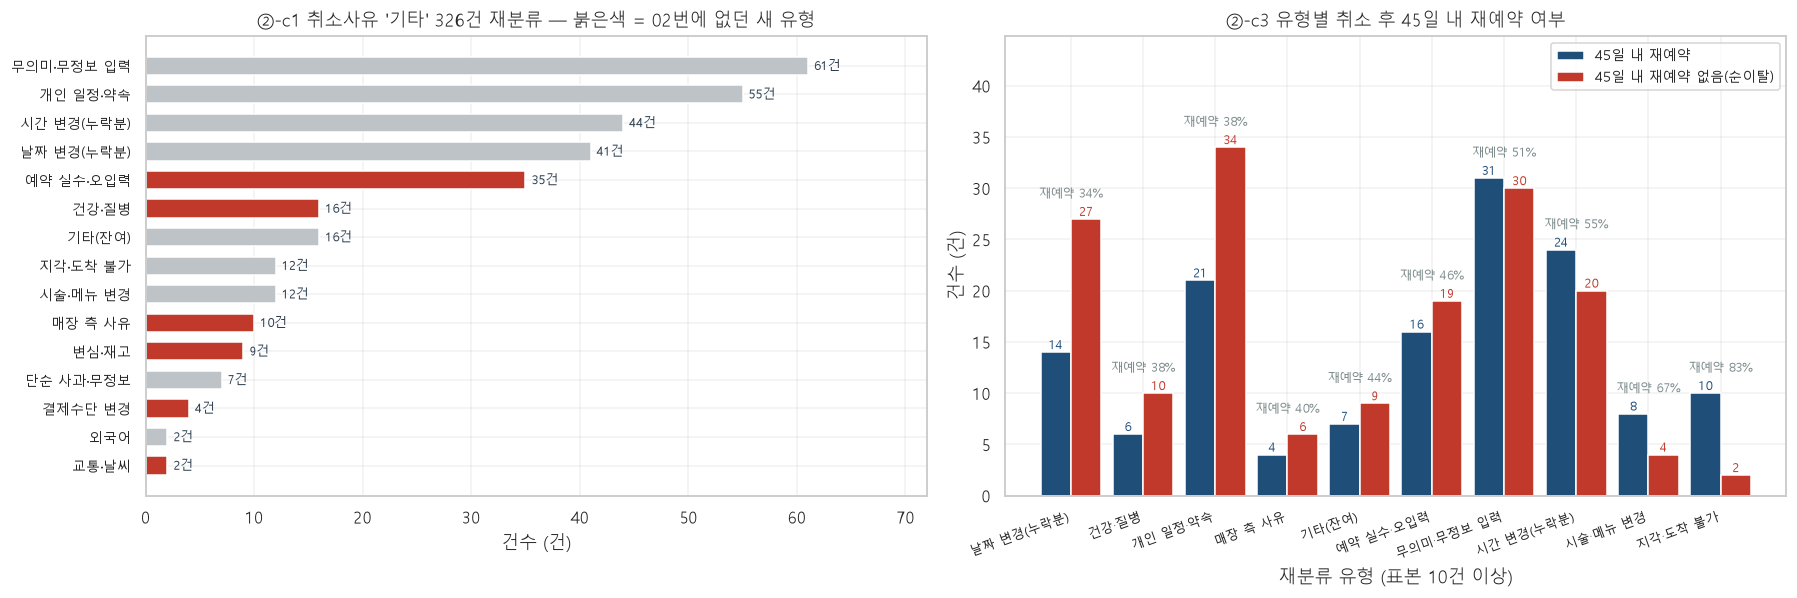

In [32]:
# ── ②-c 그래프: 재분류 구성 가로 막대 + 유형별 재예약률 ────────────────────
fig, axes = plt.subplots(1, 2, figsize=(16.5, 5.6))

ax = axes[0]
_o = _l2[_l2.건수 > 0].sort_values("건수")
_new_types = {"매장 측 사유", "변심·재고", "건강·질병", "예약 실수·오입력", "교통·날씨", "결제수단 변경"}
ax.barh(range(len(_o)), _o.건수,
        color=[C_ACC if i in _new_types else C_GRAY for i in _o.index], height=0.64)
barlab_h(ax, range(len(_o)), _o.건수.values, "{:,.0f}건")
ax.set_yticks(range(len(_o))); ax.set_yticklabels(_o.index, fontsize=9)
ax.set_xlim(0, _o.건수.max() * 1.18)
ax.set_xlabel("건수 (건)")
ax.set_title(f"②-c1 취소사유 '기타' {len(_etc)}건 재분류 — 붉은색 = 02번에 없던 새 유형")

ax = axes[1]
_r = _l2r[_l2r.건수 >= 10].sort_values("재예약률(%)")
_x = np.arange(len(_r)); _w = 0.42
ax.bar(_x - _w/2, _r.재예약45일, _w, color=C_MAIN, label="45일 내 재예약")
ax.bar(_x + _w/2, _r["순이탈 건수"], _w, color=C_ACC, label="45일 내 재예약 없음(순이탈)")
barlab(ax, _x - _w/2, _r.재예약45일.values, "{:,.0f}", dy=2, fs=8, color=C_MAIN)
barlab(ax, _x + _w/2, _r["순이탈 건수"].values, "{:,.0f}", dy=2, fs=8, color=C_ACC)
for i, v in enumerate(_r["재예약률(%)"]):
    ax.annotate(f"재예약 {v:.0f}%", (i, max(_r.재예약45일.iloc[i], _r['순이탈 건수'].iloc[i])),
                textcoords="offset points", xytext=(0, 14), ha="center", fontsize=8, color=C_DARKG)
ax.set_xticks(_x); ax.set_xticklabels(_r.index, rotation=20, ha="right", fontsize=8.5)
ax.set_ylabel("건수 (건)"); ax.set_xlabel("재분류 유형 (표본 10건 이상)")
ax.set_ylim(0, max(_r.재예약45일.max(), _r["순이탈 건수"].max()) * 1.32)
ax.set_title("②-c3 유형별 취소 후 45일 내 재예약 여부")
ax.legend(fontsize=9)
plt.tight_layout(); plt.show()

## ②-d 챗봇 FAQ 후보 — 이 섹션의 최종 산출물

요청사항 + 취소사유에서 나온 유형을 **빈도 × 답변 가능성**으로 정리한다.

### 챗봇이 확답하면 **안 되는** 영역 (명시적으로 표시)

| 영역 | 이유 |
|---|---|
| **개인 모발 상태 진단** | 모발 손상도·잔여 색소는 눈으로 봐야 안다. 잘못 답하면 시술 실패로 이어진다 |
| **확정 가격** | 기장 추가금이 데이터에 없다(원본 분석 문서 §8 미해결). `paid − listed` 차액 3,110만원의 정체도 미규명 |
| **시술 안전 보장** | "이 상태로 탈색해도 되나요"에 챗봇이 "네"라고 답하면 안 된다 |

이 세 영역은 **"상담 연결"** 로만 답한다.
나머지 중 **빈도 상위 6개가 고정 버튼 후보**다.

In [33]:
# ── ②-d 챗봇 FAQ 후보표 ────────────────────────────────────────────────────
def _n_req(pat):
    return int(REQ.req_txt.str.contains(pat, regex=True).sum())

FAQ = [
    # (질문 유형, 근거 건수, 근거 출처, 확답 가능, 형태, 비고)
    ("예약 메뉴를 뭘 골라야 하는지 모르겠다",
     int(REQ.tags.map(lambda x: "메뉴 선택 혼란" in x).sum()), "요청사항 '메뉴 선택 혼란' 태그",
     "가능", "버튼", "시술별 메뉴 선택 가이드. 애매하면 '상담 후 결정' 옵션 안내"),
    ("쿠폰·스탬프·생일쿠폰을 쓸 수 있나",
     len(_st), "요청사항 스탬프·쿠폰 언급",
     "조건부 가능", "버튼", "⚠️ 제도 규칙을 사장님께 먼저 확인해야 함 (②-a4). 확인 후에만 확답"),
    ("예약 시간을 바꾸고 싶다 / 늦을 것 같다",
     int(REQ.tags.map(lambda x: "시간 조정" in x).sum())
     + int(_l2.loc["지각·도착 불가", "건수"]) + int(_cr01["시간변경"]),
     "요청사항 '시간 조정' + 취소 '지각·도착 불가' + 취소사유 시간변경",
     "가능", "버튼", "변경 가능 시간대 안내 + 예약 변경 링크. 챗봇이 가장 크게 줄일 수 있는 항목"),
    ("예약 날짜를 바꾸고 싶다 / 취소하고 싶다",
     int(_cr01["날짜변경"]) + int(_cr01["다시예약"]) + int(_l2.loc["날짜 변경(누락분)", "건수"]),
     "취소사유 날짜변경 + 다시예약 + 재분류 날짜변경",
     "가능", "버튼", "재예약 유도 문구를 함께 띄우는 것이 핵심 (취소의 절반이 45일 내 재방문)"),
    ("기장 추가금이 있나 / 얼마나 나오나",
     _n_req(r"기장\s*추가|기장추가|추가금|추가\s*비용|얼마|가격|비용"),
     "요청사항 가격 관련 표현",
     "❌ 불가 (확정 가격)", "상담 연결", "기장 추가요금 금액이 데이터에 없다. 범위조차 확답 금지"),
    ("내 모발 상태로 이 시술이 가능한가",
     int(REQ.tags.map(lambda x: "모발 이력 고지" in x).sum()),
     "요청사항 '모발 이력 고지' 태그",
     "❌ 불가 (개인 모발 진단)", "상담 연결", "이력을 받아 적어 두는 것까지만. 판단은 사람이"),
    ("원하는 색이 가능한가 / 어떤 색이 어울리나",
     int(REQ.tags.map(lambda x: "컬러 요청" in x).sum()),
     "요청사항 '컬러 요청' 태그",
     "❌ 불가 (시술 안전 보장)", "상담 연결", "컬러 사례 사진 안내까지만. 가능 여부 확답 금지"),
    ("외국어 응대가 되나",
     int(REQ.tags.map(lambda x: "외국어·번역" in x).sum()) + int(_l2.loc["외국어", "건수"]),
     "요청사항 외국어 + 취소사유 외국어",
     "가능", "버튼", "영어·중국어·일본어 메뉴가 이미 존재. 응대 가능 언어와 방식만 안내"),
    ("주차·발렛이 되나",
     _n_req(r"발렛|주차"), "요청사항 주차·발렛 언급",
     "가능", "버튼", "⚠️ 근거 건수가 적다. 실제 문의는 전화로 갔을 가능성"),
    ("동반 방문 / 다른 사람 대신 예약이 되나",
     _n_req(r"남편|와이프|아내|여자친구|남자친구|친구|어머니|엄마|딸|아들|동생|지인|\d\s*명|같이\s*(가|방문|예약)|동행|대신\s*예약"),
     "요청사항 동반·대리 예약 표현",
     "가능", "버튼", "1인 1예약 원칙과 인원 추가 방법 안내"),
    ("시술이 몇 시간 걸리나",
     _n_req(r"몇\s*시간|얼마나\s*걸|한시간|한\s*시간만|끝나(야|길)|시간\s*내|하루\s*안"),
     "요청사항 소요시간 언급",
     "가능", "버튼", "시술별 표준 소요시간. ③에서 쓰는 가정과 같은 값을 써야 함"),
    ("영업시간·휴무일이 언제인가",
     int(_l2.loc["매장 측 사유", "건수"]), "취소사유 '매장 측 사유'(휴무 포함)",
     "가능", "버튼", "근거 건수는 적지만 답이 확정적이라 비용이 0"),
]
FAQ_DF = pd.DataFrame(FAQ, columns=["질문 유형", "근거 건수", "근거 출처", "챗봇이 확답 가능한가",
                                    "버튼/자유질의", "비고"])
FAQ_DF = FAQ_DF.sort_values("근거 건수", ascending=False).reset_index(drop=True)
FAQ_DF["소표본"] = FAQ_DF["근거 건수"].map(lambda n: small(n))
tbl(FAQ_DF, "②-d 챗봇 FAQ 후보 — 빈도 x 답변 가능성")

BTN6 = FAQ_DF[FAQ_DF["챗봇이 확답 가능한가"].str.startswith(("가능", "조건부"))].head(6).reset_index(drop=True)
BTN6.index = BTN6.index + 1
tbl(BTN6[["질문 유형", "근거 건수", "챗봇이 확답 가능한가", "비고"]],
    "②-d2 ★ 고정 버튼 후보 6개 — 확답 가능한 것 중 빈도 상위")
print()
print("상담 연결로만 넘겨야 하는 항목 (확답 금지):")
for _, r in FAQ_DF[FAQ_DF["챗봇이 확답 가능한가"].str.startswith("❌")].iterrows():
    print(f"  · {r['질문 유형']}  ({r['근거 건수']}건) — {r['챗봇이 확답 가능한가']}")

**②-d 챗봇 FAQ 후보 — 빈도 x 답변 가능성**

,질문 유형,근거 건수,근거 출처,챗봇이 확답 가능한가,버튼/자유질의,비고,소표본
0,예약 날짜를 바꾸고 싶다 / 취소하고 싶다,409,취소사유 날짜변경 + 다시예약 + 재분류 날짜변경,가능,버튼,재예약 유도 문구를 함께 띄우는 것이 핵심 (취소의 절반이 45일 내 재방문),
1,예약 시간을 바꾸고 싶다 / 늦을 것 같다,230,요청사항 '시간 조정' + 취소 '지각·도착 불가' + 취소사유 시간변경,가능,버튼,변경 가능 시간대 안내 + 예약 변경 링크. 챗봇이 가장 크게 줄일 수 있는 항목,
2,원하는 색이 가능한가 / 어떤 색이 어울리나,126,요청사항 '컬러 요청' 태그,❌ 불가 (시술 안전 보장),상담 연결,컬러 사례 사진 안내까지만. 가능 여부 확답 금지,
3,내 모발 상태로 이 시술이 가능한가,101,요청사항 '모발 이력 고지' 태그,❌ 불가 (개인 모발 진단),상담 연결,이력을 받아 적어 두는 것까지만. 판단은 사람이,
4,동반 방문 / 다른 사람 대신 예약이 되나,54,요청사항 동반·대리 예약 표현,가능,버튼,1인 1예약 원칙과 인원 추가 방법 안내,
5,쿠폰·스탬프·생일쿠폰을 쓸 수 있나,44,요청사항 스탬프·쿠폰 언급,조건부 가능,버튼,⚠️ 제도 규칙을 사장님께 먼저 확인해야 함 (②-a4). 확인 후에만 확답,
6,기장 추가금이 있나 / 얼마나 나오나,14,요청사항 가격 관련 표현,❌ 불가 (확정 가격),상담 연결,기장 추가요금 금액이 데이터에 없다. 범위조차 확답 금지,⚠소표본
7,영업시간·휴무일이 언제인가,10,취소사유 '매장 측 사유'(휴무 포함),가능,버튼,근거 건수는 적지만 답이 확정적이라 비용이 0,⚠소표본
8,외국어 응대가 되나,9,요청사항 외국어 + 취소사유 외국어,가능,버튼,영어·중국어·일본어 메뉴가 이미 존재. 응대 가능 언어와 방식만 안내,⚠소표본
9,예약 메뉴를 뭘 골라야 하는지 모르겠다,8,요청사항 '메뉴 선택 혼란' 태그,가능,버튼,시술별 메뉴 선택 가이드. 애매하면 '상담 후 결정' 옵션 안내,⚠소표본


**②-d2 ★ 고정 버튼 후보 6개 — 확답 가능한 것 중 빈도 상위**

,질문 유형,근거 건수,챗봇이 확답 가능한가,비고
1,예약 날짜를 바꾸고 싶다 / 취소하고 싶다,409,가능,재예약 유도 문구를 함께 띄우는 것이 핵심 (취소의 절반이 45일 내 재방문)
2,예약 시간을 바꾸고 싶다 / 늦을 것 같다,230,가능,변경 가능 시간대 안내 + 예약 변경 링크. 챗봇이 가장 크게 줄일 수 있는 항목
3,동반 방문 / 다른 사람 대신 예약이 되나,54,가능,1인 1예약 원칙과 인원 추가 방법 안내
4,쿠폰·스탬프·생일쿠폰을 쓸 수 있나,44,조건부 가능,⚠️ 제도 규칙을 사장님께 먼저 확인해야 함 (②-a4). 확인 후에만 확답
5,영업시간·휴무일이 언제인가,10,가능,근거 건수는 적지만 답이 확정적이라 비용이 0
6,외국어 응대가 되나,9,가능,영어·중국어·일본어 메뉴가 이미 존재. 응대 가능 언어와 방식만 안내



상담 연결로만 넘겨야 하는 항목 (확답 금지):
  · 원하는 색이 가능한가 / 어떤 색이 어울리나  (126건) — ❌ 불가 (시술 안전 보장)
  · 내 모발 상태로 이 시술이 가능한가  (101건) — ❌ 불가 (개인 모발 진단)
  · 기장 추가금이 있나 / 얼마나 나오나  (14건) — ❌ 불가 (확정 가격)


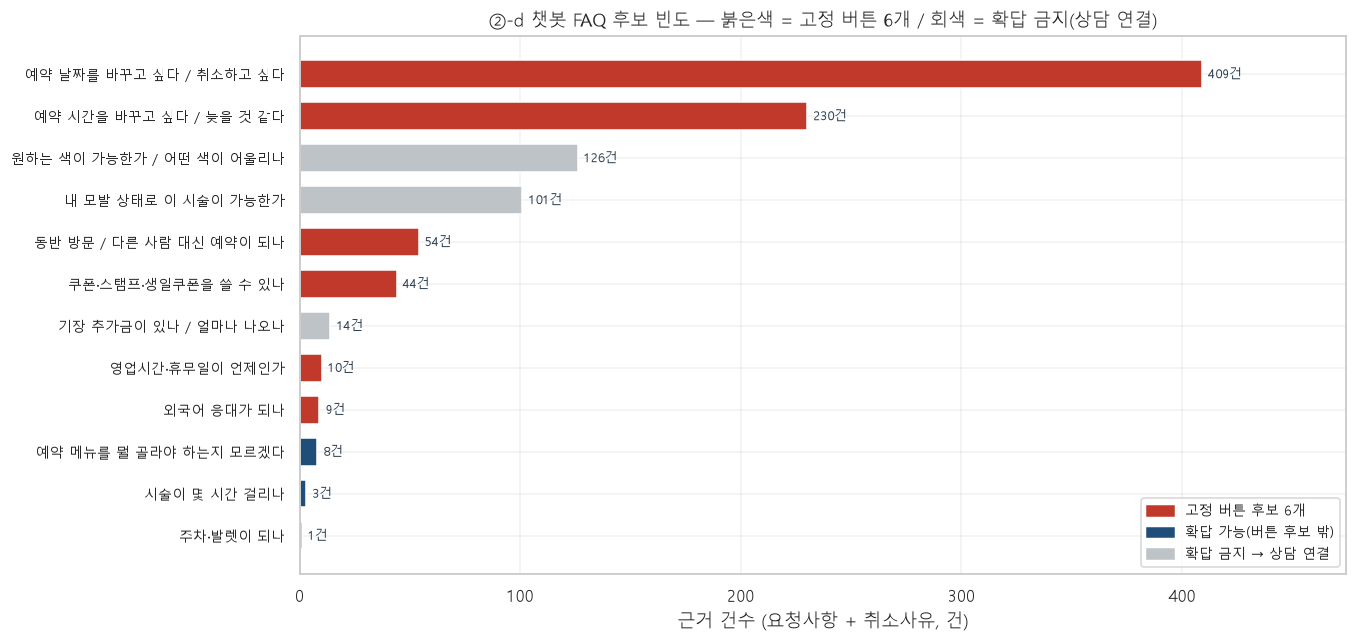

In [34]:
# ── ②-d 그래프: FAQ 후보 빈도 막대 ─────────────────────────────────────────
fig, ax = plt.subplots(figsize=(12.5, 6))
_f = FAQ_DF.sort_values("근거 건수")
_ok = _f["챗봇이 확답 가능한가"].str.startswith(("가능", "조건부"))
_cols = [C_MAIN if o else C_GRAY for o in _ok]
_btn_set = set(BTN6["질문 유형"])
_cols = [C_ACC if q in _btn_set else c for q, c in zip(_f["질문 유형"], _cols)]
ax.barh(range(len(_f)), _f["근거 건수"], color=_cols, height=0.66)
barlab_h(ax, range(len(_f)), _f["근거 건수"].values, "{:,.0f}건")
ax.set_yticks(range(len(_f)))
ax.set_yticklabels([q if len(q) <= 30 else q[:29] + "…" for q in _f["질문 유형"]], fontsize=9)
ax.set_xlim(0, _f["근거 건수"].max() * 1.16)
ax.set_xlabel("근거 건수 (요청사항 + 취소사유, 건)")
ax.set_title("②-d 챗봇 FAQ 후보 빈도 — 붉은색 = 고정 버튼 6개 / 회색 = 확답 금지(상담 연결)")
ax.legend(handles=[Patch(color=C_ACC, label="고정 버튼 후보 6개"),
                   Patch(color=C_MAIN, label="확답 가능(버튼 후보 밖)"),
                   Patch(color=C_GRAY, label="확답 금지 → 상담 연결")],
          loc="lower right", fontsize=9)
plt.tight_layout(); plt.show()

---
# ③ 캐파 검증 — "자리가 없다"가 정말 맞는지 정면으로 검증

## 이 섹션은 가설 확인이 아니라 **가설 검정**이다

앞선 분석(01번 ⑪, 02번 ⑤-2)의 결론은 이랬다:

> 2026년 시간 기준 가동률 — 가온 **78.33%** / 나래 **69.81%** / 다솜 **45.86%**
> (사장님 소요시간 기준으로는 가온 127.69% / 나래 117.02%)
> → "이미 포화, 신규를 더 받을 자리가 없다"

**여기에 대한 반론이 있다.**

> 하루 완료 건수가 2건 남짓인데 그게 어떻게 포화냐

**타당한 반론이다.** 아래를 전부 계산해서 판정한다.
**여유가 있다는 결론이 나오면 그대로 낸다. 그러면 전략 방향이 바뀌어야 한다.**

## ⚠️ 이 섹션에서 미리 밝히는 한계

1. **시술 종료 시각이 데이터에 없다.** `use_dt`(시작)만 있고 `done_dt`는 정산 배치 시각이라 못 쓴다.
   따라서 점유 시간은 전부 **가정에서 나온 값**이다.
2. **"미지정전용예약" 예약은 디자이너를 알 수 없다.**
   `designer` 가 `첫방문 50%할인 …미지정전용예약`(413건) 또는 `…미지정전용예약`(55건)인 건은
   실제로는 누군가가 시술했지만 누구인지 데이터에 없다. **디자이너별 여유는 그만큼 과대평가된다.**
   아래에서 그 규모를 수치로 낸다.
3. **근무일은 대리 지표다.** "그날 완료 건이 1건 이상" = 근무한 것으로 본다.
   출근했는데 예약이 0건이었던 날은 '미근무'로 잘못 분류된다. → **여유를 과소평가**하는 방향의 오차다.

In [35]:
# ── ③-0 캐파 분석 공통 준비 ────────────────────────────────────────────────
BIZ_OPEN, BIZ_CLOSE = 10, 20
BIZ_HOURS = BIZ_CLOSE - BIZ_OPEN            # 10시간
REAL_DESIGNERS = ["가온 대표원장", "나래 디자이너", "다솜 디자이너", "라온 디자이너", "마루 디자이너"]
UNASSIGNED = [d for d in R.designer.unique() if "미지정전용예약" in str(d)]

ROOT_RE = re.compile("뿌리|根元|Root|发根")
LX["dur_A"] = LX.dur_h                                     # 01번 가정
LX["dur_B"] = np.where(LX.category == "탈색",
                       np.where(LX.menu.str.contains(ROOT_RE), 4.5, 8.0),
                       LX.category.map(DUR_H))             # 사장님 인터뷰 기준
MIN_DUR = 0.5                                              # 라인 합이 0h 인 예약의 바닥값

_dA = LX.groupby("예약번호").dur_A.sum()
_dB = LX.groupby("예약번호").dur_B.sum()
DONE["durA"] = DONE.예약번호.map(_dA).fillna(0.0).clip(lower=MIN_DUR)
DONE["durB"] = DONE.예약번호.map(_dB).fillna(0.0).clip(lower=MIN_DUR)
DONE["start_h"] = DONE.use_dt.dt.hour + DONE.use_dt.dt.minute / 60

_raw0 = (DONE.예약번호.map(_dA).fillna(0.0) == 0).sum()
print(f"라인 소요시간 합이 0h 인 완료 건: {_raw0}건 → {MIN_DUR}h 로 바닥을 깔았다")
print(f"  (클리닉·스타일링만 있는 예약. 제타·연예인드라이·히노끼두피클리닉 등)")
print()
print(f"완료 {len(DONE):,}건의 예약당 소요시간 — 가정A 중앙 {DONE.durA.median():.2f}h 평균 {DONE.durA.mean():.2f}h "
      f"/ 가정B 중앙 {DONE.durB.median():.2f}h 평균 {DONE.durB.mean():.2f}h")
print()

_un = DONE[DONE.designer.isin(UNASSIGNED)]
print(f"⚠️ 디자이너 미지정 완료 건: {len(_un):,}건 / {len(DONE):,}건 = {len(_un)/len(DONE)*100:.2f}%")
print(f"   내역: " + " / ".join(f"{k} {v}건" for k, v in _un.designer.value_counts().items()))
print(f"   이 건들은 실제로는 누군가가 시술했지만 누구인지 모른다.")
print(f"   → 아래 디자이너별 여유는 이만큼 과대평가돼 있다. 매장 전체 지표에는 영향 없음.")

BIZ_DATES = np.array(sorted(DONE.date.unique()))
print(f"\n영업일(완료 1건 이상) {len(BIZ_DATES)}일 · 달력일 "
      f"{(R.date.max()-R.date.min()).days+1}일")

라인 소요시간 합이 0h 인 완료 건: 83건 → 0.5h 로 바닥을 깔았다
  (클리닉·스타일링만 있는 예약. 제타·연예인드라이·히노끼두피클리닉 등)

완료 2,732건의 예약당 소요시간 — 가정A 중앙 3.50h 평균 2.63h / 가정B 중앙 4.50h 평균 4.29h

⚠️ 디자이너 미지정 완료 건: 255건 / 2,732건 = 9.33%
   내역: 첫방문 50%할인 헤어살롱 본점 (구)헤어공방 미지정전용예약 218건 / 헤어살롱 본점 (구)헤어공방 미지정전용예약 37건
   이 건들은 실제로는 누군가가 시술했지만 누구인지 모른다.
   → 아래 디자이너별 여유는 이만큼 과대평가돼 있다. 매장 전체 지표에는 영향 없음.

영업일(완료 1건 이상) 580일 · 달력일 600일


## ③-a 건수 기준으로 본 여유

**반론을 정면으로 받는다.** 하루에 실제로 몇 건을 소화했는가.

* 디자이너별·매장 전체 하루 완료 건수의 분포 (평균/중앙값/상위10%/최대)
* **실증적 상한** — 실제로 소화한 최대 건수가 며칠이나 있었나.
  "최대치를 얼마나 자주 달성했나"가 진짜 캐파의 증거다.
  최대가 5건인데 평균이 2건이면 여유가 있는 것이다.
* 완료 0건인 날 — 휴무인지, 예약이 없었던 건지 구분 시도

In [36]:
# ── ③-a1 하루 완료 건수 분포 ───────────────────────────────────────────────
_store_day = DONE.groupby("date").size()
_dz_day    = DONE.groupby(["designer", "date"]).size()

def _dist(s, label):
    return {"구분": label, "근무일/영업일": len(s), "총 완료건": int(s.sum()),
            "평균": s.mean(), "중앙값": s.median(), "상위10%(p90)": s.quantile(0.90),
            "상위5%(p95)": s.quantile(0.95), "최대": int(s.max()),
            "최대 달성일수": int((s == s.max()).sum()),
            "평균÷최대(%)": s.mean() / s.max() * 100}

_rows = [_dist(_store_day, "매장 전체")]
for d in REAL_DESIGNERS:
    if d in _dz_day.index.get_level_values(0):
        _rows.append(_dist(_dz_day.loc[d], d))
for d in UNASSIGNED:
    if d in _dz_day.index.get_level_values(0):
        _rows.append(_dist(_dz_day.loc[d], f"[미지정] {d[:14]}…"))
CAP_CNT = pd.DataFrame(_rows).set_index("구분")
CAP_CNT["소표본"] = CAP_CNT["총 완료건"].map(lambda n: small(n))
tbl(CAP_CNT.round(2), "③-a1 하루 완료 건수 분포 — use_dt 기준")

print("반론의 핵심을 그대로 확인한다:")
_j = _dz_day.loc["가온 대표원장"]
print(f"  가온 대표원장: 근무일 {len(_j)}일, 하루 평균 {_j.mean():.2f}건, 최대 {int(_j.max())}건")
print(f"  → 평균이 최대의 {_j.mean()/_j.max()*100:.1f}% 수준. 반론이 지적한 그대로다.")
print(f"  매장 전체:      영업일 {len(_store_day)}일, 하루 평균 {_store_day.mean():.2f}건, 최대 {int(_store_day.max())}건")

**③-a1 하루 완료 건수 분포 — use_dt 기준**

,근무일/영업일,총 완료건,평균,중앙값,상위10%(p90),상위5%(p95),최대,최대 달성일수,평균÷최대(%),소표본
구분,,,,,,,,,,
매장 전체,580,2732,4.71,4.0,8.0,9.0,14,2,33.65,
가온 대표원장,547,1603,2.93,3.0,5.0,6.0,8,1,36.63,
나래 디자이너,325,644,1.98,2.0,3.0,4.0,6,1,33.03,
다솜 디자이너,84,113,1.35,1.0,2.0,2.0,4,1,33.63,
라온 디자이너,69,86,1.25,1.0,2.0,2.0,4,1,31.16,
마루 디자이너,27,31,1.15,1.0,1.4,2.0,3,1,38.27,
[미지정] 첫방문 50%할인 헤어살롱…,170,218,1.28,1.0,2.0,2.0,5,1,25.65,
[미지정] 헤어살롱 본점 (구)헤어공…,30,37,1.23,1.0,2.0,2.0,3,1,41.11,


반론의 핵심을 그대로 확인한다:
  가온 대표원장: 근무일 547일, 하루 평균 2.93건, 최대 8건
  → 평균이 최대의 36.6% 수준. 반론이 지적한 그대로다.
  매장 전체:      영업일 580일, 하루 평균 4.71건, 최대 14건


In [37]:
# ── ③-a2 실증적 상한 — 그 수준을 며칠이나 달성했나 ─────────────────────────
def _achieve(s, name, ks):
    r = {"구분": name, "근무일": len(s), "평균": s.mean()}
    for k in ks:
        r[f"{k}건 이상"] = int((s >= k).sum())
        r[f"{k}건 이상(%)"] = (s >= k).mean() * 100
    return r

_ach = pd.DataFrame([
    _achieve(_dz_day.loc["가온 대표원장"], "가온 대표원장", [3, 4, 5, 6, 7, 8]),
    _achieve(_dz_day.loc["나래 디자이너"],   "나래 디자이너",   [3, 4, 5, 6, 7, 8]),
]).set_index("구분")
tbl(_ach.round(2), "③-a2a 디자이너별 — 하루 N건 이상을 며칠 달성했나")

_ach_s = pd.DataFrame([_achieve(_store_day, "매장 전체", [5, 6, 7, 8, 9, 10, 12, 14])]).set_index("구분")
tbl(_ach_s.round(2), "③-a2b 매장 전체 — 하루 N건 이상을 며칠 달성했나")

_j = _dz_day.loc["가온 대표원장"]
_p90j = _j.quantile(0.90)
print("실증적 상한의 해석:")
print(f"  가온 — 최대 {int(_j.max())}건은 딱 {int((_j==_j.max()).sum())}일뿐이다. 상한의 증거로는 약하다.")
print(f"           반면 5건 이상은 {int((_j>=5).sum())}일({(_j>=5).mean()*100:.1f}%), "
      f"6건 이상은 {int((_j>=6).sum())}일({(_j>=6).mean()*100:.1f}%) 달성했다.")
print(f"           → '반복 달성 가능한 상한'은 p90 = {_p90j:.0f}건 쪽이 더 안전한 기준이다.")
print(f"           평균 {_j.mean():.2f}건 vs p90 {_p90j:.0f}건 → 하루 {_p90j - _j.mean():.2f}건의 여유.")
print()
_s = _store_day
print(f"  매장 전체 — 최대 {int(_s.max())}건, 8건 이상 {int((_s>=8).sum())}일({(_s>=8).mean()*100:.1f}%), "
      f"평균 {_s.mean():.2f}건, p90 {_s.quantile(0.9):.0f}건")

**③-a2a 디자이너별 — 하루 N건 이상을 며칠 달성했나**

,근무일,평균,3건 이상,3건 이상(%),4건 이상,4건 이상(%),5건 이상,5건 이상(%),6건 이상,6건 이상(%),7건 이상,7건 이상(%),8건 이상,8건 이상(%)
구분,,,,,,,,,,,,,,
가온 대표원장,547,2.93,304,55.58,181,33.09,95,17.37,31,5.67,11,2.01,1,0.18
나래 디자이너,325,1.98,89,27.38,32,9.85,8,2.46,1,0.31,0,0.00,0,0.00


**③-a2b 매장 전체 — 하루 N건 이상을 며칠 달성했나**

,근무일,평균,5건 이상,5건 이상(%),6건 이상,6건 이상(%),7건 이상,7건 이상(%),8건 이상,8건 이상(%),9건 이상,9건 이상(%),10건 이상,10건 이상(%),12건 이상,12건 이상(%),14건 이상,14건 이상(%)
구분,,,,,,,,,,,,,,,,,,
매장 전체,580,4.71,285,49.14,192,33.1,123,21.21,71,12.24,34,5.86,20,3.45,6,1.03,2,0.34


실증적 상한의 해석:
  가온 — 최대 8건은 딱 1일뿐이다. 상한의 증거로는 약하다.
           반면 5건 이상은 95일(17.4%), 6건 이상은 31일(5.7%) 달성했다.
           → '반복 달성 가능한 상한'은 p90 = 5건 쪽이 더 안전한 기준이다.
           평균 2.93건 vs p90 5건 → 하루 2.07건의 여유.

  매장 전체 — 최대 14건, 8건 이상 71일(12.2%), 평균 4.71건, p90 8건


In [38]:
# ── ③-a3 완료 0건인 날 — 휴무인가, 예약이 없었나 ──────────────────────────
_all_days = pd.date_range(R.date.min(), R.date.max(), freq="D")
_zero = pd.DataFrame({"date": [d for d in _all_days if d not in set(DONE.date)]})
_zero["요일"] = _zero.date.map(lambda d: DOW_KO[d.dayofweek])
_res_on = R.groupby("date").size()
_can_on = CANC.groupby("date").size()
_zero["그날 예약(전 상태)"] = _zero.date.map(_res_on).fillna(0).astype(int)
_zero["그날 취소"]          = _zero.date.map(_can_on).fillna(0).astype(int)
_zero["판정"] = np.where(_zero["그날 예약(전 상태)"] == 0,
                         "예약 자체가 0건 → 휴무 추정",
                         "예약은 있었으나 전부 취소/미완료 → 영업했을 가능성")
_zero["date"] = _zero.date.dt.strftime("%Y-%m-%d")
tbl(_zero, f"③-a3 완료 0건인 날 전체 {len(_zero)}일 / 달력일 {len(_all_days)}일")

print(f"완료 0건: {len(_zero)}일 ({len(_zero)/len(_all_days)*100:.2f}%)")
print(f"  ├ 예약 자체가 0건 (휴무 추정): {int((_zero['그날 예약(전 상태)']==0).sum())}일")
print(f"  └ 예약은 있었으나 전부 취소  : {int((_zero['그날 예약(전 상태)']>0).sum())}일")
print()
print(f"→ 이 살롱은 20개월 중 {len(BIZ_DATES)}일 영업했다. 사실상 **연중무휴**다.")
print(f"   정기 휴무일이 없으므로 '휴무일에 못 받는 캐파'는 논점이 아니다.")

# 디자이너별 미근무일
print()
_wd = pd.DataFrame([{"디자이너": d, "근무일(완료 1건+)": len(_dz_day.loc[d]),
                     "영업일 대비 출근율(%)": len(_dz_day.loc[d]) / len(BIZ_DATES) * 100}
                    for d in REAL_DESIGNERS if d in _dz_day.index.get_level_values(0)]).set_index("디자이너")
tbl(_wd.round(2), "③-a3b 디자이너별 출근율 — ⚠️ '완료 1건 이상'을 근무로 본 대리 지표")
print("⚠️ 출근했는데 그날 예약이 0건이었다면 '미근무'로 잘못 잡힌다. 여유를 과소평가하는 방향의 오차다.")

**③-a3 완료 0건인 날 전체 20일 / 달력일 600일**

,date,요일,그날 예약(전 상태),그날 취소,판정
0,2025-01-01,수,2,2,예약은 있었으나 전부 취소/미완료 → 영업했을 가능성
1,2025-01-22,수,1,1,예약은 있었으나 전부 취소/미완료 → 영업했을 가능성
2,2025-02-04,화,2,2,예약은 있었으나 전부 취소/미완료 → 영업했을 가능성
3,2025-02-21,금,1,1,예약은 있었으나 전부 취소/미완료 → 영업했을 가능성
4,2025-05-04,일,0,0,예약 자체가 0건 → 휴무 추정
5,2025-06-02,월,0,0,예약 자체가 0건 → 휴무 추정
6,2025-06-29,일,1,1,예약은 있었으나 전부 취소/미완료 → 영업했을 가능성
7,2025-07-30,수,1,1,예약은 있었으나 전부 취소/미완료 → 영업했을 가능성
8,2025-08-08,금,0,0,예약 자체가 0건 → 휴무 추정
9,2025-09-30,화,0,0,예약 자체가 0건 → 휴무 추정


완료 0건: 20일 (3.33%)
  ├ 예약 자체가 0건 (휴무 추정): 4일
  └ 예약은 있었으나 전부 취소  : 16일

→ 이 살롱은 20개월 중 580일 영업했다. 사실상 **연중무휴**다.
   정기 휴무일이 없으므로 '휴무일에 못 받는 캐파'는 논점이 아니다.



**③-a3b 디자이너별 출근율 — ⚠️ '완료 1건 이상'을 근무로 본 대리 지표**

,근무일(완료 1건+),영업일 대비 출근율(%)
디자이너,,
가온 대표원장,547,94.31
나래 디자이너,325,56.03
다솜 디자이너,84,14.48
라온 디자이너,69,11.90
마루 디자이너,27,4.66


⚠️ 출근했는데 그날 예약이 0건이었다면 '미근무'로 잘못 잡힌다. 여유를 과소평가하는 방향의 오차다.


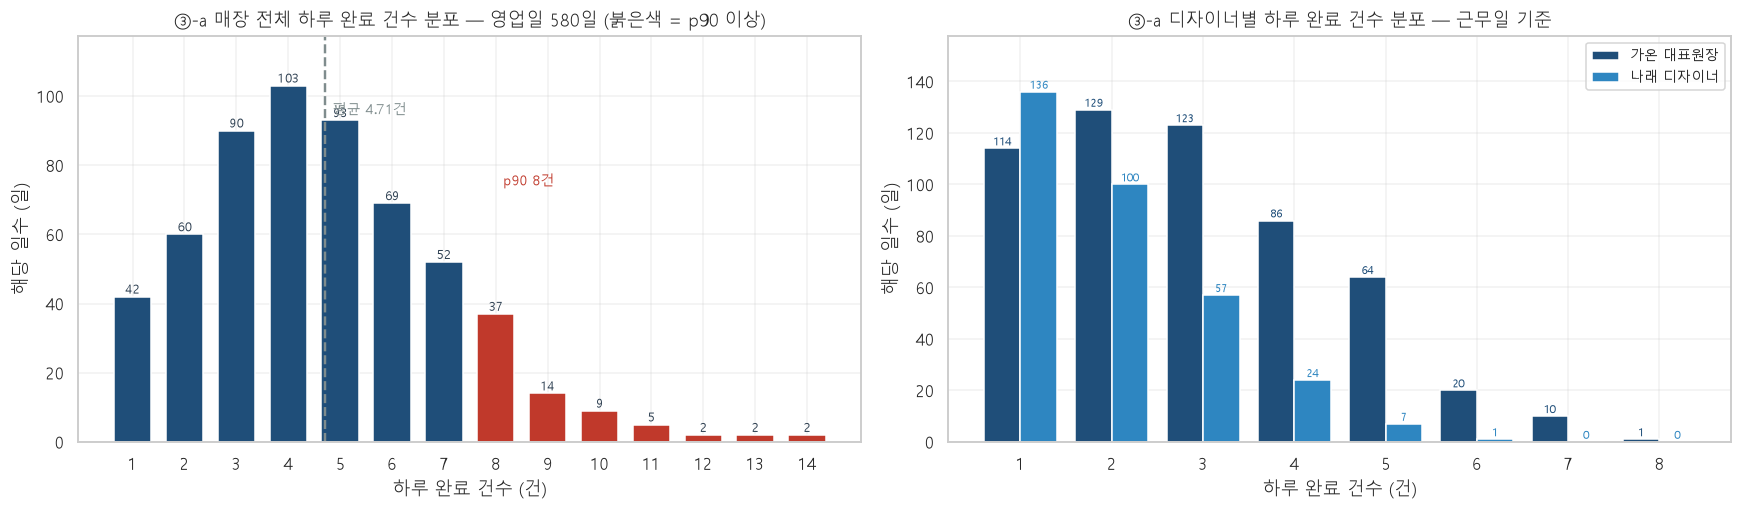

In [39]:
# ── ③-a 그래프: 하루 완료 건수 히스토그램 (막대) ───────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(16, 4.8))

ax = axes[0]
_vc = _store_day.value_counts().sort_index()
_p90 = _store_day.quantile(0.9)
_cols = [C_ACC if k >= _p90 else C_MAIN for k in _vc.index]
ax.bar(_vc.index, _vc.values, color=_cols, width=0.72)
barlab(ax, _vc.index, _vc.values, "{:,.0f}", dy=2, fs=8)
ax.axvline(_store_day.mean(), color=C_DARKG, ls="--", lw=1.6)
ax.annotate(f"평균 {_store_day.mean():.2f}건", (_store_day.mean(), _vc.max()*0.92),
            fontsize=9, color=C_DARKG, textcoords="offset points", xytext=(5, 0))
ax.annotate(f"p90 {_p90:.0f}건", (_p90, _vc.max()*0.72), fontsize=9, color=C_ACC,
            textcoords="offset points", xytext=(5, 0))
ax.set_xticks(_vc.index)
ax.set_xlabel("하루 완료 건수 (건)"); ax.set_ylabel("해당 일수 (일)")
ax.set_ylim(0, _vc.max()*1.14)
ax.set_title(f"③-a 매장 전체 하루 완료 건수 분포 — 영업일 {len(_store_day)}일 (붉은색 = p90 이상)")

ax = axes[1]
_w = 0.4
_j = _dz_day.loc["가온 대표원장"].value_counts().sort_index()
_h = _dz_day.loc["나래 디자이너"].value_counts().sort_index()
_ks = sorted(set(_j.index) | set(_h.index))
_jv = [_j.get(k, 0) for k in _ks]; _hv = [_h.get(k, 0) for k in _ks]
_x = np.arange(len(_ks))
ax.bar(_x - _w/2, _jv, _w, color=C_MAIN, label="가온 대표원장")
ax.bar(_x + _w/2, _hv, _w, color=C_SUB, label="나래 디자이너")
barlab(ax, _x - _w/2, _jv, "{:,.0f}", dy=2, fs=7.5, color=C_MAIN)
barlab(ax, _x + _w/2, _hv, "{:,.0f}", dy=2, fs=7.5, color=C_SUB)
ax.set_xticks(_x); ax.set_xticklabels(_ks)
ax.set_xlabel("하루 완료 건수 (건)"); ax.set_ylabel("해당 일수 (일)")
ax.set_ylim(0, max(max(_jv), max(_hv))*1.16)
ax.set_title("③-a 디자이너별 하루 완료 건수 분포 — 근무일 기준")
ax.legend(fontsize=9)
plt.tight_layout(); plt.show()

## ③-b 시간 기준으로 본 점유 — 건수와 왜 다른지

예약 시작 시각(`use_dt`)에 시술 소요시간을 더해 점유 시간을 만든다. **두 가정으로 각각 계산한다.**

| 시술 | 가정 A (01번) | 가정 B (사장님 인터뷰) |
|---|---|---|
| 뿌리탈색 계열 (메뉴명에 `뿌리` 또는 그 영어·중국어·일본어 자동번역 표기가 든 것) | 3.5h | **4.5h** |
| 그 외 탈색 (무한·전체·블랙빼기·수험생 등) | 3.5h | **8.0h** |
| 펌 | 2.5h | 2.5h |
| 염색 | 70분 | 70분 |
| 컷 | 40분 | 40분 |
| 클리닉·스타일링·기타 | 0h → 최소 0.5h | 0h → 최소 0.5h |

**한 예약에 여러 시술이 있으면 라인 소요시간을 합산한다**(01번 ⑪ 라인 기준과 동일).

### 건수 기준 가동률을 어떻게 정의하나

시간 기준 가동률은 `하루 점유시간 ÷ 10시간`이다. 건수 기준은 분모가 필요하다.
**실증적 상한(그 디자이너가 실제 달성한 p90 건수)** 을 분모로 쓴다.
"이 사람이 반복적으로 해낸 수준 대비 지금 얼마나 채우고 있나"가 된다.

In [40]:
# ── ③-b1 디자이너별 하루 점유 시간과 점유율 ────────────────────────────────
_day = DONE.groupby(["designer", "date"]).agg(n=("예약번호", "size"),
                                              hA=("durA", "sum"), hB=("durB", "sum"))
_rows = []
for d in REAL_DESIGNERS + UNASSIGNED:
    if d not in _day.index.get_level_values(0):
        continue
    g = _day.loc[d]
    _rows.append({
        "디자이너": d, "근무일": len(g), "완료건": int(g.n.sum()),
        "하루평균 건수": g.n.mean(),
        "하루평균 점유h [A]": g.hA.mean(), "점유율 [A](%)": g.hA.mean() / BIZ_HOURS * 100,
        "하루평균 점유h [B]": g.hB.mean(), "점유율 [B](%)": g.hB.mean() / BIZ_HOURS * 100,
        "10h 초과일 [A]": int((g.hA > BIZ_HOURS).sum()), "10h 초과일 비율[A](%)": (g.hA > BIZ_HOURS).mean()*100,
        "10h 초과일 [B]": int((g.hB > BIZ_HOURS).sum()), "10h 초과일 비율[B](%)": (g.hB > BIZ_HOURS).mean()*100,
    })
CAP_TIME = pd.DataFrame(_rows).set_index("디자이너")
CAP_TIME["소표본"] = CAP_TIME.완료건.map(lambda n: small(n))
tbl(CAP_TIME.round(2), "③-b1 디자이너별 하루 점유 시간과 점유율 (영업 10시간 대비)")

print("⚠️ 점유율이 100%를 넘는 것 자체는 오류가 아니다.")
print("   탈색은 약을 올리고 기다리는 방치 시간이 있어 다른 손님을 병행할 수 있다.")
print("   즉 '총 시술시간 합 ÷ 영업시간' 은 병행을 하나도 인정하지 않은 값이라 상한이다.")
print(f"   가정 B에서 가온의 10시간 초과일은 {int(CAP_TIME.loc['가온 대표원장','10h 초과일 [B]'])}일 / "
      f"{int(CAP_TIME.loc['가온 대표원장','근무일'])}일 = "
      f"{CAP_TIME.loc['가온 대표원장','10h 초과일 비율[B](%)']:.1f}% 다.")
print("   물리적으로 불가능한 날이 절반을 넘는다면, 그건 포화의 증거가 아니라 **가정이 과대**하다는 증거다.")

**③-b1 디자이너별 하루 점유 시간과 점유율 (영업 10시간 대비)**

,근무일,완료건,하루평균 건수,하루평균 점유h [A],점유율 [A](%),하루평균 점유h [B],점유율 [B](%),10h 초과일 [A],10h 초과일 비율[A](%),10h 초과일 [B],10h 초과일 비율[B](%),소표본
디자이너,,,,,,,,,,,,
가온 대표원장,547,1603,2.93,6.99,69.91,11.13,111.31,121,22.12,254,46.44,
나래 디자이너,325,644,1.98,6.31,63.13,10.71,107.06,69,21.23,131,40.31,
다솜 디자이너,84,113,1.35,4.57,45.67,7.75,77.46,2,2.38,13,15.48,
라온 디자이너,69,86,1.25,2.69,26.88,4.58,45.80,1,1.45,4,5.80,
마루 디자이너,27,31,1.15,4.17,41.67,7.69,76.85,2,7.41,4,14.81,
첫방문 50%할인 헤어살롱 본점 (구)헤어공방 미지정전용예약,170,218,1.28,3.18,31.78,5.15,51.55,2,1.18,14,8.24,
헤어살롱 본점 (구)헤어공방 미지정전용예약,30,37,1.23,2.53,25.33,3.75,37.50,0,0.00,1,3.33,


⚠️ 점유율이 100%를 넘는 것 자체는 오류가 아니다.
   탈색은 약을 올리고 기다리는 방치 시간이 있어 다른 손님을 병행할 수 있다.
   즉 '총 시술시간 합 ÷ 영업시간' 은 병행을 하나도 인정하지 않은 값이라 상한이다.
   가정 B에서 가온의 10시간 초과일은 254일 / 547일 = 46.4% 다.
   물리적으로 불가능한 날이 절반을 넘는다면, 그건 포화의 증거가 아니라 **가정이 과대**하다는 증거다.


In [41]:
# ── ③-b2 건수 기준 가동률 vs 시간 기준 가동률 — 나란히 ─────────────────────
_rows = []
for d in REAL_DESIGNERS:
    if d not in _dz_day.index.get_level_values(0):
        continue
    s = _dz_day.loc[d]
    g = _day.loc[d]
    p90 = s.quantile(0.90)
    _rows.append({
        "디자이너": d, "근무일": len(s), "완료건": int(s.sum()),
        "하루평균 건수": s.mean(), "실증 상한 p90(건)": p90, "실증 최대(건)": int(s.max()),
        "건수기준 가동률 vs p90(%)": s.mean() / p90 * 100,
        "건수기준 가동률 vs 최대(%)": s.mean() / s.max() * 100,
        "시간기준 가동률 [A](%)": g.hA.mean() / BIZ_HOURS * 100,
        "시간기준 가동률 [B](%)": g.hB.mean() / BIZ_HOURS * 100,
        "예약당 평균 소요h [A]": g.hA.sum() / s.sum(),
        "예약당 평균 소요h [B]": g.hB.sum() / s.sum(),
    })
CAP_CMP = pd.DataFrame(_rows).set_index("디자이너")
CAP_CMP["소표본"] = CAP_CMP.완료건.map(lambda n: small(n))
tbl(CAP_CMP.round(2), "③-b2 ★ 건수 기준 가동률 vs 시간 기준 가동률 — 왜 다른가 (전 기간 20개월)")

# ⚠️ 01·02번의 78.33%/127.69% 는 2026년만 본 값이다. 기간이 달라 숫자가 다르다.
_y26 = DONE[DONE.use_dt.dt.year == 2026]
_d26 = _y26.groupby(["designer", "date"]).agg(n=("예약번호", "size"), hA=("durA", "sum"), hB=("durB", "sum"))
_cmp26 = pd.DataFrame([
    {"디자이너": d, "2026 근무일": len(_d26.loc[d]), "2026 완료건": int(_d26.loc[d].n.sum()),
     "2026 시간기준 [A](%)": _d26.loc[d].hA.mean() / BIZ_HOURS * 100,
     "2026 시간기준 [B](%)": _d26.loc[d].hB.mean() / BIZ_HOURS * 100,
     "전기간 시간기준 [A](%)": CAP_CMP.loc[d, "시간기준 가동률 [A](%)"],
     "01·02번 기재값 [A](%)": {"가온 대표원장": 78.33, "나래 디자이너": 69.81,
                                "다솜 디자이너": 45.86}.get(d, np.nan)}
    for d in REAL_DESIGNERS if d in _d26.index.get_level_values(0)]).set_index("디자이너")
tbl(_cmp26.round(2), "③-b2b ⚠️ 기간 차이 확인 — 01·02번의 78.33%는 2026년만 본 값이다")
print("⚠️ 위 표의 '2026 시간기준 [A]'는 §0-5 게이트에서 01·02번과 일치를 확인한 값과 같은 정의다.")
print("   다만 ③-b2 본표는 **전 기간 20개월**을 쓴다. 2026년이 2025년보다 바쁘기 때문에")
print("   전기간 값이 2026 값보다 낮게 나온다. 두 값 모두 맞고, 기간이 다를 뿐이다.")
print("   ③의 캐파 판정은 전 기간 기준이다 — 표본이 크고 계절 효과가 평준화되기 때문이다.")
print()
print("   (최소 소요시간 0.5h 바닥 처리 때문에 게이트 값과 소수점 아래가 미세하게 다를 수 있다.")
print("    게이트는 01번 원본 정의 그대로 0h 를 0h 로 두고 계산한 값이다.)")

print("두 지표가 갈리는 이유는 산수로 완전히 설명된다:")
for d in ["가온 대표원장", "나래 디자이너"]:
    r = CAP_CMP.loc[d]
    print(f"\n  {d}")
    print(f"    하루 {r['하루평균 건수']:.2f}건 x 예약당 {r['예약당 평균 소요h [A]']:.2f}h "
          f"= {r['하루평균 건수']*r['예약당 평균 소요h [A]']:.2f}h / 10h = {r['시간기준 가동률 [A](%)']:.1f}%  [가정 A]")
    print(f"    하루 {r['하루평균 건수']:.2f}건 x 예약당 {r['예약당 평균 소요h [B]']:.2f}h "
          f"= {r['하루평균 건수']*r['예약당 평균 소요h [B]']:.2f}h / 10h = {r['시간기준 가동률 [B](%)']:.1f}%  [가정 B]")
    print(f"    건수로는 실증 상한(p90 {r['실증 상한 p90(건)']:.0f}건)의 {r['건수기준 가동률 vs p90(%)']:.1f}% 만 채우고 있다.")
print()
print("→ '하루 2~3건인데 78%'는 모순이 아니다. 예약 1건이 길기 때문이다.")
print("  진짜 쟁점은 다른 데 있다: **그 긴 시간 동안 디자이너가 정말 그 손님에게만 붙어 있는가.**")
print("  붙어 있지 않다면(=병행한다면) 시간 점유율은 캐파의 척도가 아니다. ③-c에서 검정한다.")

**③-b2 ★ 건수 기준 가동률 vs 시간 기준 가동률 — 왜 다른가 (전 기간 20개월)**

,근무일,완료건,하루평균 건수,실증 상한 p90(건),실증 최대(건),건수기준 가동률 vs p90(%),건수기준 가동률 vs 최대(%),시간기준 가동률 [A](%),시간기준 가동률 [B](%),예약당 평균 소요h [A],예약당 평균 소요h [B],소표본
디자이너,,,,,,,,,,,,
가온 대표원장,547,1603,2.93,5.0,8,58.61,36.63,69.91,111.31,2.39,3.80,
나래 디자이너,325,644,1.98,3.0,6,66.05,33.03,63.13,107.06,3.19,5.40,
다솜 디자이너,84,113,1.35,2.0,4,67.26,33.63,45.67,77.46,3.40,5.76,
라온 디자이너,69,86,1.25,2.0,4,62.32,31.16,26.88,45.80,2.16,3.67,
마루 디자이너,27,31,1.15,1.4,3,82.01,38.27,41.67,76.85,3.63,6.69,


**③-b2b ⚠️ 기간 차이 확인 — 01·02번의 78.33%는 2026년만 본 값이다**

,2026 근무일,2026 완료건,2026 시간기준 [A](%),2026 시간기준 [B](%),전기간 시간기준 [A](%),01·02번 기재값 [A](%)
디자이너,,,,,,
가온 대표원장,219,662,78.74,128.10,69.91,78.33
나래 디자이너,140,306,69.92,117.13,63.13,69.81
다솜 디자이너,83,112,45.92,78.09,45.67,45.86
라온 디자이너,11,12,22.42,42.88,26.88,
마루 디자이너,27,31,41.67,76.85,41.67,


⚠️ 위 표의 '2026 시간기준 [A]'는 §0-5 게이트에서 01·02번과 일치를 확인한 값과 같은 정의다.
   다만 ③-b2 본표는 **전 기간 20개월**을 쓴다. 2026년이 2025년보다 바쁘기 때문에
   전기간 값이 2026 값보다 낮게 나온다. 두 값 모두 맞고, 기간이 다를 뿐이다.
   ③의 캐파 판정은 전 기간 기준이다 — 표본이 크고 계절 효과가 평준화되기 때문이다.

   (최소 소요시간 0.5h 바닥 처리 때문에 게이트 값과 소수점 아래가 미세하게 다를 수 있다.
    게이트는 01번 원본 정의 그대로 0h 를 0h 로 두고 계산한 값이다.)
두 지표가 갈리는 이유는 산수로 완전히 설명된다:

  가온 대표원장
    하루 2.93건 x 예약당 2.39h = 6.99h / 10h = 69.9%  [가정 A]
    하루 2.93건 x 예약당 3.80h = 11.13h / 10h = 111.3%  [가정 B]
    건수로는 실증 상한(p90 5건)의 58.6% 만 채우고 있다.

  나래 디자이너
    하루 1.98건 x 예약당 3.19h = 6.31h / 10h = 63.1%  [가정 A]
    하루 1.98건 x 예약당 5.40h = 10.71h / 10h = 107.1%  [가정 B]
    건수로는 실증 상한(p90 3건)의 66.1% 만 채우고 있다.

→ '하루 2~3건인데 78%'는 모순이 아니다. 예약 1건이 길기 때문이다.
  진짜 쟁점은 다른 데 있다: **그 긴 시간 동안 디자이너가 정말 그 손님에게만 붙어 있는가.**
  붙어 있지 않다면(=병행한다면) 시간 점유율은 캐파의 척도가 아니다. ③-c에서 검정한다.


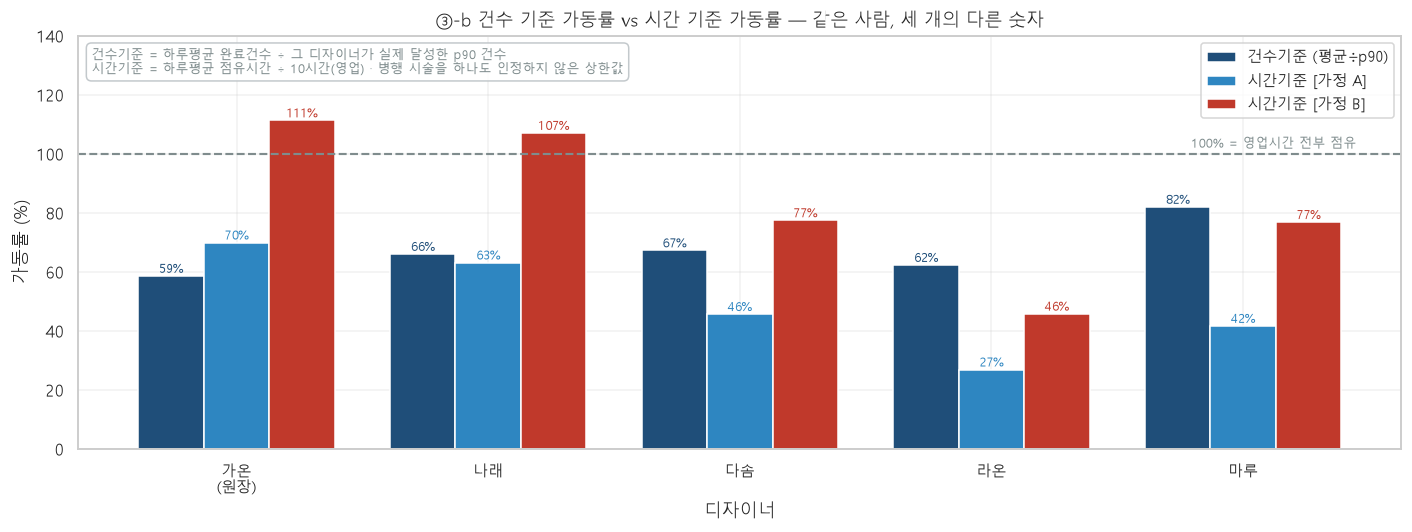

In [42]:
# ── ③-b 그래프: 건수기준 vs 시간기준 가동률 grouped bar ────────────────────
fig, ax = plt.subplots(figsize=(13, 5))
_c = CAP_CMP.loc[[d for d in REAL_DESIGNERS if d in CAP_CMP.index]]
_x = np.arange(len(_c)); _w = 0.26
_series = [("건수기준 (평균÷p90)", _c["건수기준 가동률 vs p90(%)"], C_MAIN),
           ("시간기준 [가정 A]",   _c["시간기준 가동률 [A](%)"],   C_SUB),
           ("시간기준 [가정 B]",   _c["시간기준 가동률 [B](%)"],   C_ACC)]
for i, (lab, vals, col) in enumerate(_series):
    off = (i - 1) * _w
    ax.bar(_x + off, vals, _w, color=col, label=lab)
    barlab(ax, _x + off, vals.values, "{:.0f}%", dy=2, fs=8, color=col)
ax.axhline(100, color=C_DARKG, ls="--", lw=1.4)
ax.annotate("100% = 영업시간 전부 점유", (len(_c)-0.55, 100), fontsize=8.5, color=C_DARKG,
            ha="right", textcoords="offset points", xytext=(0, 4))
ax.set_xticks(_x)
ax.set_xticklabels([d.replace(" 디자이너", "").replace(" 대표원장", "\n(원장)") for d in _c.index], fontsize=9.5)
ax.set_ylabel("가동률 (%)"); ax.set_xlabel("디자이너")
ax.set_ylim(0, max(140, float(_c["시간기준 가동률 [B](%)"].max()) * 1.18))
ax.set_title("③-b 건수 기준 가동률 vs 시간 기준 가동률 — 같은 사람, 세 개의 다른 숫자")
ax.legend(fontsize=9.5)
_note = ("건수기준 = 하루평균 완료건수 ÷ 그 디자이너가 실제 달성한 p90 건수\n"
         "시간기준 = 하루평균 점유시간 ÷ 10시간(영업) · 병행 시술을 하나도 인정하지 않은 상한값")
ax.annotate(_note, (0.01, 0.97), xycoords="axes fraction", fontsize=8.5,
            va="top", color=C_DARKG,
            bbox=dict(boxstyle="round,pad=0.4", fc="white", ec=C_GRAY, alpha=0.9))
plt.tight_layout(); plt.show()

## ③-c 동시 점유 — 진짜 병목 찾기

15분 단위로 하루를 쪼개서, 각 시점에 몇 명이 동시에 시술 중인지 센다.

* 디자이너별 최대 동시 건수 — **1을 넘으면 병행 시술을 하고 있다는 뜻**
* 매장 전체 최대 동시 건수와 그 시각
* 동시 3명 이상인 시간대가 얼마나 자주 발생하는지

**탈색은 방치 시간이 있어 병행이 가능하다.** 실제로 병행하고 있다면 데이터에 겹치는 예약으로 나타난다.
병행 사례가 많다면 **캐파는 시간 점유율보다 훨씬 크다.**

### ⚠️ 순환논증을 피하기 위한 장치

동시 점유는 **가정한 소요시간에서 파생된 값**이다. "3.5시간이라고 가정했으니 겹친다"가 될 수 있다.
그래서 아래에 **가정과 무관한 증거**를 하나 더 낸다:

> **같은 디자이너·같은 날, 연속한 두 예약의 시작 시각 간격**

이건 `use_dt` 만으로 계산되며 어떤 소요시간 가정도 쓰지 않는다.
간격이 소요시간보다 훨씬 짧다면, 둘 중 하나다 — **(1) 병행하고 있다** 또는 **(2) 소요시간 가정이 과대하다.**
**어느 쪽이든 "시간 점유율 = 포화"라는 해석은 성립하지 않는다.**

In [43]:
# ── ③-c1 15분 단위 동시 점유 ───────────────────────────────────────────────
STEP_MIN = 15
GRID = np.arange(BIZ_OPEN * 60, BIZ_CLOSE * 60 + 1, STEP_MIN) / 60.0   # 10.00 ~ 20.00

def occupancy(sub, dur_col):
    """(그리드 시각별 동시 건수) 배열을 돌려준다."""
    s = sub.start_h.values
    e = s + sub[dur_col].values
    return ((GRID[:, None] >= s[None, :] - 1e-9) & (GRID[:, None] < e[None, :] - 1e-9)).sum(axis=1)

_rows = []
for asm, col in [("A", "durA"), ("B", "durB")]:
    for key, sub in DONE.groupby(["designer", "date"]):
        occ = occupancy(sub, col)
        _rows.append({"가정": asm, "designer": key[0], "date": key[1],
                      "max_conc": int(occ.max()), "n": len(sub)})
CONC_DZ = pd.DataFrame(_rows)

_t = (CONC_DZ.groupby(["가정", "designer"])
             .agg(근무일=("max_conc", "size"), 평균최대동시=("max_conc", "mean"),
                  최대동시=("max_conc", "max"),
                  동시2이상_일수=("max_conc", lambda s: int((s >= 2).sum())),
                  동시3이상_일수=("max_conc", lambda s: int((s >= 3).sum()))))
_t["동시2이상(%)"] = _t.동시2이상_일수 / _t.근무일 * 100
_t["동시3이상(%)"] = _t.동시3이상_일수 / _t.근무일 * 100
_t = _t.reset_index().set_index(["가정", "designer"])
_ord = [(a, d) for a in ["A", "B"] for d in REAL_DESIGNERS + UNASSIGNED if (a, d) in _t.index]
tbl(_t.loc[_ord].round(2), "③-c1 디자이너별 하루 최대 동시 건수 — 1을 넘으면 병행 시술")

print("★ 읽는 법: '평균 최대동시'가 2에 가깝다는 것은,")
print("  근무하는 날마다 평균적으로 2명을 동시에 잡고 있는 시점이 있었다는 뜻이다.")
print("  이는 디자이너가 한 손님에게 3.5시간 내내 붙어 있지 않다는 것을 의미한다.")

**③-c1 디자이너별 하루 최대 동시 건수 — 1을 넘으면 병행 시술**

근무일  평균최대동시  최대동시  동시2이상_일수  동시3이상_일수  동시2이상(%)  동시3이상(%)
가정 designer                                                                                    
A  가온 대표원장                            547    1.96     6       332       141     60.69     25.78
   나래 디자이너                            325    1.62     5       146        46     44.92     14.15
   다솜 디자이너                             84    1.21     4        15         2     17.86      2.38
   라온 디자이너                             69    1.10     4         4         2      5.80      2.90
   마루 디자이너                             27    1.07     2         2         0      7.41      0.00
   첫방문 50%할인 헤어살롱 본점 (구)헤어공방 미지정전용예약  170    1.14     4        20         2     11.76      1.18
   헤어살롱 본점 (구)헤어공방 미지정전용예약             30    1.07     2         2         0      6.67      0.00
B  가온 대표원장                            547    2.16     6       362       177     66.18     32.36
   나래 디자이너                            325    1.79     6       169        68     52.00     20.92
   다솜 디자이너                             84    1.26     4        19         2     22.62      2.38
   라온 디자이너                             69    1.14     4         7         2     10.14      2.90
   마루 디자이너                             27    1.11     3         2         1      7.41      3.70
   첫방문 50%할인 헤어살롱 본점 (구)헤어공방 미지정전용예약  170    1.17     4        26         2     15.29      1.18
   헤어살롱 본점 (구)헤어공방 미지정전용예약             30    1.07     2         2         0      6.67      0.00

★ 읽는 법: '평균 최대동시'가 2에 가깝다는 것은,
  근무하는 날마다 평균적으로 2명을 동시에 잡고 있는 시점이 있었다는 뜻이다.
  이는 디자이너가 한 손님에게 3.5시간 내내 붙어 있지 않다는 것을 의미한다.


In [44]:
# ── ③-c2 매장 전체 동시 점유 ───────────────────────────────────────────────
_rows = []
for asm, col in [("A", "durA"), ("B", "durB")]:
    for dt_, sub in DONE.groupby("date"):
        occ = occupancy(sub, col)
        _rows.append({"가정": asm, "date": dt_, "max_conc": int(occ.max()),
                      "peak_h": float(GRID[int(np.argmax(occ))]), "n": len(sub),
                      "h3": int((occ >= 3).sum()) * STEP_MIN / 60,
                      "h4": int((occ >= 4).sum()) * STEP_MIN / 60})
CONC_ST = pd.DataFrame(_rows)

_s = (CONC_ST.groupby("가정")
             .agg(영업일=("max_conc", "size"), 평균최대동시=("max_conc", "mean"),
                  중앙최대동시=("max_conc", "median"), 최대동시=("max_conc", "max"),
                  동시3이상_일수=("max_conc", lambda s: int((s >= 3).sum())),
                  동시4이상_일수=("max_conc", lambda s: int((s >= 4).sum())),
                  동시5이상_일수=("max_conc", lambda s: int((s >= 5).sum())),
                  하루평균_동시3이상_시간=("h3", "mean"),
                  하루평균_동시4이상_시간=("h4", "mean")))
_s["동시3이상(%)"] = _s.동시3이상_일수 / _s.영업일 * 100
_s["동시4이상(%)"] = _s.동시4이상_일수 / _s.영업일 * 100
_s["동시5이상(%)"] = _s.동시5이상_일수 / _s.영업일 * 100
tbl(_s.round(2), "③-c2 매장 전체 하루 최대 동시 건수")

for asm in ["A", "B"]:
    sub = CONC_ST[CONC_ST.가정 == asm]
    _pk = sub.peak_h.round(0).astype(int).value_counts().sort_index()
    _top = sub.loc[sub.max_conc.idxmax()]
    print(f"[가정 {asm}] 최대 동시 {int(sub.max_conc.max())}명 — "
          f"{pd.Timestamp(_top.date):%Y-%m-%d} {int(_top.peak_h)}시경 (그날 완료 {int(_top.n)}건)")
    print(f"          피크 발생 시각 분포: " +
          " / ".join(f"{h}시 {v}일" for h, v in _pk.items()))
print()
print("→ 이 살롱은 이미 동시에 3명 이상을 다루는 날이 절반을 넘는다.")
print("  '한 사람이 한 손님을 붙잡고 있어 자리가 없다'는 그림과 맞지 않는다.")

**③-c2 매장 전체 하루 최대 동시 건수**

,영업일,평균최대동시,중앙최대동시,최대동시,동시3이상_일수,동시4이상_일수,동시5이상_일수,하루평균_동시3이상_시간,하루평균_동시4이상_시간,동시3이상(%),동시4이상(%),동시5이상(%)
가정,,,,,,,,,,,,
A,580,2.97,3.0,10,321,185,92,1.50,0.65,55.34,31.90,15.86
B,580,3.40,3.0,12,375,241,141,2.75,1.50,64.66,41.55,24.31


[가정 A] 최대 동시 10명 — 2026-02-12 14시경 (그날 완료 12건)
          피크 발생 시각 분포: 10시 30일 / 11시 34일 / 12시 141일 / 13시 71일 / 14시 142일 / 15시 48일 / 16시 58일 / 17시 16일 / 18시 31일 / 19시 8일 / 20시 1일
[가정 B] 최대 동시 12명 — 2026-02-12 14시경 (그날 완료 12건)
          피크 발생 시각 분포: 10시 20일 / 11시 23일 / 12시 97일 / 13시 48일 / 14시 126일 / 15시 71일 / 16시 85일 / 17시 25일 / 18시 66일 / 19시 17일 / 20시 2일

→ 이 살롱은 이미 동시에 3명 이상을 다루는 날이 절반을 넘는다.
  '한 사람이 한 손님을 붙잡고 있어 자리가 없다'는 그림과 맞지 않는다.


In [45]:
# ── ③-c3 ★ 가정 무관 증거 — 연속 예약 시작 간격 ───────────────────────────
_g = DONE.sort_values(["designer", "date", "use_dt"]).copy()
_g["prev_use"] = _g.groupby(["designer", "date"]).use_dt.shift(1)
_g["gap_h"] = (_g.use_dt - _g.prev_use).dt.total_seconds() / 3600
GAPS = _g.dropna(subset=["gap_h"])

print(f"같은 디자이너·같은 날 연속 예약 쌍: {len(GAPS):,}쌍")
print("이 지표는 use_dt 만 쓴다 — 어떤 소요시간 가정도 개입하지 않는다.")
print()
_bins = [0, 0.51, 1.01, 1.51, 2.01, 3.01, 3.51, 100]
_labs = ["30분", "31~60분", "61~90분", "91~120분", "2~3시간", "3~3.5시간", "3.5시간 초과"]
_gb = pd.cut(GAPS.gap_h, bins=_bins, labels=_labs, right=False).value_counts().reindex(_labs)
_gt = _gb.rename("쌍 수").to_frame()
_gt["비중(%)"] = _gt["쌍 수"] / len(GAPS) * 100
_gt["누적(%)"] = _gt["비중(%)"].cumsum()
tbl(_gt.round(2), "③-c3a 연속 예약 시작 간격 분포 — 전체 디자이너")

_rows = []
for d in REAL_DESIGNERS:
    s = GAPS[GAPS.designer == d].gap_h
    if len(s) == 0:
        continue
    _rows.append({"디자이너": d, "연속쌍": len(s), "중앙 간격(h)": s.median(),
                  "1시간 이하(%)": (s <= 1.0).mean()*100,
                  "2시간 미만(%)": (s < 2.0).mean()*100,
                  "3.5시간 미만(%)": (s < 3.5).mean()*100,
                  "가정A 예약당 소요h": DONE[DONE.designer == d].durA.mean(),
                  "가정B 예약당 소요h": DONE[DONE.designer == d].durB.mean()})
GAP_TBL = pd.DataFrame(_rows).set_index("디자이너")
GAP_TBL["소표본"] = GAP_TBL.연속쌍.map(lambda n: small(n))
tbl(GAP_TBL.round(2), "③-c3b ★ 디자이너별 — 다음 손님을 얼마나 빨리 받는가 (가정 무관)")

_j = GAP_TBL.loc["가온 대표원장"]
print("★ 이 노트북에서 가장 중요한 표다. 해석:")
print(f"  가온는 앞 손님 시작 후 **중앙 {_j['중앙 간격(h)']:.2f}시간** 만에 다음 손님을 시작한다.")
print(f"  연속쌍의 {_j['1시간 이하(%)']:.1f}%가 1시간 이내, {_j['3.5시간 미만(%)']:.1f}%가 3.5시간 이내에 다음 예약이 시작된다.")
print(f"  그런데 가정 A는 예약 1건이 평균 {_j['가정A 예약당 소요h']:.2f}시간, 가정 B는 {_j['가정B 예약당 소요h']:.2f}시간 걸린다고 본다.")
print()
print("  두 가지 중 하나다:")
print("   (1) 실제로 병행 시술을 하고 있다 → 시간 점유율은 캐파의 척도가 아니다")
print("   (2) 소요시간 가정이 과대하다     → 78%/128%라는 가동률 숫자 자체가 과대하다")
print("  ⚠️ 데이터만으로는 (1)과 (2)를 구분할 수 없다. 그러나 **어느 쪽이든**")
print("     '시간 가동률이 높으니 포화'라는 결론은 지지되지 않는다.")
print()
print(f"  참고: 최소 간격은 {GAPS.gap_h.min():.2f}시간 = 예약 슬롯 단위가 30분이라는 뜻이고,")
print(f"        간격이 0인 쌍(완전 동시 시작)은 {int((GAPS.gap_h==0).sum())}쌍이다.")

같은 디자이너·같은 날 연속 예약 쌍: 1,480쌍
이 지표는 use_dt 만 쓴다 — 어떤 소요시간 가정도 개입하지 않는다.



**③-c3a 연속 예약 시작 간격 분포 — 전체 디자이너**

,쌍 수,비중(%),누적(%)
gap_h,,,
30분,413,27.91,27.91
31~60분,266,17.97,45.88
61~90분,189,12.77,58.65
91~120분,141,9.53,68.18
2~3시간,180,12.16,80.34
3~3.5시간,73,4.93,85.27
3.5시간 초과,218,14.73,100.00


**③-c3b ★ 디자이너별 — 다음 손님을 얼마나 빨리 받는가 (가정 무관)**

,연속쌍,중앙 간격(h),1시간 이하(%),2시간 미만(%),3.5시간 미만(%),가정A 예약당 소요h,가정B 예약당 소요h,소표본
디자이너,,,,,,,,
가온 대표원장,1056,1.50,48.01,60.61,82.77,2.39,3.80,
나래 디자이너,319,1.50,43.26,57.05,76.80,3.19,5.40,
다솜 디자이너,29,2.00,37.93,44.83,65.52,3.40,5.76,⚠소표본
라온 디자이너,17,2.50,29.41,35.29,58.82,2.16,3.67,⚠소표본
마루 디자이너,4,4.75,25.00,25.00,25.00,3.63,6.69,⚠소표본


★ 이 노트북에서 가장 중요한 표다. 해석:
  가온는 앞 손님 시작 후 **중앙 1.50시간** 만에 다음 손님을 시작한다.
  연속쌍의 48.0%가 1시간 이내, 82.8%가 3.5시간 이내에 다음 예약이 시작된다.
  그런데 가정 A는 예약 1건이 평균 2.39시간, 가정 B는 3.80시간 걸린다고 본다.

  두 가지 중 하나다:
   (1) 실제로 병행 시술을 하고 있다 → 시간 점유율은 캐파의 척도가 아니다
   (2) 소요시간 가정이 과대하다     → 78%/128%라는 가동률 숫자 자체가 과대하다
  ⚠️ 데이터만으로는 (1)과 (2)를 구분할 수 없다. 그러나 **어느 쪽이든**
     '시간 가동률이 높으니 포화'라는 결론은 지지되지 않는다.

  참고: 최소 간격은 0.50시간 = 예약 슬롯 단위가 30분이라는 뜻이고,
        간격이 0인 쌍(완전 동시 시작)은 0쌍이다.


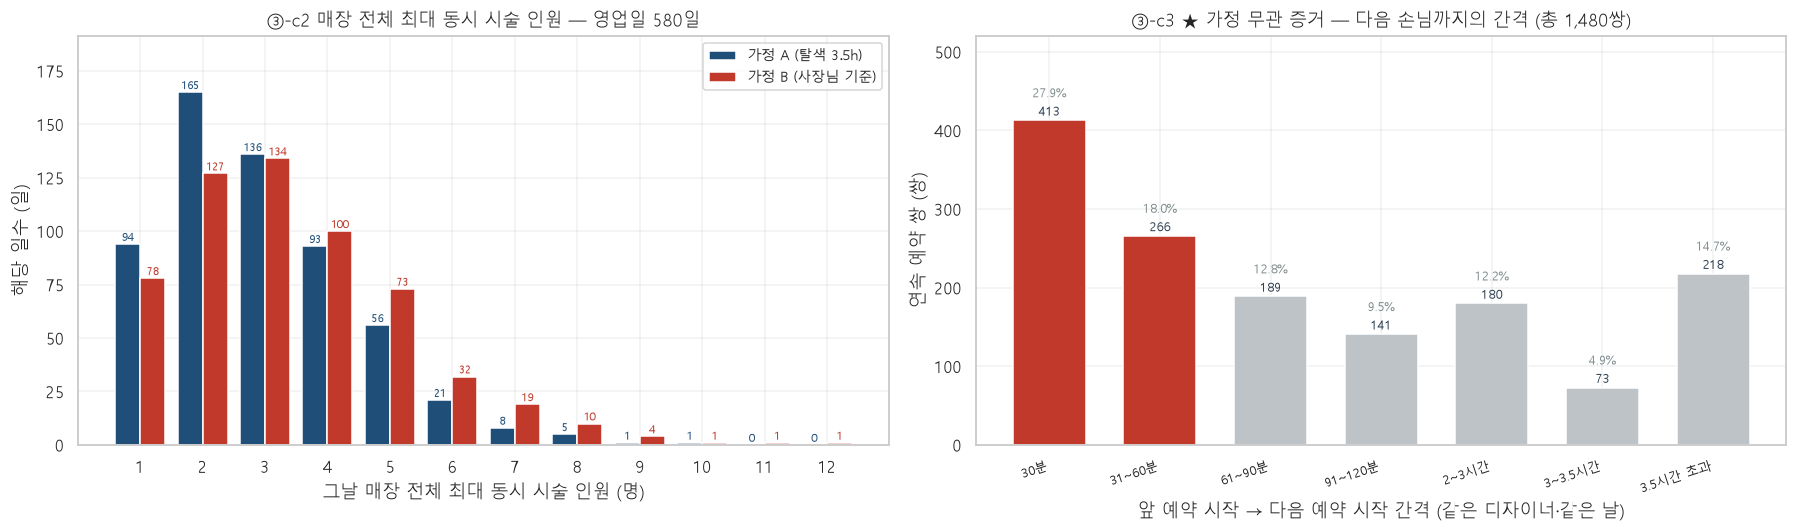

In [46]:
# ── ③-c 그래프: 동시 점유 + 시작 간격 ──────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(16.5, 5))

ax = axes[0]
_ca = CONC_ST[CONC_ST.가정 == "A"].max_conc.value_counts().sort_index()
_cb = CONC_ST[CONC_ST.가정 == "B"].max_conc.value_counts().sort_index()
_ks = sorted(set(_ca.index) | set(_cb.index))
_x = np.arange(len(_ks)); _w = 0.4
_av = [_ca.get(k, 0) for k in _ks]; _bv = [_cb.get(k, 0) for k in _ks]
ax.bar(_x - _w/2, _av, _w, color=C_MAIN, label="가정 A (탈색 3.5h)")
ax.bar(_x + _w/2, _bv, _w, color=C_ACC, label="가정 B (사장님 기준)")
barlab(ax, _x - _w/2, _av, "{:,.0f}", dy=2, fs=7.5, color=C_MAIN)
barlab(ax, _x + _w/2, _bv, "{:,.0f}", dy=2, fs=7.5, color=C_ACC)
ax.set_xticks(_x); ax.set_xticklabels(_ks)
ax.set_xlabel("그날 매장 전체 최대 동시 시술 인원 (명)"); ax.set_ylabel("해당 일수 (일)")
ax.set_ylim(0, max(max(_av), max(_bv))*1.16)
ax.set_title(f"③-c2 매장 전체 최대 동시 시술 인원 — 영업일 {len(BIZ_DATES)}일")
ax.legend(fontsize=9)

ax = axes[1]
_x = np.arange(len(_gt))
_hl = {"30분", "31~60분"}
ax.bar(_x, _gt["쌍 수"], color=[C_ACC if l in _hl else C_GRAY for l in _gt.index], width=0.66)
barlab(ax, _x, _gt["쌍 수"].values, "{:,.0f}", dy=3, fs=8.5)
for i, v in enumerate(_gt["비중(%)"]):
    ax.annotate(f"{v:.1f}%", (i, _gt['쌍 수'].iloc[i]), textcoords="offset points",
                xytext=(0, 15), ha="center", fontsize=8, color=C_DARKG)
ax.set_xticks(_x); ax.set_xticklabels(_gt.index, rotation=18, ha="right", fontsize=8.5)
ax.set_xlabel("앞 예약 시작 → 다음 예약 시작 간격 (같은 디자이너·같은 날)")
ax.set_ylabel("연속 예약 쌍 (쌍)")
ax.set_ylim(0, _gt["쌍 수"].max()*1.26)
ax.set_title(f"③-c3 ★ 가정 무관 증거 — 다음 손님까지의 간격 (총 {len(GAPS):,}쌍)")
plt.tight_layout(); plt.show()

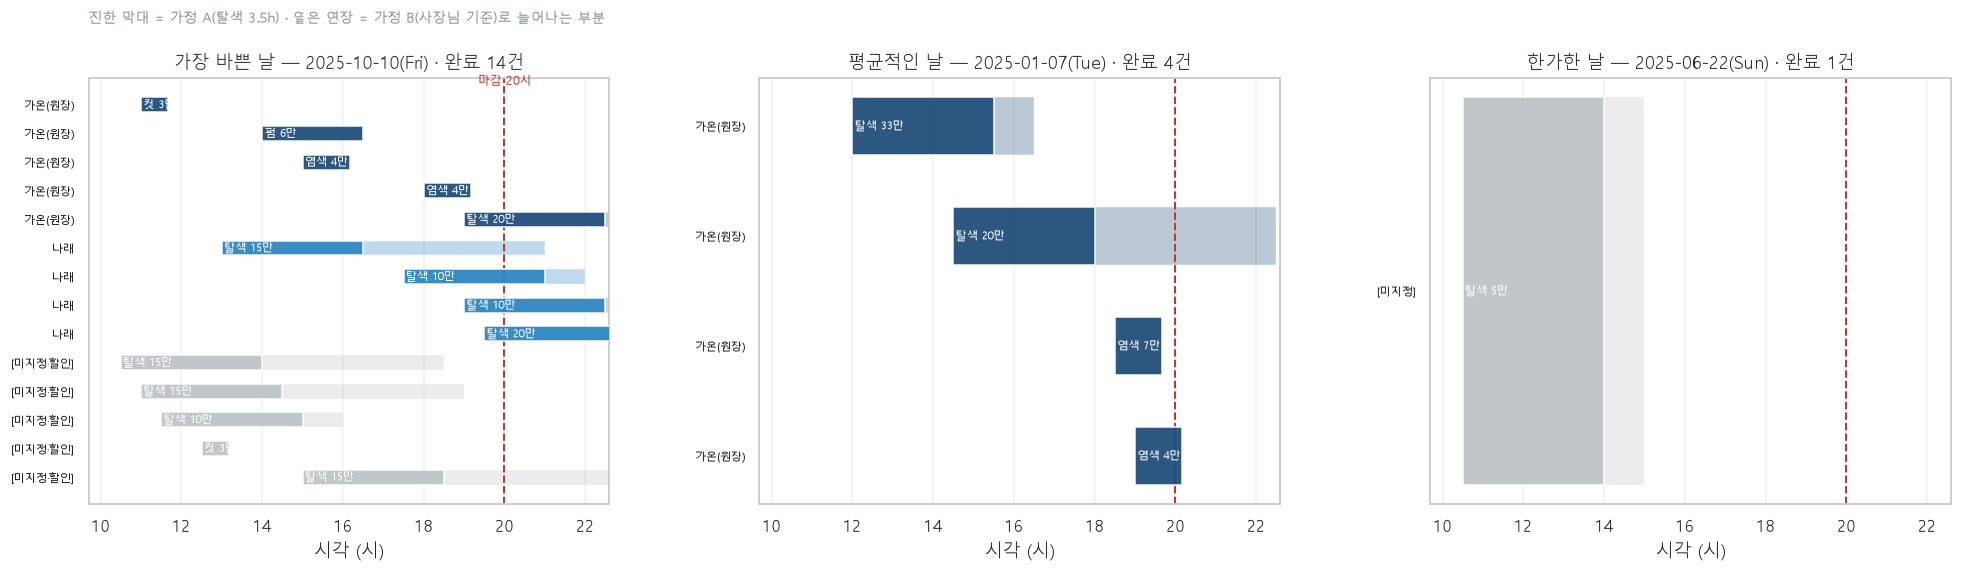

같은 이름이 여러 줄에 나오면 그 디자이너가 그날 여러 건을 받았다는 뜻이고,
막대가 가로로 겹치면 그 시간에 병행하고 있다는 뜻이다.


In [47]:
# ── ③-c 그래프 2: 대표적인 하루의 간트 타임라인 3개 ────────────────────────
_sd = DONE.groupby("date").size()
_busy_d  = _sd.idxmax()
_avg_d   = (_sd - _sd.median()).abs().idxmin()
_quiet_d = _sd[_sd == _sd.min()].index[len(_sd[_sd == _sd.min()]) // 2]
_days = [("가장 바쁜 날", _busy_d), ("평균적인 날", _avg_d), ("한가한 날", _quiet_d)]

fig, axes = plt.subplots(1, 3, figsize=(18, 5.4), sharey=False)
_dz_color = {d: c for d, c in zip(REAL_DESIGNERS, [C_MAIN, C_SUB, C_WARM, C_ACC, "#8e44ad"])}
for ax, (ttl, dt_) in zip(axes, _days):
    sub = DONE[DONE.date == dt_].sort_values(["designer", "use_dt"]).reset_index(drop=True)
    for i, r in sub.iterrows():
        col = _dz_color.get(r.designer, C_GRAY)
        ax.barh(i, r.durA, left=r.start_h, height=0.52, color=col, alpha=0.95,
                edgecolor="white", zorder=3)
        ax.barh(i, r.durB - r.durA, left=r.start_h + r.durA, height=0.52, color=col,
                alpha=0.30, edgecolor="white", zorder=2)
        ax.annotate(f"{r.rep_cat} {r.paid/10000:.0f}만", (r.start_h + 0.06, i),
                    va="center", fontsize=7.2, color="white", zorder=4)
    ax.set_yticks(range(len(sub)))
    ax.set_yticklabels([d.replace(" 디자이너", "").replace(" 대표원장", "(원장)")
                        .replace("첫방문 50%할인 헤어살롱 본점 (구)헤어공방 미지정전용예약", "[미지정·할인]")
                        .replace("헤어살롱 본점 (구)헤어공방 미지정전용예약", "[미지정]")
                        for d in sub.designer], fontsize=7.5)
    ax.invert_yaxis()
    ax.set_xlim(BIZ_OPEN - 0.3, BIZ_CLOSE + 2.6)
    ax.set_xticks(range(BIZ_OPEN, BIZ_CLOSE + 3, 2))
    ax.axvline(BIZ_CLOSE, color=C_ACC, ls="--", lw=1.3)
    ax.annotate("마감 20시", (BIZ_CLOSE, -0.7), color=C_ACC, fontsize=8, ha="center")
    ax.set_xlabel("시각 (시)")
    ax.set_title(f"{ttl} — {pd.Timestamp(dt_):%Y-%m-%d(%a)} · 완료 {len(sub)}건")
    ax.grid(axis="x", alpha=0.3); ax.grid(axis="y", alpha=0)
axes[0].annotate("진한 막대 = 가정 A(탈색 3.5h) · 옅은 연장 = 가정 B(사장님 기준)로 늘어나는 부분",
                 (0.0, 1.13), xycoords="axes fraction", fontsize=9, color=C_DARKG)
plt.tight_layout(); plt.show()
print("같은 이름이 여러 줄에 나오면 그 디자이너가 그날 여러 건을 받았다는 뜻이고,")
print("막대가 가로로 겹치면 그 시간에 병행하고 있다는 뜻이다.")

## ③-d 빈 슬롯의 실체

**"실제로 팔 수 있는데 안 팔린 시간"이 얼마인가.**

슬롯 = (디자이너 × 날짜 × 1시간), 영업 10~19시 시작 기준 → 하루 10슬롯.
대상은 실제 디자이너 5명 × 영업일. 각 슬롯을 다음 다섯 가지로 판정한다.

| 판정 | 조건 |
|---|---|
| **① 예약 있음** | 그 시각에 시작하는 예약이 1건 이상 |
| **② 디자이너 미근무(추정)** | 그날 그 디자이너에게 완료 건이 0건 |
| **③ 마감 전 소요시간 부족** | 근무일이지만 `시작시각 + 그 디자이너 중앙 소요시간 > 20시` |
| **④ 다른 시술 진행 중 (병행 여지)** | 시작 가능하지만 그 시점에 이미 다른 손님을 잡고 있음 |
| **⑤ 완전 공백** | 근무일 · 마감 여유 있음 · 그 시점에 아무 시술도 없음 |

**⑤가 "실제로 팔 수 있는데 안 팔린 시간"이다.** ④는 병행을 인정하느냐에 따라 갈린다.

### 추가 가능 건수 추정 — 두 가지 경계

한 시술은 여러 슬롯을 차지하므로 "빈 슬롯 수 = 팔 수 있는 예약 수"가 아니다. 그래서 두 경계를 낸다.

* **하한 (병행 불허)**: 완전히 빈 연속 구간을 찾아 `구간 길이 ÷ 중앙 소요시간`으로 몇 건이 들어가는지 계산
* **상한 (실증 기준)**: `(그 디자이너의 p90 일 건수 − 그날 실제 건수)` 를 근무일에 대해 합산

두 값이 실제 여유를 위아래로 감싼다. **둘 다 추정치이며 가정에 의존한다.**

**③-d1a 요일 x 시작 시각 완료 건수 (20개월 누적)**

hour,10,11,12,13,14,15,16,17,18,19,20
dow_ko,,,,,,,,,,,
월,35,61,62,55,50,42,26,38,29,18,0
화,33,55,45,37,39,32,16,25,24,14,0
수,32,53,40,40,43,47,28,29,24,13,1
목,44,58,53,49,68,35,30,29,27,11,1
금,57,84,85,70,45,55,31,39,46,20,0
토,46,63,61,51,46,39,30,21,20,5,1
일,48,47,42,35,34,45,30,17,23,5,0


**③-d1b 요일 x 시작 시각 — 영업일 1회당 평균 완료 건수 (정규화)**

hour,10,11,12,13,14,15,16,17,18,19,20
dow_ko,,,,,,,,,,,
월,0.427,0.744,0.756,0.671,0.610,0.512,0.317,0.463,0.354,0.220,0.000
화,0.402,0.671,0.549,0.451,0.476,0.390,0.195,0.305,0.293,0.171,0.000
수,0.386,0.639,0.482,0.482,0.518,0.566,0.337,0.349,0.289,0.157,0.012
목,0.530,0.699,0.639,0.590,0.819,0.422,0.361,0.349,0.325,0.133,0.012
금,0.679,1.000,1.012,0.833,0.536,0.655,0.369,0.464,0.548,0.238,0.000
토,0.541,0.741,0.718,0.600,0.541,0.459,0.353,0.247,0.235,0.059,0.012
일,0.593,0.580,0.519,0.432,0.420,0.556,0.370,0.210,0.284,0.062,0.000


요일별 영업일 수: {'월': 82, '화': 82, '수': 83, '목': 83, '금': 84, '토': 85, '일': 81}


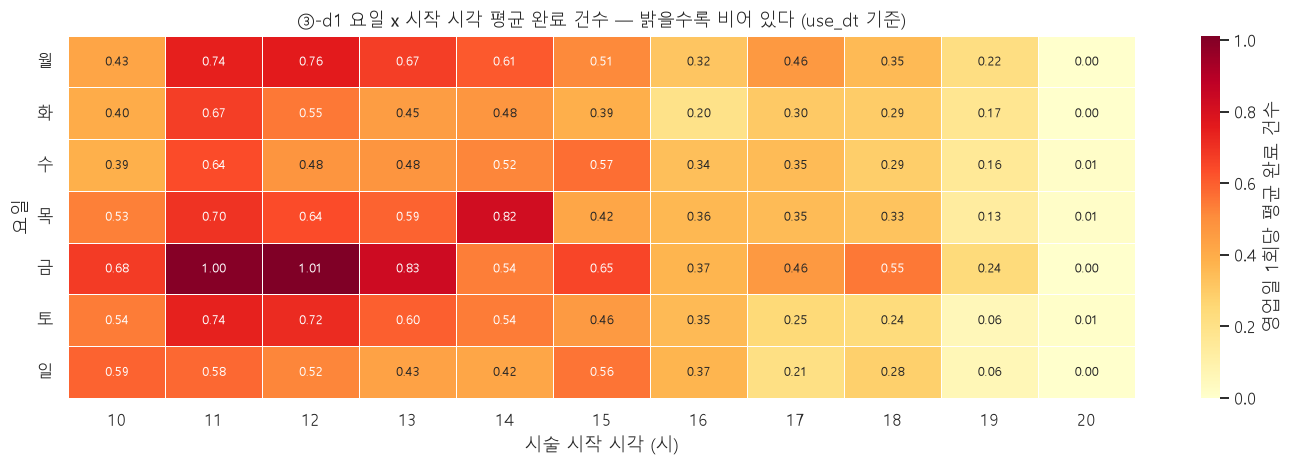

In [48]:
# ── ③-d1 요일 x 시각 평균 완료 건수 히트맵 ─────────────────────────────────
_hm_cnt = (DONE.pivot_table(index="dow_ko", columns="hour", values="예약번호",
                            aggfunc="size", fill_value=0)
                .reindex(index=DOW_KO, columns=range(BIZ_OPEN, BIZ_CLOSE + 1), fill_value=0))
_biz_dow = pd.Series(BIZ_DATES).dt.dayofweek.value_counts().sort_index()
_biz_dow.index = [DOW_KO[i] for i in _biz_dow.index]
_hm_avg = _hm_cnt.div(_biz_dow.reindex(DOW_KO), axis=0)
tbl(_hm_cnt, "③-d1a 요일 x 시작 시각 완료 건수 (20개월 누적)")
tbl(_hm_avg.round(3), "③-d1b 요일 x 시작 시각 — 영업일 1회당 평균 완료 건수 (정규화)")
print(f"요일별 영업일 수: {_biz_dow.reindex(DOW_KO).to_dict()}")

fig, ax = plt.subplots(figsize=(13, 4.4))
sns.heatmap(_hm_avg, annot=True, fmt=".2f", cmap="YlOrRd", ax=ax,
            linewidths=.6, linecolor="white", cbar_kws={"label": "영업일 1회당 평균 완료 건수"},
            annot_kws={"fontsize": 8.5})
ax.set_title("③-d1 요일 x 시작 시각 평균 완료 건수 — 밝을수록 비어 있다 (use_dt 기준)")
ax.set_xlabel("시술 시작 시각 (시)"); ax.set_ylabel("요일")
ax.set_yticklabels(ax.get_yticklabels(), rotation=0)
plt.tight_layout(); plt.show()

In [49]:
# ── ③-d2 슬롯 판정 ─────────────────────────────────────────────────────────
_work_set = set(zip(DONE.designer, DONE.date))
_start_cnt = DONE.groupby(["designer", "date", DONE.use_dt.dt.hour]).size().to_dict()
_occ_by_key = {k: (g.start_h.values, g.start_h.values + g.durA.values,
                   g.start_h.values + g.durB.values)
               for k, g in DONE.groupby(["designer", "date"])}
_med_dur = {d: {"A": float(DONE[DONE.designer == d].durA.median()),
                "B": float(DONE[DONE.designer == d].durB.median())} for d in REAL_DESIGNERS}

SLOT_CATS = ["① 예약 있음", "② 디자이너 미근무(추정)", "③ 마감 전 소요시간 부족",
             "④ 다른 시술 진행 중(병행 여지)", "⑤ 완전 공백 — 팔 수 있었는데 안 팔림"]

_rows = []
for asm in ["A", "B"]:
    ei = 1 if asm == "A" else 2
    for dz in REAL_DESIGNERS:
        md_ = _med_dur[dz][asm]
        c = dict.fromkeys(SLOT_CATS, 0)
        for dt_ in BIZ_DATES:
            worked = (dz, dt_) in _work_set
            occ = _occ_by_key.get((dz, dt_))
            for h in range(BIZ_OPEN, BIZ_CLOSE):
                if _start_cnt.get((dz, dt_, h), 0) > 0:
                    c[SLOT_CATS[0]] += 1;  continue
                if not worked:
                    c[SLOT_CATS[1]] += 1;  continue
                if h + md_ > BIZ_CLOSE:
                    c[SLOT_CATS[2]] += 1;  continue
                s, e = occ[0], occ[ei]
                busy = bool(((s <= h + 1e-9) & (e > h + 1e-9)).any())
                c[SLOT_CATS[4 if not busy else 3]] += 1
        _rows.append({"가정": asm, "디자이너": dz, "중앙 소요h": md_,
                      "근무일": sum(1 for dt_ in BIZ_DATES if (dz, dt_) in _work_set), **c})
SLOT = pd.DataFrame(_rows)
SLOT["총 슬롯"] = SLOT[SLOT_CATS].sum(axis=1)
tbl(SLOT.set_index(["가정", "디자이너"]).round(2),
    f"③-d2 슬롯 판정 — 디자이너 5명 x 영업일 {len(BIZ_DATES)}일 x 10슬롯")

_agg = SLOT.groupby("가정")[SLOT_CATS + ["총 슬롯"]].sum()
_aggp = _agg[SLOT_CATS].div(_agg["총 슬롯"], axis=0) * 100
tbl(_agg, "③-d2b 슬롯 판정 합계")
tbl(_aggp.round(2), "③-d2c 슬롯 판정 구성비 (%)")
print("⚠️ '② 디자이너 미근무'가 큰 것은 다솜·라온·마루가 근무일 자체가 적기 때문이다.")
print(f"   가온 {int(SLOT[(SLOT.가정=='A')&(SLOT.디자이너=='가온 대표원장')].근무일.iloc[0])}일 · "
      f"나래 {int(SLOT[(SLOT.가정=='A')&(SLOT.디자이너=='나래 디자이너')].근무일.iloc[0])}일 vs "
      f"영업일 {len(BIZ_DATES)}일")
print("   '미근무 슬롯'은 인력을 더 투입해야 팔 수 있는 시간이지, 지금 팔 수 있는 시간이 아니다.")

**③-d2 슬롯 판정 — 디자이너 5명 x 영업일 580일 x 10슬롯**

중앙 소요h  근무일  ① 예약 있음  ② 디자이너 미근무(추정)  ③ 마감 전 소요시간 부족  ④ 다른 시술 진행 중(병행 여지)  ⑤ 완전 공백 — 팔 수 있었는데 안 팔림  총 슬롯
가정 디자이너                                                                                                             
A  가온 대표원장    2.50  547     1463             330             932                 1295                     1780  5800
   나래 디자이너    3.50  325      618            2550             872                  779                      981  5800
   다솜 디자이너    3.50   84      107            4960             239                  175                      319  5800
   라온 디자이너    2.17   69       83            5110             127                  115                      365  5800
   마루 디자이너    3.50   27       30            5530              74                   56                      110  5800
B  가온 대표원장    2.50  547     1463             330             932                 1560                     1515  5800
   나래 디자이너    4.50  325      618            2550            1165                  703                      764  5800
   다솜 디자이너    4.50   84      107            4960             312                  167                      254  5800
   라온 디자이너    2.17   69       83            5110             127                  157                      323  5800
   마루 디자이너    8.00   27       30            5530             173                   11                       56  5800

**③-d2b 슬롯 판정 합계**

,① 예약 있음,② 디자이너 미근무(추정),③ 마감 전 소요시간 부족,④ 다른 시술 진행 중(병행 여지),⑤ 완전 공백 — 팔 수 있었는데 안 팔림,총 슬롯
가정,,,,,,
A,2301,18480,2244,2420,3555,29000
B,2301,18480,2709,2598,2912,29000


**③-d2c 슬롯 판정 구성비 (%)**

,① 예약 있음,② 디자이너 미근무(추정),③ 마감 전 소요시간 부족,④ 다른 시술 진행 중(병행 여지),⑤ 완전 공백 — 팔 수 있었는데 안 팔림
가정,,,,,
A,7.93,63.72,7.74,8.34,12.26
B,7.93,63.72,9.34,8.96,10.04


⚠️ '② 디자이너 미근무'가 큰 것은 다솜·라온·마루가 근무일 자체가 적기 때문이다.
   가온 547일 · 나래 325일 vs 영업일 580일
   '미근무 슬롯'은 인력을 더 투입해야 팔 수 있는 시간이지, 지금 팔 수 있는 시간이 아니다.


In [50]:
# ── ③-d3 판매 가능 시간 → 추가 가능 건수 → 미실현 매출 (추정) ─────────────
STEP = 0.25
_rows = []
for asm in ["A", "B"]:
    ei = 1 if asm == "A" else 2
    for dz in REAL_DESIGNERS:
        md_ = _med_dur[dz][asm]
        free_h = 0.0; packed = 0
        for dt_ in BIZ_DATES:
            if (dz, dt_) not in _work_set:
                continue
            s, e = _occ_by_key[(dz, dt_)][0], _occ_by_key[(dz, dt_)][ei]
            grid = np.arange(BIZ_OPEN, BIZ_CLOSE, STEP)
            busy = ((grid[:, None] >= s[None, :] - 1e-9) & (grid[:, None] < e[None, :] - 1e-9)).any(axis=1)
            free_h += (~busy).sum() * STEP
            i = 0
            while i < len(grid):
                if busy[i]:
                    i += 1; continue
                j = i
                while j < len(grid) and not busy[j]:
                    j += 1
                packed += int(((j - i) * STEP) // md_)
                i = j
        _rows.append({"가정": asm, "디자이너": dz, "중앙 소요h": md_,
                      "근무일 중 완전 빈 시간(h)": free_h,
                      "하한: 빈 구간 패킹 추가 건수": packed})
FREE = pd.DataFrame(_rows)

# 상한: 실증 p90 기준
_rows2 = []
for dz in REAL_DESIGNERS:
    s = _dz_day.loc[dz]
    _rows2.append({"디자이너": dz, "p90(건)": s.quantile(0.90),
                   "상한: p90−실적 합계": int((s.quantile(0.90) - s).clip(lower=0).sum()),
                   "참고: 최대−실적 합계": int((s.max() - s).sum())})
UP = pd.DataFrame(_rows2)

CAP_FREE = FREE.merge(UP, on="디자이너")
CAP_FREE["하한 월평균(건)"] = CAP_FREE["하한: 빈 구간 패킹 추가 건수"] / N_MONTHS
CAP_FREE["상한 월평균(건)"] = CAP_FREE["상한: p90−실적 합계"] / N_MONTHS
tbl(CAP_FREE.set_index(["가정", "디자이너"]).round(2),
    "③-d3a 디자이너별 판매 가능 여유 — 하한(빈 구간 패킹) / 상한(실증 p90)")

_sum = CAP_FREE.groupby("가정").agg(
    빈시간_h=("근무일 중 완전 빈 시간(h)", "sum"),
    하한_건=("하한: 빈 구간 패킹 추가 건수", "sum"),
    상한_건=("상한: p90−실적 합계", "sum"))
_sum["하한 월평균(건)"] = _sum.하한_건 / N_MONTHS
_sum["상한 월평균(건)"] = _sum.상한_건 / N_MONTHS
_sum["현재 월평균 완료(건)"] = len(DONE) / N_MONTHS
_sum["하한 증가율(%)"] = _sum["하한 월평균(건)"] / _sum["현재 월평균 완료(건)"] * 100
_sum["상한 증가율(%)"] = _sum["상한 월평균(건)"] / _sum["현재 월평균 완료(건)"] * 100
tbl(_sum.round(2), "③-d3b ★ 매장 전체 추가 수용 가능 규모 (추정)")
print("⚠️ 상한(실증 p90)은 가정 A·B에서 같은 값이다. 실제 달성 건수만으로 계산해 소요시간 가정이 안 들어가기 때문이다.")
print("   하한만 가정에 따라 달라진다 — 가정 B가 소요시간을 길게 보므로 빈 구간이 줄어 하한이 작아진다.")

_med_paid = DONE.paid.median()
_mean_paid = DONE.paid.mean()
_rows3 = []
for asm in ["A", "B"]:
    r = _sum.loc[asm]
    for lab, n in [("하한(병행 불허)", r["하한 월평균(건)"]), ("상한(실증 p90)", r["상한 월평균(건)"])]:
        _rows3.append({"가정": asm, "경계": lab, "월 추가 가능 건수": n,
                       "객단가 중앙값 기준 월 매출(원)": n * _med_paid,
                       "객단가 평균 기준 월 매출(원)": n * _mean_paid,
                       "연 환산(중앙값 기준, 원)": n * _med_paid * 12})
POTENTIAL = pd.DataFrame(_rows3)
tbl(POTENTIAL.round(0), "③-d3c ★ 미실현 매출 잠재량 — ⚠️ 전부 추정치")
print("⚠️ 추정의 전제 (하나라도 틀리면 값이 바뀐다):")
print("   1) 빈 시간에 넣는 시술의 객단가가 현재 분포와 같다고 가정")
print("   2) 수요가 그만큼 존재한다고 가정 — 자리가 있다는 것과 손님이 온다는 것은 다르다")
print("   3) '근무일'은 완료 1건 이상으로 잡은 대리 지표 (미근무일은 아예 제외했다)")
print("   4) 디자이너 미지정 예약 " + f"{len(_un):,}건이 어느 디자이너 것인지 몰라, 여유가 그만큼 과대평가됨")
print("   5) 하한은 병행을 전혀 인정하지 않고, 상한은 그 디자이너가 실제 달성한 p90 을 상한으로 본다")

**③-d3a 디자이너별 판매 가능 여유 — 하한(빈 구간 패킹) / 상한(실증 p90)**

중앙 소요h  근무일 중 완전 빈 시간(h)  하한: 빈 구간 패킹 추가 건수  p90(건)  상한: p90−실적 합계  참고: 최대−실적 합계  하한 월평균(건)  상한 월평균(건)
가정 디자이너                                                                                                           
A  가온 대표원장    2.50           2855.50                651     5.0           1175          2773      32.55      58.75
   나래 디자이너    3.50           1744.50                248     3.0            372          1306      12.40      18.60
   다솜 디자이너    3.50            526.75                 88     2.0             58           223       4.40       2.90
   라온 디자이너    2.17            522.50                174     2.0             56           190       8.70       2.80
   마루 디자이너    3.50            181.00                 30     1.4              9            50       1.50       0.45
B  가온 대표원장    2.50           2192.50                486     5.0           1175          2773      24.30      58.75
   나래 디자이너    4.50           1183.75                 91     3.0            372          1306       4.55      18.60
   다솜 디자이너    4.50            393.00                 42     2.0             58           223       2.10       2.90
   라온 디자이너    2.17            447.50                147     2.0             56           190       7.35       2.80
   마루 디자이너    8.00            138.00                  3     1.4              9            50       0.15       0.45

**③-d3b ★ 매장 전체 추가 수용 가능 규모 (추정)**

,빈시간_h,하한_건,상한_건,하한 월평균(건),상한 월평균(건),현재 월평균 완료(건),하한 증가율(%),상한 증가율(%)
가정,,,,,,,,
A,5830.25,1191,1670,59.55,83.5,136.6,43.59,61.13
B,4354.75,769,1670,38.45,83.5,136.6,28.15,61.13


⚠️ 상한(실증 p90)은 가정 A·B에서 같은 값이다. 실제 달성 건수만으로 계산해 소요시간 가정이 안 들어가기 때문이다.
   하한만 가정에 따라 달라진다 — 가정 B가 소요시간을 길게 보므로 빈 구간이 줄어 하한이 작아진다.


**③-d3c ★ 미실현 매출 잠재량 — ⚠️ 전부 추정치**

,가정,경계,월 추가 가능 건수,객단가 중앙값 기준 월 매출(원),객단가 평균 기준 월 매출(원),"연 환산(중앙값 기준, 원)"
0,A,하한(병행 불허),60.0,5955000.0,6734810.0,71460000.0
1,A,상한(실증 p90),84.0,8350000.0,9443436.0,100200000.0
2,B,하한(병행 불허),38.0,3845000.0,4348504.0,46140000.0
3,B,상한(실증 p90),84.0,8350000.0,9443436.0,100200000.0


⚠️ 추정의 전제 (하나라도 틀리면 값이 바뀐다):
   1) 빈 시간에 넣는 시술의 객단가가 현재 분포와 같다고 가정
   2) 수요가 그만큼 존재한다고 가정 — 자리가 있다는 것과 손님이 온다는 것은 다르다
   3) '근무일'은 완료 1건 이상으로 잡은 대리 지표 (미근무일은 아예 제외했다)
   4) 디자이너 미지정 예약 255건이 어느 디자이너 것인지 몰라, 여유가 그만큼 과대평가됨
   5) 하한은 병행을 전혀 인정하지 않고, 상한은 그 디자이너가 실제 달성한 p90 을 상한으로 본다


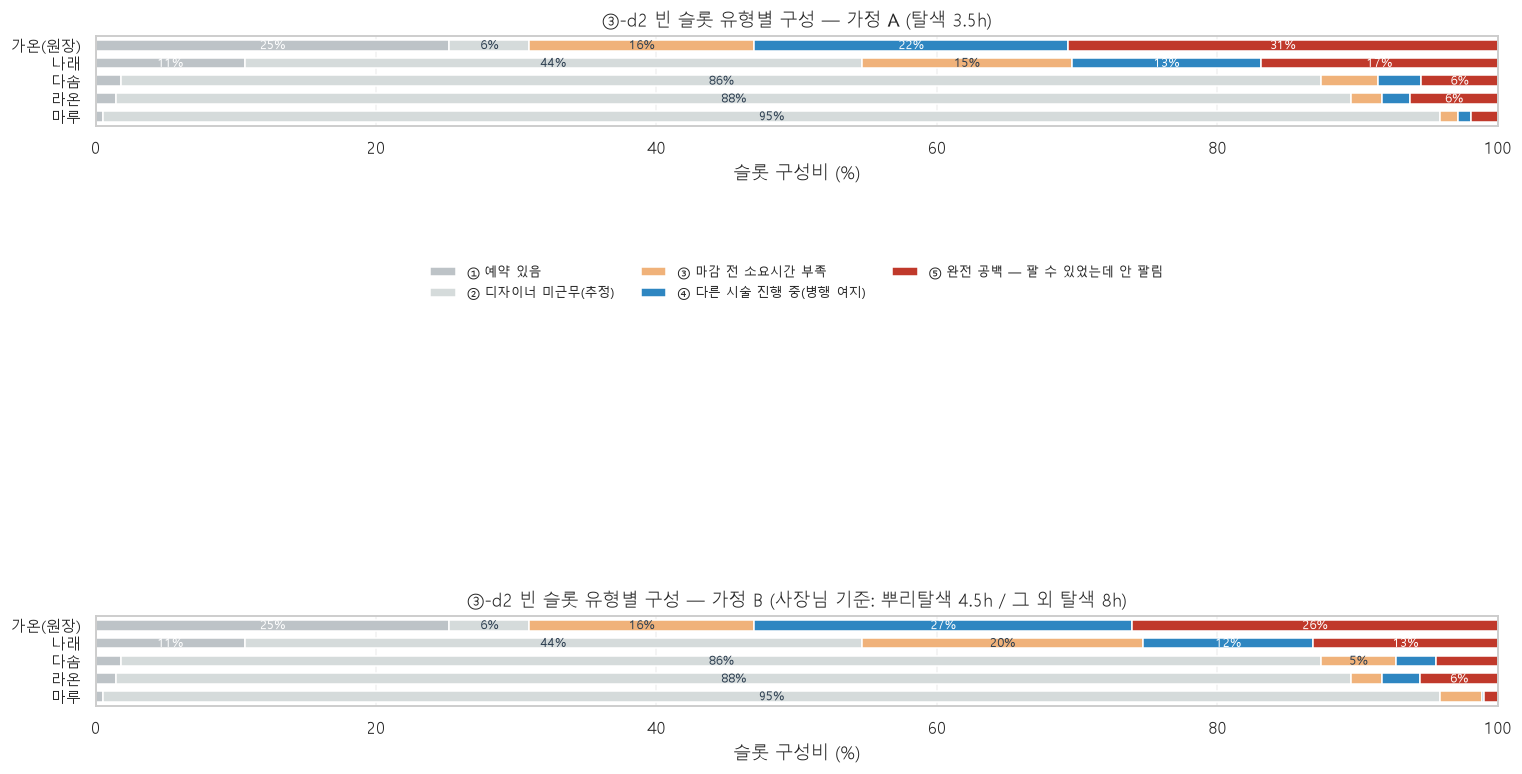

In [51]:
# ── ③-d 그래프: 빈 슬롯 유형별 100% 누적 가로 막대 ─────────────────────────
fig, axes = plt.subplots(2, 1, figsize=(14, 7.2))
_cols5 = [C_GRAY, "#d5dbdb", "#f0b27a", C_SUB, C_ACC]
for ax, asm in zip(axes, ["A", "B"]):
    sub = SLOT[SLOT.가정 == asm].set_index("디자이너").reindex(REAL_DESIGNERS)
    pct_ = sub[SLOT_CATS].div(sub[SLOT_CATS].sum(axis=1), axis=0) * 100
    left = np.zeros(len(pct_))
    for cat, col in zip(SLOT_CATS, _cols5):
        v = pct_[cat].values
        ax.barh(range(len(pct_)), v, left=left, color=col, height=0.6,
                edgecolor="white", label=cat if asm == "A" else None)
        for i, (x0, w) in enumerate(zip(left, v)):
            if w >= 4.5:
                ax.annotate(f"{w:.0f}%", (x0 + w/2, i), ha="center", va="center",
                            fontsize=8.5, color="white" if col in (C_SUB, C_ACC, C_GRAY) else "#2c3e50")
        left = left + v
    ax.set_yticks(range(len(pct_)))
    ax.set_yticklabels([d.replace(" 디자이너", "").replace(" 대표원장", "(원장)") for d in pct_.index],
                       fontsize=9.5)
    ax.invert_yaxis(); ax.set_xlim(0, 100)
    ax.set_xlabel("슬롯 구성비 (%)")
    ax.set_title(f"③-d2 빈 슬롯 유형별 구성 — 가정 {asm}"
                 f"{' (탈색 3.5h)' if asm == 'A' else ' (사장님 기준: 뿌리탈색 4.5h / 그 외 탈색 8h)'}")
    ax.grid(axis="y", alpha=0)
axes[0].legend(fontsize=8.5, loc="upper center", bbox_to_anchor=(0.5, -1.42), ncol=3, frameon=False)
plt.tight_layout(); plt.show()

## ③-e 판정

위를 종합해 명확히 답한다. **결론을 미리 정해 두지 않았다.** 계산 결과가 어느 쪽이든 그대로 낸다.

In [52]:
# ── ③-e 캐파 판정 ──────────────────────────────────────────────────────────
_j_day = _dz_day.loc["가온 대표원장"]
_h_day = _dz_day.loc["나래 디자이너"]
_jt = CAP_CMP.loc["가온 대표원장"]
_ht = CAP_CMP.loc["나래 디자이너"]
_gapj = GAP_TBL.loc["가온 대표원장"]
_concA = CONC_DZ[(CONC_DZ.가정 == "A") & (CONC_DZ.designer == "가온 대표원장")]

EVID = pd.DataFrame([
    {"번호": 1, "근거": "실증 상한 대비 실적",
     "숫자": f"가온 하루 평균 {_j_day.mean():.2f}건 vs 본인이 실제 달성한 p90 {_j_day.quantile(.9):.0f}건 "
             f"(5건 이상 {int((_j_day>=5).sum())}일 / {len(_j_day)}일 = {(_j_day>=5).mean()*100:.1f}%)",
     "가리키는 방향": "여유 있음"},
    {"번호": 2, "근거": "병행 시술 실재 (가정 무관)",
     "숫자": f"같은 날 연속 예약 시작 간격 중앙 {_gapj['중앙 간격(h)']:.2f}h · "
             f"1시간 이내 {_gapj['1시간 이하(%)']:.1f}% · 3.5시간 이내 {_gapj['3.5시간 미만(%)']:.1f}%",
     "가리키는 방향": "여유 있음 (시간 점유율은 캐파 척도가 아님)"},
    {"번호": 3, "근거": "매장 동시 처리 실적",
     "숫자": f"동시 3명 이상인 날 {int(CONC_ST[(CONC_ST.가정=='A')].max_conc.ge(3).sum())}일 "
             f"({CONC_ST[CONC_ST.가정=='A'].max_conc.ge(3).mean()*100:.1f}%) · 최대 동시 "
             f"{int(CONC_ST[CONC_ST.가정=='A'].max_conc.max())}명 · 하루 최대 완료 {int(_store_day.max())}건 "
             f"(평균 {_store_day.mean():.2f}건)",
     "가리키는 방향": "여유 있음"},
    {"번호": 4, "근거": "완전 공백 슬롯",
     "숫자": f"가정A {_aggp.loc['A','⑤ 완전 공백 — 팔 수 있었는데 안 팔림']:.1f}% / "
             f"가정B {_aggp.loc['B','⑤ 완전 공백 — 팔 수 있었는데 안 팔림']:.1f}% "
             f"(근무일 중 완전 빈 시간 합계 A {_sum.loc['A','빈시간_h']:,.0f}h / B {_sum.loc['B','빈시간_h']:,.0f}h)",
     "가리키는 방향": "여유 있음"},
    {"번호": 5, "근거": "시간 기준 가동률(기존 결론)",
     "숫자": f"가온 A {_jt['시간기준 가동률 [A](%)']:.1f}% / B {_jt['시간기준 가동률 [B](%)']:.1f}% · "
             f"가정B에서 10시간 초과일이 {CAP_TIME.loc['가온 대표원장','10h 초과일 비율[B](%)']:.1f}%",
     "가리키는 방향": "포화처럼 보이나, 초과일 비율이 절반을 넘어 가정 자체가 과대"},
], columns=["번호", "근거", "숫자", "가리키는 방향"]).set_index("번호")
tbl(EVID, "③-e1 판정 근거 5개")

_free_ratio = _aggp.loc["A", "⑤ 완전 공백 — 팔 수 있었는데 안 팔림"]
CAPACITY_VERDICT = "여유 있음" if (_j_day.mean() < _j_day.quantile(0.9) and _free_ratio > 5) else "포화"

print("=" * 96)
print(f"③-e 판정 : 캐파에 **{CAPACITY_VERDICT}**")
print("=" * 96)
print()
print("[1] 캐파가 꽉 찼는가?  →  아니다.")
print(f"    가온는 근무일의 {(_j_day>=5).mean()*100:.1f}%에서 5건 이상을 실제로 해냈는데 평균은 {_j_day.mean():.2f}건이다.")
print(f"    나래는 최대 {int(_h_day.max())}건을 해냈는데 평균은 {_h_day.mean():.2f}건이다.")
print(f"    매장 전체는 최대 {int(_store_day.max())}건을 해냈는데 평균은 {_store_day.mean():.2f}건이다.")
print()
print("[2] 그럼 '가동률 78%'는 왜 나왔나?")
print(f"    예약 1건의 가정 소요시간이 길기 때문이다(가온 예약당 A {_jt['예약당 평균 소요h [A]']:.2f}h / B {_jt['예약당 평균 소요h [B]']:.2f}h).")
print(f"    그런데 실제로는 앞 손님 시작 후 중앙 {_gapj['중앙 간격(h)']:.2f}시간 만에 다음 손님을 시작한다.")
print("    → 그 시간 내내 한 손님에게 붙어 있지 않다. 시간 점유율은 캐파의 척도가 아니다.")
print("    ⚠️ 데이터만으로는 '병행한다'와 '소요시간 가정이 과대하다'를 구분할 수 없다.")
print("       그러나 어느 쪽이든 '시간 가동률이 높으니 포화'는 성립하지 않는다.")
print()
print("[3] 여유는 어디에 있나?")
_wk = _hm_avg.stack().sort_values()
_empty = _wk[_wk < _wk.quantile(0.30)]
_by_h = _hm_avg.mean(axis=0).sort_values()
_by_d = _hm_avg.sum(axis=1).sort_values()
print(f"    시각 — 가장 빈 시간대: " +
      " / ".join(f"{int(h)}시({v:.2f}건)" for h, v in _by_h.head(4).items()))
print(f"           가장 찬 시간대: " +
      " / ".join(f"{int(h)}시({v:.2f}건)" for h, v in _by_h.tail(3).items()))
print(f"    요일 — 가장 빈 요일: " + " / ".join(f"{d}({v:.2f}건/일)" for d, v in _by_d.head(3).items()))
print(f"           가장 찬 요일: " + " / ".join(f"{d}({v:.2f}건/일)" for d, v in _by_d.tail(2).items()))
print(f"    디자이너 — 완전 공백 슬롯 비중 [가정A]: " +
      " / ".join(f"{d.replace(' 디자이너','').replace(' 대표원장','')} "
                 f"{SLOT[(SLOT.가정=='A')&(SLOT.디자이너==d)]['⑤ 완전 공백 — 팔 수 있었는데 안 팔림'].iloc[0] / (SLOT[(SLOT.가정=='A')&(SLOT.디자이너==d)]['총 슬롯'].iloc[0]) * 100:.1f}%"
                 for d in REAL_DESIGNERS))
print()
print("[4] 병목은 무엇인가?")
print("    디자이너 '시간'이 아니다. 위 [2] 참조.")
print(f"    구조적 제약은 **탈색의 길이 x 마감 20시** 조합이다.")
print(f"    '③ 마감 전 소요시간 부족' 슬롯이 가정A {_aggp.loc['A','③ 마감 전 소요시간 부족']:.1f}% / "
      f"가정B {_aggp.loc['B','③ 마감 전 소요시간 부족']:.1f}% 다.")
print(f"    실제로 16시 이후 시작 건은 완료의 {(DONE.hour>=16).mean()*100:.1f}% 뿐이다"
      f" (10~13시가 {(DONE.hour.between(10,13)).mean()*100:.1f}%).")
print(f"    또 하나는 **인력 배치**다. 영업일 {len(BIZ_DATES)}일 중 가온 {len(_j_day)}일 · 나래 {len(_h_day)}일 근무이고,")
print(f"    다솜·라온·마루는 각각 {len(_dz_day.loc['다솜 디자이너'])}일 · {len(_dz_day.loc['라온 디자이너'])}일 · "
      f"{len(_dz_day.loc['마루 디자이너'])}일뿐이다.")
print()
print("[5] 신규 유입을 늘리면 몇 건/월까지 받을 수 있나?")
for asm in ["A", "B"]:
    r = _sum.loc[asm]
    print(f"    [가정 {asm}] 월 {r['하한 월평균(건)']:.1f}건(하한) ~ {r['상한 월평균(건)']:.1f}건(상한)")
    print(f"             현재 월평균 {r['현재 월평균 완료(건)']:.1f}건 대비 "
          f"+{r['하한 증가율(%)']:.0f}% ~ +{r['상한 증가율(%)']:.0f}%")
print(f"    객단가 중앙값 {_med_paid:,.0f}원 기준 월 추가 매출 "
      f"{POTENTIAL['객단가 중앙값 기준 월 매출(원)'].min():,.0f} ~ "
      f"{POTENTIAL['객단가 중앙값 기준 월 매출(원)'].max():,.0f}원 (추정)")
print()
print("[6] 가정 A와 B에서 결론이 갈리는가?  →  갈리지 않는다.")
print(f"    완전 공백 슬롯 비중: A {_aggp.loc['A','⑤ 완전 공백 — 팔 수 있었는데 안 팔림']:.1f}% vs "
      f"B {_aggp.loc['B','⑤ 완전 공백 — 팔 수 있었는데 안 팔림']:.1f}%")
print(f"    추가 가능 월 건수(하한): A {_sum.loc['A','하한 월평균(건)']:.1f}건 vs B {_sum.loc['B','하한 월평균(건)']:.1f}건")
print("    가정 B가 더 보수적이지만, 두 가정 모두 '여유 있음'을 가리킨다. **규모만 다르다.**")
print()
print("[7] 그래도 받을 수 없는 부분은?")
print(f"    · 16시 이후 시작하는 긴 시술(탈색)은 마감 때문에 구조적으로 불가능하다.")
print(f"    · 미근무일(가온 {len(BIZ_DATES)-len(_j_day)}일, 나래 {len(BIZ_DATES)-len(_h_day)}일)은")
print(f"      인력을 더 넣지 않는 한 팔 수 없다. 위 추정에서 아예 제외했다.")
print(f"    · '자리가 있다'와 '손님이 온다'는 다르다. 위 숫자는 전부 **공급 측 상한**이다.")
print("=" * 96)

**③-e1 판정 근거 5개**

,근거,숫자,가리키는 방향
번호,,,
1,실증 상한 대비 실적,가온 하루 평균 2.93건 vs 본인이 실제 달성한 p90 5건 (5건 이상 95일 / 547일 = 17.4%),여유 있음
2,병행 시술 실재 (가정 무관),같은 날 연속 예약 시작 간격 중앙 1.50h · 1시간 이내 48.0% · 3.5시간 이내 82.8%,여유 있음 (시간 점유율은 캐파 척도가 아님)
3,매장 동시 처리 실적,동시 3명 이상인 날 321일 (55.3%) · 최대 동시 10명 · 하루 최대 완료 14건 (평균 4.71건),여유 있음
4,완전 공백 슬롯,"가정A 12.3% / 가정B 10.0% (근무일 중 완전 빈 시간 합계 A 5,830h / B 4,355h)",여유 있음
5,시간 기준 가동률(기존 결론),가온 A 69.9% / B 111.3% · 가정B에서 10시간 초과일이 46.4%,"포화처럼 보이나, 초과일 비율이 절반을 넘어 가정 자체가 과대"


③-e 판정 : 캐파에 **여유 있음**

[1] 캐파가 꽉 찼는가?  →  아니다.
    가온는 근무일의 17.4%에서 5건 이상을 실제로 해냈는데 평균은 2.93건이다.
    나래는 최대 6건을 해냈는데 평균은 1.98건이다.
    매장 전체는 최대 14건을 해냈는데 평균은 4.71건이다.

[2] 그럼 '가동률 78%'는 왜 나왔나?
    예약 1건의 가정 소요시간이 길기 때문이다(가온 예약당 A 2.39h / B 3.80h).
    그런데 실제로는 앞 손님 시작 후 중앙 1.50시간 만에 다음 손님을 시작한다.
    → 그 시간 내내 한 손님에게 붙어 있지 않다. 시간 점유율은 캐파의 척도가 아니다.
    ⚠️ 데이터만으로는 '병행한다'와 '소요시간 가정이 과대하다'를 구분할 수 없다.
       그러나 어느 쪽이든 '시간 가동률이 높으니 포화'는 성립하지 않는다.

[3] 여유는 어디에 있나?
    시각 — 가장 빈 시간대: 20시(0.01건) / 19시(0.15건) / 16시(0.33건) / 18시(0.33건)
           가장 찬 시간대: 13시(0.58건) / 12시(0.67건) / 11시(0.72건)
    요일 — 가장 빈 요일: 화(3.90건/일) / 일(4.02건/일) / 수(4.22건/일)
           가장 찬 요일: 월(5.07건/일) / 금(6.33건/일)
    디자이너 — 완전 공백 슬롯 비중 [가정A]: 가온 30.7% / 나래 16.9% / 다솜 5.5% / 라온 6.3% / 마루 1.9%

[4] 병목은 무엇인가?
    디자이너 '시간'이 아니다. 위 [2] 참조.
    구조적 제약은 **탈색의 길이 x 마감 20시** 조합이다.
    '③ 마감 전 소요시간 부족' 슬롯이 가정A 7.7% / 가정B 9.3% 다.
    실제로 16시 이후 시작 건은 완료의 24.6% 뿐이다 (10~13시가 52.7%).
    또 하나는 **인력 배치**다. 영업일 580일 중 가온 547일 · 나래 32

## ③-E 관측 기반 캐파 재판정 — 가정 논쟁을 끝낸다

③-a ~ ③-e 는 **가정 A**(01번 추정치)와 **가정 B**(사장님 인터뷰) 두 벌로 계산했고,
셀 ③-e 는 "가정 B는 과대"라고 적어 두었다. 어느 쪽이 맞는지는 데이터로 정하지 못했다.

이제 **관측 소요시간**(`done_dt - use_dt`, 당일 처리 945건)이 있다. 여기서는 세 가지를 다시 낸다.

| | 무엇을 | 가정이 필요한가 |
|---|---|---|
| ③-E1 | 점유율 재판정 — 하루 건수로 조건화해 편향을 보정 | **없음** (구간 합집합 직접 측정) |
| ③-E2 | **마감 역산으로 빈 슬롯 재분류 → 추가 수용 가능 건수** | 없음 (관측 중앙값 + 마감시각) |
| ③-E3 | 10~13시 집중(52.7%)은 수요 쏠림인가 제약인가 | 없음 |
| ③-E4 | 최종 판정 재작성 | — |

**기존 ③ 결과는 하나도 지우지 않는다.** 가정 A·B·관측 세 벌을 나란히 두는 것이 목적이다.
결론이 갈리면 갈리는 대로 적고, 안 갈리면 안 갈린다고 적는다.

### 반드시 함께 읽을 한계

* **관측 표본은 완료의 34.6%** 이고, 늦게 끝난 건이 빠지는 **절단 편향**이 있다 → 관측값은 **하한**.
* 건수별 점유h 곡선의 **3건 이상 칸은 표본이 얇다**(각 9·4·1일). 방향만 읽고 배수는 확정하지 말 것.
* **마감 20:30 은 하드 제약이 아니다.** 사장님 인터뷰에 "5시에 와도 연장 근무해서 끝까지 시술"이 있고,
  관측 945건 중 **13.5%가 마감 이후에, 5.8%가 21시 이후에** 종료됐다(③-E0 에서 직접 계산).
  그러므로 아래의 "불가"는 전부
  **"연장 근무 없이는 불가"** 로 읽어야 한다. 이 노트북은 그 표기를 쓴다.


In [53]:
# ── ③-E0 관측 소요시간 로드 + 예약별 부여 ─────────────────────────────────
# ⚠️ 01번 산출물(compare_table.csv 등)을 읽지 않는다. 노트북 간 의존을 만들지 않기 위해
#    파이프라인 입력(make_service_duration.py 산출물)만 읽고, 파생은 여기서 다시 계산한다.
SDM_PATH = Path(os.environ.get("SALON_MANUAL", "../data/manual")) / "service_duration_v2.csv"
if not SDM_PATH.exists():
    SDM_PATH = Path("data/manual/service_duration_v2.csv")
assert SDM_PATH.exists(), (f"관측 소요시간 CSV 를 찾지 못했다: {SDM_PATH.resolve()}\n"
                           f"  프로젝트 루트에서 python make_service_duration.py 를 먼저 실행할 것")
SDM = pd.read_csv(SDM_PATH, encoding="utf-8-sig")

OBS_MIN_N = 10                                            # n<10 은 노이즈라 안 쓴다
_sm = SDM[(SDM.level == "메뉴") & (SDM.n >= OBS_MIN_N)].set_index("menu")
_sc = SDM[SDM.level == "카테고리"].set_index("category")
DUR_OBS_MENU = _sm["중앙값_h"].to_dict()
DUR_OBS_CAT  = _sc["중앙값_h"].to_dict()
MENU_OBS     = pd.Series(DUR_OBS_MENU).sort_values()      # 마감 역산에 쓸 메뉴 목록
FLAGSHIP     = [m for m in ["뿌리탈색이벤트", "무한탈색이벤트"] if m in DUR_OBS_MENU]

# 예약 단위 부여: 유료 메뉴 1종이면 메뉴값 → 아니면 대표시술 카테고리값 → 그래도 없으면 가정A
_pl    = LX[LX.is_free == 0]
_only1 = _pl.groupby("예약번호").menu.agg(["nunique", "first"])
_only1 = _only1[_only1["nunique"] == 1]["first"]
DONE["durO"]     = DONE.예약번호.map(_only1).map(DUR_OBS_MENU)
DONE["durO_src"] = pd.Series("미매칭", index=DONE.index, dtype="object")
DONE.loc[DONE.durO.notna(), "durO_src"] = "메뉴"
_fb = DONE.durO.isna()
DONE.loc[_fb, "durO"] = DONE.loc[_fb, "rep_cat"].map(DUR_OBS_CAT)
DONE.loc[_fb & DONE.durO.notna(), "durO_src"] = "카테고리"
_n_unm = int(DONE.durO.isna().sum())
DONE["durO"] = DONE.durO.fillna(DONE.durA).clip(lower=MIN_DUR)   # 극소수 미매칭은 가정A로 메움

# 마감 — 원페이지 소개자료 기준. 평일 20:30 / 주말 20:00
CLOSE_WD, CLOSE_WE = 20.5, 20.0
CLOSE_OF = {pd.Timestamp(d): (CLOSE_WE if pd.Timestamp(d).weekday() >= 5 else CLOSE_WD)
            for d in BIZ_DATES}

_cov = (DONE.groupby("durO_src").agg(건수=("예약번호", "size"), 중앙소요h=("durO", "median"))
             .reindex(["메뉴", "카테고리", "미매칭"]))
_cov["건수"] = _cov["건수"].fillna(0).astype(int)
_cov["비중(%)"] = _cov.건수 / len(DONE) * 100
tbl(_cov.round(2), "③-E0 관측 소요시간 부여 경로 (완료 기준)")

print(f"관측 CSV {SDM_PATH.name} · 메뉴 {len(_sm)}종(n>={OBS_MIN_N}) / 카테고리 {len(_sc)}종")
print(f"마감 역산에 쓸 메뉴 {len(MENU_OBS)}종 — {MENU_OBS.min():.2f}h({mdisp(MENU_OBS.idxmin())}) ~ "
      f"{MENU_OBS.max():.2f}h({mdisp(MENU_OBS.idxmax())})  · 주력 {FLAGSHIP}")
print(f"미매칭 {_n_unm}건은 가정 A 값으로 메웠다 (rep_cat 에 관측 표본이 없는 '기타').")
print()
print("예약당 소요시간 중앙 — 가정A {:.2f}h / 가정B {:.2f}h / 관측 {:.2f}h".format(
    DONE.durA.median(), DONE.durB.median(), DONE.durO.median()))
print("             평균 — 가정A {:.2f}h / 가정B {:.2f}h / 관측 {:.2f}h".format(
    DONE.durA.mean(), DONE.durB.mean(), DONE.durO.mean()))
print("→ 관측은 가정 A보다 길고 가정 B보다 짧다. 두 가정 사이에 있다.")

# ── 마감은 하드 제약이 아니다 — 그 크기를 관측에서 직접 잰다 ─────────────────
# 아래 ③-E2·E3 의 '불가'는 전부 '연장 근무 없이는 불가'다. 연장이 실제로 얼마나
# 일어나는지 세어 두고, 뒤에서 그 수치를 인용한다.
_obs   = DONE[(DONE.done_dt.dt.normalize() == DONE.date)
              & ((DONE.done_dt - DONE.use_dt).dt.total_seconds() > 0)]
_endh  = _obs.done_dt.dt.hour + _obs.done_dt.dt.minute / 60
_clof  = np.where(_obs.use_dt.dt.weekday >= 5, CLOSE_WE, CLOSE_WD)
N_OBS        = len(_obs)
OVERRUN_RATE = float((_endh > _clof).mean() * 100)     # 요일별 마감 이후 종료
LATE21_RATE  = float((_endh >= 21.0).mean() * 100)     # 21시 이후 종료
print()
print(f"마감 초과 종료 — 관측 {N_OBS:,}건 중 {int((_endh > _clof).sum()):,}건({OVERRUN_RATE:.1f}%)이 "
      f"요일별 마감(평일 {CLOSE_WD}시 / 주말 {CLOSE_WE}시) 이후에 끝났고, "
      f"{int((_endh >= 21).sum()):,}건({LATE21_RATE:.1f}%)은 21시 이후다.")
print("→ 마감은 하드 제약이 아니다. 아래의 '불가'는 전부 **'연장 근무 없이는 불가'** 로 읽을 것.")


**③-E0 관측 소요시간 부여 경로 (완료 기준)**

,건수,중앙소요h,비중(%)
durO_src,,,
메뉴,2007,4.88,73.46
카테고리,724,2.07,26.50
미매칭,1,0.50,0.04


관측 CSV service_duration_v2.csv · 메뉴 13종(n>=10) / 카테고리 7종
마감 역산에 쓸 메뉴 13종 — 0.64h(남자컷) ~ 6.89h(무한탈색이벤트)  · 주력 ['뿌리탈색이벤트', '무한탈색이벤트']
미매칭 1건은 가정 A 값으로 메웠다 (rep_cat 에 관측 표본이 없는 '기타').

예약당 소요시간 중앙 — 가정A 3.50h / 가정B 4.50h / 관측 4.88h
             평균 — 가정A 2.63h / 가정B 4.29h / 관측 4.13h
→ 관측은 가정 A보다 길고 가정 B보다 짧다. 두 가정 사이에 있다.

마감 초과 종료 — 관측 945건 중 128건(13.5%)이 요일별 마감(평일 20.5시 / 주말 20.0시) 이후에 끝났고, 55건(5.8%)은 21시 이후다.
→ 마감은 하드 제약이 아니다. 아래의 '불가'는 전부 **'연장 근무 없이는 불가'** 로 읽을 것.


In [54]:
# ── ③-E1 점유율 재판정 — 구간 합집합 + 하루 건수 조건화 보정 ──────────────
# 합산(Σ 소요시간)은 병행 구간을 두 번 센다. 실제 점유는 구간의 **합집합**이다.
# 대상은 그 디자이너-일의 완료 건이 **전부 당일처리**인 날뿐이다(구간에 구멍이 없어야 한다).
DONE["gap_obs"] = (DONE.done_dt - DONE.use_dt).dt.total_seconds() / 3600
DONE["obs_ok"]  = (DONE.done_dt.dt.normalize() == DONE.date) & (DONE.gap_obs > 0)
_full = DONE.groupby(["designer", "date"]).obs_ok.all()
DONE["full_day"] = pd.MultiIndex.from_frame(DONE[["designer", "date"]]).map(_full).astype(bool)

def _union_h(iv):
    """[(start, end), ...] 합집합 길이(시간)"""
    iv = sorted(iv); tot, s, e = 0.0, iv[0][0], iv[0][1]
    for a, b in iv[1:]:
        if a > e: tot += (e - s).total_seconds(); s, e = a, b
        else:     e = max(e, b)
    return (tot + (e - s).total_seconds()) / 3600

_rows = [{"designer": dz, "건수": len(g), "합산h": float(g.gap_obs.sum()),
          "점유h": _union_h(list(zip(g.use_dt, g.done_dt)))}
         for (dz, _d), g in DONE[DONE.full_day].groupby(["designer", "date"])]
DAY_U = pd.DataFrame(_rows)
OCC_KMAX = 5
DAY_U["k"] = DAY_U.건수.clip(upper=OCC_KMAX)
OCC_CURVE  = DAY_U.groupby("k").점유h.median()

_cv = pd.concat([DAY_U.groupby("k").size().rename("일수"),
                 DAY_U.groupby("k").합산h.median().rename("합산h 중앙"),
                 OCC_CURVE.rename("점유h 중앙")], axis=1)
_cv["병행배수"] = _cv["합산h 중앙"] / _cv["점유h 중앙"]
_cv.index.name = "하루 건수 k"
tbl(_cv.round(2), f"③-E1a 건수별 점유h 곡선 — 합산은 계속 커지지만 점유는 천장을 친다 (k>={OCC_KMAX} 클리핑)")

# 편향 보정: 관측 표본은 가벼운 날에 쏠려 있다. 하루 건수로 조건화하면 그 상관이 끊긴다.
#   보정 점유h = Σ_k P(k) x curve[min(k, KMAX)],  P(k) = 그 디자이너의 실제 하루 건수 분포
_dayn = DONE.groupby(["designer", "date"]).size().rename("n").reset_index()
_dayn["k"] = _dayn.n.clip(upper=OCC_KMAX)
_P = _dayn.groupby(["designer", "k"]).size().unstack(fill_value=0)
_P = _P.div(_P.sum(axis=1), axis=0)
UTIL_ADJ = (_P * OCC_CURVE.reindex(_P.columns).values).sum(axis=1) / 10 * 100

OCC_CMP = pd.DataFrame({
    "근무일수": _dayn.groupby("designer").size(),
    "하루 평균 건수": _dayn.groupby("designer").n.mean(),
    "관측표본 하루건수": DAY_U.groupby("designer").건수.mean(),
    "점유율(완전관측 표본, 편향 있음)(%)": DAY_U.groupby("designer").점유h.mean() / BIZ_HOURS * 100,
    "점유율(건수 조건화 보정)(%)": UTIL_ADJ,
}).reindex(REAL_DESIGNERS).dropna(subset=["근무일수"])
OCC_CMP["시간기준 [A](%)"] = CAP_CMP["시간기준 가동률 [A](%)"]
OCC_CMP["시간기준 [B](%)"] = CAP_CMP["시간기준 가동률 [B](%)"]
OCC_CMP = OCC_CMP.sort_values("점유율(건수 조건화 보정)(%)", ascending=False)
tbl(OCC_CMP.round(2),
    "③-E1b ★ 세 기준 나란히 — 가정A / 가정B(합산) vs 관측(구간 합집합, 보정). 전 기간 20개월")

print("읽는 법 — 앞 두 열은 같은 관측 데이터를 다르게 자른 것이고, 그 차이가 표본 편향의 크기다.")
print("          뒤 두 열은 소요시간 **가정**을 합산한 값이라 병행 구간이 중복 계산돼 있다.")
print()
for _d, _r in OCC_CMP.iterrows():
    print(f"  {_d.replace(' 디자이너','').replace(' 대표원장',''):<5s} "
          f"실제 {_r['하루 평균 건수']:.2f}건/일 (관측표본 {_r['관측표본 하루건수']:.2f}건/일) → "
          f"점유 {_r['점유율(완전관측 표본, 편향 있음)(%)']:.1f}% → 보정 {_r['점유율(건수 조건화 보정)(%)']:.1f}%  "
          f"| 합산 A {_r['시간기준 [A](%)']:.1f}% / B {_r['시간기준 [B](%)']:.1f}%")
print()

# 평균 하나로 요약하면 놓치는 것 — 분포
_TOPD = OCC_CMP["근무일수"].idxmax()
_jd   = _dayn[_dayn.designer == _TOPD]
DIST_O = pd.concat([_jd.n.value_counts().sort_index().rename("일수"),
                    (_jd.n.value_counts(normalize=True).sort_index() * 100).rename("비중(%)")], axis=1)
DIST_O.index.name = "하루 완료 건수"
DIST_O["이 건수 이상(%)"]   = DIST_O["비중(%)"][::-1].cumsum()[::-1]
DIST_O["그날 점유율(%)"]    = [OCC_CURVE[min(int(k), OCC_KMAX)] / BIZ_HOURS * 100 for k in DIST_O.index]
tbl(DIST_O.round(2), f"③-E1c {_TOPD} 하루 완료 건수 분포 (근무 {len(_jd)}일) — 평균보다 이 분포가 실제에 가깝다")

_c3p = float(DAY_U[DAY_U.건수 >= 3].점유h.median())
_ge4 = float((_jd.n >= 4).mean() * 100)
print(f"{_TOPD} 는 근무일의 {_ge4:.1f}% 가 하루 4건 이상이고, k>=3 인 날의 점유 중앙은 "
      f"{_c3p:.2f}시간 = 영업 10시간의 {_c3p/BIZ_HOURS*100:.0f}% 다 (n={int((DAY_U.건수>=3).sum())}일).")
print(f"→ **3일에 1일은 사실상 꽉 차 있다.** 평균 {UTIL_ADJ[_TOPD]:.1f}% 하나로 요약하면 이걸 놓친다.")
print(f"   ③-b2 의 '건수 기준 가동률'이 여유를 가리킨 것은 **평균만 봤기 때문**이다.")
print("   그리고 관측 소요시간 자체가 절단 편향으로 하한이므로 실제 점유는 이보다 높다.")


**③-E1a 건수별 점유h 곡선 — 합산은 계속 커지지만 점유는 천장을 친다 (k>=5 클리핑)**

,일수,합산h 중앙,점유h 중앙,병행배수
하루 건수 k,,,,
1,205,4.26,4.26,1.00
2,51,9.54,6.97,1.37
3,9,14.10,9.27,1.52
4,4,26.03,9.98,2.61
5,1,26.63,9.16,2.91


**③-E1b ★ 세 기준 나란히 — 가정A / 가정B(합산) vs 관측(구간 합집합, 보정). 전 기간 20개월**

,근무일수,하루 평균 건수,관측표본 하루건수,"점유율(완전관측 표본, 편향 있음)(%)",점유율(건수 조건화 보정)(%),시간기준 [A](%),시간기준 [B](%)
designer,,,,,,,
가온 대표원장,547,2.93,1.64,49.45,77.77,69.91,111.31
나래 디자이너,325,1.98,1.34,62.17,65.17,63.13,107.06
다솜 디자이너,84,1.35,1.24,47.60,51.64,45.67,77.46
라온 디자이너,69,1.25,1.22,34.44,48.83,26.88,45.80
마루 디자이너,27,1.15,1.06,52.63,46.49,41.67,76.85


읽는 법 — 앞 두 열은 같은 관측 데이터를 다르게 자른 것이고, 그 차이가 표본 편향의 크기다.
          뒤 두 열은 소요시간 **가정**을 합산한 값이라 병행 구간이 중복 계산돼 있다.

  가온    실제 2.93건/일 (관측표본 1.64건/일) → 점유 49.5% → 보정 77.8%  | 합산 A 69.9% / B 111.3%
  나래    실제 1.98건/일 (관측표본 1.34건/일) → 점유 62.2% → 보정 65.2%  | 합산 A 63.1% / B 107.1%
  다솜    실제 1.35건/일 (관측표본 1.24건/일) → 점유 47.6% → 보정 51.6%  | 합산 A 45.7% / B 77.5%
  라온    실제 1.25건/일 (관측표본 1.22건/일) → 점유 34.4% → 보정 48.8%  | 합산 A 26.9% / B 45.8%
  마루    실제 1.15건/일 (관측표본 1.06건/일) → 점유 52.6% → 보정 46.5%  | 합산 A 41.7% / B 76.9%



**③-E1c 가온 대표원장 하루 완료 건수 분포 (근무 547일) — 평균보다 이 분포가 실제에 가깝다**

,일수,비중(%),이 건수 이상(%),그날 점유율(%)
하루 완료 건수,,,,
1,114,20.84,100.00,42.63
2,129,23.58,79.16,69.71
3,123,22.49,55.58,92.69
4,86,15.72,33.09,99.82
5,64,11.70,17.37,91.60
6,20,3.66,5.67,91.60
7,10,1.83,2.01,91.60
8,1,0.18,0.18,91.60


가온 대표원장 는 근무일의 33.1% 가 하루 4건 이상이고, k>=3 인 날의 점유 중앙은 9.42시간 = 영업 10시간의 94% 다 (n=14일).
→ **3일에 1일은 사실상 꽉 차 있다.** 평균 77.8% 하나로 요약하면 이걸 놓친다.
   ③-b2 의 '건수 기준 가동률'이 여유를 가리킨 것은 **평균만 봤기 때문**이다.
   그리고 관측 소요시간 자체가 절단 편향으로 하한이므로 실제 점유는 이보다 높다.


In [55]:
# ── ③-E2 ★ 마감 역산으로 빈 슬롯 재분류 → 추가 수용 가능 건수 재계산 ──────
# ③-d2 는 '디자이너별 중앙 소요시간'으로 마감 가능 여부를 판정했다.
# 여기서는 **메뉴별 관측 중앙값**으로 "그 시각에 시작할 수 있는 메뉴가 몇 종인가"를 직접 센다.
_occO      = {k: (g.start_h.values, g.start_h.values + g.durO.values)
              for k, g in DONE.groupby(["designer", "date"])}
_start_cnt = DONE.groupby(["designer", "date", DONE.use_dt.dt.hour]).size().to_dict()
_medO      = {d: float(DONE[DONE.designer == d].durO.median()) for d in REAL_DESIGNERS}

SLOT_CATS_O = ["① 예약 있음", "② 디자이너 미근무(추정)",
               "③ 다른 시술 진행 중(병행 여지)",
               "④ 판매 가능 공백 — 주력 탈색까지 가능",
               "⑤ 판매 가능 공백 — 짧은 시술만 가능",
               "⑥ 구조적 불가 — 연장 근무 없이 시작 가능 메뉴 0종"]

_rows = []
for dz in REAL_DESIGNERS:
    c = dict.fromkeys(SLOT_CATS_O, 0)
    for dt_ in BIZ_DATES:
        key = (dz, pd.Timestamp(dt_))
        worked = key in _work_set
        occ    = _occO.get(key)
        cl     = CLOSE_OF[pd.Timestamp(dt_)]
        for h in range(BIZ_OPEN, BIZ_CLOSE):
            if _start_cnt.get((dz, pd.Timestamp(dt_), h), 0) > 0:
                c[SLOT_CATS_O[0]] += 1; continue
            if not worked:
                c[SLOT_CATS_O[1]] += 1; continue
            n_ok = int((h + MENU_OBS <= cl).sum())
            if n_ok == 0:
                c[SLOT_CATS_O[5]] += 1; continue
            s, e = occ
            if bool(((s <= h + 1e-9) & (e > h + 1e-9)).any()):
                c[SLOT_CATS_O[2]] += 1; continue
            flag_ok = any(h + DUR_OBS_MENU[m] <= cl for m in FLAGSHIP)
            c[SLOT_CATS_O[3 if flag_ok else 4]] += 1
    _rows.append({"디자이너": dz, "중앙 소요h(관측)": _medO[dz],
                  "근무일": sum(1 for dt_ in BIZ_DATES if (dz, pd.Timestamp(dt_)) in _work_set), **c})
SLOT_O = pd.DataFrame(_rows)
SLOT_O["총 슬롯"] = SLOT_O[SLOT_CATS_O].sum(axis=1)
tbl(SLOT_O.set_index("디자이너").round(2),
    f"③-E2a 관측 기준 슬롯 재분류 — 디자이너 {len(REAL_DESIGNERS)}명 x 영업일 {len(BIZ_DATES)}일 x {BIZ_CLOSE-BIZ_OPEN}슬롯")

_aggO  = SLOT_O[SLOT_CATS_O + ["총 슬롯"]].sum()
_aggOp = _aggO[SLOT_CATS_O] / _aggO["총 슬롯"] * 100
_sell  = float(_aggOp[SLOT_CATS_O[3]] + _aggOp[SLOT_CATS_O[4]])
tbl(_aggOp.round(2).rename("구성비(%)").to_frame(), "③-E2b 관측 기준 슬롯 구성비")

# 기존 가정 A·B 의 '⑤ 완전 공백' 과 나란히
_e5 = "⑤ 완전 공백 — 팔 수 있었는데 안 팔림"
_e3 = "③ 마감 전 소요시간 부족"
VOID_CMP = pd.DataFrame({
    "판매 가능 공백(%)": {"가정 A": _aggp.loc["A", _e5], "가정 B": _aggp.loc["B", _e5], "관측": _sell},
    "그중 주력 탈색까지 가능(%)": {"가정 A": np.nan, "가정 B": np.nan, "관측": float(_aggOp[SLOT_CATS_O[3]])},
    "마감 제약으로 불가(%)": {"가정 A": _aggp.loc["A", _e3], "가정 B": _aggp.loc["B", _e3],
                              "관측": float(_aggOp[SLOT_CATS_O[5]])},
})
tbl(VOID_CMP.round(2), "③-E2c ★ 빈 슬롯의 실체 — 가정 A / 가정 B / 관측")

# ── 추가 수용 가능 건수 재계산 ────────────────────────────────────────────────
# 기존 ③-d3 과 같은 패킹 로직. 다른 점은 (1) 관측 소요시간 (2) 마감이 요일별 실제 시각
STEP = 0.25
def _pack(dur, label):
    """dur 가 dict 면 디자이너별 소요시간, 스칼라면 전원 동일. 기존 ③-d3 과 같은 패킹."""
    rows = []
    for dz in REAL_DESIGNERS:
        dh = float(dur[dz]) if isinstance(dur, dict) else float(dur)
        free_h, packed = 0.0, 0
        for dt_ in BIZ_DATES:
            key = (dz, pd.Timestamp(dt_))
            if key not in _work_set:
                continue
            cl   = CLOSE_OF[pd.Timestamp(dt_)]
            s, e = _occO[key]
            grid = np.arange(BIZ_OPEN, cl, STEP)          # 그리드 끝이 곧 마감 = 마감 역산
            busy = ((grid[:, None] >= s[None, :] - 1e-9) & (grid[:, None] < e[None, :] - 1e-9)).any(axis=1)
            free_h += float((~busy).sum() * STEP)
            i = 0
            while i < len(grid):
                if busy[i]:
                    i += 1; continue
                j = i
                while j < len(grid) and not busy[j]:
                    j += 1
                run_s = float(grid[i])
                run_e = min(run_s + (j - i) * STEP, cl)   # 빈 구간 안에서, 그리고 마감 전에 끝나야 한다
                if run_e > run_s:
                    packed += int((run_e - run_s + 1e-9) // dh)
                i = j
        rows.append({"기준": label, "디자이너": dz, "소요h": dh,
                     "근무일 중 완전 빈 시간(h)": free_h, "추가 가능 건수": packed})
    return rows

LBL_MED   = "관측 중앙(디자이너별)"
LBL_FLAG  = f"주력만 채움({FLAGSHIP[0]})"
LBL_SHORT = "짧은 시술만 채움(컷)"
_short = float(DUR_OBS_CAT["컷"])
_packs  = _pack(_medO, LBL_MED)
_packs += _pack(float(DUR_OBS_MENU[FLAGSHIP[0]]), LBL_FLAG)
_packs += _pack(_short, LBL_SHORT)
PACK_O = pd.DataFrame(_packs)
PACK_SUM = PACK_O.groupby("기준").agg(빈시간_h=("근무일 중 완전 빈 시간(h)", "sum"),
                                      추가_건=("추가 가능 건수", "sum"), 소요h=("소요h", "median"))
PACK_SUM["월평균(건)"]   = PACK_SUM.추가_건 / N_MONTHS
PACK_SUM["현재 월평균"]  = len(DONE) / N_MONTHS
PACK_SUM["증가율(%)"]    = PACK_SUM["월평균(건)"] / PACK_SUM["현재 월평균"] * 100
tbl(PACK_SUM.round(2), "③-E2d ★ 관측 기준 추가 수용 가능 규모 — 무엇으로 채우느냐에 따라 크게 다르다")

CAP_CMP3 = pd.DataFrame({
    "월 추가 가능(하한, 건)": {
        "가정 A": _sum.loc["A", "하한 월평균(건)"], "가정 B": _sum.loc["B", "하한 월평균(건)"],
        "관측": float(PACK_SUM.loc[LBL_MED, "월평균(건)"])},
    "월 추가 가능(상한, 건)": {
        "가정 A": _sum.loc["A", "상한 월평균(건)"], "가정 B": _sum.loc["B", "상한 월평균(건)"],
        "관측": _sum.loc["A", "상한 월평균(건)"]},          # 상한은 실증 p90 이라 소요시간 무관
    "빈 시간 합계(h)": {
        "가정 A": _sum.loc["A", "빈시간_h"], "가정 B": _sum.loc["B", "빈시간_h"],
        "관측": float(PACK_SUM.loc[LBL_MED, "빈시간_h"])},
})
tbl(CAP_CMP3.round(1), "③-E2e ★★ 이번 작업의 결론 — 추가 수용 가능 규모가 얼마로 바뀌는가")
print(f"기존 표기: 월 {_sum.loc['B','하한 월평균(건)']:.1f} ~ {_sum.loc['A','상한 월평균(건)']:.1f}건")
print(f"관측 기준: 월 {PACK_SUM.loc[LBL_MED,'월평균(건)']:.1f} ~ "
      f"{_sum.loc['A','상한 월평균(건)']:.1f}건  "
      f"(주력 탈색으로만 채우면 {PACK_SUM.loc[LBL_FLAG,'월평균(건)']:.1f}건, "
      f"짧은 시술로 채우면 {PACK_SUM.loc[LBL_SHORT,'월평균(건)']:.1f}건)")
print()
print("⚠️ '월 몇 건'은 **무엇으로 채우는가**에 완전히 좌우된다. 하나의 숫자로 말하면 안 된다.")
print(f"   주력 탈색({DUR_OBS_MENU[FLAGSHIP[0]]:.2f}h)은 긴 빈 구간이 필요하고 마감에도 걸린다.")
print(f"   짧은 시술은 자리는 있지만 객단가가 낮다(컷 중앙 {DONE[DONE.rep_cat=='컷'].paid.median():,.0f}원 vs "
      f"탈색 {DONE[DONE.rep_cat=='탈색'].paid.median():,.0f}원).")
print("   즉 '자리가 있다'는 말은 **'싼 자리가 있다'** 에 가깝다.")


**③-E2a 관측 기준 슬롯 재분류 — 디자이너 5명 x 영업일 580일 x 10슬롯**

,중앙 소요h(관측),근무일,① 예약 있음,② 디자이너 미근무(추정),③ 다른 시술 진행 중(병행 여지),④ 판매 가능 공백 — 주력 탈색까지 가능,⑤ 판매 가능 공백 — 짧은 시술만 가능,⑥ 구조적 불가 — 연장 근무 없이 시작 가능 메뉴 0종,총 슬롯
디자이너,,,,,,,,,
가온 대표원장,3.76,547,1463,330,2269,1169,569,0,5800
나래 디자이너,4.88,325,618,2550,1553,747,332,0,5800
다솜 디자이너,4.88,84,107,4960,363,250,120,0,5800
라온 디자이너,2.92,69,83,5110,215,248,144,0,5800
마루 디자이너,5.40,27,30,5530,110,82,48,0,5800


**③-E2b 관측 기준 슬롯 구성비**

,구성비(%)
① 예약 있음,7.93
② 디자이너 미근무(추정),63.72
③ 다른 시술 진행 중(병행 여지),15.55
④ 판매 가능 공백 — 주력 탈색까지 가능,8.61
⑤ 판매 가능 공백 — 짧은 시술만 가능,4.18
⑥ 구조적 불가 — 연장 근무 없이 시작 가능 메뉴 0종,0.00


**③-E2c ★ 빈 슬롯의 실체 — 가정 A / 가정 B / 관측**

...

**③-E2d ★ 관측 기준 추가 수용 가능 규모 — 무엇으로 채우느냐에 따라 크게 다르다**

,빈시간_h,추가_건,소요h,월평균(건),현재 월평균,증가율(%)
기준,,,,,,
관측 중앙(디자이너별),4469.5,392,4.88,19.60,136.6,14.35
주력만 채움(뿌리탈색이벤트),4469.5,243,4.88,12.15,136.6,8.89
짧은 시술만 채움(컷),4469.5,3204,1.05,160.20,136.6,117.28


**③-E2e ★★ 이번 작업의 결론 — 추가 수용 가능 규모가 얼마로 바뀌는가**

,"월 추가 가능(하한, 건)","월 추가 가능(상한, 건)",빈 시간 합계(h)
가정 A,59.6,83.5,5830.2
가정 B,38.4,83.5,4354.8
관측,19.6,83.5,4469.5


기존 표기: 월 38.5 ~ 83.5건
관측 기준: 월 19.6 ~ 83.5건  (주력 탈색으로만 채우면 12.2건, 짧은 시술로 채우면 160.2건)

⚠️ '월 몇 건'은 **무엇으로 채우는가**에 완전히 좌우된다. 하나의 숫자로 말하면 안 된다.
   주력 탈색(4.88h)은 긴 빈 구간이 필요하고 마감에도 걸린다.
   짧은 시술은 자리는 있지만 객단가가 낮다(컷 중앙 29,000원 vs 탈색 150,000원).
   즉 '자리가 있다'는 말은 **'싼 자리가 있다'** 에 가깝다.


In [56]:
# ── ③-E3 10~13시 집중은 수요 쏠림인가, 마감 제약인가 ──────────────────────
_act = DONE.hour.value_counts().sort_index()
_rows = []
for h in range(BIZ_OPEN, BIZ_CLOSE + 1):
    n_wd = int((h + MENU_OBS <= CLOSE_WD).sum())
    n_we = int((h + MENU_OBS <= CLOSE_WE).sum())
    _rows.append({"시각": h,
                  "시작 가능 메뉴(평일, 종)": n_wd,
                  "시작 가능 메뉴(주말, 종)": n_we,
                  "가능 비율(평일, %)": n_wd / len(MENU_OBS) * 100,
                  "주력 탈색 가능": "O" if any(h + DUR_OBS_MENU[m] <= CLOSE_WD for m in FLAGSHIP) else "-",
                  "실제 시작 건수": int(_act.get(h, 0)),
                  "실제 비중(%)": int(_act.get(h, 0)) / len(DONE) * 100})
FIT = pd.DataFrame(_rows).set_index("시각")
tbl(FIT.round(1), "③-E3a 시각별 — 그 시각에 시작 가능한 메뉴 종수 vs 실제 시작 건수")

_r_p = FIT["시작 가능 메뉴(평일, 종)"].corr(FIT["실제 시작 건수"])
_r_s = FIT["시작 가능 메뉴(평일, 종)"].corr(FIT["실제 시작 건수"], method="spearman")
_early = int(FIT.loc[10:13, "실제 시작 건수"].sum())
print(f"시작 가능 메뉴 종수 vs 실제 시작 건수 — Pearson r = {_r_p:.3f} / Spearman ρ = {_r_s:.3f} (n={len(FIT)}시각)")
print(f"10~13시 시작이 {_early:,}건 = 완료의 {_early/len(DONE)*100:.1f}%")
print()
if _r_p >= 0.7:
    print("→ 상관이 높다. **오전 집중은 수요 쏠림이 아니라 제약으로 설명된다.**")
    print("   긴 시술을 넣을 수 있는 시각이 오전뿐이라 예약이 그리로 몰린다.")
else:
    print("→ 상관이 그리 높지 않다. 마감 제약만으로 오전 집중을 설명할 수 없다.")
    print("   수요 측 요인(손님 선호)이 함께 작용하는 것으로 봐야 한다.")
print()
print("⚠️ 상관은 인과가 아니다. 다만 방향이 하나 더 있다 — 예약을 받는 쪽(가게)이 긴 시술을")
print("   오전으로 유도했을 수도 있다. 그 경우에도 '오후 빈자리에 탈색을 넣을 수 없다'는 결론은 같다.")
print()
_late = FIT.loc[FIT.index >= 16]
print(f"16시 이후 시작 건은 완료의 {(DONE.hour >= 16).mean()*100:.1f}% 뿐이고, "
      f"그 시각에 시작 가능한 메뉴는 평일 {int(_late['시작 가능 메뉴(평일, 종)'].max())}종 → "
      f"{int(_late['시작 가능 메뉴(평일, 종)'].min())}종으로 줄어든다.")
print(f"주력 탈색은 평일 {max([h for h in FIT.index if FIT.loc[h,'주력 탈색 가능']=='O'], default=-1)}시가 마지막 시작 가능 시각이다"
      f" (정확히는 {FLAGSHIP[0]} {CLOSE_WD - DUR_OBS_MENU[FLAGSHIP[0]]:.2f}시).")
print("→ 저녁 슬롯을 채우려면 **저녁에 시작 가능한 시술을 따로 태워야 한다.** 탈색 홍보로는 안 채워진다.")


**③-E3a 시각별 — 그 시각에 시작 가능한 메뉴 종수 vs 실제 시작 건수**

,"시작 가능 메뉴(평일, 종)","시작 가능 메뉴(주말, 종)","가능 비율(평일, %)",주력 탈색 가능,실제 시작 건수,실제 비중(%)
시각,,,,,,
10,13,13,100.0,O,295,10.8
11,13,13,100.0,O,421,15.4
12,13,13,100.0,O,388,14.2
13,13,13,100.0,O,337,12.3
14,10,8,76.9,O,325,11.9
15,7,6,53.8,O,295,10.8
16,5,4,38.5,-,191,7.0
17,4,4,30.8,-,198,7.2
18,4,2,30.8,-,193,7.1


시작 가능 메뉴 종수 vs 실제 시작 건수 — Pearson r = 0.931 / Spearman ρ = 0.909 (n=11시각)
10~13시 시작이 1,441건 = 완료의 52.7%

→ 상관이 높다. **오전 집중은 수요 쏠림이 아니라 제약으로 설명된다.**
   긴 시술을 넣을 수 있는 시각이 오전뿐이라 예약이 그리로 몰린다.

⚠️ 상관은 인과가 아니다. 다만 방향이 하나 더 있다 — 예약을 받는 쪽(가게)이 긴 시술을
   오전으로 유도했을 수도 있다. 그 경우에도 '오후 빈자리에 탈색을 넣을 수 없다'는 결론은 같다.

16시 이후 시작 건은 완료의 24.6% 뿐이고, 그 시각에 시작 가능한 메뉴는 평일 5종 → 0종으로 줄어든다.
주력 탈색은 평일 15시가 마지막 시작 가능 시각이다 (정확히는 뿌리탈색이벤트 15.62시).
→ 저녁 슬롯을 채우려면 **저녁에 시작 가능한 시술을 따로 태워야 한다.** 탈색 홍보로는 안 채워진다.


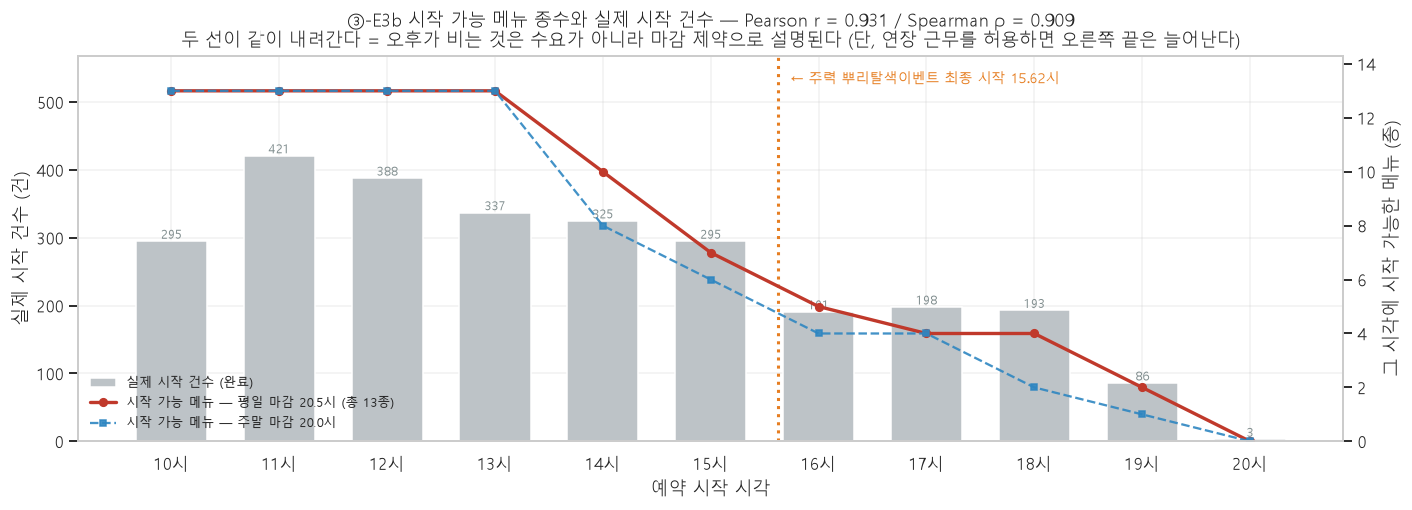

In [57]:
# ── ③-E3 그래프: 시작 가능 메뉴 종수 vs 실제 시작 건수 ────────────────────
fig, ax = plt.subplots(figsize=(13, 4.8))
_hx = FIT.index.values
ax.bar(_hx, FIT["실제 시작 건수"], width=0.66, color=C_GRAY, edgecolor="white",
       label="실제 시작 건수 (완료)")
for _x, _v in zip(_hx, FIT["실제 시작 건수"]):
    if _v:
        ax.annotate(f"{_v:,}", (_x, _v), ha="center", va="bottom", fontsize=8, color=C_DARKG)
ax.set_xlabel("예약 시작 시각"); ax.set_ylabel("실제 시작 건수 (건)")
ax.set_xticks(_hx); ax.set_xticklabels([f"{h}시" for h in _hx])
ax.set_ylim(0, FIT["실제 시작 건수"].max() * 1.35)

ax2 = ax.twinx()
ax2.plot(_hx, FIT["시작 가능 메뉴(평일, 종)"], "-o", color=C_ACC, lw=2.2, ms=5,
         label=f"시작 가능 메뉴 — 평일 마감 {CLOSE_WD}시 (총 {len(MENU_OBS)}종)")
ax2.plot(_hx, FIT["시작 가능 메뉴(주말, 종)"], "--s", color=C_SUB, lw=1.5, ms=4, alpha=0.9,
         label=f"시작 가능 메뉴 — 주말 마감 {CLOSE_WE}시")
ax2.set_ylabel("그 시각에 시작 가능한 메뉴 (종)")
ax2.set_ylim(0, len(MENU_OBS) * 1.10); ax2.grid(False)

_lastf = CLOSE_WD - DUR_OBS_MENU[FLAGSHIP[0]]
ax.axvline(_lastf, color=C_WARM, ls=":", lw=2)
ax.annotate(f"← 주력 {FLAGSHIP[0]} 최종 시작 {_lastf:.2f}시",
            (_lastf + 0.12, ax.get_ylim()[1] * 0.96),
            ha="left", va="top", fontsize=9, color=C_WARM)
_h1, _l1 = ax.get_legend_handles_labels(); _h2, _l2 = ax2.get_legend_handles_labels()
ax.legend(_h1 + _h2, _l1 + _l2, fontsize=8.5, loc="lower left", frameon=False)
_ttl = [f"③-E3b 시작 가능 메뉴 종수와 실제 시작 건수 — Pearson r = {_r_p:.3f} / Spearman ρ = {_r_s:.3f}",
        "두 선이 같이 내려간다 = 오후가 비는 것은 수요가 아니라 마감 제약으로 설명된다 "
        "(단, 연장 근무를 허용하면 오른쪽 끝은 늘어난다)"]
ax.set_title(chr(10).join(_ttl))
plt.tight_layout(); plt.show()


In [58]:
# ── ③-E4 관측 기준 최종 판정 — 결론을 미리 정하지 않는다 ─────────────────
# 판정 규칙은 ③-e 와 **같은 형태**를 쓴다. 값만 관측으로 바꾼다.
#   여유 있음  <=  하루 평균 건수 < 본인 p90  AND  판매 가능 공백 비중 > 5%
_jday = _dz_day.loc["가온 대표원장"]
CAPACITY_VERDICT_OBS = ("여유 있음" if (_jday.mean() < _jday.quantile(0.90) and _sell > 5)
                        else "포화")

VERDICT3 = pd.DataFrame([
    {"기준": "가정 A", "판매 가능 공백(%)": _aggp.loc["A", _e5],
     "월 추가 가능 하한(건)": _sum.loc["A", "하한 월평균(건)"],
     "가온 시간지표(%)": CAP_CMP.loc["가온 대표원장", "시간기준 가동률 [A](%)"], "판정": CAPACITY_VERDICT},
    {"기준": "가정 B", "판매 가능 공백(%)": _aggp.loc["B", _e5],
     "월 추가 가능 하한(건)": _sum.loc["B", "하한 월평균(건)"],
     "가온 시간지표(%)": CAP_CMP.loc["가온 대표원장", "시간기준 가동률 [B](%)"], "판정": CAPACITY_VERDICT},
    {"기준": "관측", "판매 가능 공백(%)": _sell,
     "월 추가 가능 하한(건)": float(PACK_SUM.loc[LBL_MED, "월평균(건)"]),
     "가온 시간지표(%)": float(UTIL_ADJ["가온 대표원장"]), "판정": CAPACITY_VERDICT_OBS},
]).set_index("기준")
tbl(VERDICT3.round(2), "③-E4a ★★ 세 기준의 판정 — 갈리는가")

print("█" * 92)
print(f"█ ③-E 관측 기준 캐파 판정 :  ★ {CAPACITY_VERDICT_OBS} ★"
      + ("   (가정 A·B 와 동일)" if CAPACITY_VERDICT_OBS == CAPACITY_VERDICT else "   ⚠️ 가정과 다르다"))
print("█" * 92)
print()
print("── 바뀐 것 ──")
print()
print(f"  1) 점유율의 성격이 바뀌었다. 합산 지표(가정 A "
      f"{CAP_CMP.loc['가온 대표원장','시간기준 가동률 [A](%)']:.1f}% / B "
      f"{CAP_CMP.loc['가온 대표원장','시간기준 가동률 [B](%)']:.1f}%)는 병행을 중복 계산한다.")
print(f"     구간 합집합으로 재면 가온 {UTIL_ADJ['가온 대표원장']:.1f}% 다. "
      f"**가정 논쟁 없이 이 값 하나로 정리된다.**")
print(f"  2) 그러나 평균이 낮다는 게 여유를 뜻하지 않는다 — 근무일의 {_ge4:.1f}% 가 하루 4건 이상이고")
print(f"     그런 날의 점유는 {_c3p/BIZ_HOURS*100:.0f}% 다. **3일에 1일은 이미 꽉 차 있다.**")
print(f"  3) 빈 슬롯의 성격이 갈렸다 — 판매 가능 공백 {_sell:.1f}% 중")
print(f"     주력 탈색까지 넣을 수 있는 것은 {float(_aggOp[SLOT_CATS_O[3]]):.1f}%p 뿐이고,")
print(f"     나머지 {float(_aggOp[SLOT_CATS_O[4]]):.1f}%p 는 짧은 시술만 가능하다.")
print(f"  4) 추가 수용 규모: 기존 월 {_sum.loc['B','하한 월평균(건)']:.1f}~{_sum.loc['A','상한 월평균(건)']:.1f}건 → "
      f"관측 월 {PACK_SUM.loc[LBL_MED,'월평균(건)']:.1f}~{_sum.loc['A','상한 월평균(건)']:.1f}건")
print()
print("── 안 바뀐 것 ──")
print()
print(f"  · 판정 자체는 '{CAPACITY_VERDICT_OBS}'. 가정 A·B 와 같다. 규모와 **성격**이 달라졌을 뿐이다.")
print(f"  · 병목은 여전히 **탈색 길이 x 마감** 조합이다. 관측으로 재면 제약이 더 뚜렷하다"
      f" (주력 탈색 최종 시작 평일 {CLOSE_WD - DUR_OBS_MENU[FLAGSHIP[0]]:.2f}시).")
print(f"  · 상한(실증 p90 {_sum.loc['A','상한 월평균(건)']:.1f}건/월)은 소요시간과 무관해 그대로다.")
print()
print("── 결론을 옮길 때 반드시 함께 옮길 것 ──")
print()
print(f"  1. 관측은 완료의 34.6%(945건)만 본다. 절단 편향으로 **관측값은 하한**이다.")
print(f"     → 점유율도 추가 수용 가능 건수도 실제보다 여유 있게 나온다.")
print(f"  2. 건수별 점유 곡선의 k>=3 칸은 표본이 얇다"
      f" (3건 {int((DAY_U.건수==3).sum())}일 / 4건 {int((DAY_U.건수==4).sum())}일 / 5건 {int((DAY_U.건수==5).sum())}일).")
print(f"     묶은 값 {_c3p:.2f}h 를 쓰고 칸별 값은 읽지 말 것.")
print(f"  3. **마감 20:30 은 하드 제약이 아니다.** 사장님 인터뷰에 '5시에 와도 연장 근무해서 끝까지'가 있고,")
print(f"     관측 {N_OBS:,}건 중 {OVERRUN_RATE:.1f}%가 실제로 마감 이후에, {LATE21_RATE:.1f}%가 21시 이후에 끝났다 (③-E0).")
print(f"     위 '불가'는 전부 **'연장 근무 없이는 불가'** 다. 연장을 허용하면 판매 가능 공백은 늘어난다.")
print(f"  4. 디자이너 미지정 완료 {len(_un):,}건({len(_un)/len(DONE)*100:.1f}%)의 시술자를 몰라 여유가 과대평가돼 있다.")
print(f"  5. '자리가 있다'와 '손님이 온다'는 다르다. 위 숫자는 전부 공급 측 상한이다.")
print("█" * 92)

# 산출물: 기존 SLOT(가정 A·B) 뒤에 관측 행을 덧붙인다. 기존 행은 건드리지 않는다.
_map = {SLOT_CATS[0]: SLOT_CATS_O[0], SLOT_CATS[1]: SLOT_CATS_O[1],
        SLOT_CATS[2]: SLOT_CATS_O[5], SLOT_CATS[3]: SLOT_CATS_O[2]}
_o = SLOT_O.rename(columns={v: k for k, v in _map.items()}).copy()
_o[SLOT_CATS[4]] = SLOT_O[SLOT_CATS_O[3]] + SLOT_O[SLOT_CATS_O[4]]
_o["가정"] = "관측"
_o = _o.rename(columns={"중앙 소요h(관측)": "중앙 소요h"})[["가정", "디자이너", "중앙 소요h", "근무일"] + SLOT_CATS + ["총 슬롯"]]
SLOT_ALL = pd.concat([SLOT, _o], ignore_index=True)
print(f"\ncapacity_slots.csv 에 붙일 관측 행 {len(_o)}개 준비 (기존 {len(SLOT)}행 유지)")


**③-E4a ★★ 세 기준의 판정 — 갈리는가**

,판매 가능 공백(%),월 추가 가능 하한(건),가온 시간지표(%),판정
기준,,,,
가정 A,12.26,59.55,69.91,여유 있음
가정 B,10.04,38.45,111.31,여유 있음
관측,12.79,19.60,77.77,여유 있음


████████████████████████████████████████████████████████████████████████████████████████████
█ ③-E 관측 기준 캐파 판정 :  ★ 여유 있음 ★   (가정 A·B 와 동일)
████████████████████████████████████████████████████████████████████████████████████████████

── 바뀐 것 ──

  1) 점유율의 성격이 바뀌었다. 합산 지표(가정 A 69.9% / B 111.3%)는 병행을 중복 계산한다.
     구간 합집합으로 재면 가온 77.8% 다. **가정 논쟁 없이 이 값 하나로 정리된다.**
  2) 그러나 평균이 낮다는 게 여유를 뜻하지 않는다 — 근무일의 33.1% 가 하루 4건 이상이고
     그런 날의 점유는 94% 다. **3일에 1일은 이미 꽉 차 있다.**
  3) 빈 슬롯의 성격이 갈렸다 — 판매 가능 공백 12.8% 중
     주력 탈색까지 넣을 수 있는 것은 8.6%p 뿐이고,
     나머지 4.2%p 는 짧은 시술만 가능하다.
  4) 추가 수용 규모: 기존 월 38.5~83.5건 → 관측 월 19.6~83.5건

── 안 바뀐 것 ──

  · 판정 자체는 '여유 있음'. 가정 A·B 와 같다. 규모와 **성격**이 달라졌을 뿐이다.
  · 병목은 여전히 **탈색 길이 x 마감** 조합이다. 관측으로 재면 제약이 더 뚜렷하다 (주력 탈색 최종 시작 평일 15.62시).
  · 상한(실증 p90 83.5건/월)은 소요시간과 무관해 그대로다.

── 결론을 옮길 때 반드시 함께 옮길 것 ──

  1. 관측은 완료의 34.6%(945건)만 본다. 절단 편향으로 **관측값은 하한**이다.
     → 점유율도 추가 수용 가능 건수도 실제보다 여유 있게 나온다.
  2. 건수별 점유 곡선의 k>=3 칸은 표본이 얇다 (3건 9일 / 4건 4일 / 5건 1일).
     묶은 값 9.42h


capacity_slots.csv 에 붙일 관측 행 5개 준비 (기존 10행 유지)


---
# ④ 재방문 — 신규와 어느 쪽이 이득인지 숫자로

## ④-a 재방문 고객이 매출에서 차지하는 몫

* 모집단: **완료 기준 고객** `CUST` 1,557명 (취소는 방문이 아니다)
* 방문 횟수 구간: 1회 / 2회 / 3~4회 / 5회 이상
* 매출 = 그 고객의 완료 건 `paid` 합

In [59]:
# ── ④-a1 방문 횟수 구간별 인원·매출 ────────────────────────────────────────
VBINS  = [1, 2, 3, 5, 10**6]
VLABS  = ["1회", "2회", "3~4회", "5회 이상"]
CUST["방문구간"] = pd.cut(CUST.방문횟수, bins=VBINS, labels=VLABS, right=False)

_a = (CUST.groupby("방문구간", observed=False)
          .agg(인원=("방문횟수", "size"), 매출=("누적지출", "sum"),
               방문수=("방문횟수", "sum"), 누적지출평균=("누적지출", "mean")))
_a["인원비중(%)"] = _a.인원 / len(CUST) * 100
_a["매출비중(%)"] = _a.매출 / CUST.누적지출.sum() * 100
_a["방문당 객단가"] = _a.매출 / _a.방문수
tbl(_a.round(2), f"④-a1 방문 횟수 구간별 — 완료 기준 고객 {len(CUST):,}명 · 총 {CUST.누적지출.sum():,}원")

_re = CUST[CUST.재방문]
RETAIN = pd.DataFrame([
    {"구분": "1회 방문 고객", "인원": int((CUST.방문횟수 == 1).sum()),
     "인원비중(%)": (CUST.방문횟수 == 1).mean()*100,
     "매출": int(CUST[CUST.방문횟수 == 1].누적지출.sum()),
     "매출비중(%)": CUST[CUST.방문횟수 == 1].누적지출.sum() / CUST.누적지출.sum()*100},
    {"구분": "재방문 고객(2회+)", "인원": len(_re), "인원비중(%)": len(_re)/len(CUST)*100,
     "매출": int(_re.누적지출.sum()), "매출비중(%)": _re.누적지출.sum()/CUST.누적지출.sum()*100},
]).set_index("구분")
RETAIN["1인 평균 지출"] = RETAIN.매출 / RETAIN.인원
tbl(RETAIN.round(2), "④-a2 ★ 1회 방문 vs 재방문 — 인원 비중과 매출 비중의 격차")

_gapp = RETAIN.loc["재방문 고객(2회+)", "매출비중(%)"] - RETAIN.loc["재방문 고객(2회+)", "인원비중(%)"]
print(f"재방문 고객은 인원의 {RETAIN.loc['재방문 고객(2회+)','인원비중(%)']:.2f}% 인데 "
      f"매출의 {RETAIN.loc['재방문 고객(2회+)','매출비중(%)']:.2f}% 를 낸다 (격차 {_gapp:+.2f}%p).")
print(f"1인 평균 지출: 1회 방문 {RETAIN.loc['1회 방문 고객','1인 평균 지출']:,.0f}원 vs "
      f"재방문 {RETAIN.loc['재방문 고객(2회+)','1인 평균 지출']:,.0f}원 "
      f"({RETAIN.loc['재방문 고객(2회+)','1인 평균 지출']/RETAIN.loc['1회 방문 고객','1인 평균 지출']:.2f}배)")
print()
print("⚠️ 관측 창 편향: 2026-08 에 첫 방문한 고객은 아직 재방문할 시간이 없었다.")
_recent = CUST[CUST.첫방문일 >= DONE.use_dt.max() - pd.Timedelta(days=82)]
print(f"   최근 82일 이내 첫 방문 고객 {len(_recent)}명 ({len(_recent)/len(CUST)*100:.1f}%)이 여기 해당한다.")
print(f"   이들을 빼면 재방문율은 {CUST[~CUST.index.isin(_recent.index)].재방문.mean()*100:.2f}% "
      f"(전체 {CUST.재방문.mean()*100:.2f}%)")

**④-a1 방문 횟수 구간별 — 완료 기준 고객 1,557명 · 총 308,975,650원**

,인원,매출,방문수,누적지출평균,인원비중(%),매출비중(%),방문당 객단가
방문구간,,,,,,,
1회,1146,153257500,1146,133732.55,73.60,49.60,133732.55
2회,238,64190000,476,269705.88,15.29,20.78,134852.94
3~4회,91,35580500,305,390994.51,5.84,11.52,116657.38
5회 이상,82,55947650,805,682288.41,5.27,18.11,69500.19


**④-a2 ★ 1회 방문 vs 재방문 — 인원 비중과 매출 비중의 격차**

,인원,인원비중(%),매출,매출비중(%),1인 평균 지출
구분,,,,,
1회 방문 고객,1146,73.6,153257500,49.6,133732.55
재방문 고객(2회+),411,26.4,155718150,50.4,378876.28


재방문 고객은 인원의 26.40% 인데 매출의 50.40% 를 낸다 (격차 +24.00%p).
1인 평균 지출: 1회 방문 133,733원 vs 재방문 378,876원 (2.83배)

⚠️ 관측 창 편향: 2026-08 에 첫 방문한 고객은 아직 재방문할 시간이 없었다.
   최근 82일 이내 첫 방문 고객 226명 (14.5%)이 여기 해당한다.
   이들을 빼면 재방문율은 28.55% (전체 26.40%)


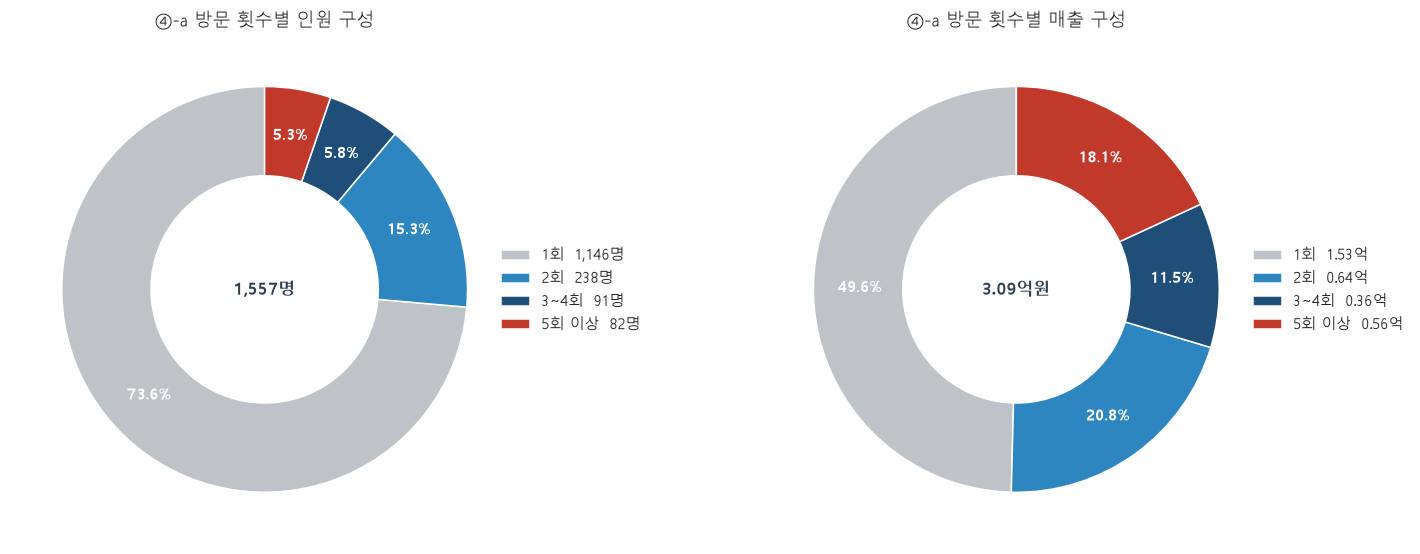

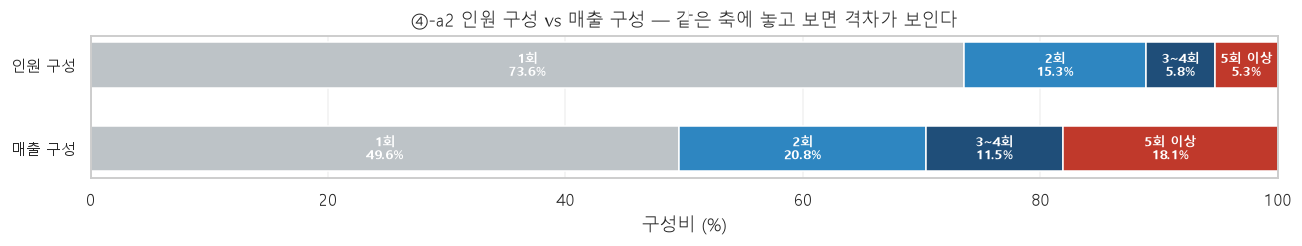

In [60]:
# ── ④-a 그래프: 방문 횟수별 인원/매출 도넛 2개 ─────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14.5, 5.2))
_cols4 = [C_GRAY, C_SUB, C_MAIN, C_ACC]
for ax, (col, ttl, unit) in zip(axes, [("인원", "인원 구성", "명"), ("매출", "매출 구성", "원")]):
    v = _a[col].reindex(VLABS)
    w, _t1, _t2 = ax.pie(v, labels=None, autopct=lambda p: f"{p:.1f}%", colors=_cols4,
                         wedgeprops={"width": 0.44, "edgecolor": "white"}, startangle=90,
                         pctdistance=0.77, textprops={"fontsize": 10, "color": "white", "weight": "bold"})
    lbls = [f"{k}  {int(v[k]):,}{unit}" if unit == "명" else f"{k}  {v[k]/1e8:.2f}억"
            for k in VLABS]
    ax.legend(w, lbls, loc="center left", bbox_to_anchor=(0.94, 0.5), fontsize=9.5, frameon=False)
    ax.set_title(f"④-a 방문 횟수별 {ttl}")
    ax.text(0, 0, f"{'1,557명' if unit=='명' else f'{CUST.누적지출.sum()/1e8:.2f}억원'}",
            ha="center", va="center", fontsize=11, weight="bold", color="#2c3e50")
plt.tight_layout(); plt.show()

# 100% 누적 가로 막대로 격차를 한 번 더
fig, ax = plt.subplots(figsize=(12, 2.4))
for i, (lab, row) in enumerate([("인원 구성", _a.인원 / _a.인원.sum() * 100),
                                ("매출 구성", _a.매출 / _a.매출.sum() * 100)]):
    left = 0
    for k, col in zip(VLABS, _cols4):
        v = row[k]
        ax.barh(i, v, left=left, color=col, height=0.55, edgecolor="white")
        if v >= 4:
            ax.annotate(f"{k}\n{v:.1f}%", (left + v/2, i), ha="center", va="center",
                        fontsize=8.5, color="white", weight="bold")
        left += v
ax.set_yticks([0, 1]); ax.set_yticklabels(["인원 구성", "매출 구성"], fontsize=10)
ax.set_xlim(0, 100); ax.set_xlabel("구성비 (%)"); ax.grid(axis="y", alpha=0)
ax.invert_yaxis()
ax.set_title("④-a2 인원 구성 vs 매출 구성 — 같은 축에 놓고 보면 격차가 보인다")
plt.tight_layout(); plt.show()

## ④-b 이탈 지점 — 몇 번째 방문에서 끊기는가

`N회 → N+1회 전환율 = (N+1회 이상 방문한 고객 수) ÷ (N회 이상 방문한 고객 수)`

**1회→2회 구간이 가장 크게 샌다면 개입 지점은 첫 방문 직후다.** 확인한다.

⚠️ **관측 창 편향**: 최근에 첫 방문한 고객은 아직 재방문할 시간이 없다.
아래에 전체 기준과, 첫 방문일이 데이터 끝에서 82일 이상 떨어진 고객만 본 기준을 **둘 다** 낸다.

In [61]:
# ── ④-b1 방문 단계별 전환율 ────────────────────────────────────────────────
CUTOFF = DONE.use_dt.max()
MATURE = CUST[CUST.첫방문일 <= CUTOFF - pd.Timedelta(days=82)]

def funnel(cu, name):
    rows = []
    for k in range(1, 6):
        a = int((cu.방문횟수 >= k).sum())
        b = int((cu.방문횟수 >= k + 1).sum())
        rows.append({"단계": f"{k}회 → {k+1}회", "N회 이상 고객": a, "N+1회 이상 고객": b,
                     "전환율(%)": b / a * 100 if a else np.nan,
                     "이탈 인원": a - b, "이탈률(%)": (a - b) / a * 100 if a else np.nan,
                     "기준": name})
    return pd.DataFrame(rows)

FUN_ALL = funnel(CUST, "전체 고객")
FUN_MAT = funnel(MATURE, f"성숙 고객만 (첫방문 ≤ {(CUTOFF - pd.Timedelta(days=82)):%Y-%m-%d})")
tbl(FUN_ALL.set_index("단계").drop(columns="기준").round(2), "④-b1a 방문 단계별 전환율 — 전체 고객")
tbl(FUN_MAT.set_index("단계").drop(columns="기준").round(2),
    f"④-b1b 방문 단계별 전환율 — 성숙 고객 {len(MATURE):,}명만 (관측 창 편향 제거)")

_worst = FUN_ALL.loc[FUN_ALL["전환율(%)"].idxmin()]
print(f"가장 크게 새는 단계: {_worst['단계']} — 전환율 {_worst['전환율(%)']:.2f}%, "
      f"이 단계에서만 {int(_worst['이탈 인원']):,}명이 끊긴다.")
print(f"성숙 고객만 봐도 1회→2회 전환율은 {FUN_MAT.iloc[0]['전환율(%)']:.2f}% 로 "
      f"전체 기준 {FUN_ALL.iloc[0]['전환율(%)']:.2f}% 와 큰 차이가 없다.")
print("→ 관측 창 편향으로 설명되지 않는다. **개입 지점은 첫 방문 직후다.**")

**④-b1a 방문 단계별 전환율 — 전체 고객**

,N회 이상 고객,N+1회 이상 고객,전환율(%),이탈 인원,이탈률(%)
단계,,,,,
1회 → 2회,1557,411,26.40,1146,73.60
2회 → 3회,411,173,42.09,238,57.91
3회 → 4회,173,114,65.90,59,34.10
4회 → 5회,114,82,71.93,32,28.07
5회 → 6회,82,65,79.27,17,20.73


**④-b1b 방문 단계별 전환율 — 성숙 고객 1,331명만 (관측 창 편향 제거)**

,N회 이상 고객,N+1회 이상 고객,전환율(%),이탈 인원,이탈률(%)
단계,,,,,
1회 → 2회,1331,380,28.55,951,71.45
2회 → 3회,380,171,45.00,209,55.00
3회 → 4회,171,114,66.67,57,33.33
4회 → 5회,114,82,71.93,32,28.07
5회 → 6회,82,65,79.27,17,20.73


가장 크게 새는 단계: 1회 → 2회 — 전환율 26.40%, 이 단계에서만 1,146명이 끊긴다.
성숙 고객만 봐도 1회→2회 전환율은 28.55% 로 전체 기준 26.40% 와 큰 차이가 없다.
→ 관측 창 편향으로 설명되지 않는다. **개입 지점은 첫 방문 직후다.**


In [62]:
# ── ④-b2 첫 시술별 전환율 ──────────────────────────────────────────────────
_rows = []
for cat in [c for c in PRIORITY if c in set(CUST.첫방문시술.dropna())]:
    cu = CUST[CUST.첫방문시술 == cat]
    if len(cu) == 0:
        continue
    r = {"첫 시술": cat, "고객수": len(cu), "평균 방문횟수": cu.방문횟수.mean(),
         "첫방문 객단가 중앙": cu.첫방문paid.median()}
    for k in range(1, 4):
        a = int((cu.방문횟수 >= k).sum()); b = int((cu.방문횟수 >= k + 1).sum())
        r[f"{k}→{k+1}회(%)"] = b / a * 100 if a else np.nan
        r[f"{k}회이상 인원"] = a
    _rows.append(r)
FUN_CAT = pd.DataFrame(_rows).set_index("첫 시술")
FUN_CAT["소표본"] = FUN_CAT.고객수.map(lambda n: small(n))
tbl(FUN_CAT.round(2), "④-b2 첫 시술별 방문 단계 전환율")

_main = FUN_CAT[FUN_CAT.고객수 >= 30]
print("표본 30명 이상 시술만 비교:")
for c, r in _main.iterrows():
    print(f"  {c:<5} 1→2회 {r['1→2회(%)']:>5.1f}%  2→3회 {r['2→3회(%)']:>5.1f}%  "
          f"3→4회 {r['3→4회(%)']:>5.1f}%   (고객 {int(r.고객수):,}명)")
print()
print(f"→ 1→2회 전환율의 시술 간 격차는 "
      f"{_main['1→2회(%)'].max() - _main['1→2회(%)'].min():.1f}%p "
      f"({_main['1→2회(%)'].idxmax()} {_main['1→2회(%)'].max():.1f}% vs "
      f"{_main['1→2회(%)'].idxmin()} {_main['1→2회(%)'].min():.1f}%)")
print(f"   2→3회 이후로는 격차가 {_main['2→3회(%)'].max() - _main['2→3회(%)'].min():.1f}%p 로 줄어든다.")
print("   즉 **어떤 시술로 처음 오느냐가 1회→2회 구간에서 대부분 결정된다.**")

**④-b2 첫 시술별 방문 단계 전환율**

,고객수,평균 방문횟수,첫방문 객단가 중앙,1→2회(%),1회이상 인원,2→3회(%),2회이상 인원,3→4회(%),3회이상 인원,소표본
첫 시술,,,,,,,,,,
탈색,1190,1.39,150000.0,22.77,1190,33.58,271,48.35,91,
펌,73,1.93,145000.0,39.73,73,34.48,29,80.00,10,
염색,149,4.05,68000.0,46.31,149,72.46,69,84.00,50,
컷,98,2.37,29000.0,31.63,98,51.61,31,87.50,16,
클리닉,20,2.00,39000.0,20.00,20,75.00,4,100.00,3,⚠소표본
스타일링,17,1.12,29000.0,11.76,17,0.00,2,,0,⚠소표본
기타,1,1.00,150000.0,0.00,1,,0,,0,⚠소표본
확인필요,9,4.78,39000.0,55.56,9,60.00,5,100.00,3,⚠소표본


표본 30명 이상 시술만 비교:
  탈색    1→2회  22.8%  2→3회  33.6%  3→4회  48.4%   (고객 1,190명)
  펌     1→2회  39.7%  2→3회  34.5%  3→4회  80.0%   (고객 73명)
  염색    1→2회  46.3%  2→3회  72.5%  3→4회  84.0%   (고객 149명)
  컷     1→2회  31.6%  2→3회  51.6%  3→4회  87.5%   (고객 98명)

→ 1→2회 전환율의 시술 간 격차는 23.5%p (염색 46.3% vs 탈색 22.8%)
   2→3회 이후로는 격차가 38.9%p 로 줄어든다.
   즉 **어떤 시술로 처음 오느냐가 1회→2회 구간에서 대부분 결정된다.**


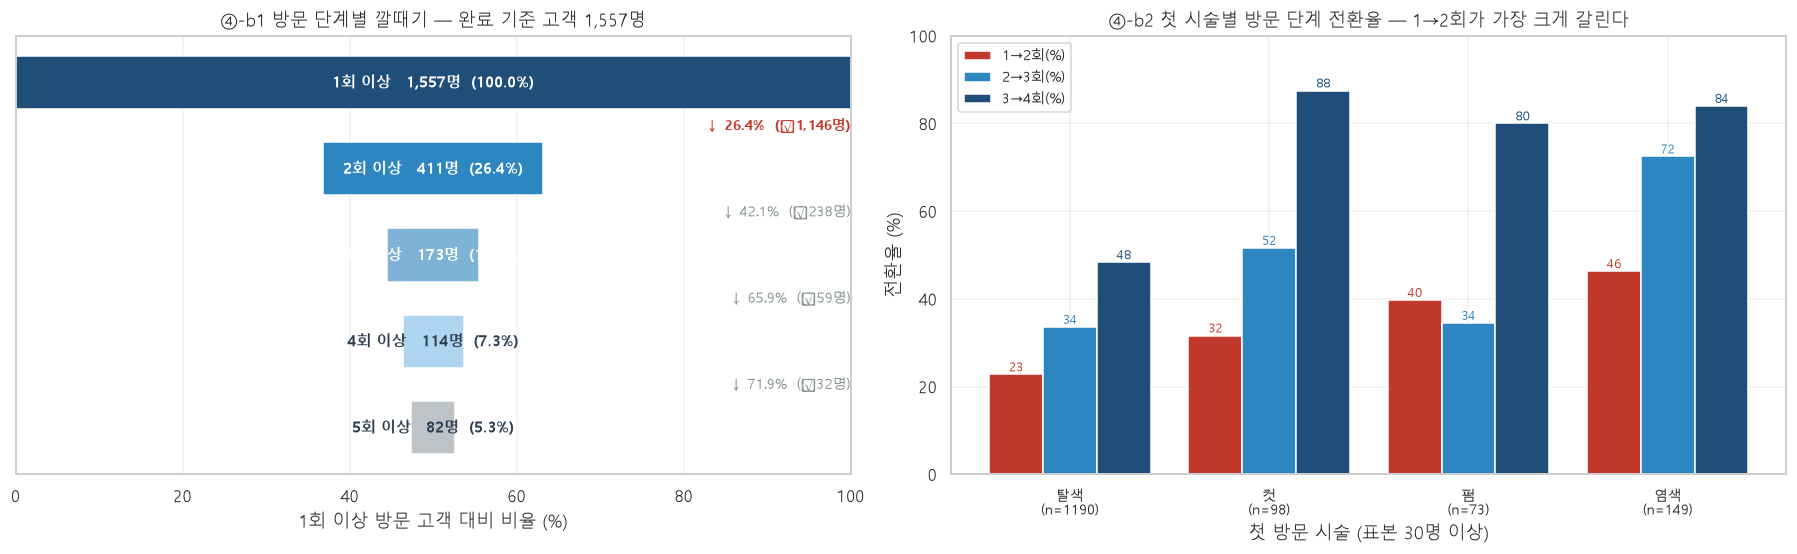

In [63]:
# ── ④-b 그래프: 방문 단계 깔때기 + 시술별 1→2회 전환 ───────────────────────
fig, axes = plt.subplots(1, 2, figsize=(16.5, 5.2))

ax = axes[0]
_stage = [int((CUST.방문횟수 >= k).sum()) for k in range(1, 6)]
_labels = [f"{k}회 이상" for k in range(1, 6)]
_wid = [s / _stage[0] * 100 for s in _stage]
for i, (w, n) in enumerate(zip(_wid, _stage)):
    ax.barh(i, w, left=(100 - w) / 2, height=0.62, color=[C_MAIN, C_SUB, "#7fb3d5", "#aed6f1", C_GRAY][i],
            edgecolor="white")
    ax.annotate(f"{_labels[i]}   {n:,}명  ({w:.1f}%)", (50, i), ha="center", va="center",
                fontsize=10, color="white" if i <= 2 else "#2c3e50", weight="bold")
    if i > 0:
        conv = _stage[i] / _stage[i-1] * 100
        ax.annotate(f"↓ {conv:.1f}%  (−{_stage[i-1]-_stage[i]:,}명)", (100, i - 0.5),
                    ha="right", va="center", fontsize=9,
                    color=C_ACC if conv == min(_stage[j]/_stage[j-1]*100 for j in range(1, 5)) else C_DARKG,
                    weight="bold" if conv == min(_stage[j]/_stage[j-1]*100 for j in range(1, 5)) else "normal")
ax.set_yticks([]); ax.set_xlim(0, 100); ax.invert_yaxis()
ax.set_xlabel("1회 이상 방문 고객 대비 비율 (%)")
ax.set_title(f"④-b1 방문 단계별 깔때기 — 완료 기준 고객 {len(CUST):,}명")
ax.grid(axis="y", alpha=0)

ax = axes[1]
_m = _main.sort_values("1→2회(%)")
_x = np.arange(len(_m)); _w = 0.27
for i, (k, col) in enumerate([("1→2회(%)", C_ACC), ("2→3회(%)", C_SUB), ("3→4회(%)", C_MAIN)]):
    off = (i - 1) * _w
    ax.bar(_x + off, _m[k], _w, color=col, label=k)
    barlab(ax, _x + off, _m[k].values, "{:.0f}", dy=2, fs=8, color=col)
ax.set_xticks(_x)
ax.set_xticklabels([f"{c}\n(n={int(_m.loc[c,'고객수'])})" for c in _m.index], fontsize=9)
ax.set_ylabel("전환율 (%)"); ax.set_xlabel("첫 방문 시술 (표본 30명 이상)")
ax.set_ylim(0, 100)
ax.set_title("④-b2 첫 시술별 방문 단계 전환율 — 1→2회가 가장 크게 갈린다")
ax.legend(fontsize=9)
plt.tight_layout(); plt.show()

## ④-c 회수 가능한 규모 — 방향 결정의 핵심 숫자

재방문 간격 중앙값이 **41.02일**이다(§0-5 게이트). 탈색·염색은 뿌리가 자라서
**생리적으로 다시 와야 하는** 시술이다. 그렇다면 안 온 고객은 수요가 사라진 게 아니라
**다른 데로 갔을 가능성**이 있다.

* **휴면 고객** = 마지막 완료 방문으로부터 **82일**(= 41.02일 × 2) 초과 경과한 고객
  (기준 시점 = 데이터 마지막 완료 방문 `2026-08-22`)
* 그들의 과거 객단가 평균 × 인원 = **회수 가능 잠재 매출 (추정)**

### ⚠️ 이 추정이 과대평가되는 세 가지 이유 — 반드시 함께 읽을 것

1. **네이버 데이터는 2025-01부터**다. 살롱은 14.5년차이므로, 2025년 초 "첫 방문"으로 잡힌 고객
   상당수는 원래 단골이었다. 그들이 이 창 밖에서 계속 다니고 있을 수도 있다.
2. **한 번 오고 말 손님이 원래 다수**다. 1회 방문 고객 1,146명 중 상당수는
   "이탈"이 아니라 애초에 일회성 수요였다(관광객·수험생 이벤트·체험단 등).
3. **회수율을 100%로 잡은 값이다.** 실제 캠페인 회수율은 훨씬 낮다.
   아래에 회수율 5% / 10% / 20% 시나리오를 함께 낸다.

In [64]:
# ── ④-c1 휴면 고객 규모 ────────────────────────────────────────────────────
GAP_MED = float(PAIRS.gap_days.median())
DORMANT_D = round(GAP_MED * 2)
CUST["경과일"] = (CUTOFF - CUST.마지막방문).dt.days
CUST["휴면"]   = CUST.경과일 > DORMANT_D
CUST["방문당객단가"] = CUST.누적지출 / CUST.방문횟수

print(f"재방문 간격 중앙값 {GAP_MED:.2f}일 → 휴면 기준 {DORMANT_D}일 (기준 시점 {CUTOFF:%Y-%m-%d})")
_dm = CUST[CUST.휴면]
_ac = CUST[~CUST.휴면]
DORM = pd.DataFrame([
    {"구분": f"휴면 ({DORMANT_D}일 초과 미방문)", "인원": len(_dm),
     "인원비중(%)": len(_dm)/len(CUST)*100,
     "과거 방문당 객단가 평균": _dm.방문당객단가.mean(),
     "과거 방문당 객단가 중앙": _dm.방문당객단가.median(),
     "누적지출 평균": _dm.누적지출.mean(), "평균 방문횟수": _dm.방문횟수.mean(),
     "평균 경과일": _dm.경과일.mean()},
    {"구분": f"활성 ({DORMANT_D}일 이내 방문)", "인원": len(_ac),
     "인원비중(%)": len(_ac)/len(CUST)*100,
     "과거 방문당 객단가 평균": _ac.방문당객단가.mean(),
     "과거 방문당 객단가 중앙": _ac.방문당객단가.median(),
     "누적지출 평균": _ac.누적지출.mean(), "평균 방문횟수": _ac.방문횟수.mean(),
     "평균 경과일": _ac.경과일.mean()},
]).set_index("구분")
tbl(DORM.round(2), f"④-c1 휴면 vs 활성 고객 — 기준 {DORMANT_D}일")

# 경과일 구간별
_eb = pd.cut(CUST.경과일, [0, 41, 82, 180, 365, 10**6], right=False,
             labels=["0~40일(활성)", "41~81일", "82~179일", "180~364일", "365일 이상"])
_et = CUST.groupby(_eb, observed=False).agg(인원=("경과일", "size"),
                                            방문당객단가평균=("방문당객단가", "mean"),
                                            평균방문횟수=("방문횟수", "mean"),
                                            누적지출합=("누적지출", "sum"))
_et["인원비중(%)"] = _et.인원 / len(CUST) * 100
tbl(_et.round(2), "④-c1b 마지막 방문 이후 경과일 구간별")

재방문 간격 중앙값 41.02일 → 휴면 기준 82일 (기준 시점 2026-08-22)


**④-c1 휴면 vs 활성 고객 — 기준 82일**

,인원,인원비중(%),과거 방문당 객단가 평균,과거 방문당 객단가 중앙,누적지출 평균,평균 방문횟수,평균 경과일
구분,,,,,,,
휴면 (82일 초과 미방문),1226,78.74,130565.18,150000.0,177766.72,1.43,307.57
활성 (82일 이내 방문),331,21.26,128268.46,119000.0,275026.13,2.96,37.28


**④-c1b 마지막 방문 이후 경과일 구간별**

,인원,방문당객단가평균,평균방문횟수,누적지출합,인원비중(%)
경과일,,,,,
0~40일(활성),173,126830.16,3.87,55444650,11.11
41~81일,158,129843.30,1.97,35589000,10.15
82~179일,298,138545.24,1.65,61284000,19.14
180~364일,504,136061.86,1.46,95633500,32.37
365일 이상,424,118422.76,1.24,61024500,27.23


In [65]:
# ── ④-c2 회수 가능 잠재 매출 (추정) + 시술별 ───────────────────────────────
_pot_1 = len(_dm) * _dm.방문당객단가.mean()
print(f"휴면 고객 {len(_dm):,}명 x 과거 방문당 객단가 평균 {_dm.방문당객단가.mean():,.0f}원")
print(f"  = 1회씩만 돌아온다고 가정한 회수 잠재 매출 {_pot_1:,.0f}원 (추정)")
print()
_scn = pd.DataFrame([
    {"회수율 가정": f"{r:.0%}", "회수 인원": len(_dm)*r,
     "1회 방문 매출(원)": len(_dm)*r*_dm.방문당객단가.mean(),
     "완료 총매출 대비(%)": len(_dm)*r*_dm.방문당객단가.mean()/DONE.paid.sum()*100,
     "월평균 환산(원, 12개월 분산)": len(_dm)*r*_dm.방문당객단가.mean()/12}
    for r in [0.05, 0.10, 0.20, 1.00]])
tbl(_scn.round(0), "④-c2a 회수율 시나리오별 — ⚠️ 전부 추정, 회수율은 데이터로 알 수 없다")

_ds = (CUST[CUST.휴면].groupby("첫방문시술")
            .agg(휴면인원=("경과일", "size"), 방문당객단가평균=("방문당객단가", "mean"),
                 평균방문횟수=("방문횟수", "mean"), 평균경과일=("경과일", "mean")))
_ds["회수 잠재(1회, 원)"] = _ds.휴면인원 * _ds.방문당객단가평균
_ds["휴면 비중(%)"] = _ds.휴면인원 / len(_dm) * 100
_all_cat = CUST.groupby("첫방문시술").size().rename("전체 인원")
_ds = _ds.join(_all_cat)
_ds["그 시술 내 휴면율(%)"] = _ds.휴면인원 / _ds["전체 인원"] * 100
_ds = _ds.reindex([c for c in PRIORITY if c in _ds.index])
_ds["소표본"] = _ds.휴면인원.map(lambda n: small(n))
tbl(_ds.round(2), "④-c2b 첫 시술별 휴면 고객")
print(f"휴면 고객 중 첫 시술이 탈색인 고객: {int(_ds.loc['탈색','휴면인원']):,}명 "
      f"({_ds.loc['탈색','휴면 비중(%)']:.2f}%)")
print(f"  탈색 고객의 휴면율 {_ds.loc['탈색','그 시술 내 휴면율(%)']:.2f}% vs "
      f"염색 {_ds.loc['염색','그 시술 내 휴면율(%)']:.2f}%")
print()
print("⚠️ 탈색이 휴면의 대부분을 차지하는 것은 단순히 **탈색 첫방문 고객이 원래 가장 많기 때문**이다")
print(f"   (전체 {len(CUST):,}명 중 탈색 {int(_all_cat['탈색']):,}명 = {_all_cat['탈색']/len(CUST)*100:.1f}%).")
print("   비중이 아니라 '그 시술 내 휴면율' 열을 봐야 시술 간 비교가 된다.")

휴면 고객 1,226명 x 과거 방문당 객단가 평균 130,565원
  = 1회씩만 돌아온다고 가정한 회수 잠재 매출 160,072,906원 (추정)



**④-c2a 회수율 시나리오별 — ⚠️ 전부 추정, 회수율은 데이터로 알 수 없다**

,회수율 가정,회수 인원,1회 방문 매출(원),완료 총매출 대비(%),"월평균 환산(원, 12개월 분산)"
0,5%,61.0,8003645.0,3.0,666970.0
1,10%,123.0,16007291.0,5.0,1333941.0
2,20%,245.0,32014581.0,10.0,2667882.0
3,100%,1226.0,160072906.0,52.0,13339409.0


**④-c2b 첫 시술별 휴면 고객**

,휴면인원,방문당객단가평균,평균방문횟수,평균경과일,"회수 잠재(1회, 원)",휴면 비중(%),전체 인원,그 시술 내 휴면율(%),소표본
첫방문시술,,,,,,,,,
탈색,928,149221.18,1.30,290.33,1.384773e+08,75.69,1190,77.98,
펌,64,124371.66,1.75,359.39,7.959786e+06,5.22,73,87.67,
염색,111,78364.43,2.27,354.57,8.698452e+06,9.05,149,74.50,
컷,84,34250.81,1.54,376.21,2.877068e+06,6.85,98,85.71,
클리닉,16,67865.45,1.94,254.44,1.085847e+06,1.31,20,80.00,⚠소표본
스타일링,16,33125.00,1.06,434.75,5.300000e+05,1.31,17,94.12,⚠소표본
기타,1,150000.00,1.00,596.00,1.500000e+05,0.08,1,100.00,⚠소표본
확인필요,6,49083.33,1.33,344.33,2.945000e+05,0.49,9,66.67,⚠소표본


휴면 고객 중 첫 시술이 탈색인 고객: 928명 (75.69%)
  탈색 고객의 휴면율 77.98% vs 염색 74.50%

⚠️ 탈색이 휴면의 대부분을 차지하는 것은 단순히 **탈색 첫방문 고객이 원래 가장 많기 때문**이다
   (전체 1,557명 중 탈색 1,190명 = 76.4%).
   비중이 아니라 '그 시술 내 휴면율' 열을 봐야 시술 간 비교가 된다.


In [66]:
# ── ④-c3 휴면 발생 시점 — 언제 대량 이탈이 있었나 ─────────────────────────
_dm2 = CUST[CUST.휴면].copy()
_dm2["마지막방문_ym"] = _dm2.마지막방문.dt.to_period("M")
_dorm_m = (_dm2.groupby("마지막방문_ym")
                .agg(휴면고객수=("경과일", "size"), 방문당객단가평균=("방문당객단가", "mean"),
                     회수잠재=("방문당객단가", "sum")))
_last_all = CUST.마지막방문.dt.to_period("M").value_counts().rename("그 달을 마지막 방문으로 둔 고객 전체")
_dorm_m = _dorm_m.join(_last_all).reindex(pd.period_range(R.ym.min(), R.ym.max(), freq="M"))
_dorm_m["휴면고객수"] = _dorm_m.휴면고객수.fillna(0).astype(int)
_dorm_m["월 완료건"] = DONE.groupby("ym").size()
tbl(_dorm_m.round(2), "④-c3 마지막 방문 월별 휴면 고객 발생")
print(f"⚠️ 최근 월({DORMANT_D}일 이내)은 아직 휴면이 될 수 없으므로 0이 나오는 것이 정상이다.")
print(f"   휴면 판정이 가능한 마지막 월: "
      f"{(CUTOFF - pd.Timedelta(days=DORMANT_D)).to_period('M')}")
_top3 = _dorm_m.휴면고객수.nlargest(3)
print(f"   휴면 고객이 가장 많이 발생한 달: " +
      " / ".join(f"{k} {int(v)}명" for k, v in _top3.items()))

**④-c3 마지막 방문 월별 휴면 고객 발생**

,휴면고객수,방문당객단가평균,회수잠재,그 달을 마지막 방문으로 둔 고객 전체,월 완료건
2025-01,62,117838.71,7306000.00,62.0,127
2025-02,75,126360.00,9477000.00,75.0,149
2025-03,53,103273.58,5473500.00,53.0,120
2025-04,38,109526.32,4162000.00,38.0,103
2025-05,49,108086.73,5296250.00,49.0,117
2025-06,51,113767.97,5802166.67,51.0,108
2025-07,53,138386.79,7334500.00,53.0,118
2025-08,65,123251.28,8011333.33,65.0,138
2025-09,39,129382.48,5045916.67,39.0,92
2025-10,83,127520.94,10584238.10,83.0,146


⚠️ 최근 월(82일 이내)은 아직 휴면이 될 수 없으므로 0이 나오는 것이 정상이다.
   휴면 판정이 가능한 마지막 월: 2026-06
   휴면 고객이 가장 많이 발생한 달: 2026-01 107명 / 2026-05 102명 / 2026-02 97명


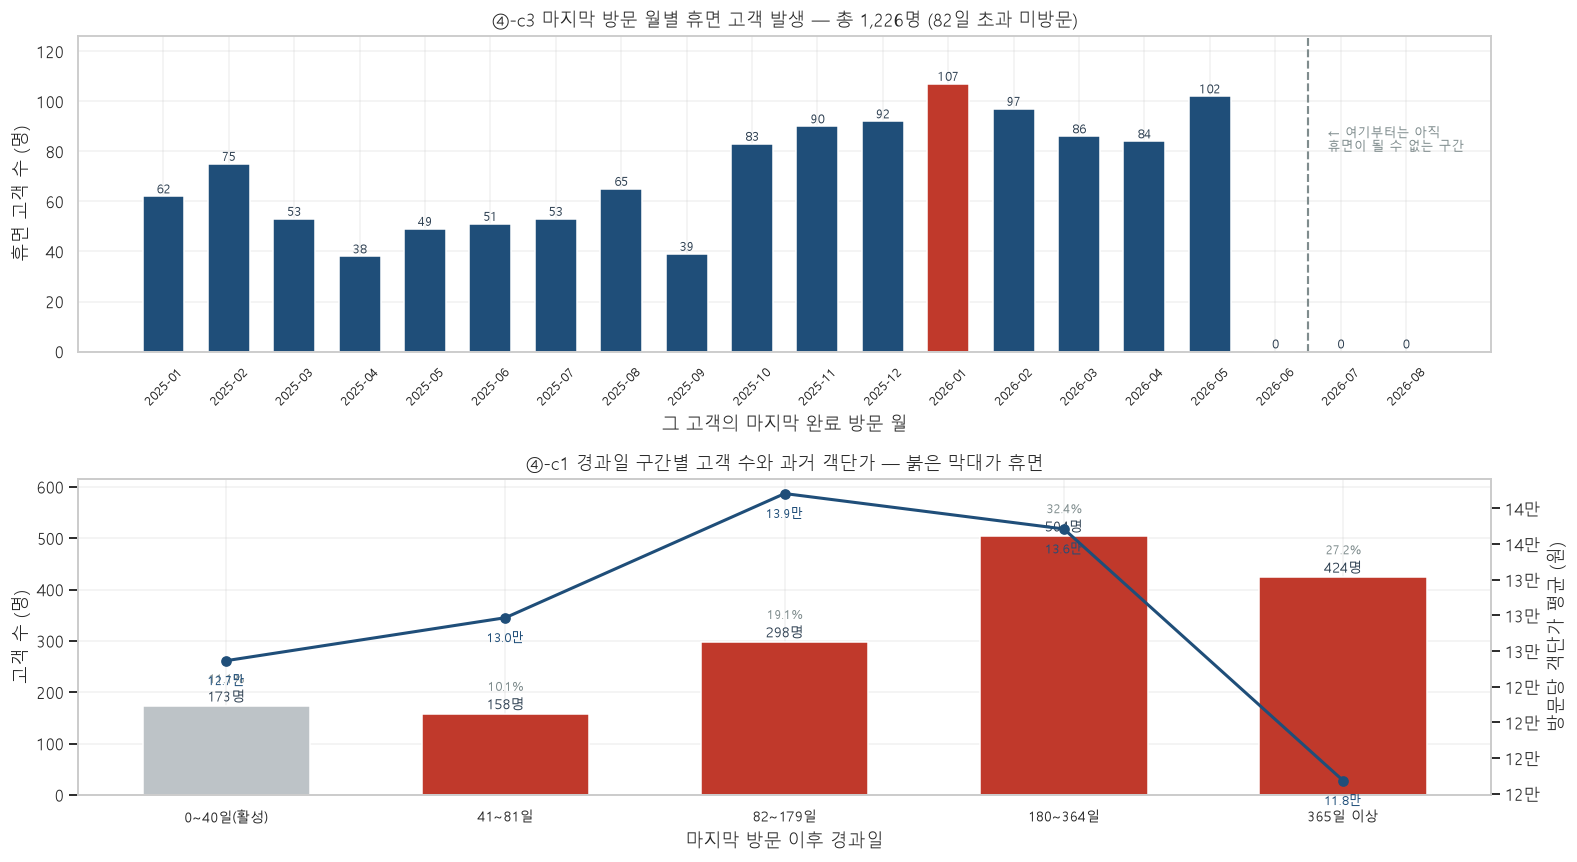

In [67]:
# ── ④-c 그래프: 휴면 고객 월별 막대 + 경과일 구간 ──────────────────────────
fig, axes = plt.subplots(2, 1, figsize=(14.5, 8), sharex=False)

ax = axes[0]
_x = np.arange(len(_dorm_m))
_cut_p = (CUTOFF - pd.Timedelta(days=DORMANT_D)).to_period("M")
_cols = [C_GRAY if p > _cut_p else (C_ACC if v == _dorm_m.휴면고객수.max() else C_MAIN)
         for p, v in zip(_dorm_m.index, _dorm_m.휴면고객수)]
ax.bar(_x, _dorm_m.휴면고객수, color=_cols, width=0.64)
barlab(ax, _x, _dorm_m.휴면고객수.values, "{:,.0f}", dy=2, fs=8)
ax.axvline(list(_dorm_m.index).index(_cut_p) + 0.5, color=C_DARKG, ls="--", lw=1.4)
ax.annotate("← 여기부터는 아직\n휴면이 될 수 없는 구간", (list(_dorm_m.index).index(_cut_p) + 0.8,
            _dorm_m.휴면고객수.max()*0.75), fontsize=8.5, color=C_DARKG)
ax.set_xticks(_x); ax.set_xticklabels([str(p) for p in _dorm_m.index], rotation=45, fontsize=8.5)
ax.set_ylabel("휴면 고객 수 (명)"); ax.set_xlabel("그 고객의 마지막 완료 방문 월")
ax.set_ylim(0, _dorm_m.휴면고객수.max()*1.18)
ax.set_title(f"④-c3 마지막 방문 월별 휴면 고객 발생 — 총 {len(_dm):,}명 ({DORMANT_D}일 초과 미방문)")

ax = axes[1]
_x2 = np.arange(len(_et))
_c2 = [C_GRAY if "활성" in str(l) else C_ACC for l in _et.index]
ax.bar(_x2, _et.인원, color=_c2, width=0.6)
barlab(ax, _x2, _et.인원.values, "{:,.0f}명", dy=3, fs=9)
for i, v in enumerate(_et["인원비중(%)"]):
    ax.annotate(f"{v:.1f}%", (i, _et.인원.iloc[i]), textcoords="offset points",
                xytext=(0, 15), ha="center", fontsize=8.5, color=C_DARKG)
ax2 = ax.twinx(); ax2.grid(False)
ax2.plot(_x2, _et.방문당객단가평균, color=C_MAIN, marker="o", lw=2, ms=6, label="방문당 객단가 평균")
for i, v in enumerate(_et.방문당객단가평균):
    ax2.annotate(f"{v/10000:.1f}만", (i, v), textcoords="offset points", xytext=(0, -16),
                 ha="center", fontsize=8.5, color=C_MAIN)
ax2.set_ylabel("방문당 객단가 평균 (원)")
ax2.yaxis.set_major_formatter(mticker.FuncFormatter(manwon))
ax.set_xticks(_x2); ax.set_xticklabels(_et.index, fontsize=9)
ax.set_ylabel("고객 수 (명)"); ax.set_xlabel("마지막 방문 이후 경과일")
ax.set_ylim(0, _et.인원.max()*1.22)
ax.set_title("④-c1 경과일 구간별 고객 수와 과거 객단가 — 붉은 막대가 휴면")
plt.tight_layout(); plt.show()

## ④-d 신규 1명 vs 재방문 1회 — 산술 비교

* **신규 고객 1명의 기대 매출** = 첫 방문 객단가 × 평균 총 방문 횟수
  (= 결국 그 고객의 누적 지출 평균과 같은 개념이므로 둘 다 낸다)
* **기존 고객이 1회 더 오는 것의 매출** = 재방문 시 평균 객단가 (2회차 이상 방문의 `paid` 평균)
* 신규 100명 유치 vs 휴면 100명 회수를 나란히

**③의 캐파 판정 결과를 그대로 반영해서 결론을 쓴다.**

In [68]:
# ── ④-d1 신규 1명 / 재방문 1회의 기대 매출 ────────────────────────────────
_first_paid_mean = CUST.첫방문paid.mean()
_visits_mean     = CUST.방문횟수.mean()
_ltv_calc        = _first_paid_mean * _visits_mean
_ltv_actual      = CUST.누적지출.mean()

_seq = DONE.sort_values(["cust_key", "use_dt"]).copy()
_seq["n_th"] = _seq.groupby("cust_key").cumcount() + 1
_repeat_visits = _seq[_seq.n_th >= 2]

UNIT = pd.DataFrame([
    {"항목": "신규 고객 1명 — 첫 방문 객단가 평균", "값(원)": _first_paid_mean,
     "산출": "CUST.첫방문paid 평균"},
    {"항목": "신규 고객 1명 — 평균 총 방문 횟수", "값(원)": _visits_mean,
     "산출": "CUST.방문횟수 평균 (단위: 회)"},
    {"항목": "신규 고객 1명 기대 매출 [곱셈식]", "값(원)": _ltv_calc,
     "산출": "첫방문 객단가 평균 x 평균 방문 횟수"},
    {"항목": "신규 고객 1명 기대 매출 [실측]", "값(원)": _ltv_actual,
     "산출": "CUST.누적지출 평균 — 이쪽이 실제값"},
    {"항목": "기존 고객이 1회 더 올 때 매출", "값(원)": _repeat_visits.paid.mean(),
     "산출": f"2회차 이상 방문 {len(_repeat_visits):,}건의 paid 평균"},
    {"항목": "기존 고객이 1회 더 올 때 매출 [중앙값]", "값(원)": _repeat_visits.paid.median(),
     "산출": "같은 모집단의 중앙값"},
    {"항목": "휴면 고객 1명이 1회 돌아올 때 매출", "값(원)": _dm.방문당객단가.mean(),
     "산출": "휴면 고객의 과거 방문당 객단가 평균"},
]).set_index("항목")
tbl(UNIT.round(2), "④-d1 단위 경제 — 신규 1명 vs 재방문 1회")

print(f"⚠️ 곱셈식 {_ltv_calc:,.0f}원 vs 실측 {_ltv_actual:,.0f}원 — 차이 {_ltv_actual - _ltv_calc:+,.0f}원")
print("   곱셈식이 틀리는 이유: 첫 방문 객단가와 방문 횟수가 **음의 상관**이기 때문이다.")
print("   (01번 ⑤-1: 첫 방문 5만 미만 재방문율 42.35% vs 9~12만 19.57%)")
print("   → 아래 비교에는 **실측 누적지출 평균**을 쓴다.")
print()
print(f"재방문 1회 매출 {_repeat_visits.paid.mean():,.0f}원 vs 신규 1명 LTV {_ltv_actual:,.0f}원")
print(f"  → 신규 1명 = 재방문 {_ltv_actual/_repeat_visits.paid.mean():.2f}회분")

**④-d1 단위 경제 — 신규 1명 vs 재방문 1회**

,값(원),산출
항목,,
신규 고객 1명 — 첫 방문 객단가 평균,131410.40,CUST.첫방문paid 평균
신규 고객 1명 — 평균 총 방문 횟수,1.75,CUST.방문횟수 평균 (단위: 회)
신규 고객 1명 기대 매출 [곱셈식],230580.11,첫방문 객단가 평균 x 평균 방문 횟수
신규 고객 1명 기대 매출 [실측],198442.94,CUST.누적지출 평균 — 이쪽이 실제값
기존 고객이 1회 더 올 때 매출,88825.23,"2회차 이상 방문 1,175건의 paid 평균"
기존 고객이 1회 더 올 때 매출 [중앙값],87000.00,같은 모집단의 중앙값
휴면 고객 1명이 1회 돌아올 때 매출,130565.18,휴면 고객의 과거 방문당 객단가 평균


⚠️ 곱셈식 230,580원 vs 실측 198,443원 — 차이 -32,137원
   곱셈식이 틀리는 이유: 첫 방문 객단가와 방문 횟수가 **음의 상관**이기 때문이다.
   (01번 ⑤-1: 첫 방문 5만 미만 재방문율 42.35% vs 9~12만 19.57%)
   → 아래 비교에는 **실측 누적지출 평균**을 쓴다.

재방문 1회 매출 88,825원 vs 신규 1명 LTV 198,443원
  → 신규 1명 = 재방문 2.23회분


In [69]:
# ── ④-d2 신규 100명 vs 휴면 100명 회수 — 나란히 ───────────────────────────
_new100 = 100 * _ltv_actual
_new100_first = 100 * _first_paid_mean
_dorm100 = 100 * _dm.방문당객단가.mean()
# 회수된 휴면 고객이 그 뒤로도 다니는가? — 재방문 고객의 잔여 가치로 근사
_dorm100_multi = 100 * _dm.방문당객단가.mean() * FUN_ALL.iloc[1]["전환율(%)"] / 100 * 2  # 보수적 근사

COMPARE = pd.DataFrame([
    {"방향": "신규 고객 100명 유치", "즉시 매출(원)": _new100_first,
     "생애 누적 기대 매출(원)": _new100,
     "필요 방문 유도": "100명 x 평균 1.75회 방문",
     "캐파 필요(건/월, 12개월 분산)": 100 * _visits_mean / 12,
     "근거": "CUST 누적지출 평균 x 100"},
    {"방향": f"휴면 고객 100명 회수 (1회)", "즉시 매출(원)": _dorm100,
     "생애 누적 기대 매출(원)": _dorm100,
     "필요 방문 유도": "100명 x 1회",
     "캐파 필요(건/월, 12개월 분산)": 100 / 12,
     "근거": "휴면 고객 과거 방문당 객단가 평균 x 100"},
    {"방향": "휴면 고객 100명 회수 후 1회 더", "즉시 매출(원)": _dorm100,
     "생애 누적 기대 매출(원)": _dorm100 * 2,
     "필요 방문 유도": "100명 x 2회",
     "캐파 필요(건/월, 12개월 분산)": 200 / 12,
     "근거": "위 x 2 — ⚠️ 회수 후 재정착률은 데이터로 알 수 없다"},
]).set_index("방향")
tbl(COMPARE.round(0), "④-d2 ★ 신규 100명 vs 휴면 100명 회수 — 매출 효과 비교 (추정)")

print("읽는 법:")
print(f"  · 신규 100명 유치 시 즉시 매출은 {_new100_first:,.0f}원(첫 방문분)이고,")
print(f"    그들이 평균 {_visits_mean:.2f}회 오면 누적 {_new100:,.0f}원이 된다.")
print(f"  · 휴면 100명 회수는 1회분 {_dorm100:,.0f}원. 신규 100명 첫 방문분의 "
      f"{_dorm100/_new100_first*100:.0f}% 수준이다.")
print(f"  · 휴면 고객의 방문당 객단가({_dm.방문당객단가.mean():,.0f}원)가 "
      f"신규 첫 방문 객단가({_first_paid_mean:,.0f}원)보다 "
      f"{'높다' if _dm.방문당객단가.mean() > _first_paid_mean else '낮다'}.")
print()
print("⚠️ 획득 비용은 이 표에 없다. 매출 효과만 비교한 것이다.")
print("   휴면 회수는 연락처를 이미 갖고 있어 비용이 거의 0인 반면, 신규 유치는 노출 비용이 든다.")
print("   비용까지 넣으면 휴면 회수 쪽이 유리해지지만, 회수율을 모르므로 ROI 계산은 하지 않는다.")

**④-d2 ★ 신규 100명 vs 휴면 100명 회수 — 매출 효과 비교 (추정)**

,즉시 매출(원),생애 누적 기대 매출(원),필요 방문 유도,"캐파 필요(건/월, 12개월 분산)",근거
방향,,,,,
신규 고객 100명 유치,13141040.0,19844294.0,100명 x 평균 1.75회 방문,15.0,CUST 누적지출 평균 x 100
휴면 고객 100명 회수 (1회),13056518.0,13056518.0,100명 x 1회,8.0,휴면 고객 과거 방문당 객단가 평균 x 100
휴면 고객 100명 회수 후 1회 더,13056518.0,26113035.0,100명 x 2회,17.0,위 x 2 — ⚠️ 회수 후 재정착률은 데이터로 알 수 없다


읽는 법:
  · 신규 100명 유치 시 즉시 매출은 13,141,040원(첫 방문분)이고,
    그들이 평균 1.75회 오면 누적 19,844,294원이 된다.
  · 휴면 100명 회수는 1회분 13,056,518원. 신규 100명 첫 방문분의 99% 수준이다.
  · 휴면 고객의 방문당 객단가(130,565원)가 신규 첫 방문 객단가(131,410원)보다 낮다.

⚠️ 획득 비용은 이 표에 없다. 매출 효과만 비교한 것이다.
   휴면 회수는 연락처를 이미 갖고 있어 비용이 거의 0인 반면, 신규 유치는 노출 비용이 든다.
   비용까지 넣으면 휴면 회수 쪽이 유리해지지만, 회수율을 모르므로 ROI 계산은 하지 않는다.


In [70]:
# ── ④-d3 ③의 캐파 판정과 연결 ─────────────────────────────────────────────
_lowA = _sum.loc["A", "하한 월평균(건)"]; _upA = _sum.loc["A", "상한 월평균(건)"]
_lowB = _sum.loc["B", "하한 월평균(건)"]; _upB = _sum.loc["B", "상한 월평균(건)"]
_cur  = len(DONE) / N_MONTHS

print("=" * 96)
print("④-d3 ③의 캐파 판정을 반영한 방향 결론")
print("=" * 96)
print(f"③의 판정: 캐파에 **{CAPACITY_VERDICT}**")
print(f"  추가 수용 가능 규모(추정): 가정A 월 {_lowA:.1f}~{_upA:.1f}건 / 가정B 월 {_lowB:.1f}~{_upB:.1f}건")
print(f"  현재 월평균 완료 {_cur:.1f}건")
print()
if CAPACITY_VERDICT == "여유 있음":
    print("→ **신규 유치는 유효한 선택지다.** 자리가 없어서 못 받는 상황이 아니다.")
    print(f"   가장 보수적인 하한(가정B, 월 {_lowB:.1f}건)만 잡아도 현재 대비 "
          f"+{_lowB/_cur*100:.0f}% 를 더 받을 수 있다.")
    print()
    print("   다만 신규와 재방문 회수는 **배타적이지 않다.** 같은 빈 자리를 두고 경쟁한다.")
    print("   같은 1건을 채운다면 어느 쪽이 유리한지가 실제 질문이다:")
    print(f"     · 신규 첫 방문 1건 = {_first_paid_mean:,.0f}원, 그 뒤 평균 {_visits_mean-1:.2f}회 더 옴")
    print(f"     · 휴면 회수 1건   = {_dm.방문당객단가.mean():,.0f}원, 그 뒤는 미지")
    _diff = _dm.방문당객단가.mean() - _first_paid_mean
    print(f"     → 1건당 매출 차이 {_diff:+,.0f}원 "
          f"({'휴면 회수' if _diff > 0 else '신규'} 쪽이 건당 매출은 높다)")
    print()
    print("   결정적 차이는 **비용과 확실성**이다:")
    print("     · 휴면 회수 — 연락처 보유, 비용 거의 0, 그러나 회수율 미지 (측정된 적 없음)")
    print("     · 신규 유치 — 노출 비용 발생, 그러나 유입 경로가 이미 검증됨(① 참조)")
else:
    print("→ 캐파가 포화이므로 신규 유치보다 객단가 상승·재방문 회수가 우선이다.")
print("=" * 96)

④-d3 ③의 캐파 판정을 반영한 방향 결론
③의 판정: 캐파에 **여유 있음**
  추가 수용 가능 규모(추정): 가정A 월 59.5~83.5건 / 가정B 월 38.5~83.5건
  현재 월평균 완료 136.6건

→ **신규 유치는 유효한 선택지다.** 자리가 없어서 못 받는 상황이 아니다.
   가장 보수적인 하한(가정B, 월 38.5건)만 잡아도 현재 대비 +28% 를 더 받을 수 있다.

   다만 신규와 재방문 회수는 **배타적이지 않다.** 같은 빈 자리를 두고 경쟁한다.
   같은 1건을 채운다면 어느 쪽이 유리한지가 실제 질문이다:
     · 신규 첫 방문 1건 = 131,410원, 그 뒤 평균 0.75회 더 옴
     · 휴면 회수 1건   = 130,565원, 그 뒤는 미지
     → 1건당 매출 차이 -845원 (신규 쪽이 건당 매출은 높다)

   결정적 차이는 **비용과 확실성**이다:
     · 휴면 회수 — 연락처 보유, 비용 거의 0, 그러나 회수율 미지 (측정된 적 없음)
     · 신규 유치 — 노출 비용 발생, 그러나 유입 경로가 이미 검증됨(① 참조)


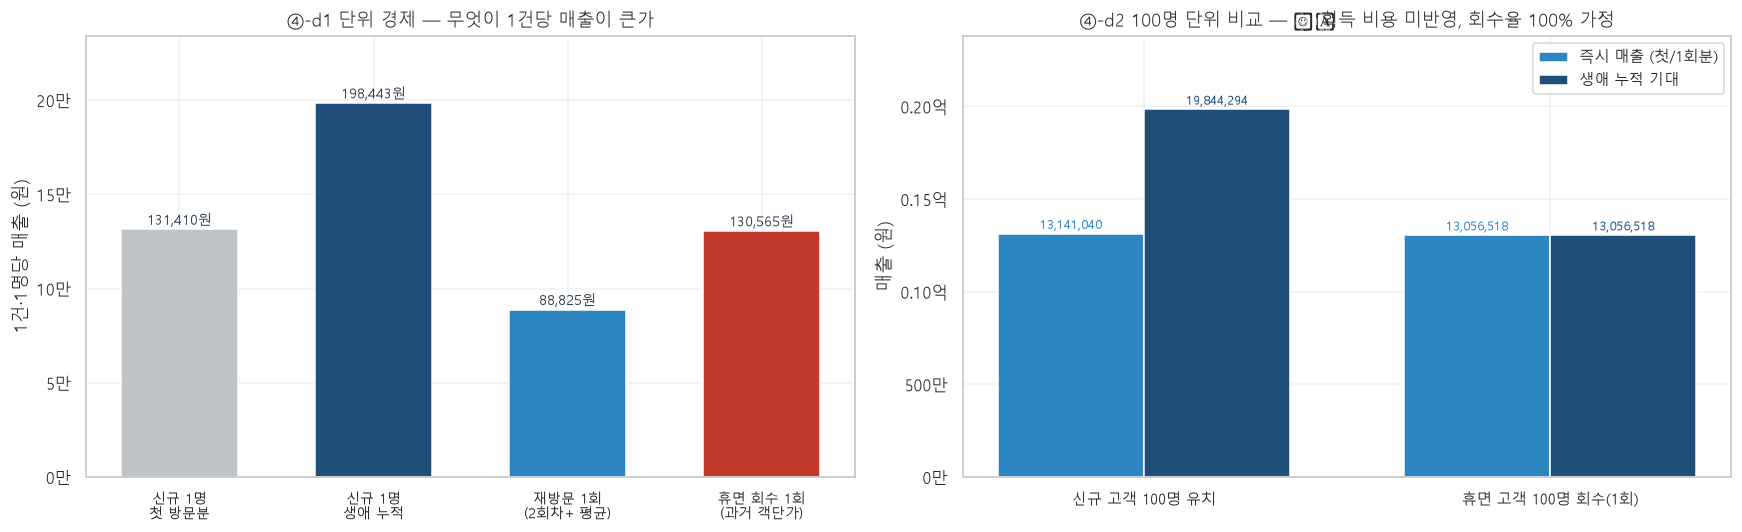

In [71]:
# ── ④-d 그래프: 신규 vs 재방문 매출 효과 grouped bar ──────────────────────
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

ax = axes[0]
_items = ["신규 1명\n첫 방문분", "신규 1명\n생애 누적", "재방문 1회\n(2회차+ 평균)", "휴면 회수 1회\n(과거 객단가)"]
_vals  = [_first_paid_mean, _ltv_actual, _repeat_visits.paid.mean(), _dm.방문당객단가.mean()]
_cols  = [C_GRAY, C_MAIN, C_SUB, C_ACC]
ax.bar(range(4), _vals, color=_cols, width=0.6)
barlab(ax, range(4), _vals, "{:,.0f}원", dy=3, fs=9)
ax.set_xticks(range(4)); ax.set_xticklabels(_items, fontsize=9)
ax.set_ylabel("1건·1명당 매출 (원)")
ax.yaxis.set_major_formatter(mticker.FuncFormatter(manwon))
ax.set_ylim(0, max(_vals)*1.18)
ax.set_title("④-d1 단위 경제 — 무엇이 1건당 매출이 큰가")

ax = axes[1]
_x = np.arange(2); _w = 0.36
_now = [_new100_first, _dorm100]
_life = [_new100, _dorm100]
ax.bar(_x - _w/2, _now, _w, color=C_SUB, label="즉시 매출 (첫/1회분)")
ax.bar(_x + _w/2, _life, _w, color=C_MAIN, label="생애 누적 기대")
barlab(ax, _x - _w/2, _now, "{:,.0f}", dy=3, fs=8.5, color=C_SUB)
barlab(ax, _x + _w/2, _life, "{:,.0f}", dy=3, fs=8.5, color=C_MAIN)
ax.set_xticks(_x); ax.set_xticklabels(["신규 고객 100명 유치", "휴면 고객 100명 회수(1회)"], fontsize=10)
ax.set_ylabel("매출 (원)")
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, p: f"{v/1e8:.2f}억" if v >= 1e7 else f"{v/1e4:.0f}만"))
ax.set_ylim(0, max(_life)*1.2)
ax.set_title("④-d2 100명 단위 비교 — ⚠️ 획득 비용 미반영, 회수율 100% 가정")
ax.legend(fontsize=9.5)
plt.tight_layout(); plt.show()

## ④-e 첫방문 50%할인 채널의 재방문 문제 — 매출 관점

02번 ⑤-8과 이어진다. 거기서는 "재방문 할인 인지" 관점으로 봤고, **여기서는 매출 관점으로만** 본다.

* 이 채널로 첫 방문한 고객의 **누적 지출** vs 일반 채널 고객의 누적 지출
* **할인으로 깎인 금액 총합** vs 그들이 이후 가져온 매출
* 할인이 회수됐는가

### ⚠️ "깎인 금액"의 추정 방법

`paid` 에는 **이미 할인이 반영된 금액**이 들어 있고, 정가 필드는 없다.
그래서 "할인 전 정가"를 두 가지로 추정한다.

1. **50% 가정** — 이 채널이 "첫방문 50%할인"이므로 정가 = `paid × 2`, 깎인 금액 = `paid`
2. **동종 시술 비교** — 같은 대표시술을 일반 채널에서 받은 완료 건의 객단가 중앙값을 정가로 봄

두 값이 크게 다르면 "50% 할인"이 실제로는 전액에 적용되지 않는다는 뜻이다. 둘 다 낸다.

In [72]:
# ── ④-e1 할인 채널 첫방문 고객의 누적 지출 ────────────────────────────────
_f50c = CUST[CUST.첫방문_f50]
_norc = CUST[~CUST.첫방문_f50]
E1 = pd.DataFrame([
    {"구분": "첫방문 50%할인 채널로 첫 방문", "인원": len(_f50c),
     "첫방문 paid 중앙": _f50c.첫방문paid.median(), "첫방문 paid 평균": _f50c.첫방문paid.mean(),
     "평균 방문횟수": _f50c.방문횟수.mean(), "재방문율(%)": _f50c.재방문.mean()*100,
     "누적지출 평균": _f50c.누적지출.mean(), "누적지출 중앙": _f50c.누적지출.median(),
     "누적지출 합계": _f50c.누적지출.sum()},
    {"구분": "일반 채널로 첫 방문", "인원": len(_norc),
     "첫방문 paid 중앙": _norc.첫방문paid.median(), "첫방문 paid 평균": _norc.첫방문paid.mean(),
     "평균 방문횟수": _norc.방문횟수.mean(), "재방문율(%)": _norc.재방문.mean()*100,
     "누적지출 평균": _norc.누적지출.mean(), "누적지출 중앙": _norc.누적지출.median(),
     "누적지출 합계": _norc.누적지출.sum()},
]).set_index("구분")
tbl(E1.round(2), "④-e1 첫방문 채널별 누적 지출 (02번 ⑤-8b와 같은 모집단)")
assert round(float(_f50c.재방문.mean()*100), 2) == 32.94, "02번 ⑤-8b 재방문율과 불일치"
assert round(float(_norc.재방문.mean()*100), 2) == 25.59, "02번 ⑤-8b 재방문율과 불일치"
print("02번 ⑤-8b 재방문율(32.94% / 25.59%)과 일치 확인.")
print()
print(f"할인 채널 첫방문 고객은 재방문율이 {_f50c.재방문.mean()*100 - _norc.재방문.mean()*100:+.2f}%p 높지만,")
print(f"누적지출 평균은 {_f50c.누적지출.mean() - _norc.누적지출.mean():+,.0f}원이다.")
print("→ 더 자주 오지만 한 번에 쓰는 금액이 작다.")

**④-e1 첫방문 채널별 누적 지출 (02번 ⑤-8b와 같은 모집단)**

,인원,첫방문 paid 중앙,첫방문 paid 평균,평균 방문횟수,재방문율(%),누적지출 평균,누적지출 중앙,누적지출 합계
구분,,,,,,,,
첫방문 50%할인 채널로 첫 방문,170,100000.0,119132.35,1.75,32.94,192285.29,150000.0,32688500
일반 채널로 첫 방문,1387,150000.0,132915.28,1.76,25.59,199197.66,150000.0,276287150


02번 ⑤-8b 재방문율(32.94% / 25.59%)과 일치 확인.

할인 채널 첫방문 고객은 재방문율이 +7.35%p 높지만,
누적지출 평균은 -6,912원이다.
→ 더 자주 오지만 한 번에 쓰는 금액이 작다.


In [73]:
# ── ④-e2 할인으로 깎인 금액 추정 vs 이후 가져온 매출 ──────────────────────
_f50_res = DONE[DONE.designer.str.contains(F50, na=False)]
print(f"할인 채널 완료 예약: {len(_f50_res):,}건 · paid 합계 {_f50_res.paid.sum():,}원")
print()

# 방법 1: 50% 가정
_disc_50 = _f50_res.paid.sum()

# 방법 2: 동종 시술 비교
_norm_med = DONE[~DONE.designer.str.contains(F50, na=False)].groupby("rep_cat").paid.median()
_f50_res = _f50_res.copy()
_f50_res["일반채널 동종 중앙값"] = _f50_res.rep_cat.map(_norm_med)
_f50_res["차액"] = _f50_res["일반채널 동종 중앙값"] - _f50_res.paid
_disc_cmp = float(_f50_res.차액.clip(lower=0).sum())

_by_cat = (_f50_res.groupby("rep_cat")
                   .agg(건수=("예약번호", "size"), 할인가_중앙=("paid", "median"),
                        일반채널_중앙=("일반채널 동종 중앙값", "first"),
                        차액합=("차액", lambda s: s.clip(lower=0).sum()))
                   .reindex([c for c in PRIORITY if c in set(_f50_res.rep_cat)]))
_by_cat["실질 할인율(%)"] = (1 - _by_cat.할인가_중앙 / _by_cat.일반채널_중앙) * 100
_by_cat["소표본"] = _by_cat.건수.map(lambda n: small(n))
tbl(_by_cat.round(2), "④-e2a 할인 채널 vs 일반 채널 — 대표시술별 객단가 비교")

# 그들이 이후(2회차 이상) 가져온 매출
_c50_ids = set(_f50c.index)
_after = DONE[DONE.cust_key.isin(_c50_ids)].sort_values("use_dt").copy()
_after["n_th"] = _after.groupby("cust_key").cumcount() + 1
_later = _after[_after.n_th >= 2]

E2 = pd.DataFrame([
    {"항목": "① 할인으로 깎인 금액 [50% 가정]", "금액(원)": _disc_50,
     "산출": f"할인채널 완료 {len(_f50_res):,}건의 paid 합 = 정가의 절반이라 가정"},
    {"항목": "① 할인으로 깎인 금액 [동종 시술 비교]", "금액(원)": _disc_cmp,
     "산출": "일반채널 동종 대표시술 객단가 중앙값 − 실제 paid, 음수는 0 처리"},
    {"항목": "② 할인채널 첫방문 고객의 1회차 매출", "금액(원)": _f50c.첫방문paid.sum(),
     "산출": f"{len(_f50c)}명의 첫 완료 방문 paid 합"},
    {"항목": "③ 그들이 2회차 이후 가져온 매출", "금액(원)": _later.paid.sum(),
     "산출": f"같은 고객의 2회차 이상 완료 {len(_later):,}건 paid 합"},
    {"항목": "④ 누적 총매출 (② + ③)", "금액(원)": _f50c.누적지출.sum(),
     "산출": "CUST.누적지출 합계"},
]).set_index("항목")
tbl(E2.round(0), "④-e2b 할인 투입 vs 회수 (추정)")

print("── 회수 판정 ──")
for lab, d in [("50% 가정", _disc_50), ("동종 시술 비교", _disc_cmp)]:
    net = _f50c.누적지출.sum() - d
    roi = _later.paid.sum() / d if d else np.nan
    print(f"  [{lab}] 깎인 금액 {d:,.0f}원")
    print(f"       2회차 이후 매출 {_later.paid.sum():,.0f}원 → 깎인 금액 대비 {roi*100:.1f}%")
    print(f"       {'회수됨' if _later.paid.sum() >= d else '★ 미회수'} "
          f"(2회차 이후 매출만으로는 {'충당됨' if _later.paid.sum() >= d else f'{d - _later.paid.sum():,.0f}원 부족'})")
print()
print("⚠️ 이 판정의 한계")
print("   · 정가 필드가 없어 '깎인 금액'은 전부 추정이다. 두 방법의 값이 다르다.")
print("   · 할인이 없었다면 그 고객이 아예 안 왔을 수도 있다. 그렇다면 기회비용은 0이다.")
print("   · 관측 창이 20개월뿐이라 2026년에 첫 방문한 고객의 이후 매출은 아직 다 안 나왔다.")
print(f"   · 할인 채널 첫방문 고객 {len(_f50c)}명 중 "
      f"{int((_f50c.첫방문일 > CUTOFF - pd.Timedelta(days=180)).sum())}명이 최근 6개월 내 첫 방문이다.")

할인 채널 완료 예약: 218건 · paid 합계 22,952,500원



**④-e2a 할인 채널 vs 일반 채널 — 대표시술별 객단가 비교**

,건수,할인가_중앙,일반채널_중앙,차액합,실질 할인율(%),소표본
rep_cat,,,,,,
탈색,118,150000.0,150000.0,2293000.0,0.00,
펌,13,87000.0,145000.0,590500.0,40.00,⚠소표본
염색,46,39000.0,39000.0,3000.0,0.00,
컷,25,29000.0,29000.0,48000.0,0.00,⚠소표본
클리닉,9,58000.0,39000.0,8000.0,-48.72,⚠소표본
스타일링,3,35000.0,29000.0,0.0,-20.69,⚠소표본
확인필요,4,39000.0,39000.0,0.0,0.00,⚠소표본


**④-e2b 할인 투입 vs 회수 (추정)**

,금액(원),산출
항목,,
① 할인으로 깎인 금액 [50% 가정],22952500.0,할인채널 완료 218건의 paid 합 = 정가의 절반이라 가정
① 할인으로 깎인 금액 [동종 시술 비교],2942500.0,"일반채널 동종 대표시술 객단가 중앙값 − 실제 paid, 음수는 0 처리"
② 할인채널 첫방문 고객의 1회차 매출,20252500.0,170명의 첫 완료 방문 paid 합
③ 그들이 2회차 이후 가져온 매출,12436000.0,같은 고객의 2회차 이상 완료 127건 paid 합
④ 누적 총매출 (② + ③),32688500.0,CUST.누적지출 합계


── 회수 판정 ──
  [50% 가정] 깎인 금액 22,952,500원
       2회차 이후 매출 12,436,000원 → 깎인 금액 대비 54.2%
       ★ 미회수 (2회차 이후 매출만으로는 10,516,500원 부족)
  [동종 시술 비교] 깎인 금액 2,942,500원
       2회차 이후 매출 12,436,000원 → 깎인 금액 대비 422.6%
       회수됨 (2회차 이후 매출만으로는 충당됨)

⚠️ 이 판정의 한계
   · 정가 필드가 없어 '깎인 금액'은 전부 추정이다. 두 방법의 값이 다르다.
   · 할인이 없었다면 그 고객이 아예 안 왔을 수도 있다. 그렇다면 기회비용은 0이다.
   · 관측 창이 20개월뿐이라 2026년에 첫 방문한 고객의 이후 매출은 아직 다 안 나왔다.
   · 할인 채널 첫방문 고객 170명 중 41명이 최근 6개월 내 첫 방문이다.


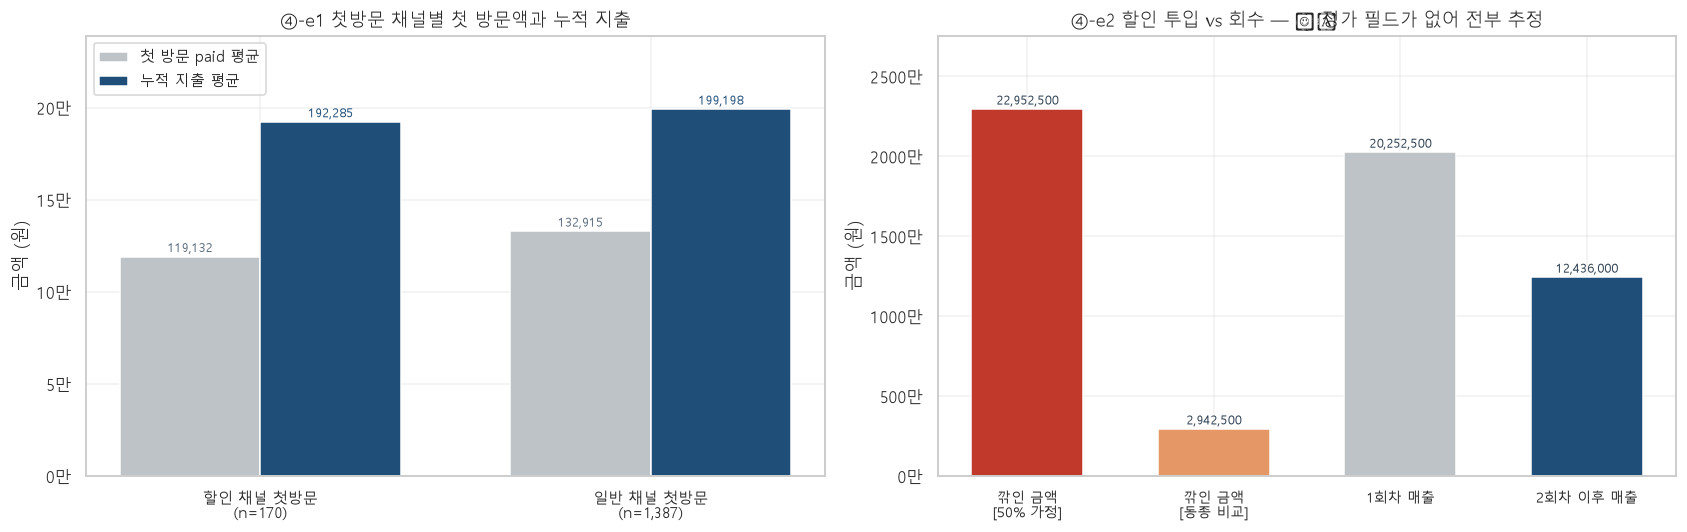

In [74]:
# ── ④-e 그래프: 할인 채널 회수 ─────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(15.5, 5))

ax = axes[0]
_x = np.arange(2); _w = 0.36
_a1 = [E1.loc["첫방문 50%할인 채널로 첫 방문", "첫방문 paid 평균"],
       E1.loc["일반 채널로 첫 방문", "첫방문 paid 평균"]]
_a2 = [E1.loc["첫방문 50%할인 채널로 첫 방문", "누적지출 평균"],
       E1.loc["일반 채널로 첫 방문", "누적지출 평균"]]
ax.bar(_x - _w/2, _a1, _w, color=C_GRAY, label="첫 방문 paid 평균")
ax.bar(_x + _w/2, _a2, _w, color=C_MAIN, label="누적 지출 평균")
barlab(ax, _x - _w/2, _a1, "{:,.0f}", dy=3, fs=8.5, color="#5d6d7e")
barlab(ax, _x + _w/2, _a2, "{:,.0f}", dy=3, fs=8.5, color=C_MAIN)
ax.set_xticks(_x)
ax.set_xticklabels([f"할인 채널 첫방문\n(n={len(_f50c)})", f"일반 채널 첫방문\n(n={len(_norc):,})"], fontsize=9.5)
ax.set_ylabel("금액 (원)"); ax.yaxis.set_major_formatter(mticker.FuncFormatter(manwon))
ax.set_ylim(0, max(_a2)*1.2)
ax.set_title("④-e1 첫방문 채널별 첫 방문액과 누적 지출")
ax.legend(fontsize=9.5)

ax = axes[1]
_lbl = ["깎인 금액\n[50% 가정]", "깎인 금액\n[동종 비교]", "1회차 매출", "2회차 이후 매출"]
_val = [_disc_50, _disc_cmp, _f50c.첫방문paid.sum(), _later.paid.sum()]
_col = [C_ACC, "#e59866", C_GRAY, C_MAIN]
ax.bar(range(4), _val, color=_col, width=0.6)
barlab(ax, range(4), _val, "{:,.0f}", dy=3, fs=8.5)
ax.set_xticks(range(4)); ax.set_xticklabels(_lbl, fontsize=9)
ax.set_ylabel("금액 (원)"); ax.yaxis.set_major_formatter(mticker.FuncFormatter(manwon))
ax.set_ylim(0, max(_val)*1.2)
ax.set_title("④-e2 할인 투입 vs 회수 — ⚠️ 정가 필드가 없어 전부 추정")
plt.tight_layout(); plt.show()

## ④-f 재방문 유도 타이밍 검증

원본 분석 문서 §7: "재방문 간격 중앙값 41일 → 리텐션 메시지 최적 시점은 첫 방문 +38일"

* 첫 방문 후 **실제 재방문까지의 일수 분포**
* **시술별 최빈 구간**
* +38일이 정말 최적인지, 시술별로 다른 시점이 필요한지

⚠️ "최적"의 정의를 먼저 확정한다. 메시지는 **재방문이 일어나기 직전**에 도착해야 한다.
그래서 여기서는 **재방문 누적분포의 25~30% 지점**(= 재방문할 사람의 4분의 1이 이미 온 시점)을
"메시지 발송 시점 후보"로 본다. 중앙값(50%)에 보내면 이미 절반은 왔다 간 뒤다.

In [75]:
# ── ④-f1 첫 방문 → 2회차 방문까지의 일수 ──────────────────────────────────
_seq2 = DONE.sort_values(["cust_key", "use_dt"]).copy()
_seq2["n_th"] = _seq2.groupby("cust_key").cumcount() + 1
_v1 = _seq2[_seq2.n_th == 1].set_index("cust_key")[["use_dt", "rep_cat", "paid"]]
_v2 = _seq2[_seq2.n_th == 2].set_index("cust_key")[["use_dt"]]
F2 = _v1.join(_v2, rsuffix="_2", how="inner")
F2["days"] = (F2.use_dt_2 - F2.use_dt).dt.total_seconds() / 86400

print(f"1회차→2회차 쌍: {len(F2):,}쌍 (재방문 고객 {int(CUST.재방문.sum()):,}명과 일치: "
      f"{len(F2) == int(CUST.재방문.sum())})")
print(f"첫 방문 → 2회차 일수: 중앙 {F2.days.median():.2f}일 · 평균 {F2.days.mean():.2f}일 · "
      f"25분위 {F2.days.quantile(.25):.2f}일 · 75분위 {F2.days.quantile(.75):.2f}일")
print(f"참고: 전체 인접 방문 간격(PAIRS) 중앙값 {PAIRS.gap_days.median():.2f}일 — "
      f"첫→2회차가 {'더 짧다' if F2.days.median() < PAIRS.gap_days.median() else '더 길다'}")
print()

FBINS = [0, 8, 15, 22, 29, 36, 43, 57, 71, 92, 122, 183, 10**6]
FLABS = ["0~7일", "8~14일", "15~21일", "22~28일", "29~35일", "36~42일", "43~56일",
         "57~70일", "71~91일", "92~121일", "122~182일", "183일 이상"]
F2["구간"] = pd.cut(F2.days, bins=FBINS, labels=FLABS, right=False)
_fd = F2.구간.value_counts().reindex(FLABS).fillna(0).astype(int).rename("인원").to_frame()
_fd["비중(%)"] = _fd.인원 / len(F2) * 100
_fd["누적(%)"] = _fd["비중(%)"].cumsum()
tbl(_fd.round(2), f"④-f1 첫 방문 → 2회차 방문까지의 일수 분포 — 재방문 고객 {len(F2):,}명")

_p25, _p30 = F2.days.quantile(.25), F2.days.quantile(.30)
print(f"재방문 누적 25% 도달 시점: {_p25:.1f}일 · 30% 도달: {_p30:.1f}일 · 50%(중앙): {F2.days.median():.1f}일")
print(f"원본 분석 문서가 제시한 +38일 시점의 누적 재방문 비율: "
      f"{(F2.days <= 38).mean()*100:.2f}% — 이미 {int((F2.days<=38).sum()):,}명이 돌아온 뒤다.")

1회차→2회차 쌍: 411쌍 (재방문 고객 411명과 일치: True)


첫 방문 → 2회차 일수: 중앙 45.83일 · 평균 67.32일 · 25분위 6.03일 · 75분위 77.08일
참고: 전체 인접 방문 간격(PAIRS) 중앙값 41.02일 — 첫→2회차가 더 길다



**④-f1 첫 방문 → 2회차 방문까지의 일수 분포 — 재방문 고객 411명**

,인원,비중(%),누적(%)
구간,,,
0~7일,117,28.47,28.47
8~14일,13,3.16,31.63
15~21일,9,2.19,33.82
22~28일,11,2.68,36.50
29~35일,19,4.62,41.12
36~42일,27,6.57,47.69
43~56일,52,12.65,60.34
57~70일,45,10.95,71.29
71~91일,38,9.25,80.54


재방문 누적 25% 도달 시점: 6.0일 · 30% 도달: 11.0일 · 50%(중앙): 45.8일
원본 분석 문서가 제시한 +38일 시점의 누적 재방문 비율: 43.07% — 이미 177명이 돌아온 뒤다.


In [76]:
# ── ④-f2 시술별 재방문 시차 ────────────────────────────────────────────────
_rows = []
for cat in [c for c in PRIORITY if c in set(F2.rep_cat.dropna())]:
    s = F2[F2.rep_cat == cat].days
    if len(s) == 0:
        continue
    mode_bin = F2[F2.rep_cat == cat].구간.value_counts().idxmax()
    _rows.append({"첫 시술": cat, "재방문 인원": len(s),
                  "중앙(일)": s.median(), "평균(일)": s.mean(),
                  "25분위(일)": s.quantile(.25), "30분위(일)": s.quantile(.30),
                  "75분위(일)": s.quantile(.75), "최빈 구간": mode_bin,
                  "38일까지 누적(%)": (s <= 38).mean()*100})
FTIME = pd.DataFrame(_rows).set_index("첫 시술")
FTIME["권장 발송 시점(일)"] = FTIME["25분위(일)"].round(0)
FTIME["소표본"] = FTIME["재방문 인원"].map(lambda n: small(n))
tbl(FTIME.round(2), "④-f2 첫 시술별 재방문 시차 — '권장 발송 시점' = 25분위")

_m = FTIME[FTIME["재방문 인원"] >= 30]
print("표본 30명 이상 시술만:")
for c, r in _m.iterrows():
    print(f"  {c:<5} 중앙 {r['중앙(일)']:>6.1f}일 · 25분위 {r['25분위(일)']:>6.1f}일 · "
          f"최빈 {r['최빈 구간']:<10} · 38일까지 {r['38일까지 누적(%)']:.1f}% 도달")
print()
print(f"→ 시술별 25분위가 {_m['25분위(일)'].min():.0f}일 ~ {_m['25분위(일)'].max():.0f}일로 "
      f"{_m['25분위(일)'].max() - _m['25분위(일)'].min():.0f}일 벌어진다. **하나의 시점으로 통일하면 안 된다.**")
print(f"   원본 분석 문서의 +38일은 전체 중앙값(41일)에서 나온 값인데, 그 시점이면 "
      f"이미 전체 재방문자의 {(F2.days<=38).mean()*100:.0f}%가 돌아온 뒤다.")
print()
print("★ 그런데 탈색의 25분위가 3일이다. 이건 리텐션이 아니라 다른 것이다 — 아래 ④-f3 에서 분리한다.")

**④-f2 첫 시술별 재방문 시차 — '권장 발송 시점' = 25분위**

,재방문 인원,중앙(일),평균(일),25분위(일),30분위(일),75분위(일),최빈 구간,38일까지 누적(%),권장 발송 시점(일),소표본
첫 시술,,,,,,,,,,
탈색,271,38.92,51.74,2.98,4.88,64.00,0~7일,49.45,3.0,
펌,29,80.98,149.49,44.00,58.79,279.15,183일 이상,20.69,44.0,⚠소표본
염색,69,57.98,78.97,35.73,38.29,90.04,57~70일,30.43,36.0,
컷,31,56.19,83.03,28.60,32.06,107.53,92~121일,35.48,29.0,
클리닉,4,44.40,73.79,30.59,33.25,87.59,15~21일,50.00,31.0,⚠소표본
스타일링,2,204.60,204.60,103.80,123.96,305.41,0~7일,50.00,104.0,⚠소표본
확인필요,5,42.94,117.15,6.92,14.12,166.04,0~7일,40.00,7.0,⚠소표본


표본 30명 이상 시술만:
  탈색    중앙   38.9일 · 25분위    3.0일 · 최빈 0~7일       · 38일까지 49.4% 도달
  염색    중앙   58.0일 · 25분위   35.7일 · 최빈 57~70일     · 38일까지 30.4% 도달
  컷     중앙   56.2일 · 25분위   28.6일 · 최빈 92~121일    · 38일까지 35.5% 도달

→ 시술별 25분위가 3일 ~ 36일로 33일 벌어진다. **하나의 시점으로 통일하면 안 된다.**
   원본 분석 문서의 +38일은 전체 중앙값(41일)에서 나온 값인데, 그 시점이면 이미 전체 재방문자의 43%가 돌아온 뒤다.

★ 그런데 탈색의 25분위가 3일이다. 이건 리텐션이 아니라 다른 것이다 — 아래 ④-f3 에서 분리한다.


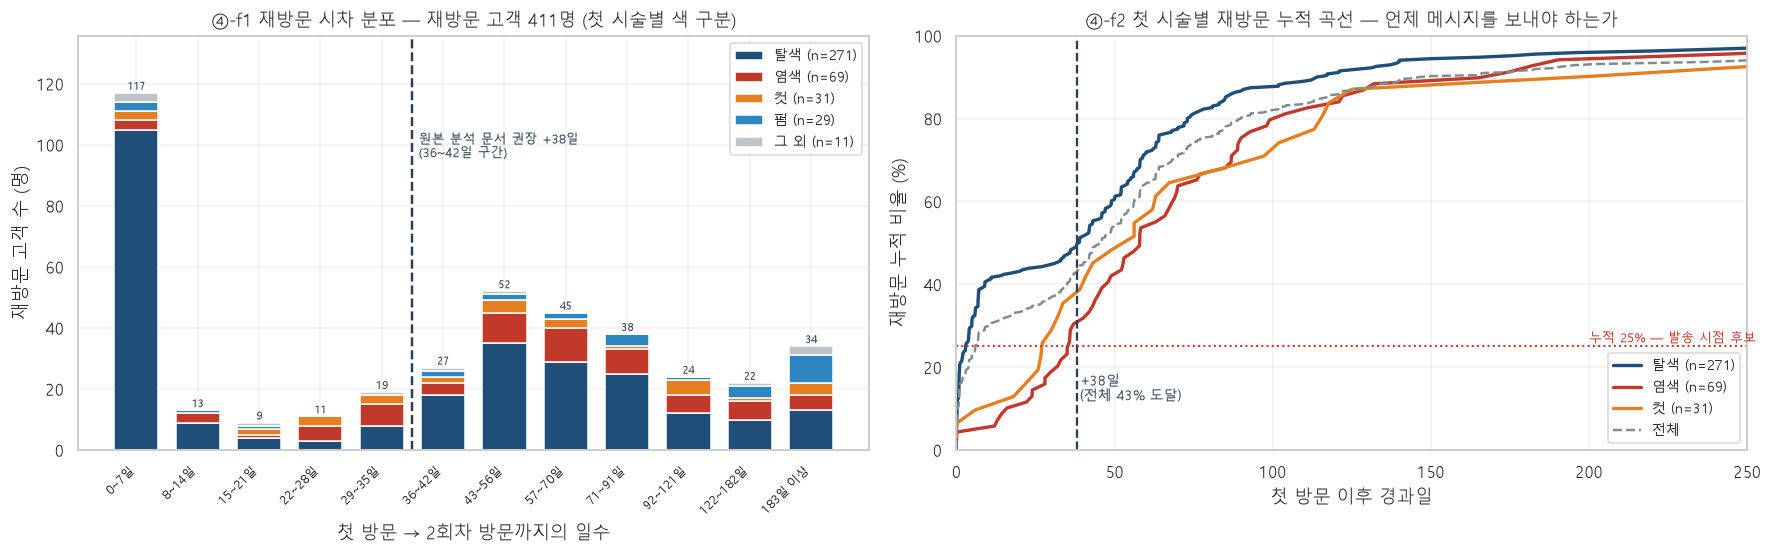

In [77]:
# ── ④-f 그래프: 재방문 시차 히스토그램 (시술별 색 구분) + 누적곡선 ────────
fig, axes = plt.subplots(1, 2, figsize=(16.5, 5.2))

ax = axes[0]
_cats = [c for c in ["탈색", "염색", "컷", "펌"] if c in set(F2.rep_cat)]
_ccol = {"탈색": C_MAIN, "염색": C_ACC, "컷": C_WARM, "펌": C_SUB}
_x = np.arange(len(FLABS)); _bot = np.zeros(len(FLABS))
for c in _cats:
    v = (F2[F2.rep_cat == c].구간.value_counts().reindex(FLABS).fillna(0).values)
    ax.bar(_x, v, bottom=_bot, color=_ccol[c], width=0.72, label=f"{c} (n={int(v.sum())})")
    _bot = _bot + v
_other = (F2[~F2.rep_cat.isin(_cats)].구간.value_counts().reindex(FLABS).fillna(0).values)
ax.bar(_x, _other, bottom=_bot, color=C_GRAY, width=0.72, label=f"그 외 (n={int(_other.sum())})")
_tot = _bot + _other
barlab(ax, _x, _tot, "{:,.0f}", dy=2, fs=7.5)
ax.axvline(4.5, color="#2c3e50", ls="--", lw=1.6)
ax.annotate("원본 분석 문서 권장 +38일\n(36~42일 구간)", (4.6, _tot.max()*0.82), fontsize=8.5, color="#2c3e50")
ax.set_xticks(_x); ax.set_xticklabels(FLABS, rotation=45, ha="right", fontsize=8)
ax.set_ylabel("재방문 고객 수 (명)"); ax.set_xlabel("첫 방문 → 2회차 방문까지의 일수")
ax.set_ylim(0, _tot.max()*1.16)
ax.set_title(f"④-f1 재방문 시차 분포 — 재방문 고객 {len(F2):,}명 (첫 시술별 색 구분)")
ax.legend(fontsize=9)

ax = axes[1]
for c in _cats:
    s = np.sort(F2[F2.rep_cat == c].days.values)
    if len(s) < 30:
        continue
    ax.plot(s, np.arange(1, len(s)+1)/len(s)*100, lw=2.2, color=_ccol[c], label=f"{c} (n={len(s)})")
_sa = np.sort(F2.days.values)
ax.plot(_sa, np.arange(1, len(_sa)+1)/len(_sa)*100, lw=1.6, ls="--", color=C_DARKG, label="전체")
ax.axvline(38, color="#2c3e50", ls="--", lw=1.5)
ax.annotate(f"+38일\n(전체 {(F2.days<=38).mean()*100:.0f}% 도달)", (39, 12), fontsize=9, color="#2c3e50")
ax.axhline(25, color=C_ACC, ls=":", lw=1.3)
ax.annotate("누적 25% — 발송 시점 후보", (200, 26), fontsize=8.5, color=C_ACC)
ax.set_xlim(0, 250); ax.set_ylim(0, 100)
ax.set_xlabel("첫 방문 이후 경과일"); ax.set_ylabel("재방문 누적 비율 (%)")
ax.set_title("④-f2 첫 시술별 재방문 누적 곡선 — 언제 메시지를 보내야 하는가")
ax.legend(fontsize=9, loc="lower right")
plt.tight_layout(); plt.show()

### ④-f3 ⚠️ 탈색의 "재방문"은 리텐션이 아닐 수 있다 — 분할 시술 분리

④-f2 표에서 **탈색 첫방문 고객의 2회차 방문 25분위가 3일, 최빈 구간이 `0~7일`** 로 나왔다.
정상적인 리텐션 주기(뿌리가 자라 다시 오는 41일)와 전혀 맞지 않는다.

요청사항 원문에 답이 있다 — **"마저 하러 갑니다", "저번에 다 못 한 거", "이어서 해요"** 가 반복된다.
탈색은 한 번에 끝나지 않아 **이틀에 나눠 시술하는 경우**가 있고, 그 두 번째 방문이
데이터에서는 "재방문"으로 잡힌다.

**이건 새로 얻은 손님이 아니라 하나의 시술이 두 건으로 기록된 것이다.**
아래에서 7일 이내 재방문을 **분할 시술 추정분**으로 분리하고, 그것을 뺀 뒤의 재방문율을 다시 계산한다.

⚠️ 7일이라는 경계는 **판단이다.** 실제로 7일 만에 리텐션으로 다시 온 사람도 섞이고,
8일 이상 뒤에 마저 하러 온 사람은 안 잡힌다. 정확한 구분은 데이터에 필드가 없어 불가능하다.

In [78]:
# ── ④-f3 분할 시술 추정분 분리 ─────────────────────────────────────────────
SPLIT_D = 7
F2["분할시술추정"] = F2.days <= SPLIT_D

# 근거 보강: 요청사항에 '이어하기' 표현이 있는 예약이 실제로 얼마나 되나
_CONT_RE = r"마저|나머지|이어서|못\s*한|못한|마무리|남은\s*시술|다\s*못|추가\s*탈색|재방문\s*하기로"
_cont = R[R.요청사항.fillna("").astype(str).str.contains(_CONT_RE, regex=True, na=False)]
print(f"요청사항에 '마저/나머지/이어서/마무리' 표현이 있는 예약: {len(_cont)}건 "
      f"(요청사항 {len(REQ)}건의 {len(_cont)/len(REQ)*100:.1f}%)")
print(f"  그중 완료 {int((_cont.status=='이용완료').sum())}건 · 대표시술 분포 "
      f"{_cont[_cont.status=='이용완료'].rep_cat.value_counts().to_dict()}")
print(f"  → 텍스트로도 '분할 시술'이 실재한다는 근거가 된다.")
print()

_sp = (F2.groupby("rep_cat")
          .agg(재방문인원=("days", "size"), 분할추정=("분할시술추정", "sum")))
_sp["분할 비중(%)"] = _sp.분할추정 / _sp.재방문인원 * 100
_sp["진짜 재방문"] = _sp.재방문인원 - _sp.분할추정
_sp["첫방문 고객수"] = CUST.groupby("첫방문시술").size()
_sp["표면 재방문율(%)"] = _sp.재방문인원 / _sp["첫방문 고객수"] * 100
_sp["분할 제외 재방문율(%)"] = _sp["진짜 재방문"] / _sp["첫방문 고객수"] * 100
_sp["차이(%p)"] = _sp["분할 제외 재방문율(%)"] - _sp["표면 재방문율(%)"]
_sp = _sp.reindex([c for c in PRIORITY if c in _sp.index])
_sp["소표본"] = _sp.재방문인원.map(lambda n: small(n))
tbl(_sp.round(2), f"④-f3 첫 시술별 — {SPLIT_D}일 이내 재방문을 '분할 시술 추정분'으로 분리")

_tot_split = int(F2.분할시술추정.sum())
print(f"전체 재방문 {len(F2):,}명 중 {SPLIT_D}일 이내 재방문 {_tot_split:,}명 "
      f"({_tot_split/len(F2)*100:.2f}%)")
print(f"이를 빼면 전체 재방문율은 {CUST.재방문.mean()*100:.2f}% → "
      f"{(len(F2)-_tot_split)/len(CUST)*100:.2f}% 로 내려간다 "
      f"({(len(F2)-_tot_split)/len(CUST)*100 - CUST.재방문.mean()*100:+.2f}%p)")
print()
print("★ 시술별로 보면 영향이 완전히 다르다:")
for c in ["탈색", "염색", "펌", "컷"]:
    if c in _sp.index:
        r = _sp.loc[c]
        print(f"   {c:<3} 표면 {r['표면 재방문율(%)']:>5.2f}% → 분할 제외 {r['분할 제외 재방문율(%)']:>5.2f}% "
              f"({r['차이(%p)']:+.2f}%p · 재방문 {int(r.재방문인원)}명 중 분할 추정 {int(r.분할추정)}명 = "
              f"{r['분할 비중(%)']:.1f}%)")
print()
print("→ **탈색의 낮은 재방문율은 실제로는 더 낮다.** 표면 재방문의 일부가 같은 시술의 뒷부분이다.")
print("  ④-b2의 '탈색 1→2회 전환율'과 ④-f2의 '탈색 권장 발송 3일'은 이 왜곡의 결과다.")
print("  리텐션 메시지 시점은 **분할분을 뺀 분포**에서 다시 잡아야 한다:")
_clean = F2[~F2.분할시술추정]
for c in ["탈색", "염색", "컷", "펌"]:
    s = _clean[_clean.rep_cat == c].days
    if len(s) >= 30:
        print(f"   {c:<3} 분할 제외 후 — 중앙 {s.median():.1f}일 · 25분위 {s.quantile(.25):.1f}일 "
              f"(n={len(s)})")
    elif len(s) > 0:
        print(f"   {c:<3} 분할 제외 후 — 중앙 {s.median():.1f}일 · 25분위 {s.quantile(.25):.1f}일 "
              f"(n={len(s)}) ⚠소표본")
print()
print(f"전체 분할 제외 후 — 중앙 {_clean.days.median():.1f}일 · 25분위 {_clean.days.quantile(.25):.1f}일")
print("⚠️ 7일 경계는 판단이다. 데이터에 '이어서 하는 시술' 플래그가 없어 정확한 분리는 불가능하다.")
print("   사장님께 '분할 시술을 예약에 어떻게 기록하시는지' 확인하면 이 왜곡을 없앨 수 있다.")

요청사항에 '마저/나머지/이어서/마무리' 표현이 있는 예약: 45건 (요청사항 426건의 10.6%)
  그중 완료 33건 · 대표시술 분포 {'탈색': 32, '염색': 1}
  → 텍스트로도 '분할 시술'이 실재한다는 근거가 된다.



**④-f3 첫 시술별 — 7일 이내 재방문을 '분할 시술 추정분'으로 분리**

,재방문인원,분할추정,분할 비중(%),진짜 재방문,첫방문 고객수,표면 재방문율(%),분할 제외 재방문율(%),차이(%p),소표본
rep_cat,,,,,,,,,
탈색,271,102,37.64,169,1190,22.77,14.20,-8.57,
펌,29,3,10.34,26,73,39.73,35.62,-4.11,⚠소표본
염색,69,3,4.35,66,149,46.31,44.30,-2.01,
컷,31,3,9.68,28,98,31.63,28.57,-3.06,
클리닉,4,0,0.00,4,20,20.00,20.00,0.00,⚠소표본
스타일링,2,1,50.00,1,17,11.76,5.88,-5.88,⚠소표본
확인필요,5,2,40.00,3,9,55.56,33.33,-22.22,⚠소표본


전체 재방문 411명 중 7일 이내 재방문 114명 (27.74%)
이를 빼면 전체 재방문율은 26.40% → 19.08% 로 내려간다 (-7.32%p)

★ 시술별로 보면 영향이 완전히 다르다:
   탈색  표면 22.77% → 분할 제외 14.20% (-8.57%p · 재방문 271명 중 분할 추정 102명 = 37.6%)
   염색  표면 46.31% → 분할 제외 44.30% (-2.01%p · 재방문 69명 중 분할 추정 3명 = 4.3%)
   펌   표면 39.73% → 분할 제외 35.62% (-4.11%p · 재방문 29명 중 분할 추정 3명 = 10.3%)
   컷   표면 31.63% → 분할 제외 28.57% (-3.06%p · 재방문 31명 중 분할 추정 3명 = 9.7%)

→ **탈색의 낮은 재방문율은 실제로는 더 낮다.** 표면 재방문의 일부가 같은 시술의 뒷부분이다.
  ④-b2의 '탈색 1→2회 전환율'과 ④-f2의 '탈색 권장 발송 3일'은 이 왜곡의 결과다.
  리텐션 메시지 시점은 **분할분을 뺀 분포**에서 다시 잡아야 한다:
   탈색  분할 제외 후 — 중앙 58.0일 · 25분위 42.0일 (n=169)
   염색  분할 제외 후 — 중앙 58.1일 · 25분위 36.3일 (n=66)
   컷   분할 제외 후 — 중앙 59.1일 · 25분위 33.3일 (n=28) ⚠소표본
   펌   분할 제외 후 — 중앙 113.0일 · 25분위 62.9일 (n=26) ⚠소표본

전체 분할 제외 후 — 중앙 59.2일 · 25분위 41.8일
⚠️ 7일 경계는 판단이다. 데이터에 '이어서 하는 시술' 플래그가 없어 정확한 분리는 불가능하다.
   사장님께 '분할 시술을 예약에 어떻게 기록하시는지' 확인하면 이 왜곡을 없앨 수 있다.


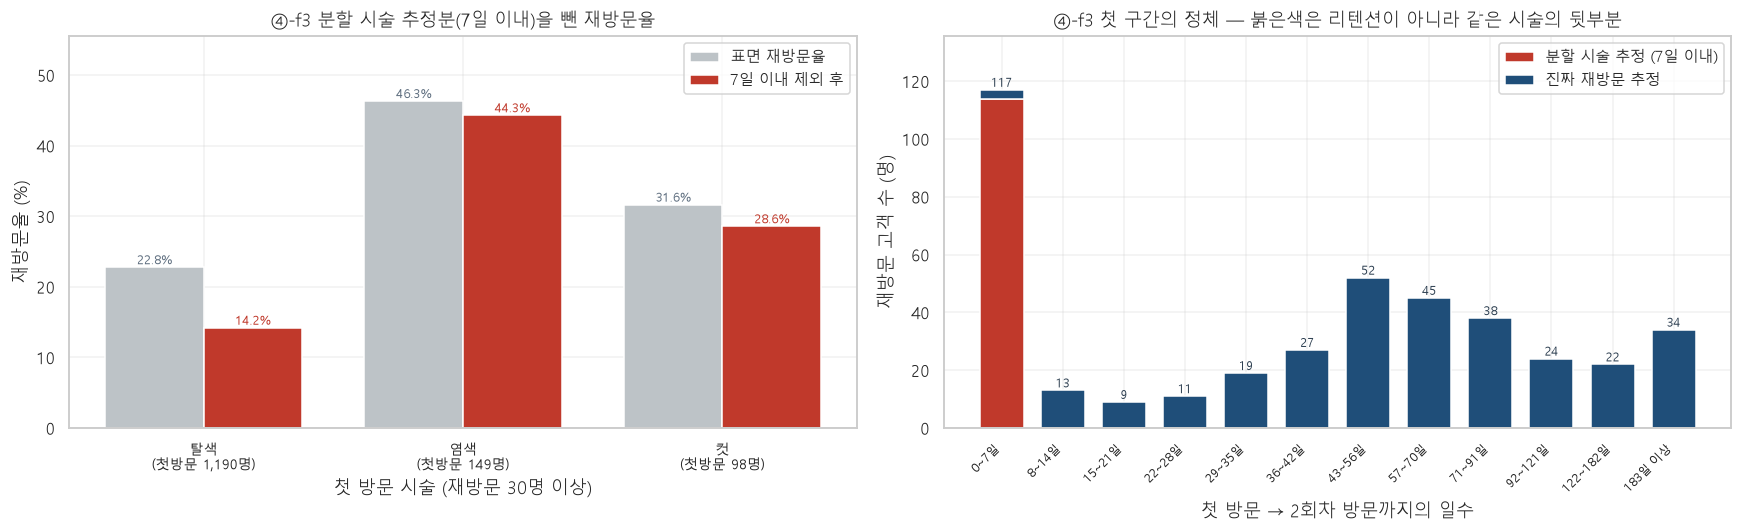

In [79]:
# ── ④-f3 그래프: 분할 시술 분리 전후 ───────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

ax = axes[0]
_s = _sp[_sp.재방문인원 >= 30]
_x = np.arange(len(_s)); _w = 0.38
ax.bar(_x - _w/2, _s["표면 재방문율(%)"], _w, color=C_GRAY, label="표면 재방문율")
ax.bar(_x + _w/2, _s["분할 제외 재방문율(%)"], _w, color=C_ACC, label=f"{SPLIT_D}일 이내 제외 후")
barlab(ax, _x - _w/2, _s["표면 재방문율(%)"].values, "{:.1f}%", dy=2, fs=8.5, color="#5d6d7e")
barlab(ax, _x + _w/2, _s["분할 제외 재방문율(%)"].values, "{:.1f}%", dy=2, fs=8.5, color=C_ACC)
ax.set_xticks(_x)
ax.set_xticklabels([f"{c}\n(첫방문 {int(_s.loc[c,'첫방문 고객수']):,}명)" for c in _s.index], fontsize=9)
ax.set_ylabel("재방문율 (%)"); ax.set_xlabel("첫 방문 시술 (재방문 30명 이상)")
ax.set_ylim(0, _s["표면 재방문율(%)"].max()*1.2)
ax.set_title(f"④-f3 분할 시술 추정분({SPLIT_D}일 이내)을 뺀 재방문율")
ax.legend(fontsize=9.5)

ax = axes[1]
_x2 = np.arange(len(FLABS)); _bot = np.zeros(len(FLABS))
_sp_v = F2[F2.분할시술추정].구간.value_counts().reindex(FLABS).fillna(0).values
_re_v = F2[~F2.분할시술추정].구간.value_counts().reindex(FLABS).fillna(0).values
ax.bar(_x2, _sp_v, color=C_ACC, width=0.72, label=f"분할 시술 추정 ({SPLIT_D}일 이내)")
ax.bar(_x2, _re_v, bottom=_sp_v, color=C_MAIN, width=0.72, label="진짜 재방문 추정")
barlab(ax, _x2, _sp_v + _re_v, "{:,.0f}", dy=2, fs=8)
ax.set_xticks(_x2); ax.set_xticklabels(FLABS, rotation=45, ha="right", fontsize=8)
ax.set_ylabel("재방문 고객 수 (명)"); ax.set_xlabel("첫 방문 → 2회차 방문까지의 일수")
ax.set_ylim(0, (_sp_v + _re_v).max()*1.16)
ax.set_title("④-f3 첫 구간의 정체 — 붉은색은 리텐션이 아니라 같은 시술의 뒷부분")
ax.legend(fontsize=9.5)
plt.tight_layout(); plt.show()

---
# 판정 요약

세 개를 출력한다.

1. **캐파 판정** — 여유 있음/없음, 근거 숫자 3개, 있다면 어디에 얼마나
2. **방향 비교표** — 신규 유치 / 재방문 회수 / 객단가 상승
3. **챗봇 FAQ 후보 6개**

In [80]:
# ══════════════════════════════════════════════════════════════════════════
# (1) 캐파 판정
# ══════════════════════════════════════════════════════════════════════════
_j = _dz_day.loc["가온 대표원장"]
_h = _dz_day.loc["나래 디자이너"]
_gj = GAP_TBL.loc["가온 대표원장"]

print("█" * 92)
print(f"█ (1) 캐파 판정 :  ★ {CAPACITY_VERDICT} ★")
print("█" * 92)
print()
print("── 근거 숫자 3개 ──")
print()
print(f"  ① 본인이 이미 해낸 수준 대비 지금은 절반도 안 채운다")
print(f"     가온 하루 평균 {_j.mean():.2f}건 vs 5건 이상 달성 {int((_j>=5).sum())}일 "
      f"({(_j>=5).mean()*100:.1f}% of {len(_j)}일) · 최대 {int(_j.max())}건")
print(f"     매장 전체  하루 평균 {_store_day.mean():.2f}건 vs 8건 이상 달성 "
      f"{int((_store_day>=8).sum())}일 ({(_store_day>=8).mean()*100:.1f}%) · 최대 {int(_store_day.max())}건")
print()
print(f"  ② 병행 시술이 실재한다 (소요시간 가정과 무관한 증거)")
print(f"     같은 디자이너·같은 날 연속 예약 시작 간격 — 가온 중앙 {_gj['중앙 간격(h)']:.2f}시간")
print(f"     연속쌍의 {_gj['1시간 이하(%)']:.1f}%가 1시간 이내, {_gj['3.5시간 미만(%)']:.1f}%가 3.5시간 이내에 다음 예약 시작")
print(f"     → 예약 1건이 {_gj['가정A 예약당 소요h']:.2f}h(가정A) 걸린다면, 그 시간 내내 붙어 있을 수 없다")
print()
print(f"  ③ 근무일 안에 완전히 빈 시간이 남아 있다")
_a5 = _aggp.loc['A', '⑤ 완전 공백 — 팔 수 있었는데 안 팔림']
_b5 = _aggp.loc['B', '⑤ 완전 공백 — 팔 수 있었는데 안 팔림']
print(f"     완전 공백 슬롯 비중 — 가정A {_a5:.1f}% / 가정B {_b5:.1f}%")
print(f"     근무일 중 완전 빈 시간 합계 — 가정A {_sum.loc['A','빈시간_h']:,.0f}시간 / "
      f"가정B {_sum.loc['B','빈시간_h']:,.0f}시간 ({N_MONTHS}개월)")
print()
print("── 여유가 어디에 얼마나 있는가 ──")
print()
_by_h = _hm_avg.mean(axis=0).sort_values()
_by_d = _hm_avg.sum(axis=1).sort_values()
_slotA = SLOT[SLOT.가정 == "A"].set_index("디자이너")
print(f"  · 시각 — 가장 빈 시간대: " +
      ", ".join(f"{int(h)}시({v:.2f}건/일)" for h, v in _by_h.head(4).items()))
print(f"           가장 찬 시간대: " +
      ", ".join(f"{int(h)}시({v:.2f}건/일)" for h, v in _by_h.tail(3).items()))
print(f"  · 요일 — 가장 빈 요일: " + ", ".join(f"{d}({v:.2f}건/일)" for d, v in _by_d.head(3).items()))
print(f"           가장 찬 요일: " + ", ".join(f"{d}({v:.2f}건/일)" for d, v in _by_d.tail(2).items()))
print(f"  · 디자이너 — 완전 공백 슬롯 비중 [가정A]:")
for d in REAL_DESIGNERS:
    r = _slotA.loc[d]
    print(f"       {d:<10} {r['⑤ 완전 공백 — 팔 수 있었는데 안 팔림'] / r['총 슬롯'] * 100:>5.1f}%  "
          f"(근무 {int(r.근무일)}일 / 영업 {len(BIZ_DATES)}일)")
print()
print("── 받을 수 있는 규모 (추정) ──")
print()
for asm in ["A", "B"]:
    r = _sum.loc[asm]
    print(f"  [가정 {asm}] 월 {r['하한 월평균(건)']:.1f}건 ~ {r['상한 월평균(건)']:.1f}건 추가 수용 가능")
    print(f"           현재 월평균 {r['현재 월평균 완료(건)']:.1f}건 대비 "
          f"+{r['하한 증가율(%)']:.0f}% ~ +{r['상한 증가율(%)']:.0f}%")
    print(f"           객단가 중앙값 {DONE.paid.median():,.0f}원 기준 월 "
          f"{r['하한 월평균(건)']*DONE.paid.median():,.0f} ~ {r['상한 월평균(건)']*DONE.paid.median():,.0f}원")
print()
print("── 병목은 무엇인가 ──")
print()
print(f"  · 디자이너 '시간'이 아니다. 시간 점유율(78%/128%)은 병행을 하나도 인정하지 않은 상한값이다.")
print(f"  · 구조적 제약은 **탈색 길이 x 마감 20시** 조합이다.")
print(f"    '마감 전 소요시간 부족' 슬롯 — 가정A {_aggp.loc['A','③ 마감 전 소요시간 부족']:.1f}% / "
      f"가정B {_aggp.loc['B','③ 마감 전 소요시간 부족']:.1f}%")
print(f"    실제로 16시 이후 시작 건은 완료의 {(DONE.hour>=16).mean()*100:.1f}%뿐이다.")
print(f"  · 또 하나는 **인력 배치**다. 영업일 {len(BIZ_DATES)}일 중 "
      f"가온 {len(_j)}일 · 나래 {len(_h)}일 근무, 나머지 3명은 합쳐 "
      f"{sum(len(_dz_day.loc[d]) for d in ['다솜 디자이너','라온 디자이너','마루 디자이너'])}일.")
print()
print("── 반대로 못 받는 부분 ──")
print()
print(f"  · 16시 이후 시작하는 긴 시술(탈색)은 마감 때문에 구조적으로 불가능")
print(f"  · 미근무일(가온 {len(BIZ_DATES)-len(_j)}일 · 나래 {len(BIZ_DATES)-len(_h)}일)은 인력 없이는 못 판다 — 위 추정에서 제외")
print(f"  · 디자이너 미지정 완료 {len(_un):,}건({len(_un)/len(DONE)*100:.1f}%)의 실제 시술자를 몰라 여유가 과대평가돼 있다")
print(f"  · **'자리가 있다'와 '손님이 온다'는 다르다.** 위 숫자는 전부 공급 측 상한이다.")
print()
print("── 가정 A / B 에서 결론이 갈리는가 ──")
print(f"  갈리지 않는다. 완전 공백 슬롯 A {_a5:.1f}% vs B {_b5:.1f}%, "
      f"추가 가능 하한 A {_sum.loc['A','하한 월평균(건)']:.1f}건 vs B {_sum.loc['B','하한 월평균(건)']:.1f}건.")
print(f"  가정 B가 더 보수적이지만 **두 가정 모두 '여유 있음'** 을 가리킨다. 규모만 다르다.")
print("█" * 92)

████████████████████████████████████████████████████████████████████████████████████████████
█ (1) 캐파 판정 :  ★ 여유 있음 ★
████████████████████████████████████████████████████████████████████████████████████████████

── 근거 숫자 3개 ──

  ① 본인이 이미 해낸 수준 대비 지금은 절반도 안 채운다
     가온 하루 평균 2.93건 vs 5건 이상 달성 95일 (17.4% of 547일) · 최대 8건
     매장 전체  하루 평균 4.71건 vs 8건 이상 달성 71일 (12.2%) · 최대 14건

  ② 병행 시술이 실재한다 (소요시간 가정과 무관한 증거)
     같은 디자이너·같은 날 연속 예약 시작 간격 — 가온 중앙 1.50시간
     연속쌍의 48.0%가 1시간 이내, 82.8%가 3.5시간 이내에 다음 예약 시작
     → 예약 1건이 2.39h(가정A) 걸린다면, 그 시간 내내 붙어 있을 수 없다

  ③ 근무일 안에 완전히 빈 시간이 남아 있다
     완전 공백 슬롯 비중 — 가정A 12.3% / 가정B 10.0%
     근무일 중 완전 빈 시간 합계 — 가정A 5,830시간 / 가정B 4,355시간 (20개월)

── 여유가 어디에 얼마나 있는가 ──

  · 시각 — 가장 빈 시간대: 20시(0.01건/일), 19시(0.15건/일), 16시(0.33건/일), 18시(0.33건/일)
           가장 찬 시간대: 13시(0.58건/일), 12시(0.67건/일), 11시(0.72건/일)
  · 요일 — 가장 빈 요일: 화(3.90건/일), 일(4.02건/일), 수(4.22건/일)
           가장 찬 요일: 월(5.07건/일), 금(6.33건/일)
  · 디자이너 — 완전 공백 슬롯 비중 [가정A]:
       가온 대표원장     30.7%  (근

In [81]:
# ══════════════════════════════════════════════════════════════════════════
# (2) 방향 비교표
# ══════════════════════════════════════════════════════════════════════════
_cur_month = len(DONE) / N_MONTHS
_cap_low, _cap_up = _sum.loc["B", "하한 월평균(건)"], _sum.loc["A", "상한 월평균(건)"]
_med_paid = DONE.paid.median()

# 객단가 상승 방향의 근거: 현재 객단가 분포에서 한 단계 위 봉우리로 이동시켰을 때
_upsell_gap = DONE.paid.mean() - DONE.paid.median()
_p60 = DONE.paid.quantile(0.60)
_upsell_per = _p60 - _med_paid

DIRECTION = pd.DataFrame([
    {
        "방향": "① 신규 유치",
        "기대 매출 효과 (월, 추정)":
            f"{_cap_low*_med_paid:,.0f} ~ {_cap_up*_med_paid:,.0f}원",
        "규모 근거":
            f"③ 캐파 여유 월 {_cap_low:.1f}~{_cap_up:.1f}건 x 객단가 중앙값 {_med_paid:,.0f}원",
        "필요 조건":
            "유입 확대(① 탐색형·직접 진입형). 신규 1명 생애 매출 "
            f"{_ltv_actual:,.0f}원, 평균 {_visits_mean:.2f}회 방문",
        "캐파 제약": f"없음 — ③ 판정 '{CAPACITY_VERDICT}'",
        "리스크":
            f"1회→2회 전환율이 {FUN_ALL.iloc[0]['전환율(%)']:.1f}%뿐이라 "
            f"신규를 넣어도 {100-FUN_ALL.iloc[0]['전환율(%)']:.0f}%가 새어 나간다",
        "확실성": "중 — 유입 경로는 검증됐으나 전환 비용 미측정",
    },
    {
        "방향": "② 재방문 회수",
        "기대 매출 효과 (월, 추정)":
            f"{len(_dm)*0.05*_dm.방문당객단가.mean()/12:,.0f} ~ "
            f"{len(_dm)*0.20*_dm.방문당객단가.mean()/12:,.0f}원 (회수율 5~20%, 12개월 분산)",
        "규모 근거":
            f"휴면 {len(_dm):,}명 x 과거 방문당 객단가 {_dm.방문당객단가.mean():,.0f}원 "
            f"= 잠재 {len(_dm)*_dm.방문당객단가.mean():,.0f}원",
        "필요 조건":
            f"발송 시점 재설계 — 분할 시술({SPLIT_D}일 이내) 제외 후 전체 25분위 "
            f"{_clean.days.quantile(.25):.0f}일 · 중앙 {_clean.days.median():.0f}일 "
            f"(현행 +38일은 이미 {(_clean.days<=38).mean()*100:.0f}% 돌아온 뒤)",
        "캐파 제약": f"없음 — 월 {len(_dm)*0.20/12:.1f}건(회수율 20%)은 여유 하한 {_cap_low:.1f}건 안에 들어감",
        "리스크":
            "회수율이 데이터에 없다. 2025-01 이전 이력이 없어 '휴면'에 원래 단골이 섞여 있을 수 있음. "
            f"또 표면 재방문의 {F2.분할시술추정.mean()*100:.0f}%가 분할 시술이라 실제 리텐션은 더 얕다(④-f3)",
        "확실성": "중~하 — 비용은 거의 0이나 회수율이 완전 미지",
    },
    {
        "방향": "③ 객단가 상승",
        "기대 매출 효과 (월, 추정)":
            f"{_cur_month*_upsell_per:,.0f}원 (완료 건의 절반을 중앙값→60분위로 올릴 때 x 0.5)",
        "규모 근거":
            f"현재 객단가 중앙 {_med_paid:,.0f}원 · 60분위 {_p60:,.0f}원 "
            f"· 평균−중앙 격차 {_upsell_gap:,.0f}원 · 월 완료 {_cur_month:.1f}건",
        "필요 조건":
            "현장 업셀 구조화. 02번에서 확인된 paid−listed 차액 31,103,650원(완료매출의 10%)이 "
            "이미 현장 추가 시술로 발생 중 — 규명 후 재현 가능하게 만드는 것",
        "캐파 제약":
            "있음 — 시술을 추가하면 소요시간이 늘어 같은 자리에서 받을 수 있는 건수가 줄어든다",
        "리스크": "차액 3,110만원의 정체가 아직 미규명 (원본 분석 문서 §8 미해결)",
        "확실성": "하 — 메커니즘이 규명되지 않음",
    },
]).set_index("방향")
tbl(DIRECTION, "(2) 방향 비교표 — 신규 유치 / 재방문 회수 / 객단가 상승")

print("█" * 92)
print("█ (2) 결론 — 어느 쪽이 유리한가")
print("█" * 92)
print()
print(f"③에서 캐파 판정이 '{CAPACITY_VERDICT}'로 나왔으므로, **셋은 배타적이지 않다.**")
print("자리가 있으니 신규를 막을 이유가 없고, 같은 자리를 휴면 회수로 채워도 된다.")
print()
print("다만 **순서**는 정해진다:")
print()
_pdiff = _dm.방문당객단가.mean() - _first_paid_mean
print(f"  1순위 — ② 재방문 회수를 먼저 한다.")
print(f"         이유 1: 비용이 거의 0이다. 연락처를 이미 갖고 있다. 신규 유치는 노출 비용이 든다.")
print(f"         이유 2: 건당 매출이 신규와 사실상 같다 — 휴면 {_dm.방문당객단가.mean():,.0f}원 vs "
      f"신규 첫 방문 {_first_paid_mean:,.0f}원 ({_pdiff:+,.0f}원, "
      f"{abs(_pdiff)/_first_paid_mean*100:.1f}% 차이).")
print(f"                 즉 **같은 1건을 채운다면 매출은 거의 동일한데 비용만 다르다.**")
print(f"         이유 3: 회수율이 미지이므로 **먼저 측정해야 한다.** 소규모 발송으로 회수율부터 잰다.")
print(f"                 (신규 1명의 생애 매출 {_ltv_actual:,.0f}원은 휴면 1회 회수보다 크지만,")
print(f"                  그건 '평균 {_visits_mean:.2f}회 온다'는 전제 위의 값이고 그 전제가 곧 재방문 문제다.)")
print()
print(f"  2순위 — ① 신규 유치. 자리가 있으니 유효하다.")
print(f"         단, 1회→2회 전환율 {FUN_ALL.iloc[0]['전환율(%)']:.1f}% 를 먼저 손보지 않으면 새는 독에 물 붓기다.")
print(f"         ①에서 확인: 건수 1위 경로({CH_SUMMARY.예약건수.idxmax()})의 재방문율은 "
      f"{CH_SUMMARY.loc[CH_SUMMARY.예약건수.idxmax(),'재방문율(%)']:.1f}%로 "
      f"전체 평균 {CUST.재방문.mean()*100:.1f}% 보다 낮다.")
print(f"         → **건수를 늘리는 경로와 재방문을 데려오는 경로가 다르다.** 유입을 늘릴 때 경로를 골라야 한다.")
print()
print(f"  3순위 — ③ 객단가 상승. 메커니즘이 규명되기 전까지는 실행 계획을 세울 수 없다.")
print(f"         paid−listed 차액 3,110만원(493건)의 정체를 먼저 규명할 것.")
print()
print("⚠️ 위 세 숫자는 전부 추정이다. 특히 ②의 회수율과 ③의 상승폭은 데이터에 없는 값을 가정한 것이다.")
print("█" * 92)

**(2) 방향 비교표 — 신규 유치 / 재방문 회수 / 객단가 상승**

,"기대 매출 효과 (월, 추정)",규모 근거,필요 조건,캐파 제약,리스크,확실성
방향,,,,,,
① 신규 유치,"3,845,000 ~ 8,350,000원","③ 캐파 여유 월 38.5~83.5건 x 객단가 중앙값 100,000원","유입 확대(① 탐색형·직접 진입형). 신규 1명 생애 매출 198,443원, 평균 1.75회 방문",없음 — ③ 판정 '여유 있음',1회→2회 전환율이 26.4%뿐이라 신규를 넣어도 74%가 새어 나간다,중 — 유입 경로는 검증됐으나 전환 비용 미측정
② 재방문 회수,"666,970 ~ 2,667,882원 (회수율 5~20%, 12개월 분산)","휴면 1,226명 x 과거 방문당 객단가 130,565원 = 잠재 160,072,906원",발송 시점 재설계 — 분할 시술(7일 이내) 제외 후 전체 25분위 42일 · 중앙 59일 (현행 +38일은 이미 21% 돌아온 뒤),없음 — 월 20.4건(회수율 20%)은 여유 하한 38.5건 안에 들어감,회수율이 데이터에 없다. 2025-01 이전 이력이 없어 '휴면'에 원래 단골이 섞여 있을 수 있음. 또 표면 재방문의 28%가 분할 시술이라 실제 리텐션은 더 얕다(④-f3),중~하 — 비용은 거의 0이나 회수율이 완전 미지
③ 객단가 상승,"6,147,000원 (완료 건의 절반을 중앙값→60분위로 올릴 때 x 0.5)","현재 객단가 중앙 100,000원 · 60분위 145,000원 · 평균−중앙 격차 13,095원 · 월 완료 136.6건","현장 업셀 구조화. 02번에서 확인된 paid−listed 차액 31,103,650원(완료매출의 10%)이 이미 현장 추가 시술로 발생 중 — 규명 후 재현 가능하게 만드는 것",있음 — 시술을 추가하면 소요시간이 늘어 같은 자리에서 받을 수 있는 건수가 줄어든다,"차액 3,110만원의 정체가 아직 미규명 (원본 분석 문서 §8 미해결)",하 — 메커니즘이 규명되지 않음


████████████████████████████████████████████████████████████████████████████████████████████
█ (2) 결론 — 어느 쪽이 유리한가
████████████████████████████████████████████████████████████████████████████████████████████

③에서 캐파 판정이 '여유 있음'로 나왔으므로, **셋은 배타적이지 않다.**
자리가 있으니 신규를 막을 이유가 없고, 같은 자리를 휴면 회수로 채워도 된다.

다만 **순서**는 정해진다:

  1순위 — ② 재방문 회수를 먼저 한다.
         이유 1: 비용이 거의 0이다. 연락처를 이미 갖고 있다. 신규 유치는 노출 비용이 든다.
         이유 2: 건당 매출이 신규와 사실상 같다 — 휴면 130,565원 vs 신규 첫 방문 131,410원 (-845원, 0.6% 차이).
                 즉 **같은 1건을 채운다면 매출은 거의 동일한데 비용만 다르다.**
         이유 3: 회수율이 미지이므로 **먼저 측정해야 한다.** 소규모 발송으로 회수율부터 잰다.
                 (신규 1명의 생애 매출 198,443원은 휴면 1회 회수보다 크지만,
                  그건 '평균 1.75회 온다'는 전제 위의 값이고 그 전제가 곧 재방문 문제다.)

  2순위 — ① 신규 유치. 자리가 있으니 유효하다.
         단, 1회→2회 전환율 26.4% 를 먼저 손보지 않으면 새는 독에 물 붓기다.
         ①에서 확인: 건수 1위 경로(직접 진입형)의 재방문율은 22.5%로 전체 평균 26.4% 보다 낮다.
         → **건수를 늘리는 경로와 재방문을 데려오는 경로가 다르다.** 유입을 늘릴 때 경로를 골라야 한다.

  3순위 — ③ 객단가 상승. 메커니즘이 규명되기 전까지는 실행 계획을 세울 수 없다.
    

In [82]:
# ══════════════════════════════════════════════════════════════════════════
# (2-B) 방향 비교표 — 관측 기준 재작성 (③-E 반영)
# ══════════════════════════════════════════════════════════════════════════
# 기존 (2) 표는 지우지 않는다. 캐파 근거만 관측으로 바꿔 나란히 둔다.
_cap_lo_o = float(PACK_SUM.loc[LBL_MED, "월평균(건)"])
_cap_up_o = float(_sum.loc["A", "상한 월평균(건)"])
_cap_flag = float(PACK_SUM.loc[LBL_FLAG, "월평균(건)"])
_paid_cut = DONE[DONE.rep_cat == "컷"].paid.median()
_paid_bl  = DONE[DONE.rep_cat == "탈색"].paid.median()

DIRECTION_OBS = pd.DataFrame([
    {
        "방향": "① 신규 유치 [관측 기준]",
        "기대 매출 효과 (월, 추정)":
            f"{_cap_lo_o*_med_paid:,.0f} ~ {_cap_up_o*_med_paid:,.0f}원",
        "규모 근거":
            f"③-E2 관측 여유 월 {_cap_lo_o:.1f}~{_cap_up_o:.1f}건 x 객단가 중앙값 {_med_paid:,.0f}원. "
            f"단 주력 탈색으로만 채우면 월 {_cap_flag:.1f}건뿐",
        "필요 조건":
            f"**시간대를 골라 유치해야 한다.** 빈 슬롯의 {float(_aggOp[SLOT_CATS_O[4]]):.1f}%p 는 "
            f"짧은 시술만 가능하고, 주력 탈색까지 가능한 것은 {float(_aggOp[SLOT_CATS_O[3]]):.1f}%p 다",
        "캐파 제약":
            f"**있음** — ③-E4 판정은 '{CAPACITY_VERDICT_OBS}' 지만, 근무일의 {_ge4:.1f}%가 하루 4건 이상이고 "
            f"그런 날 점유는 {_c3p/BIZ_HOURS*100:.0f}%다. 바쁜 날에는 자리가 없다",
        "리스크":
            f"1회→2회 전환율 {FUN_ALL.iloc[0]['전환율(%)']:.1f}% 는 그대로. "
            f"게다가 남는 자리는 객단가가 낮은 시간대다(컷 {_paid_cut:,.0f}원 vs 탈색 {_paid_bl:,.0f}원)",
        "확실성": "중 — 캐파 근거는 관측으로 단단해졌으나 수요·전환 비용은 여전히 미측정",
    },
    {
        "방향": "② 재방문 회수 [관측 기준]",
        "기대 매출 효과 (월, 추정)":
            f"{len(_dm)*0.05*_dm.방문당객단가.mean()/12:,.0f} ~ "
            f"{len(_dm)*0.20*_dm.방문당객단가.mean()/12:,.0f}원 (회수율 5~20%, 12개월 분산)",
        "규모 근거": f"휴면 {len(_dm):,}명 x 과거 방문당 객단가 {_dm.방문당객단가.mean():,.0f}원 (변동 없음)",
        "필요 조건":
            f"발송 시점 재설계(변동 없음) + **회수분을 저녁·짧은 시술 슬롯으로 유도**. "
            f"주력 탈색 최종 시작은 평일 {CLOSE_WD - DUR_OBS_MENU[FLAGSHIP[0]]:.2f}시다",
        "캐파 제약":
            f"없음 — 월 {len(_dm)*0.20/12:.1f}건(회수율 20%)은 관측 여유 하한 {_cap_lo_o:.1f}건 안에 들어감",
        "리스크": "회수율 미지(변동 없음). 다만 채울 자리의 성격이 확인돼 **시간대 설계가 가능해졌다**",
        "확실성": "중~하 — 비용 거의 0, 회수율 미지",
    },
    {
        "방향": "③ 객단가 상승 [관측 기준]",
        "기대 매출 효과 (월, 추정)": f"{(len(DONE)/N_MONTHS)*_upsell_per:,.0f}원 (변동 없음)",
        "규모 근거": "변동 없음 — paid−listed 차액 31,103,650원(완료매출의 10%)",
        "필요 조건": "현장 업셀 구조화 (변동 없음)",
        "캐파 제약":
            f"**있음, 그리고 커졌다** — 관측 소요시간은 가정 A의 1.5~1.8배다. 시술을 얹으면 "
            f"자리가 가정보다 빨리 찬다. 판매 가능 공백의 {float(_aggOp[SLOT_CATS_O[4]]):.1f}%p 는 이미 "
            f"주력 탈색을 못 넣는 자리이고(주력 최종 시작 평일 "
            f"{CLOSE_WD - DUR_OBS_MENU[FLAGSHIP[0]]:.2f}시), 시술을 얹으면 그 경계가 더 앞당겨진다",
        "리스크": "차액 3,110만원 미규명(변동 없음)",
        "확실성": "하 — 메커니즘 미규명",
    },
]).set_index("방향")
tbl(DIRECTION_OBS, "(2-B) 방향 비교표 [관측 기준] — 기존 (2) 표와 나란히 읽을 것")

print("█" * 92)
print("█ (2-B) 관측을 반영하면 순서가 바뀌는가")
print("█" * 92)
print()
_same = (CAPACITY_VERDICT_OBS == CAPACITY_VERDICT)
print(f"판정은 '{CAPACITY_VERDICT_OBS}' 로 {'같다' if _same else '다르다'}. **순서(② → ① → ③)도 그대로다.**")
print("바뀐 것은 순서가 아니라 **①의 실행 방법**이다.")
print()
print(f"  · 기존: '월 {_sum.loc['B','하한 월평균(건)']:.1f}~{_sum.loc['A','상한 월평균(건)']:.1f}건 자리가 있으니 신규를 넣어라'")
print(f"  · 관측: '월 {_cap_lo_o:.1f}~{_cap_up_o:.1f}건 자리가 있는데, 그중 주력 탈색을 넣을 수 있는 건 월 {_cap_flag:.1f}건뿐이다'")
print()
print("  → 남는 자리는 대부분 **오후~저녁의 짧은 시술 자리**다.")
print(f"     탈색 홍보를 늘려도 그 자리는 안 채워진다(주력 최종 시작 평일 "
      f"{CLOSE_WD - DUR_OBS_MENU[FLAGSHIP[0]]:.2f}시).")
print(f"     채우려면 저녁에 시작 가능한 시술(염색 {DUR_OBS_CAT['염색']:.2f}h / 컷 {DUR_OBS_CAT['컷']:.2f}h)을")
print(f"     별도 상품으로 태워야 하고, 그 자리의 객단가는 낮다(컷 {_paid_cut:,.0f}원).")
print()
print("  → ②(재방문 회수)가 1순위인 이유가 **하나 더 늘었다.** 휴면 고객은 시술 이력이 있어")
print("     어떤 시술로 부를지 고를 수 있다. 신규는 어떤 시술을 원할지 고를 수 없다.")
print()
print("⚠️ 관측값은 하한이고 마감은 연장 근무로 늘릴 수 있다. 위 '불가'는 '연장 없이는 불가'다.")
print("█" * 92)

DIRECTION_ALL = pd.concat([DIRECTION, DIRECTION_OBS])
print(f"\ndirection_compare.csv 에 붙일 관측 행 {len(DIRECTION_OBS)}개 준비 (기존 {len(DIRECTION)}행 유지)")


**(2-B) 방향 비교표 [관측 기준] — 기존 (2) 표와 나란히 읽을 것**

,"기대 매출 효과 (월, 추정)",규모 근거,필요 조건,캐파 제약,리스크,확실성
방향,,,,,,
① 신규 유치 [관측 기준],"1,960,000 ~ 8,350,000원","③-E2 관측 여유 월 19.6~83.5건 x 객단가 중앙값 100,000원. 단 주력 탈색으로만 채우면 월 12.2건뿐","**시간대를 골라 유치해야 한다.** 빈 슬롯의 4.2%p 는 짧은 시술만 가능하고, 주력 탈색까지 가능한 것은 8.6%p 다","**있음** — ③-E4 판정은 '여유 있음' 지만, 근무일의 33.1%가 하루 4건 이상이고 그런 날 점유는 94%다. 바쁜 날에는 자리가 없다","1회→2회 전환율 26.4% 는 그대로. 게다가 남는 자리는 객단가가 낮은 시간대다(컷 29,000원 vs 탈색 150,000원)",중 — 캐파 근거는 관측으로 단단해졌으나 수요·전환 비용은 여전히 미측정
② 재방문 회수 [관측 기준],"666,970 ~ 2,667,882원 (회수율 5~20%, 12개월 분산)","휴면 1,226명 x 과거 방문당 객단가 130,565원 (변동 없음)",발송 시점 재설계(변동 없음) + **회수분을 저녁·짧은 시술 슬롯으로 유도**. 주력 탈색 최종 시작은 평일 15.62시다,없음 — 월 20.4건(회수율 20%)은 관측 여유 하한 19.6건 안에 들어감,회수율 미지(변동 없음). 다만 채울 자리의 성격이 확인돼 **시간대 설계가 가능해졌다**,"중~하 — 비용 거의 0, 회수율 미지"
③ 객단가 상승 [관측 기준],"6,147,000원 (변동 없음)","변동 없음 — paid−listed 차액 31,103,650원(완료매출의 10%)",현장 업셀 구조화 (변동 없음),"**있음, 그리고 커졌다** — 관측 소요시간은 가정 A의 1.5~1.8배다. 시술을 얹으면 자리가 가정보다 빨리 찬다. 판매 가능 공백의 4.2%p 는 이미 주력 탈색을 못 넣는 자리이고(주력 최종 시작 평일 15.62시), 시술을 얹으면 그 경계가 더 앞당겨진다","차액 3,110만원 미규명(변동 없음)",하 — 메커니즘 미규명


████████████████████████████████████████████████████████████████████████████████████████████
█ (2-B) 관측을 반영하면 순서가 바뀌는가
████████████████████████████████████████████████████████████████████████████████████████████

판정은 '여유 있음' 로 같다. **순서(② → ① → ③)도 그대로다.**
바뀐 것은 순서가 아니라 **①의 실행 방법**이다.

  · 기존: '월 38.5~83.5건 자리가 있으니 신규를 넣어라'
  · 관측: '월 19.6~83.5건 자리가 있는데, 그중 주력 탈색을 넣을 수 있는 건 월 12.2건뿐이다'

  → 남는 자리는 대부분 **오후~저녁의 짧은 시술 자리**다.
     탈색 홍보를 늘려도 그 자리는 안 채워진다(주력 최종 시작 평일 15.62시).
     채우려면 저녁에 시작 가능한 시술(염색 2.07h / 컷 1.05h)을
     별도 상품으로 태워야 하고, 그 자리의 객단가는 낮다(컷 29,000원).

  → ②(재방문 회수)가 1순위인 이유가 **하나 더 늘었다.** 휴면 고객은 시술 이력이 있어
     어떤 시술로 부를지 고를 수 있다. 신규는 어떤 시술을 원할지 고를 수 없다.

⚠️ 관측값은 하한이고 마감은 연장 근무로 늘릴 수 있다. 위 '불가'는 '연장 없이는 불가'다.
████████████████████████████████████████████████████████████████████████████████████████████

direction_compare.csv 에 붙일 관측 행 3개 준비 (기존 3행 유지)


In [83]:
# ══════════════════════════════════════════════════════════════════════════
# (3) 챗봇 FAQ 후보 6개
# ══════════════════════════════════════════════════════════════════════════
print("█" * 92)
print("█ (3) 챗봇 고정 버튼 후보 6개 — ②-d 에서 도출")
print("█" * 92)
print()
for i, r in BTN6.iterrows():
    print(f"  {i}. {r['질문 유형']}")
    print(f"     근거 건수 {r['근거 건수']:,}건 · {r['챗봇이 확답 가능한가']}")
    print(f"     {r['비고']}")
    print()
print("── 챗봇이 확답하면 안 되는 영역 (상담 연결로만) ──")
for _, r in FAQ_DF[FAQ_DF["챗봇이 확답 가능한가"].str.startswith("❌")].iterrows():
    print(f"  · {r['질문 유형']} ({r['근거 건수']:,}건) — {r['챗봇이 확답 가능한가']}")
print()
print("── 착수 전 사장님 확인이 필요한 것 (②-a4) ──")
print("  · 스탬프 10개 → 두피관리 풀코스 제도의 정확한 규칙")
print("  · 생일 쿠폰(제타클리닉 무료) 발송 기준")
print("  · 스탬프 4~5회 → 두피 각질 서비스가 별개 제도인지")
print("  · 기장 추가요금 금액 (없으면 가격 관련 질문은 전부 상담 연결)")
print("█" * 92)

████████████████████████████████████████████████████████████████████████████████████████████
█ (3) 챗봇 고정 버튼 후보 6개 — ②-d 에서 도출
████████████████████████████████████████████████████████████████████████████████████████████

  1. 예약 날짜를 바꾸고 싶다 / 취소하고 싶다
     근거 건수 409건 · 가능
     재예약 유도 문구를 함께 띄우는 것이 핵심 (취소의 절반이 45일 내 재방문)

  2. 예약 시간을 바꾸고 싶다 / 늦을 것 같다
     근거 건수 230건 · 가능
     변경 가능 시간대 안내 + 예약 변경 링크. 챗봇이 가장 크게 줄일 수 있는 항목

  3. 동반 방문 / 다른 사람 대신 예약이 되나
     근거 건수 54건 · 가능
     1인 1예약 원칙과 인원 추가 방법 안내

  4. 쿠폰·스탬프·생일쿠폰을 쓸 수 있나
     근거 건수 44건 · 조건부 가능
     ⚠️ 제도 규칙을 사장님께 먼저 확인해야 함 (②-a4). 확인 후에만 확답

  5. 영업시간·휴무일이 언제인가
     근거 건수 10건 · 가능
     근거 건수는 적지만 답이 확정적이라 비용이 0

  6. 외국어 응대가 되나
     근거 건수 9건 · 가능
     영어·중국어·일본어 메뉴가 이미 존재. 응대 가능 언어와 방식만 안내

── 챗봇이 확답하면 안 되는 영역 (상담 연결로만) ──
  · 원하는 색이 가능한가 / 어떤 색이 어울리나 (126건) — ❌ 불가 (시술 안전 보장)
  · 내 모발 상태로 이 시술이 가능한가 (101건) — ❌ 불가 (개인 모발 진단)
  · 기장 추가금이 있나 / 얼마나 나오나 (14건) — ❌ 불가 (확정 가격)

── 착수 전 사장님 확인이 필요한 것 (②-a4) ──
  · 스탬프 10개 → 두피관리 풀코스 제도의 정확한 규칙
 

In [84]:
# ── 산출물 저장 + 이 노트북의 한계 ─────────────────────────────────────────
OUT = Path(".")
CH_SUMMARY.round(2).to_csv(OUT / "ch_summary.csv", encoding="utf-8-sig")
FAQ_DF.to_csv(OUT / "faq_candidates.csv", index=False, encoding="utf-8-sig")
CAP_CMP.round(2).to_csv(OUT / "capacity_compare.csv", encoding="utf-8-sig")
SLOT_ALL.round(2).to_csv(OUT / "capacity_slots.csv", index=False, encoding="utf-8-sig")
DIRECTION_ALL.to_csv(OUT / "direction_compare.csv", encoding="utf-8-sig")
# capacity_compare.csv 는 컬럼을 추가하면 기존 행이 바뀌므로 건드리지 않고 별도 파일로 낸다
OCC_CMP.round(2).to_csv(OUT / "capacity_observed.csv", encoding="utf-8-sig")
CAP_CMP3.round(2).to_csv(OUT / "capacity_observed_summary.csv", encoding="utf-8-sig")
_st[["ym", "status", "designer", "rep_cat", "paid", "원문(마스킹)"]].assign(
    ym=lambda d: d.ym.astype(str)).to_csv(OUT / "stamp_coupon_check.csv",
                                          index=False, encoding="utf-8-sig")
print("저장:")
for f in ["ch_summary.csv", "faq_candidates.csv", "capacity_compare.csv",
          "capacity_slots.csv", "direction_compare.csv", "stamp_coupon_check.csv",
          "capacity_observed.csv", "capacity_observed_summary.csv"]:
    print(f"  notebooks/{f}")
print()
print("⚠️ stamp_coupon_check.csv 에는 요청사항 원문이 들어 있다. 마스킹은 적용했으나")
print("   완벽하지 않을 수 있다. 외부 공유 전 반드시 사람이 확인할 것.")
print()
print("=" * 92)
print("이 노트북의 한계 — 결론을 옮길 때 반드시 함께 옮길 것")
print("=" * 92)
print("1. **시술 종료 시각이 데이터에 없다** — 고 ③-a~③-e 는 전제했다. ③-E 에서 정정한다:")
print("   완료의 34.6%(945건)는 당일 처리돼 done_dt-use_dt 로 소요시간을 관측할 수 있다.")
print("   ③-a~③-e 는 가정 A·B 기반이고, ③-E 가 관측 기반이다. 셋 다 남겨 두었다.")
print("   관측은 절단 편향으로 하한이며, 마감 20:30 은 연장 근무로 늘어날 수 있다.")
print("2. **디자이너 미지정 예약** " + f"{len(_un):,}건({len(_un)/len(DONE)*100:.1f}%)의 실제 시술자를 모른다.")
print("   디자이너별 여유는 그만큼 과대평가돼 있다.")
print("3. **근무일은 '완료 1건 이상'으로 잡은 대리 지표다.** 출근했는데 예약이 0건이었던 날은")
print("   미근무로 잘못 잡히며, 이는 여유를 **과소**평가하는 방향의 오차다.")
print("4. **네이버 데이터는 2025-01부터다.** 살롱은 14.5년차이므로 '첫 방문'과 '휴면'에")
print("   원래 단골이 섞여 있다. ④의 휴면 규모는 상한으로 읽어야 한다.")
print("5. **모든 문장은 상관이다.** 인과로 읽지 말 것. 특히 ②-b(모발 이력 고지)와")
print("   ①-d(무비자 기간)는 자기선택·동시발생 요인이 크다.")
print("6. **회수율·전환 비용·기장 추가요금은 데이터에 없다.** (2) 방향 비교표의 금액은")
print("   전부 가정 위에 세워진 추정치다.")
print("7. **텍스트 분류는 키워드 규칙이다.** 오탐·미탐이 있다. 미분류 원문을 전부 출력해 뒀으니")
print("   다음 라운드에서 규칙을 보완할 것.")
print(f"8. **'재방문'에 분할 시술이 섞여 있다.** {SPLIT_D}일 이내 재방문 {int(F2.분할시술추정.sum()):,}명"
      f"({F2.분할시술추정.mean()*100:.1f}%)은 새 방문이 아니라 같은 시술의 뒷부분일 가능성이 높다(④-f3).")
print("   7일 경계는 판단이며, 데이터에 분할 시술 플래그가 없어 정확한 분리는 불가능하다.")
print("=" * 92)
print()
print("이 노트북이 만들어 낸 새 확인 항목 (원본 분석 문서 §8 후보):")
print("  · 스탬프/쿠폰 제도의 정확한 규칙 (②-a4 — 인터뷰에 없던 제도)")
print("  · 분할 시술(이틀에 나눠 하는 탈색)을 예약에 어떻게 기록하는지 (④-f3)")
print("  · 탈색 시술 중 디자이너가 실제로 붙어 있는 시간의 비율 (③-c — 캐파 결론의 전제)")
print("  · 다솜·라온·마루의 근무 형태 — 영업일 580일 중 합쳐 180일뿐 (③-a3)")

저장:
  notebooks/ch_summary.csv
  notebooks/faq_candidates.csv
  notebooks/capacity_compare.csv
  notebooks/capacity_slots.csv
  notebooks/direction_compare.csv
  notebooks/stamp_coupon_check.csv
  notebooks/capacity_observed.csv
  notebooks/capacity_observed_summary.csv

⚠️ stamp_coupon_check.csv 에는 요청사항 원문이 들어 있다. 마스킹은 적용했으나
   완벽하지 않을 수 있다. 외부 공유 전 반드시 사람이 확인할 것.

이 노트북의 한계 — 결론을 옮길 때 반드시 함께 옮길 것
1. **시술 종료 시각이 데이터에 없다** — 고 ③-a~③-e 는 전제했다. ③-E 에서 정정한다:
   완료의 34.6%(945건)는 당일 처리돼 done_dt-use_dt 로 소요시간을 관측할 수 있다.
   ③-a~③-e 는 가정 A·B 기반이고, ③-E 가 관측 기반이다. 셋 다 남겨 두었다.
   관측은 절단 편향으로 하한이며, 마감 20:30 은 연장 근무로 늘어날 수 있다.
2. **디자이너 미지정 예약** 255건(9.3%)의 실제 시술자를 모른다.
   디자이너별 여유는 그만큼 과대평가돼 있다.
3. **근무일은 '완료 1건 이상'으로 잡은 대리 지표다.** 출근했는데 예약이 0건이었던 날은
   미근무로 잘못 잡히며, 이는 여유를 **과소**평가하는 방향의 오차다.
4. **네이버 데이터는 2025-01부터다.** 살롱은 14.5년차이므로 '첫 방문'과 '휴면'에
   원래 단골이 섞여 있다. ④의 휴면 규모는 상한으로 읽어야 한다.
5. **모든 문장은 상관이다.** 인과로 읽지 말 것. 특히 ②-b(모발 이력 고지)와
   ①-d(무비자 기간)는 자기선택·동시발생 요인이 크다.
6. **회수율·전환 비용·기장 추가요금은 데이터에 